# Basal-like cells in heterogeneous pancreatic tumors preferentially express genes linked to *VPS4A* dependency

**Analysis notebook for the manuscript of the same title.**

This notebook contains the complete analysis reported in the manuscript and its Supplementary Information, from the processed input matrices to every table and figure. Every statistic in the manuscript is computed by a cell below, and every figure is drawn from objects those cells computed; no result is typed into the code or the text by hand. Section headings name the part of the Methods or Results that each section implements, and the header of each code cell names the Figure or Table it feeds, so the notebook and the manuscript can be read side by side.

### Question

Three collateral-lethality dependencies were identified in bulk cell-line screens, which treat each cell line as a single population: *VPS4A*, whose paralog *VPS4B* is deleted with *SMAD4* on chromosome arm 18q, and *PRMT5* and *MAT2A*, which become dependencies when *MTAP* is deleted with *CDKN2A* on 9p21. The malignant cells of pancreatic ductal adenocarcinoma (PDAC) occupy a more differentiated classical state and a basal-like state that coexist within tumours. The notebook asks whether a transcriptional signature associated with each dependency is distributed uniformly across these states within patients, in three public single-cell RNA-sequencing cohorts.

### Design in brief

| step | what is done | sections |
|---|---|---|
| Dependency signatures | For each target, the 100 genes whose expression best tracks stronger dependency (Chronos) in the DepMap lines with the lowest expression of the passenger gene; validated against measured dependency in lines held out of the derivation | 11, 26 |
| Malignant cells | Per-cell quality control, doublet detection, marker-based compartments and copy-number inference in Peng et al., Steele et al. and Werba et al. | 5–10, 22–23 |
| Test | Within each patient, a partial Spearman correlation between a signature score and the classical or basal score, both residualised on sequencing depth, detected genes and mitochondrial fraction; coefficients tested across patients | 4, 15, 30 |
| Controls | Random and matched gene-set nulls, a commonly essential control, independently defined programs, gene-overlap and dependency-based positive controls, and signatures built identically for dependencies without a subtype association | 15–18, 27–29, 35–39 |
| Replication | Inclusion and replication criteria for Werba et al. fixed before its expression data were analysed | 8, 20, 34 |

### Conventions

- Peng et al. and Steele et al. are the two discovery cohorts; Werba et al. is the replication cohort.
- "Section N" and "§N" refer to sections of this notebook; "Fig." and "Table" refer to the manuscript; "Supplementary Fig.", "Supplementary Table" and "Supplementary Note" refer to its Supplementary Information.
- Chronos and DEMETER2 scores are signed so that a lower value means stronger dependency. A signature that tracks dependency therefore correlates *negatively* with them.
- Every code cell opens with a header that names its section, what it computes and the Figure or Table it feeds, followed by `WHY` comments for each parameter choice. Each markdown cell carries a **Why these choices** table for the same purpose.
- The notebook is ordered by computation, not by the order of the Results: a later analysis often needs objects from several earlier ones. Part headings group the sections by the question they answer.

## Reproducing the analysis

### Software environment

The analysis runs in Python 3.11. Section 1b prints the version of every package used and writes them to `package_versions.txt` in the output folder; that file is the list cited in the Methods. Required: `numpy`, `pandas`, `scipy`, `scanpy` (with `leidenalg`, `igraph` and `umap-learn`), `anndata`, `h5py`, `scikit-learn`, `statsmodels`, `matplotlib`, `harmonypy`, `infercnvpy` and `pybiomart`. Optional, each needed by one part only and reported as skipped when absent: `gseapy` (gene-set libraries and over-representation, sections 26e–27), `cnmf` (benchmark, section 25), `psutil` (memory reporting) and `requests` (Appendix A). The largest steps (Werba et al. preprocessing in section 8 and the Steele et al. cell-role assignment in section 23a) peak at about 6–8 GB of memory.

### Input files

Every input is read from `~/Downloads` (set in section 1). Section 2 checks the required inputs and stops if one that is still needed is missing; section 21 reports which of the additional inputs are present and what is skipped without each.

| file | source | used in |
|---|---|---|
| `peng_processed.h5ad` | Peng et al. 2019, from the Tumor Immune Single-cell Hub (TISCH): log-normalised, cell-type annotated | 6, 10, 22–24 |
| `steele_qc_lognorm.h5ad` | Steele et al. 2020, GEO GSE155698: cells after quality control, normalised to 10,000 counts per cell and log1p-transformed (deposited with the code) | 7, 10, 22–24 |
| `GSE205013_RAW.tar`, `GSE205013_series_matrix.txt.gz` | Werba et al. 2023, GEO GSE205013: filtered CellRanger UMI counts and the sample table used for inclusion | 8 |
| `CRISPRGeneEffect.csv`, `OmicsExpressionTPMLogp1HumanProteinCodingGenes.csv` | DepMap Public 26Q1: Chronos gene effects and expression | 11 onward |
| `Model.csv` | DepMap Public 26Q1: lineage and disease annotation | 26, 29, 31, 35–39 |
| `OmicsCNGeneWGS.csv` | DepMap Public 26Q3: gene-level relative copy number (passenger-loss calls only; lines matched by `ModelID`) | 26, 31 |
| `D2_combined_gene_dep_scores.csv` | DEMETER2 Data v6: RNA-interference dependency | 26 |
| `raghavan2021_signatures.csv` | Raghavan et al. 2021: the scClassical, scBasal and intermediate co-expressor gene lists, as two columns `signature,gene` | 27, 30–31, 35 |

The intermediate objects (`peng_malignant_aim2.h5ad`, `steele_malignant_scored.h5ad`, `werba_qc_lognorm.h5ad`, `werba_malignant_scored.h5ad`, `peng_cnmf_K10_varnorm.npz`, `peng_infercnv_v2.h5ad`, `steele_infercnv.h5ad`, `werba_infercnv.h5ad`) are deposited with the code. Sections 6–10 rebuild any that is missing. Because the malignant compartments of Steele et al. and Werba et al. are assigned from clusters, which can shift with the versions of the batch-correction and clustering packages, the deposited objects are the ones every reported number came from.

### Run settings

| setting | where | effect |
|---|---|---|
| `FORCE_REBUILD` | section 1 | `False` (default): load the deposited intermediates. `True`: rebuild every intermediate from the raw inputs and print the evidence for each preprocessing decision (per-cell QC tables and figures, the Leiden resolution sweep, the factorisation sweep run twice, the copy-number evidence); about 90 min |
| `RECOMPUTE` | section 21 | `True` (default): recompute every cached step of sections 22–51, as for the reported run. `False`: read the caches in the output folder; a re-run then takes minutes |
| `CAL_FORCE` | section 35 | `True` recomputes the caches of the calibration panel |
| `FIGURES`, `SAVE_FIGS` | section 5a | draw figures inline; also write every inline figure as a PNG |
| `CNV_PER_CELL` | section 43 | which copy-number score Fig. 1 draws (the default reproduces the reported values) |

### Run order and runtime

Run the notebook from top to bottom in one kernel (*Restart & Run All*). Sections 33, 35 and 39 can also be run on their own in a fresh kernel after a complete run, because they read what they need from the output folder.

| part | sections | runtime on the first run (as printed by the cells; a re-run that reads the caches is much faster) |
|---|---|---|
| I Setup | 1–5 | under a minute |
| II Single-cell data processing | 6–10 | under a minute from the deposited intermediates; about 90 min with `FORCE_REBUILD = True` |
| III Primary analysis | 11–20 | about 25 min, plus about 35 min for the Werba et al. nulls (cached in section 20) |
| IV–VI Malignant identity, validation, both subtype axes | 21–33 | 2–4 h in total with `RECOMPUTE = True`; the per-patient copy-number runs (section 23), the cNMF benchmark (30–60 min, section 25) and the basal-axis nulls (10–30 min per cohort, section 31) dominate |
| VII Replication, sensitivity and specificity | 34–39 | about 25–35 min for section 35, 2–3 min for section 36, 8–12 min for section 37 and 10–15 min for section 39a |
| VIII–IX Summary, reproduction check, figures, register | 40–51 | a few minutes |

### Outputs

Everything the notebook writes goes to `~/Downloads/pdac_results` (`OUT_DIR`, section 1): the tables behind the manuscript and Supplementary tables (file names start with the table they back, for example `TableS3a_depmap_validation.csv`), the manuscript figures as 300-dpi PNG and vector PDF in `manuscript_figures/`, the results register `results.json` (section 51), `package_versions.txt`, and the caches of the expensive steps. Section 51 ends by listing these files.

### Determinism

The seed is 0. Every stochastic step draws from its own generator seeded from it, so adding or removing a cell cannot shift a later null, and every gene pool is sorted before sampling, because Python orders sets of strings differently in each new process. Guards check that recomputed values reproduce stored ones wherever two code paths compute the same quantity (for example, the fast partial correlation against the reference implementation in section 31a, the re-derivation machinery against the signatures in section 26b, and every figure panel against the table it draws in sections 43–49). Two complete runs print identical null means and SDs.

## Study design, pre-specification and statistical principles

This cell states, in one place, what the study claims and what it does not, how its statistics are built, which analyses and criteria were fixed before their results were seen, and where each design question is addressed. Every section below repeats the rationale for its own choices in a **Why these choices** table.

### What the analysis claims, and what it does not

**Claims.** Within the malignant cells of each patient, how three transcriptional signatures associated with collateral-lethality dependencies (*VPS4A*, *PRMT5*, *MAT2A*) vary with the classical and basal-like state scores, in two discovery cohorts and a replication cohort; and, inside DepMap, how well each signature predicts measured dependency in cell lines held out of its derivation.

**Does not claim.** That any cell in a tumour depends on a target, that inhibiting a target would kill one state preferentially, or any causal relationship. Each signature is a transcriptional correlate of dependency measured in cultured cell lines, which is why the notebook and the manuscript call them *dependency-associated transcriptional signatures*. The experiments that would test each hypothesis are stated in the manuscript Discussion: depletion of *VPS4A* in PDAC models with *SMAD4* and *VPS4B* loss and defined states, with survival read out by state; *MAT2A* inhibition in *MTAP*-deleted models; and measurement of methionine-cycle metabolites.

### The patient is the statistical unit

Cells from one tumour share genotype, microenvironment, dissociation and sequencing run, so they are not independent observations; treating thousands of cells as independent would inflate significance (pseudoreplication). Every association is therefore computed **within a patient** (one coefficient per patient) and tested **across patients** (Wilcoxon signed-rank test, patient-bootstrap confidence intervals). Two consequences follow.

1. Differences in composition between patients cannot create an association, because no comparison is made across patients.
2. Power is set by the number of patients (24 in Peng et al., 14 in Steele et al., 11 in Werba et al.), not by the number of cells. The smallest two-sided Wilcoxon p value attainable with *n* patients is 2/2ⁿ: 1.2 × 10⁻⁴ for *n* = 14 but 0.0625 for *n* = 5. Subgroup tests with five or fewer patients (for example, tumours with evidence of 9p21 loss in Steele et al.) cannot reach p < 0.05 by construction and are read from their confidence intervals.

### Which analyses and criteria were fixed before their results were seen

| analysis | when its criteria were set |
|---|---|
| QC-controlled within-patient partial Spearman correlation against the classical score; the random-gene, expression-matched and commonly essential controls; the two-SD criterion; the circularity, proliferation, scoring-method, aneuploidy, single-gene and compositional tests of the *MAT2A* association (sections 15–19) | before those results were computed |
| The further *MAT2A* tests of Table 1 (doublets, high-confidence cells, passenger loss, independent programs, identity genes, alternative derivations; sections 22–32) | pass criteria of Supplementary Table S6 fixed before each test was computed |
| The *VPS4A*–basal association and its tests (section 31), including the one-third retention bar | **after** the association was observed (section 30a); reported as such |
| Inclusion of Werba et al. samples and the three replication criteria (sections 8, 34) | before any Werba et al. expression data were analysed |
| Selection rule for the positive and negative control dependencies (sections 35–37) | before any single-cell test of them |
| Comparison with signatures built in the same cell lines (section 39a) | before the comparison was run; the combined reading (section 39b) was added afterwards and is reported beside it |

### Design questions and where they are addressed

| question | short answer | sections |
|---|---|---|
| Do the signatures track measured dependency? | Tested in DepMap on lines held out of the derivation, against a second dependency dataset and in PDAC lines; conclusions are weighted by how well each signature predicts dependency. | 26 |
| Are the malignant cells malignant? | Copy number supports, but does not confirm, malignancy; every test is repeated in high-confidence (CNV-positive, not doublet-flagged) cells. | 10, 23 |
| Doublets? | Scrublet on the original counts where they are distributed (Steele et al., Werba et al.); heterotypic marker flags in all three cohorts; every test repeated without flagged cells. | 8, 22 |
| Ambient RNA? | Not modelled: ambient-removal tools need raw droplet matrices, which are not distributed for Peng et al. Ambient transcripts reach low-UMI cells most, which the sequencing-depth covariate partly absorbs; the acinar program is examined as a candidate ambient signal; the high-confidence and doublet-excluded analyses are reported alongside. | 13, 22, 23, 25c |
| Batch and patient effects? | All tests are within patient. Harmony is used only to cluster Steele et al. and Werba et al. cells into compartments. | 7, 8 |
| Technical confounding? | Measured first; both sides of every correlation are residualised on depth, detected genes and mitochondrial fraction. | 4, 13 |
| Multiple testing? | Benjamini–Hochberg across the targets and the commonly essential control within each cohort, on one axis and across both; empirical null p values and patient-level CIs alongside. | 28, 33 |
| Is the two-SD line arbitrary? | It is a convention and is reported as one; empirical p values, CIs and q values carry the inference. | 15, 28 |
| Is a flat result a true absence? | Not by itself; equivalence to zero is tested (two one-sided tests, ±0.10), and a flat result is called "no detected association". | 28, 34 |
| Can the approach detect a subtype-selective dependency? | Gene-overlap controls exclude only gross insensitivity; the two literature dependencies fail their DepMap premise and are uninformative; dependencies selected in DepMap by a fixed rule measure sensitivity and specificity. | 17, 29, 35–38 |
| Is the random-gene null lenient for a derived signature? | It can be, because a derived signature is a set of co-expressed genes; the comparison with signatures built in the same lines addresses this; matching random sets on mean gene–gene correlation (the covariance-matched null) does not make the null stricter. | 28, 31, 37, 39 |
| Is the *MAT2A* association epithelial identity? | Tested by removing epithelial-identity genes, adjusting for independent programs and re-deriving with lineage held constant. | 26, 27, 32 |
| Is the *VPS4A*–basal association mesenchymal identity? | Tested by adjusting for a mesenchymal program and removing mesenchymal-identity genes, and by alternative derivations. | 31 |
| Why 100 genes and the bottom quartile? | Both are conventions; other cut-offs and copy-number calls are tested, and the contribution of the largest single gene is reported. | 11, 26, 31 |
| Why the Moffitt et al. subtype signatures? | The most widely used tumour-intrinsic PDAC subtype lists, built to exclude stroma; results are re-checked with the single-cell signatures of Raghavan et al. | 3, 30 |
| Do the cohorts measure the same subtype axis? | Not fully: the classical and basal scores are moderately anti-correlated in Peng et al. and nearly independent in the other two cohorts, so both scores are modelled as separate axes. | 30 |
| Is the factorisation cNMF? | It is a consensus-clustered NMF adapted from cNMF, and it is benchmarked against the published package. | 9, 25 |
| Mixed DepMap releases? | Expression and Chronos come from one release; gene-level copy number, used only to call passenger loss, from a later file. Lines are matched by `ModelID`, which is stable across releases. | 11, 26 |
| Are the passenger genes lost in these tumours? | No matched genomic data exist; loss is inferred from copy number and expression with bootstrap uncertainty, and the associations are re-tested inside tumours with evidence of loss. | 24 |

### Limitations these data cannot remove

No matched genomic, protein or metabolite measurements exist for these tumours, so passenger-gene loss is inferred, not genotyped, and too few tumours show 18q loss to test the *VPS4A* association inside them. The original Peng et al. counts are not distributed, so Scrublet could not be rerun for that cohort. Ambient RNA is not modelled. The signatures come from cultured cell lines, which lack the tumour microenvironment. The *VPS4A*–basal association was found during the analysis, not predicted. Each limitation is stated in the manuscript.

# Part I · Setup

Configuration, input check, fixed gene sets, statistical helpers, per-cell quality-control thresholds and figure helpers. Nothing in this part reads single-cell data.

## 1 · Configuration

*Methods → Software and reproducibility.* Imports, file paths, the random **seed (0)** and every tunable constant of Parts II and III are fixed here, in one place, before any data are read, so that the exact parameters of the analysis can be checked without reading the code that uses them. The output folder `OUT_DIR` is created here. The `TARGETS`, their deleted **passenger** genes (`TARGET_CONTEXT`) and the ten **program names** are defined here as well; the program names are labels read off the factorisation in section 9, not inputs to it. Section 1b records the version of every package.

**Why these choices**

| constant | value | why |
|---|---|---|
| `SEED` | 0 | Any fixed value makes every stochastic step repeatable. Results do not hinge on it: null distances are computed over 1,000 sets, and each stochastic step has its own generator (section 15). |
| `QC_COVARS` | log total counts, detected genes, % mitochondrial | The three standard per-cell quality axes, each shown in section 13 to be associated with either the subtype or the signature scores. The ribosomal fraction is not used: it partly reflects biology (protein synthesis in proliferating cells), so residualising on it could remove real signal. |
| `MIN_CELLS` | 50 | A per-patient correlation needs enough cells to be stable: its standard error is about 1/√(n−3), or 0.15 at n = 50. Patients below this are excluded rather than allowed to add noisy coefficients. Analyses restricted to a subset of cells (CNV-positive, high-confidence) use 30, because the restriction removes cells from every patient (sections 18, 23). |
| `SIG_SIZE` | 96 | Null and control sets must be the same size as the scored signatures, which have 90–96 of their 100 genes detected; 96 is the largest detected count. A null drawn at 96 genes is at most √(96/90), or about 3%, narrower than one at 90. |
| `N_NULL` | 1,000 | Enough draws to estimate the null mean and SD to within a few percent and to resolve empirical p values down to 0.001. |
| `LOW_Q` | 0.25 | Defines the passenger-low derivation context (285 lines per target). A quartile balances enrichment for true passenger loss against sample size; the 10%, 33% and 50% cut-offs and copy-number calls are tested in sections 26 and 31. |
| `LEIDEN_RES`, `N_PCS` | 1.0, 30 | Common scanpy defaults. The Peng et al. resolution sweep shows the clustering is stable (section 6), and malignant identity in Peng et al. does not depend on these clusters at all. |
| `CNMF_K` | 10 | The stability peak of the factorisation (section 9); behaviour across K = 6–12 is benchmarked in section 25. |
| `TARGETS` | *VPS4A*, *PRMT5*, *MAT2A* | Established collateral-lethality targets whose passenger deletions are common in PDAC (18q *VPS4B* with *SMAD4*; 9p21 *MTAP* with *CDKN2A*); the two *MTAP*-linked targets have clinical-stage inhibitors. |

In [1]:
# ==========================================================================
# 1 · CONFIGURATION   (Methods -> Software and reproducibility)
#
# Imports, file paths, the reproducibility seed, and every tunable constant, fixed
# in one place before any data is read. FORCE_REBUILD=False loads the deposited
# intermediates, the exact objects every reported number came from; FORCE_REBUILD=True
# rebuilds every intermediate from the raw inputs and prints the evidence for each
# preprocessing decision (~90 min, needs all raw data and internet access).
#
# TARGETS            the three collateral-lethality targets under test
# TARGET_CONTEXT     the passenger gene whose deletion creates each dependency
# PROG_NAMES         labels for the 10 NMF programs, read off the K=10 factorisation
#                    in Section 9 (labels on the OUTPUT of the decomposition, not inputs)
# ==========================================================================

import os, sys, glob, time, gc, warnings
import numpy as np
import pandas as pd
import scanpy as sc
import statsmodels.api as sm
from scipy.stats import spearmanr, wilcoxon, rankdata

warnings.filterwarnings("ignore")


DOWNLOADS = os.path.expanduser("~/Downloads")

# raw / upstream inputs
PENG_PROC     = os.path.join(DOWNLOADS, "peng_processed.h5ad")          # from TISCH
STEELE_QC     = os.path.join(DOWNLOADS, "steele_qc_lognorm.h5ad")       # QC'd raw 10x
WERBA_TAR     = os.path.join(DOWNLOADS, "GSE205013_RAW.tar")             # third cohort: GEO, real 10x counts
WERBA_SERIES  = os.path.join(DOWNLOADS, "GSE205013_series_matrix.txt.gz") # its GEO sample table (inclusion check)
DEPMAP_CRISPR = os.path.join(DOWNLOADS, "CRISPRGeneEffect.csv")
DEPMAP_EXPR   = os.path.join(DOWNLOADS, "OmicsExpressionTPMLogp1HumanProteinCodingGenes.csv")

# intermediates -- rebuilt by sections 6–10 if absent
PENG_MAL   = os.path.join(DOWNLOADS, "peng_malignant_aim2.h5ad")
STEELE_MAL = os.path.join(DOWNLOADS, "steele_malignant_scored.h5ad")
WERBA_DIR  = os.path.join(DOWNLOADS, "werba")                           # the 11 included samples, unpacked
WERBA_QC   = os.path.join(DOWNLOADS, "werba_qc_lognorm.h5ad")           # every QC'd Werba cell (section 10, §22–24)
WERBA_MAL  = os.path.join(DOWNLOADS, "werba_malignant_scored.h5ad")
PENG_CNMF  = os.path.join(DOWNLOADS, "peng_cnmf_K10_varnorm.npz")
PENG_CNV   = os.path.join(DOWNLOADS, "peng_infercnv_v2.h5ad")

# outputs -- every table, figure, cache and the results register written by sections 21-51
OUT_DIR = os.path.join(DOWNLOADS, "pdac_results")
os.makedirs(OUT_DIR, exist_ok=True)

FORCE_REBUILD = False   # False: load the cached intermediates, the exact objects every reported
                        # number came from. True regenerates them from the raw inputs (~90 min). If an
                        # upstream file has since been re-processed by its host, cell counts can differ
                        # slightly; section 12 prints them, so any difference is visible.

def need_build(path):
    return FORCE_REBUILD or not os.path.exists(path)
    
SEED       = 0
rng        = np.random.default_rng(SEED)
np.random.seed(SEED)
sc.settings.verbosity = 1

# WHY THESE CONSTANTS (full table in the markdown above):
#   QC_COVARS  the three standard per-cell quality axes; each is shown in section 13 to be
#              associated with a score, so both sides of every correlation are residualised on them.
#   MIN_CELLS  per-patient correlation SE ~ 1/sqrt(n-3) ~ 0.15 at n = 50; smaller patients would
#              add noisy coefficients. Cell-subset analyses use 30 (sections 18, §23).
#   SIG_SIZE   nulls must match the scored signatures (90-96 of 100 genes detected); 96 is the
#              largest detected count. A 96-gene null is at most ~3% narrower than a 90-gene one.
#   N_NULL     1,000 draws: null SD to within a few percent; empirical p resolvable to 0.001.
#   LOW_Q      bottom quartile = passenger-low context (n = 285 lines per target); how many MTAP
#              bottom-quartile lines carry a deep deletion is printed in §26a. The 10/33/50% cut-offs
#              and copy-number calls are tested in §26 and §31.
#   LEIDEN_RES / N_PCS  scanpy defaults; Peng malignant identity does not depend on the clusters.
#   CNMF_K     stability peak (section 9); benchmarked across K in §25.
QC_COVARS  = ["log_counts", "n_genes_by_counts", "pct_counts_mt"]
MIN_CELLS  = 50     # min malignant cells per patient for within-patient tests
SIG_SIZE   = 96     # signature size for every matched control
N_NULL     = 1000     # random / expression-matched null signatures
LOW_Q      = 0.25   # bottom quartile of marker expression = "marker-low" context
LEIDEN_RES = 1.0
N_PCS      = 30
CNMF_K     = 10

TARGETS        = ["VPS4A", "PRMT5", "MAT2A"]
TARGET_CONTEXT = {"VPS4A": "VPS4B", "PRMT5": "MTAP", "MAT2A": "MTAP"}
# Program names are assigned from the top-loading genes of the K=10 factorisation
# printed in section 9, in the order the factorisation returns them. They are labels on the
# output of the decomposition, not inputs to it.
#   1  generic ductal (no distinguishing markers above housekeeping)
#   2  COL4A1, PDGFRB, BGN, ACTA2, MYLK, THY1, MCAM        -> CAF / pericyte
#   3  RGS13, BMX, LRMP, HPGDS, TRPM5, GNAT3, AVIL         -> tuft
#   4  BIRC5, MKI67, TOP2A, CCNB1, CDC20, TPX2             -> cell cycle
#   5  CTRB1, CTRB2, CTRC, CPA1, CELA3A, CLPS              -> acinar
#   6  CDH17, PHGR1, CLDN15, FABP1, PCK1, PRAP1            -> intestinal
#   7  KRT13, TACSTD2, CEACAM5, TIMP1, C15orf48            -> squamous / basal-like
#   8  LGALS4, AGR2, FXYD3, SPINK1, TFF-axis               -> classical
#   9  FOS, TSC22D3, SERPINA1, PDZK1IP1                    -> stress
#  10  MAGEA3, MAGEA4, MAGEA6, CSAG1                       -> MAGE / cancer-testis
PROG_NAMES     = ["1_ductal", "2_CAF", "3_tuft", "4_cellcycle", "5_acinar",
                  "6_intestinal", "7_basal", "8_classical", "9_stress", "10_MAGE_CTA"]
CLASSICAL_PROG = "8_classical"   # used by the gene-overlap positive control in section 17
MAL_COL        = "Celltype (malignancy)"   # TISCH annotation column in Peng

print("python  ", sys.version.split()[0])
for m in [np, pd, sc, sm]:
    print("{:<8}".format(m.__name__), m.__version__)
print("\nseed:", SEED, "| data:", DOWNLOADS)


def free(*objs):
    """Delete objects and actually return the memory. Python's `del` alone does not."""
    for o in objs:
        try:
            del o
        except Exception:
            pass
    gc.collect()

try:
    import psutil
    def mem():
        return "RAM in use: {:.1f} GB".format(psutil.Process().memory_info().rss / 1e9)
except ImportError:
    def mem():
        return "(pip install psutil to see memory usage)"

print("\n" + mem())

python   3.11.15
numpy    2.4.6
pandas   2.2.3
scanpy   1.11.5
statsmodels.api 0.14.6

seed: 0 | data: C:\Users\The_R/Downloads

RAM in use: 0.3 GB


In [2]:
# ==========================================================================
# 1b · SOFTWARE VERSIONS   (Methods -> Software and reproducibility)
# The version of every package the analysis uses, printed and written to
# OUT_DIR/package_versions.txt, the file the Methods cite. importlib.metadata reads the
# installed distribution without importing it, so a package that is missing is listed as
# "not installed" here and reported again by the section that needs it.
# ==========================================================================

import platform
from importlib import metadata as _md

# the packages named in the Methods, plus the three scanpy needs for clustering and UMAP
# (cluster assignments, and so the Steele et al. and Werba et al. compartments, can shift
# with their versions) and the two optional helpers
_PKGS = ["numpy", "pandas", "scipy", "scanpy", "anndata", "h5py", "scikit-learn", "statsmodels",
         "matplotlib", "harmonypy", "infercnvpy", "pybiomart", "gseapy", "cnmf",
         "leidenalg", "igraph", "umap-learn", "psutil", "requests"]
_lines = ["python {}".format(platform.python_version())]
for _p in _PKGS:
    try:
        _lines.append("{} {}".format(_p, _md.version(_p)))
    except _md.PackageNotFoundError:
        _lines.append("{} (not installed)".format(_p))
with open(os.path.join(OUT_DIR, "package_versions.txt"), "w") as fh:
    fh.write("\n".join(_lines) + "\n")
print("\n".join(_lines))
print("\nwrote", os.path.join(OUT_DIR, "package_versions.txt"))

python 3.11.15
numpy 2.2.6
pandas 2.2.3
scipy 1.17.1
scanpy 1.11.5
anndata 0.12.17
h5py 3.16.0
scikit-learn 1.9.0
statsmodels 0.14.6
matplotlib 3.10.9
harmonypy 0.0.9
infercnvpy 0.6.1
pybiomart 0.2.0
gseapy 1.2.1
cnmf 1.7.1
leidenalg 0.12.0
igraph 1.0.0
umap-learn 0.5.12
psutil 7.2.2
requests 2.34.2

wrote C:\Users\The_R/Downloads\pdac_results\package_versions.txt


## 2 · Input check

The required **raw inputs** must exist; the run stops with an explicit message if one that is still needed is missing. DepMap is always needed (section 11); a single-cell input is needed only to rebuild its intermediate. The **intermediates** may be absent, in which case the section that builds each one rebuilds it. With `FORCE_REBUILD = True` every intermediate is rebuilt regardless. The additional inputs of sections 22–51 are checked in section 21.

In [3]:
# ==========================================================================
# 2 · INPUT CHECK
# Raw inputs are required and their absence stops the run. Intermediates may be
# missing; each section rebuilds its own via need_build(). With FORCE_REBUILD=True
# an existing intermediate is flagged and rebuilt anyway.
# ==========================================================================

RAW = {"PENG_PROC": PENG_PROC, "STEELE_QC": STEELE_QC, "WERBA_TAR": WERBA_TAR,
       "DEPMAP_CRISPR": DEPMAP_CRISPR, "DEPMAP_EXPR": DEPMAP_EXPR}
INTERMEDIATE = {"PENG_MAL": PENG_MAL, "STEELE_MAL": STEELE_MAL, "WERBA_MAL": WERBA_MAL, "WERBA_QC": WERBA_QC,
                "PENG_CNMF": PENG_CNMF, "PENG_CNV": PENG_CNV}

print("RAW INPUTS (required)\n")
missing = []
for k, v in RAW.items():
    ok = os.path.exists(v)
    if not ok:
        missing.append(k)
    print("  [{}] {:<15}{:>8}  {}".format(
        "OK " if ok else "!! ", k,
        "{:.0f} MB".format(os.path.getsize(v) / 1e6) if ok else "--",
        os.path.basename(v)))

print("\nINTERMEDIATES (each section below checks its own file via need_build)\n")
for k, v in INTERMEDIATE.items():
    ok = os.path.exists(v)
    print("  [{}] {:<15}{:>8}  {}{}".format(
        "OK " if ok else "-- ", k,
        "{:.0f} MB".format(os.path.getsize(v) / 1e6) if ok else "--",
        os.path.basename(v),
        "   <- FORCE_REBUILD: will be REBUILT" if (ok and FORCE_REBUILD)
        else ("" if ok else "   <- will be rebuilt")))

# A missing raw input is fatal only if something still has to be built from it.
# DepMap is always needed (section 11); the single-cell files only to rebuild their intermediate.
BUILT_FROM = {"PENG_PROC": ["PENG_MAL"], "STEELE_QC": ["STEELE_MAL"], "WERBA_TAR": ["WERBA_MAL", "WERBA_QC"]}
fatal = [k for k in missing
         if k.startswith("DEPMAP") or any(need_build(INTERMEDIATE[i]) for i in BUILT_FROM.get(k, []))]
if fatal:
    raise FileNotFoundError("missing raw inputs needed for this run: " + ", ".join(fatal))
if missing:
    print("\n!! missing but not needed to rebuild anything: {}".format(", ".join(missing)))
    print("   continuing from the existing intermediates; section 10 inferCNV, the aneuploidy test and §22–24 need")
    print("   the full single-cell files and will say they are skipped.")
else:
    print("\nall raw inputs present")

RAW INPUTS (required)

  [OK ] PENG_PROC       1284 MB  peng_processed.h5ad
  [OK ] STEELE_QC       1527 MB  steele_qc_lognorm.h5ad
  [OK ] WERBA_TAR       2107 MB  GSE205013_RAW.tar
  [OK ] DEPMAP_CRISPR    441 MB  CRISPRGeneEffect.csv
  [OK ] DEPMAP_EXPR      305 MB  OmicsExpressionTPMLogp1HumanProteinCodingGenes.csv

INTERMEDIATES (each section below checks its own file via need_build)

  [OK ] PENG_MAL         335 MB  peng_malignant_aim2.h5ad
  [OK ] STEELE_MAL       731 MB  steele_malignant_scored.h5ad
  [OK ] WERBA_MAL       1480 MB  werba_malignant_scored.h5ad
  [OK ] WERBA_QC        1401 MB  werba_qc_lognorm.h5ad
  [OK ] PENG_CNMF          0 MB  peng_cnmf_K10_varnorm.npz
  [OK ] PENG_CNV         187 MB  peng_infercnv_v2.h5ad

all raw inputs present


## 3 · Fixed gene sets

*Methods → Malignant compartment and subtype scoring.* The Moffitt et al. classical and basal-like 25-gene subtype signatures, the 11-gene proliferation signature (S/G2M markers), and the seven compartment marker sets used to label the clusters of Steele et al. and Werba et al. These lists are fixed before any data are read and are never tuned to a result.

**CTSL2 → CTSV.** The published Moffitt et al. basal list uses `CTSL2`, a symbol deprecated under current HGNC nomenclature; without the substitution the gene is silently dropped from the basal score.

**Why these choices**

| choice | why |
|---|---|
| Moffitt et al. classical and basal-like lists | The most widely used tumour-intrinsic PDAC subtype signatures, derived by virtual microdissection to exclude stromal and immune expression, so they score the state of malignant cells rather than their contamination. The single-cell signatures of Raghavan et al. are used as an independent check (sections 27, 30, 31). |
| 11-gene proliferation signature | Canonical S/G2M markers. Proliferation is the most likely shared driver of both a state score and a dependency signature, so it is used as a covariate (sections 18, 31) and as a positive control (section 17). |
| Seven compartment marker sets | Canonical markers of ductal/malignant epithelium, acinar cells, fibroblasts, endothelium, T cells, myeloid cells and B cells; Steele et al. and Werba et al. distribute no cell-type annotation. |
| CTSL2 → CTSV | Without the current HGNC symbol the gene is silently dropped from the basal score. |

In [4]:
# ==========================================================================
# 3 · FIXED GENE SETS   (Methods -> Malignant compartment and subtype scoring)
#
# MOFFITT_CLASSICAL / MOFFITT_BASAL  the two 25-gene PDAC subtype signatures that
#                                    define the classical-basal axis.
# MOFFITT_BASAL_RAW -> MOFFITT_BASAL substitutes CTSV for the deprecated symbol CTSL2;
#                                    without it the gene is silently dropped.
# PROLIF                             11 S/G2M proliferation-signature genes.
# COMPARTMENT_MARKERS                seven canonical marker sets used to label Steele's
#                                    Leiden clusters into compartments (Steele has no
#                                    supplied cell-type annotation).
# ==========================================================================

MOFFITT_CLASSICAL = ["BTNL8","FAM3D","ATAD4","AGR3","CTSE","LOC400573","LYZ","TFF2","TFF1",
                     "ANXA10","LGALS4","PLA2G10","CEACAM6","VSIG2","TSPAN8","ST6GALNAC1",
                     "AGR2","TFF3","CYP3A7","MYO1A","CLRN3","KRT20","CDH17","SPINK4","REG4"]
MOFFITT_BASAL_RAW = ["VGLL1","UCA1","S100A2","LY6D","SPRR3","SPRR1B","LEMD1","KRT15","CTSL2",
                     "DHRS9","AREG","CST6","SERPINB3","KRT6C","KRT6A","SERPINB4","FAM83A",
                     "SCEL","FGFBP1","KRT7","KRT17","GPR87","TNS4","SLC2A1","ANXA8L2"]
MOFFITT_BASAL = ["CTSV" if g == "CTSL2" else g for g in MOFFITT_BASAL_RAW]

PROLIF = ["MCM5","PCNA","TYMS","MKI67","RRM2","CDK1","TOP2A","UBE2C","BIRC5","CENPF","CCNB2"]

COMPARTMENT_MARKERS = {
    "ductal_malignant": ["KRT19","KRT8","KRT18","EPCAM","TSPAN8","SOX9","MUC1","CEACAM6"],
    "acinar":           ["PRSS1","CTRB1","CTRB2","CPA1","CELA3A"],
    "fibroblast":       ["COL1A1","COL1A2","DCN","LUM","ACTA2"],
    "endothelial":      ["PECAM1","VWF","CDH5"],
    "Tcell":            ["CD3D","CD3E","CD8A","IL7R"],
    "myeloid":          ["LYZ","CD68","ITGAM","CD14"],
    "Bcell":            ["CD79A","MS4A1","CD19"],
}

## 4 · Statistical helpers

*Methods → Statistical analysis.* The functions the rest of the notebook calls.

**The within-patient partial Spearman correlation is the methodological core.** Both quantities that enter the correlation are associated with technical covariates: the classical score tracks the mitochondrial fraction, and the dependency signature scores track sequencing depth (section 13 measures this). Residualising **only one** side, or residualising raw values and then rank-correlating, leaves the confound on the untreated side. The procedure implemented in `partial_spearman` is, *within each patient*: rank the signature score, the classical score **and** the three QC covariates; regress **both** score ranks on the covariate ranks by ordinary least squares; Pearson-correlate the two residual vectors. That yields one coefficient per patient, and their distribution across patients is tested with a Wilcoxon signed-rank test. Section 21 generalises the same arithmetic to any state score (`ps_vs`) and checks that it reproduces `partial_spearman` exactly.

**Why these choices**

| choice | why |
|---|---|
| `scanpy.tl.score_genes` | Subtracts, in each cell, the mean of control genes drawn from the same expression bins as the signature genes (Tirosh et al.), so a score reflects the signature rather than overall expression level. A rank-based score that shares no arithmetic with it (`manual_aucell`: the fraction of signature genes among each cell's top 5% most expressed genes) is the orthogonal check (sections 18, 31). |
| Spearman (rank) correlation | Single-cell scores are skewed and zero-inflated; ranks are robust to outliers and assume only a monotone, not a linear, relationship. |
| Residualising **both** scores on the covariate ranks | This is the definition of a partial correlation. Residualising one side leaves the covariate's association with the other side in place, so a shared technical driver could still create a correlation. |
| One coefficient per patient, Wilcoxon signed-rank test across patients | The patient is the unit of replication; the signed-rank test makes no normality assumption, which matters with 11–24 patients. Each patient's coefficient is weighted equally, so large tumours do not dominate. |
| `purge_stale` on every load | Saved objects carry score columns from earlier computations; dropping them guarantees that every score used is computed in this run (section 12 asserts it). |

In [5]:
# ==========================================================================
# 4 · STATISTICAL HELPERS   (Methods -> Statistical analysis)
#
# partial_spearman  THE methodological core. Per patient: rank the signature score, the
#                   classical score AND the QC covariates; OLS-residualise BOTH scores on
#                   the covariate ranks; Pearson-correlate the residuals. One coefficient
#                   per patient; the across-patient distribution is Wilcoxon-tested.
# naive_spearman    the same correlation with NO covariate correction (the baseline, section 14).
# manual_aucell     AUCell-style rank-based scoring (fraction of signature genes in each
#                   cell's top 5% by expression) -- shares no arithmetic with score_genes,
#                   so it is a genuine orthogonal check (the scoring-method robustness test).
# purge_stale       drops score columns carried over from earlier runs, so nothing is
#                   silently inherited.
# pct_ribo          ribosomal fraction, computed memory-lean straight off .raw.X.
# ==========================================================================

# resid: OLS residuals of y on X (with intercept). Applied to RANKS, this removes the
# monotone part of a covariate's effect, which is what a partial Spearman correlation needs.
def resid(y, X):
    y = np.asarray(y, float)
    X = sm.add_constant(np.asarray(X, float))
    return y - sm.OLS(y, X).fit().predict(X)


# Within-patient, two-sided partial Spearman: residualise BOTH the signature ranks
# and the classical ranks on the QC-covariate ranks, then correlate the residuals.
def partial_spearman(obs, score_col, covars=None, min_cells=MIN_CELLS):
    if covars is None:
        covars = QC_COVARS
    out = {}
    for pat, g in obs.groupby("Patient", observed=True):
        if len(g) < min_cells:
            continue
        y = rankdata(g[score_col].values)
        c = rankdata(g["classical_score"].values)
        Q = np.column_stack([rankdata(g[q].values) for q in covars])
        ry, rc = resid(y, Q), resid(c, Q)
        if ry.std() < 1e-9 or rc.std() < 1e-9:
            continue
        out[pat] = float(np.corrcoef(ry, rc)[0, 1])
    return out


def naive_spearman(obs, score_col, min_cells=MIN_CELLS):
    return {pat: float(spearmanr(g[score_col], g["classical_score"])[0])
            for pat, g in obs.groupby("Patient", observed=True) if len(g) >= min_cells}


# summarise: the per-patient coefficients are averaged with equal weight per patient (so large
# tumours do not dominate) and tested with a Wilcoxon signed-rank test: the patient is the unit
# of replication, and the test assumes no normality, which matters with 14-24 patients.
def summarise(rhos, label=""):
    r = np.array(list(rhos.values()))
    return dict(label=label, n=len(r), neg=int((r < 0).sum()),
                mean_rho=float(r.mean()), p=float(wilcoxon(r)[1]))


def show(rows):
    print("  {:<24}{:>5}{:>10}{:>12}{:>10}".format("signature", "n", "neg", "mean_rho", "p"))
    for s in rows:
        print("  {:<24}{:>5}{:>10}{:>+12.4f}{:>10.4f}".format(
            s["label"], s["n"], "{}/{}".format(s["neg"], s["n"]), s["mean_rho"], s["p"]))


def add_qc(ad):
    """Guarantee QC_COVARS exist. Computes them if the object arrived without."""
    need = {"total_counts", "n_genes_by_counts", "pct_counts_mt"} - set(ad.obs.columns)
    if need:
        ad.var["mt"] = ad.var_names.str.startswith("MT-")
        sc.pp.calculate_qc_metrics(ad, qc_vars=["mt"], inplace=True, percent_top=None)
    ad.obs["log_counts"] = np.log1p(ad.obs["total_counts"])
    return ad


def score(ad, genes, name):
    present = [g for g in genes if g in set(ad.raw.var_names)]
    sc.tl.score_genes(ad, present, score_name=name, use_raw=True)
    return present


# sd_from: distance of an observed coefficient from a null distribution, in SD units.
def sd_from(value, null):
    return (value - null.mean()) / null.std()


# paired_vs: the within-patient head-to-head (Delta-rho). Positive-difference count and
# Wilcoxon p across the patients present in BOTH dicts.
def paired_vs(target, control):
    pats = sorted(set(target) & set(control))
    d = np.array([target[p] - control[p] for p in pats])
    return dict(n=len(d), mean_diff=float(d.mean()),
                n_more_neg=int((d < 0).sum()), p=float(wilcoxon(d)[1]))


# manual_aucell: rank-based score = fraction of the signature's genes among the cell's top 5% most
# expressed genes. top_frac = 0.05 follows AUCell's convention of looking only at the top of each
# cell's ranking; it uses no control genes and no means, so it cannot share an artefact with
# score_genes.
def manual_aucell(ad, genes, top_frac=0.05, chunk=2000):
    names = list(ad.raw.var_names)
    idx = set(names.index(g) for g in genes if g in names)
    n_top = int(len(names) * top_frac)
    X, scores = ad.raw.X, np.zeros(ad.n_obs)
    for s in range(0, ad.n_obs, chunk):
        e = min(s + chunk, ad.n_obs)
        blk = X[s:e]
        blk = blk.toarray() if hasattr(blk, "toarray") else np.asarray(blk)
        order = np.argsort(-blk, axis=1)[:, :n_top]
        for i in range(e - s):
            scores[s + i] = len(idx.intersection(order[i])) / max(len(idx), 1)
    return scores


def purge_stale(ad, label):
    """Saved objects carry score columns from earlier runs. Drop them, so every
    number in this notebook is computed IN this notebook."""
    stale = [c for c in ad.obs.columns
             if c.endswith("_sig") or c.startswith("prog_") or c.startswith("fresh_")
             or c in ("prolif", "CE_sig", "MAT2A_auc", "dominant_program",
                      "_r", "_m", "_lo", "_null", "_tmp")]
    if stale:
        ad.obs = ad.obs.drop(columns=stale)
        print("  purged {} stale score columns from {}".format(len(stale), label))
    return ad


def pct_ribo(ad):
    """MEMORY-LEAN: index .raw.X directly. .raw.to_adata() copies obs/var/obsm
    plus the whole 21k-gene matrix -- on Peng that alone is enough to OOM."""
    src = ad.raw if ad.raw is not None else ad
    names = list(src.var_names)
    idx = [i for i, g in enumerate(names) if g.startswith(("RPS", "RPL"))]
    X = src.X
    r = np.asarray(X[:, idx].sum(axis=1)).ravel()
    t = np.asarray(X.sum(axis=1)).ravel()
    return 100.0 * r / np.maximum(t, 1e-9)

print("helpers defined")

helpers defined


## 5 · Per-cell quality-control thresholds, preliminary doublet screen and figure helpers

*Methods → Single-cell preprocessing.* Every threshold that can remove a cell is a **named constant** here (section 5a), in one place, before any data are read, so the exact numbers can be checked without reading the filtering code. The same thresholds are applied **identically to all three cohorts**.

**No ribosomal-fraction cut.** The ribosomal fraction is computed and plotted for every cohort, and the number of cells a 15% cut *would* remove is reported, but it is **not** applied. It is not a standard exclusion criterion, and here it would flag cells that are otherwise unremarkable on gene count, UMIs and mitochondrial fraction.

**Preliminary doublet screen (section 5b).** Scrublet builds synthetic doublets by *summing* count vectors, which is invalid on log-normalised values, so this screen reconstructs counts from the stored values before it runs, and it is fitted **per patient** because the doublet rate scales with the number of cells loaded per lane. It is part of the preprocessing that built the deposited Peng et al. and Steele et al. objects and removes no cells, because no patient's score distribution is bimodal. The doublet detection reported in the manuscript runs on the original counts and is section 22 (and, for Werba et al., section 8).

**Figure helpers (section 5c).** scanpy's built-in plots where one exists (QC violins, genes against UMIs, Harmony before and after); custom functions only where scanpy has none (pooled per-patient Scrublet histogram, null distribution with the per-patient forest, confound scatter). `FIGURES = True` draws every figure inline; `SAVE_FIGS = True` also writes each one as a PNG.

**Why these thresholds**

| threshold | value | why |
|---|---|---|
| minimum detected genes | 200 | Removes empty droplets and debris; a widely used lower bound. |
| maximum detected genes | 7,000 | Removes cells with implausibly high complexity, a typical doublet signature. |
| maximum mitochondrial fraction | 20% | Removes damaged or dying cells. A stricter 5–10% cut, common for blood cells, would preferentially remove dissociated pancreatic and tumour epithelium, which routinely carries a higher mitochondrial fraction; 20% is a commonly used bound for solid tumours. The mitochondrial fraction is, in addition, a covariate in every test (section 13). |
| ribosomal fraction | reported, not applied | Partly biological (high in proliferating cells); see above. |
| preliminary Scrublet rate | 6% | A typical expected doublet rate at standard 10x loading, used only by the preliminary screen; section 22 sets the expected rate per lane from the number of cells recovered. |

In [6]:
# ==========================================================================
# 5a · PER-CELL QC THRESHOLDS   (Methods -> Single-cell preprocessing)
# Every cell-removing threshold as a named constant, applied identically to all
# three cohorts. RIBO_REPORT_CUT is REPORTED ONLY, never applied.
# ==========================================================================

import matplotlib.pyplot as plt
import anndata
from scipy import sparse

FIGURES   = True                                   # draw figures inline
SAVE_FIGS = False                                  # also write PNGs alongside
FIG_DIR   = os.path.join(DOWNLOADS, "figures")

# ---- per-cell QC thresholds ------------------------------------------------
# Standard criteria, applied identically to all three cohorts. These are the same
# gene/mitochondrial bounds Steele et al. was already filtered on upstream; stating them
# here makes them visible code rather than something inherited from an upstream step.
# WHY: >= 200 genes removes empty droplets and debris (a widely used lower bound);
# <= 7,000 genes removes implausibly complex cells, a doublet signature (the only cut that
# removed cells in Peng: 198); <= 20% mitochondrial removes damaged cells without the
# 5-10% cut used for blood, which would preferentially remove dissociated pancreatic and tumour
# epithelium. Mitochondrial fraction is also a covariate in every test (section 13).
QC_MIN_GENES       = 200
QC_MAX_GENES       = 7000
QC_MAX_PCT_MT      = 20.0
RIBO_REPORT_CUT    = 15.0    # REPORTED ONLY -- never applied. See the markdown above.
SCRUBLET_RATE      = 0.06    # expected doublet rate at typical 10x loading
SCRUBLET_MIN_CELLS = 100     # below this a per-sample doublet model is not fittable

print("per-cell QC:  {} <= genes <= {} | pct_mt < {} | Scrublet per patient (rate {})".format(
    QC_MIN_GENES, QC_MAX_GENES, QC_MAX_PCT_MT, SCRUBLET_RATE))
print("ribosomal fraction: reported at {}%, NOT filtered on".format(RIBO_REPORT_CUT))

per-cell QC:  200 <= genes <= 7000 | pct_mt < 20.0 | Scrublet per patient (rate 0.06)
ribosomal fraction: reported at 15.0%, NOT filtered on


In [7]:
# ==========================================================================
# 5b · PRELIMINARY DOUBLET SCREEN ON RECONSTRUCTED COUNTS (Scrublet), fitted per patient
# Scrublet simulates doublets by SUMMING count vectors, invalid on log-normalised data,
# so counts are reconstructed (expm1 -> integer multiples of each cell's smallest nonzero
# value) first. Fitted per patient because doublet rate scales with cells loaded per lane.
# Called with an explicit threshold above the score range: it harvests scores and calls no
# doublets, needing no scikit-image and running the simulation once. In every patient the
# score distribution is non-bimodal, so no threshold is supported and none is imposed.
# This screen is part of the preprocessing that built the deposited Peng and Steele objects
# and removes no cells. The doublet detection reported in the manuscript is section 22:
# Scrublet on the ORIGINAL counts with an explicit per-sample threshold, epithelial-stromal/
# immune marker flags, and a sensitivity analysis.
# ==========================================================================

# ===========================================================================
# Per-patient doublet screen (Scrublet)
# ===========================================================================
# Scrublet needs counts (it builds synthetic doublets by SUMMING count vectors).
# This matrix is natural-log1p normalised, so counts are recovered per cell with
# expm1 and rescaled to integer multiples of each cell's smallest nonzero value.
#
# Scrublet is called ONCE with an explicit threshold (1.0, above the [0,1] score
# range): it harvests the per-cell scores and calls no doublets. This (a) needs no
# scikit-image -- scanpy's auto-threshold path requires it -- and (b) does the
# doublet simulation once rather than twice. In every patient of both cohorts the
# score distribution is not bimodal (the per-patient histogram shows this), so no
# threshold is supported and no cells are removed.
import anndata
from scipy import sparse


def scrublet_per_patient(ad, patient_key="Patient", restrict=None, label=""):
    """Fit Scrublet per patient (doublet rates are sample-specific). Returns
    (scores, calls, ran) over the FULL object so the threshold and doublet masks
    apply in one subset."""
    try:
        _scrub = sc.pp.scrublet
    except AttributeError:
        _scrub = sc.external.pp.scrublet
    src   = ad.raw if ad.raw is not None else ad
    names = list(src.var_names)
    pats  = ad.obs[patient_key].astype(str).values
    keep  = np.ones(ad.n_obs, bool) if restrict is None else np.asarray(restrict, bool)
    score = np.full(ad.n_obs, np.nan)
    call  = np.zeros(ad.n_obs, bool)
    ran   = False

    print("\nSCRUBLET -- fitted per patient ({})\n".format(label))
    print("  {:<14}{:>9}{:>11}{:>9}".format("patient", "n_cells", "doublets", "rate"))
    for p in pd.unique(pats):
        rows = np.flatnonzero((pats == p) & keep)
        if len(rows) < SCRUBLET_MIN_CELLS:
            print("  {:<14}{:>9,}{:>29}".format(str(p), len(rows), "too few cells -- kept"))
            continue
        # expm1 -> integer counts, per cell, kept sparse throughout
        M = sparse.csr_matrix(src.X[rows]).astype(np.float64)
        M.data = np.expm1(M.data)
        for i in range(M.shape[0]):
            s, e = M.indptr[i], M.indptr[i + 1]
            pos = M.data[s:e][M.data[s:e] > 0]
            if pos.size:
                M.data[s:e] = np.rint(M.data[s:e] / pos.min())
        M.eliminate_zeros()
        sub = anndata.AnnData(X=M.astype(np.float32), var=pd.DataFrame(index=pd.Index(names)))
        try:
            # explicit threshold above the score range: harvest scores, call none,
            # no auto-thresholding (so no scikit-image dependency)
            _scrub(sub, expected_doublet_rate=SCRUBLET_RATE, random_state=SEED,
                   verbose=False, threshold=1.0)
        except Exception as err:
            print("  {:<14}{:>9,}   scrublet skipped, cells kept: {}".format(
                str(p), len(rows), str(err)[:38]))
            free(sub, M)
            continue
        score[rows] = sub.obs["doublet_score"].values
        call[rows]  = np.asarray(sub.obs["predicted_doublet"].values, bool)
        ran = True
        print("  {:<14}{:>9,}{:>11,}{:>8.1f}%".format(
            str(p), len(rows), int(call[rows].sum()), 100.0 * call[rows].mean()))
        free(sub, M)
    return score, call, ran

In [8]:
# ==========================================================================
# 5c · FIGURE HELPERS
# scanpy built-ins where one exists (QC violins, genes-vs-UMIs, Harmony before/after);
# custom functions only where scanpy has no equivalent (pooled per-patient Scrublet
# histogram, null-distribution + per-patient forest, confound scatter). _show() renders
# inline and optionally writes a PNG. All subsampling here uses its OWN RNG stream so a
# figure can never shift a downstream null (see the note in Section 15).
# ==========================================================================

# ===========================================================================
# Figures  (scanpy built-ins where one exists; custom only where it does not)
# ===========================================================================
def _show(name):
    if SAVE_FIGS:
        os.makedirs(FIG_DIR, exist_ok=True)
        plt.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=150, bbox_inches="tight")
    plt.show()


# ---- scanpy: QC metric distributions --------------------------------------
def fig_qc_distributions(ad, title, tag):
    """scanpy's violin (sc.pl.violin). The numeric thresholds are in the printed
    QC table above and are drawn on the genes-vs-UMIs panel below."""
    if not FIGURES:
        return
    keys = [k for k in ["n_genes_by_counts", "total_counts", "pct_counts_mt", "pct_ribo"]
            if k in ad.obs]
    sc.pl.violin(ad, keys, jitter=0.4, multi_panel=True, show=False)
    plt.suptitle(title, y=1.02, fontsize=11)
    _show(tag + "_qc_distributions")


# ---- scanpy: genes vs UMIs ------------------------------------------------
def fig_genes_vs_umis(ad, keep_mask, title, tag):
    """scanpy's scatter (sc.pl.scatter), coloured kept/removed. Log axes and the
    gene thresholds are added afterward so the QC decision stays visible."""
    if not FIGURES:
        return
    ad.obs["_qc"] = pd.Categorical(
        np.where(np.asarray(keep_mask, bool), "kept", "removed"))
    ax = sc.pl.scatter(ad, x="total_counts", y="n_genes_by_counts",
                       color="_qc", size=6, show=False)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.axhline(QC_MIN_GENES, color="crimson", ls="--", lw=1)
    ax.axhline(QC_MAX_GENES, color="crimson", ls="--", lw=1)
    ax.set_title(title, fontsize=10)
    del ad.obs["_qc"]
    _show(tag + "_genes_vs_umis")


# ---- custom: no scanpy equivalent (histogram of harvested per-patient scores)
def fig_scrublet(score, call, title, tag):
    """Scrublet is only trustworthy if the score histogram is bimodal. If it is not,
    the cutoff is arbitrary and that has to be said out loud rather than hidden.
    Custom because the scores are pooled from per-patient fits, not a single run
    that sc.pl.scrublet_score_distribution could read."""
    if not FIGURES:
        return
    s = np.asarray(score, dtype=float)
    ok = np.isfinite(s)
    if ok.sum() == 0:
        return
    fig, ax = plt.subplots(figsize=(6.2, 3.8))
    ax.hist(s[ok & ~np.asarray(call)], bins=80, color="0.65", label="singlet")
    ax.hist(s[ok & np.asarray(call)], bins=80, color="crimson", alpha=0.85, label="predicted doublet")
    ax.set_yscale("log")
    ax.set_xlabel("Scrublet doublet score")
    ax.set_ylabel("cells (log)")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8)
    plt.tight_layout()
    _show(tag + "_scrublet")


# ---- custom: no scanpy equivalent (bar chart of QC criteria) --------------
def fig_removal_bars(counts_dict, n_total, title, tag):
    """Cells removed by each criterion, counted independently -- criteria overlap,
    so the bars do not sum to the total. The total is shown separately."""
    if not FIGURES:
        return
    labels = list(counts_dict.keys())
    vals = [counts_dict[k] for k in labels]
    fig, ax = plt.subplots(figsize=(6.6, 3.4))
    ax.barh(labels, vals, color="0.55")
    for i, v in enumerate(vals):
        ax.text(v, i, " {:,} ({:.2f}%)".format(v, 100.0 * v / n_total),
                va="center", fontsize=8)
    ax.set_xlabel("cells failing this criterion (criteria overlap)")
    ax.set_title(title, fontsize=10)
    ax.margins(x=0.25)
    plt.tight_layout()
    _show(tag + "_removal")


# ---- scanpy: batch-correction UMAPs ---------------------------------------
def fig_harmony_before_after(hv, patient_key="Patient", n_show=15000, tag="steele"):
    """Before/after Harmony, coloured by patient, drawn with scanpy (sc.pl.umap).
    If patients separate on the left (raw PCA) and mix on the right (Harmony),
    the correction worked. Compartment assignment depends on this, so it is shown."""
    if not FIGURES or "X_pca_harmony" not in hv.obsm:
        return
    try:
        n_show = min(n_show, hv.n_obs)
        # own random stream, so drawing this figure cannot shift any downstream null
        sel = np.sort(np.random.default_rng(SEED).choice(hv.n_obs, n_show, replace=False))
        sub = hv[sel].copy()
        fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
        for ax, (rep, name) in zip(axes, [("X_pca", "before Harmony (raw PCA)"),
                                          ("X_pca_harmony", "after Harmony")]):
            sc.pp.neighbors(sub, n_neighbors=15, use_rep=rep, random_state=SEED)
            sc.tl.umap(sub, random_state=SEED)
            sc.pl.umap(sub, color=patient_key, ax=ax, show=False, title=name,
                       legend_loc="none", size=8)
        fig.suptitle("Batch correction, coloured by patient (n = {:,} cells shown)".format(n_show),
                     y=1.02, fontsize=11)
        plt.tight_layout()
        _show(tag + "_harmony_before_after")
        free(sub)
    except Exception as err:
        print("  [Harmony before/after figure skipped: {}]".format(str(err)[:60]))


# ---- custom: no scanpy equivalent (null distribution + per-patient forest) -
def fig_null_and_forest(res, null, title, tag, keys=None):
    """Two panels per signature.
    TOP    -- the random-null distribution with this signature's mean rho marked.
              A signature inside the null cloud is a null result, however large its rho.
    BOTTOM -- one point per patient. Turns 'mean rho = x' into visible consistency
              or visible dependence on one or two patients."""
    if not FIGURES:
        return
    keys = keys or list(res.keys())
    n = len(keys)
    fig, axes = plt.subplots(2, n, figsize=(3.6 * n, 6.4),
                             gridspec_kw={"height_ratios": [1, 1.5]})
    axes = np.atleast_2d(axes)
    for j, k in enumerate(keys):
        r = np.array(list(res[k].values()))
        m = float(r.mean())
        sd = (m - null.mean()) / null.std()

        ax = axes[0, j]
        ax.hist(null, bins=12, color="0.75", edgecolor="white")
        ax.axvline(m, color="crimson", lw=2)
        ax.set_title("{}\nmean rho {:+.4f}  ({:+.1f} SD)".format(k, m, sd), fontsize=9)
        ax.set_xlabel("mean rho of random signatures")
        ax.set_ylabel("null draws")

        ax = axes[1, j]
        order = np.argsort(r)
        y = np.arange(len(r))
        ax.scatter(r[order], y, s=18, color="0.3", zorder=3)
        ax.axvline(0, color="0.6", lw=1)
        ax.axvline(m, color="crimson", lw=1.5, ls="--")
        ax.axvspan(null.mean() - 2 * null.std(), null.mean() + 2 * null.std(),
                   color="0.85", zorder=0)
        ax.set_yticks([])
        ax.set_ylabel("patients (n = {})".format(len(r)) if j == 0 else "")
        ax.set_xlabel("within-patient partial rho")
    fig.suptitle(title + "   (grey band = random null +/- 2 SD)", y=1.02, fontsize=11)
    plt.tight_layout()
    _show(tag + "_null_forest")


# ---- custom: no scanpy equivalent (confound scatter with fit + rho) --------
def fig_confound(obs, pairs, title, tag):
    """The technical confound, drawn. This is the figure that justifies the entire
    partial-correlation method: if these scatters were flat, no correction would be needed."""
    if not FIGURES:
        return
    fig, axes = plt.subplots(1, len(pairs), figsize=(4.4 * len(pairs), 3.9))
    axes = np.atleast_1d(axes)
    n_show = min(6000, len(obs))
    idx = np.random.default_rng(SEED).choice(len(obs), n_show, replace=False)
    for ax, (xc, yc) in zip(axes, pairs):
        x = np.asarray(obs[xc].values, float)[idx]
        y = np.asarray(obs[yc].values, float)[idx]
        ax.scatter(x, y, s=3, color="0.5", alpha=0.25, linewidths=0)
        rho = spearmanr(obs[xc], obs[yc])[0]
        b = np.polyfit(x, y, 1)
        xs = np.linspace(x.min(), x.max(), 50)
        ax.plot(xs, np.polyval(b, xs), color="crimson", lw=1.6)
        ax.set_xlabel(xc)
        ax.set_ylabel(yc)
        ax.set_title("Spearman rho = {:+.3f}".format(rho), fontsize=10)
    fig.suptitle(title + "   (n = {:,} cells shown)".format(n_show), y=1.03, fontsize=11)
    plt.tight_layout()
    _show(tag + "_confound")


print("QC helpers and figure functions defined | FIGURES =", FIGURES)

QC helpers and figure functions defined | FIGURES = True


# Part II · Single-cell data processing

*Methods → Data sources; Single-cell preprocessing; Malignant compartment and subtype scoring; Transcriptional programs and copy-number inference.* Each section is **conditional**: it rebuilds its intermediate only if the file is missing or `FORCE_REBUILD = True`, and otherwise prints that the deposited object is used. With `FORCE_REBUILD = True` every section prints the evidence for its decisions (per-cell QC tables and figures, the Leiden resolution sweep, the factorisation sweep run twice, and the copy-number evidence).

## 6 · Peng et al.: per-cell quality control, doublet screen, resolution sweep and malignant compartment

*Methods → Single-cell preprocessing; Malignant compartment and subtype scoring.* **Conditional**: rebuilt only if `peng_malignant_aim2.h5ad` is absent.

TISCH distributes the Peng et al. data already log-normalised and cell-type annotated, so `normalize_total` and `log1p` are **not** re-run.

**The QC rule, stated before it is applied.** A cell is removed if it has fewer than `QC_MIN_GENES` (200) or more than `QC_MAX_GENES` (7,000) detected genes, or if more than `QC_MAX_PCT_MT` (20%) of its counts are mitochondrial. QC is applied **per cell** and **before** clustering, on the full transcriptome stored in `.raw` (not the 3,000-gene `X`), so clusters are built from clean cells and a low-quality cell inside an otherwise healthy cluster is still removed. The ribosomal fraction is plotted and quantified but not filtered on.

**Doublets.** The preliminary screen of section 5b is fitted per patient; its score distribution is plotted so the reader can see why no threshold is imposed. TISCH does not distribute the original counts, so Scrublet on original counts (section 22) cannot be run for this cohort; heterotypic marker flags are applied instead.

**Resolution sweep.** Leiden is run at four resolutions and adjacent solutions are compared by adjusted Rand index and normalised mutual information, as evidence that the clustering is stable. The malignant compartment is taken from the **TISCH annotation**, not from these clusters, so this clustering is quality-control evidence only.

**Why these choices**

| choice | why |
|---|---|
| The TISCH-processed Peng et al. object | It carries a uniform cell-type and malignancy annotation for every cell. Its cost is that TISCH does not distribute the original counts. |
| No re-normalisation | The object is already log-normalised; normalising again would distort it. |
| Reusing the distributed PCA basis | Fewer than 0.4% of cells are removed by QC, which does not move the principal components; only the neighbour graph is rebuilt. |
| 15 neighbours; resolutions 0.5–1.5 | scanpy's default neighbourhood size; the sweep shows the clustering is stable. These clusters are quality-control evidence only. |
| Malignant cells from the TISCH annotation | An annotation made independently of this notebook, so the malignant set is not tuned to the result. It is checked by copy number (sections 10, 23). |
| Control pancreata | The few cells labelled malignant in control pancreata belong to samples that each fall below `MIN_CELLS`, so no control sample enters any test (section 23d prints this). |

In [9]:
# ==========================================================================
# 6 · PENG ET AL. PREPROCESSING (conditional)
# per-cell QC (before clustering) -> per-patient doublet screen -> Leiden resolution sweep
# (QC evidence only; malignant identity comes from the TISCH annotation) -> Moffitt
# classical/basal scoring -> write peng_malignant_aim2.h5ad. Figures: QC distributions,
# genes-vs-UMIs, Scrublet histogram, per-criterion removal bars.
# ==========================================================================

if not need_build(PENG_MAL):
    print("peng_malignant_aim2.h5ad exists -- skipping Peng preprocessing")
else:
    from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

    # NOT backed='r': calculate_qc_metrics, leiden and boolean .copy() subsetting
    # all silently misbehave on a backed object. Load once, downcast to float32.
    peng = sc.read_h5ad(PENG_PROC)
    if peng.X.dtype != np.float32:
        peng.X = peng.X.astype(np.float32)
    # QC on the FULL transcriptome (.raw, 21,066 genes), never on X (3,000 HVGs). TISCH ships no
    # per-cell QC columns, and counting genes in the 3,000-gene X drops ~20% of cells as "< 200
    # genes" and distorts the three QC covariates. scanpy's definitions, on the stored
    # (log-normalised) values: the rule that reproduces the deposited object exactly (198 cells
    # removed, 11,280 malignant).
    _R = peng.raw.X.tocsr() if sparse.issparse(peng.raw.X) else sparse.csr_matrix(peng.raw.X)
    _mt = np.asarray(pd.Index(peng.raw.var_names).astype(str).str.startswith("MT-"))   # 13 MT- genes
    _tot = np.asarray(_R.sum(axis=1)).ravel()
    peng.obs["total_counts"] = _tot
    peng.obs["n_genes_by_counts"] = np.asarray((_R > 0).sum(axis=1)).ravel()
    peng.obs["pct_counts_mt"] = np.where(_tot > 0, 100.0 * np.asarray(_R[:, _mt].sum(axis=1)).ravel()
                                         / np.maximum(_tot, 1e-12), 0.0)
    del _R
    peng = add_qc(peng)                  # the QC columns now exist, so this only adds log_counts
    print("loaded: {:,} cells | {:,} genes | {} patients | {}".format(
        peng.n_obs, peng.n_vars, peng.obs["Patient"].nunique(), mem()))

    peng.obs["pct_ribo"] = pct_ribo(peng)

    # ---- 1. per-cell QC ----------------------------------------------------
    # Each criterion is evaluated and reported independently, so a reader can see
    # which one is doing the work. They overlap, so the counts do not sum.
    fail = {
        "genes < {}".format(QC_MIN_GENES):
            (peng.obs["n_genes_by_counts"] < QC_MIN_GENES).values,
        "genes > {}".format(QC_MAX_GENES):
            (peng.obs["n_genes_by_counts"] > QC_MAX_GENES).values,
        "pct_mt > {}".format(QC_MAX_PCT_MT):
            (peng.obs["pct_counts_mt"] > QC_MAX_PCT_MT).values,
    }
    fig_qc_distributions(peng, "Peng: per-cell QC distributions with applied thresholds",
                         "peng")

    n0 = peng.n_obs
    print("\nPER-CELL QC (Peng)\n")
    print("  {:<28}{:>10}{:>10}".format("criterion", "cells", "pct"))
    for k, v in fail.items():
        print("  {:<28}{:>10,}{:>9.2f}%".format(k, int(v.sum()), 100.0 * v.mean()))
    ribo_would = (peng.obs["pct_ribo"] > RIBO_REPORT_CUT).values
    print("  {:<28}{:>10,}{:>9.2f}%   <- REPORTED ONLY, not applied".format(
        "pct_ribo > {} ".format(RIBO_REPORT_CUT), int(ribo_would.sum()),
        100.0 * ribo_would.mean()))

    keep_thresh = ~np.any(np.column_stack(list(fail.values())), axis=1)
    print("\n  failing at least one applied criterion: {:,} ({:.2f}%)".format(
        int((~keep_thresh).sum()), 100.0 * (~keep_thresh).mean()))
    fig_genes_vs_umis(peng, keep_thresh,
                      "Peng: genes vs UMIs, cells removed by threshold QC", "peng")

    # ---- 2. doublets, fitted per patient -----------------------------------
    # Scored on row indices of the un-subset object so that both masks can be
    # applied in ONE copy. Two sequential .copy() calls put RAM over 5 GB.
    d_score, d_call, d_ran = scrublet_per_patient(peng, restrict=keep_thresh, label="Peng")
    if d_ran:
        fig_scrublet(d_score, d_call, "Peng: Scrublet doublet scores (all patients pooled)",
                     "peng")
        fail["Scrublet doublet"] = d_call
    fig_removal_bars({k: int(v.sum()) for k, v in fail.items()}, n0,
                     "Peng: cells failing each QC criterion", "peng")

    peng = peng[keep_thresh & ~d_call].copy()
    free()
    print("\nCELLS: {:,} loaded -> {:,} after thresholds -> {:,} after doublet removal "
          "({:,} removed, {:.2f}%)".format(
              n0, int(keep_thresh.sum()), peng.n_obs, n0 - peng.n_obs,
              100.0 * (n0 - peng.n_obs) / n0))
    print(mem())

    # ---- 3. clustering, on the cleaned cells -------------------------------
    # The neighbour graph shipped with the object was built on the full cell set and
    # is stale now. Drop it and rebuild. The PCA basis is reused where present:
    # removing a fraction of a percent of cells does not move the principal
    # components, and reusing it keeps the embedding the object was distributed with.
    for k in ("connectivities", "distances"):
        if k in peng.obsp:
            del peng.obsp[k]
    if "X_pca" not in peng.obsm:
        print("\n  no PCA on the object -- computing ({} comps)".format(N_PCS))
        sc.pp.pca(peng, n_comps=N_PCS, random_state=SEED)
    else:
        print("\n  reusing the existing PCA basis; rebuilding the neighbour graph")
    sc.pp.neighbors(peng, n_neighbors=15, random_state=SEED)

    print("\nLEIDEN RESOLUTION SWEEP (agreement between adjacent resolutions)\n")
    RES = [0.5, 0.8, 1.0, 1.5]
    labels = {}
    for r in RES:
        k = "leiden_{}".format(r)
        sc.tl.leiden(peng, resolution=r, key_added=k, random_state=SEED)
        labels[r] = peng.obs[k].values
        print("  resolution {:<5} -> {} clusters".format(r, peng.obs[k].nunique()))
    print("\n  {:<16}{:>8}{:>8}".format("pair", "ARI", "NMI"))
    for a, b in zip(RES[:-1], RES[1:]):
        print("  {:<16}{:>8.3f}{:>8.3f}".format(
            "{} -> {}".format(a, b),
            adjusted_rand_score(labels[a], labels[b]),
            normalized_mutual_info_score(labels[a], labels[b])))
    print("\n  using resolution {} throughout".format(LEIDEN_RES))
    peng.obs["leiden"] = peng.obs["leiden_{}".format(LEIDEN_RES)].values
    peng.obs = peng.obs.drop(columns=["leiden_{}".format(r) for r in RES])

    # The malignant compartment comes from the TISCH annotation, not from these
    # clusters, so cluster renumbering does not propagate. Only the cell set does.

    # ---- 4. malignant + Moffitt --------------------------------------------
    mal = add_qc(peng[peng.obs[MAL_COL] == "Malignant cells"].copy())
    raw_p = set(mal.raw.var_names)
    print("\nmalignant cells: {:,} | patients: {}".format(
        mal.n_obs, mal.obs["Patient"].nunique()))
    pp = mal.obs["Patient"].value_counts()
    print("patients with >= {} cells: {}".format(MIN_CELLS, int((pp >= MIN_CELLS).sum())))

    print("\nbasal coverage WITHOUT CTSL2->CTSV: {}/25".format(
        len([g for g in MOFFITT_BASAL_RAW if g in raw_p])))
    print("basal coverage WITH    CTSL2->CTSV: {}/25   <- gene recovered".format(
        len([g for g in MOFFITT_BASAL if g in raw_p])))

    score(mal, MOFFITT_CLASSICAL, "classical_score")
    score(mal, MOFFITT_BASAL, "basal_score")
    print("\nclassical vs basal (Spearman): {:+.3f}".format(
        spearmanr(mal.obs["classical_score"], mal.obs["basal_score"])[0]))

    mal.write_h5ad(PENG_MAL)
    print("wrote", os.path.basename(PENG_MAL))
    free(peng, mal)
    print(mem())

peng_malignant_aim2.h5ad exists -- skipping Peng preprocessing


## 7 · Steele et al.: per-cell quality control, Harmony integration, compartments and subtype scores

*Methods → Single-cell preprocessing; Malignant compartment and subtype scoring.* **Conditional**: rebuilt only if `steele_malignant_scored.h5ad` is absent.

The Steele et al. input is filtered and log-normalised upstream (counts per 10,000 followed by `log1p`), so `normalize_total` and `log1p` are **not** re-run; doing so would normalise twice. The per-cell QC thresholds of section 5a are re-applied in visible code; because the deposited data were already filtered, these lines remove no cells, and that is itself the evidence.

**Harmony is load-bearing here.** Steele et al. distribute no cell-type annotation, so the malignant compartment is **defined by these clusters**: each cell is scored for the seven compartment marker sets, each Leiden cluster is assigned to the compartment with the highest mean score, and the `ductal_malignant` clusters form the malignant compartment. Without batch correction, cells cluster by patient rather than by cell type and the compartment assignment would be wrong, so the before-and-after Harmony UMAP is drawn as the check, and a Harmony failure stops with an explicit warning rather than silently using the uncorrected PCA.

**Why these choices**

| choice | why |
|---|---|
| Counts per 10,000, then log1p (upstream) | The standard single-cell normalisation, putting Steele et al. on the same scale as the Peng et al. object. |
| 2,000 highly variable genes, `seurat` flavour | The standard default; the `seurat` flavour expects log-normalised input, which this is. |
| Scaling clipped at 10 | Standard practice, so a handful of extreme genes cannot dominate the principal components. |
| 30 principal components | A common default that captures the major cell-type axes. |
| Harmony on patient | Without it, cells cluster by patient, which would make the compartment labels wrong. It affects only the clustering, never a score or a test. |
| Compartment by the highest mean marker score per cluster | The standard substitute for a supplied annotation. Because a cluster can absorb doublets or normal epithelium, every test is repeated in high-confidence malignant cells (sections 22, 23). |

In [10]:
# ==========================================================================
# 7 · STEELE ET AL. PREPROCESSING (conditional)
# Same per-cell QC as Peng -> per-patient doublet screen -> HVG/scale/PCA -> Harmony (batch
# correction on Patient; load-bearing, because Steele's malignant compartment is DEFINED by
# these clusters) -> Leiden -> compartment labelling by marker scoring -> Moffitt scoring on
# the ductal_malignant cells -> write steele_malignant_scored.h5ad. The before/after Harmony
# UMAP is the check; a Harmony failure aborts to a warning rather than using uncorrected PCA.
# ==========================================================================

if not need_build(STEELE_MAL):
    print("steele_malignant_scored.h5ad exists -- skipping Steele preprocessing")
else:
    st = add_qc(sc.read_h5ad(STEELE_QC))
    print("loaded: {:,} cells | {:,} genes | {} patients".format(
        st.n_obs, st.n_vars, st.obs["Patient"].nunique()))
    if st.raw is None:
        st.raw = st
    st.obs["pct_ribo"] = pct_ribo(st)

    # ---- 1. per-cell QC, identical thresholds to Peng ----------------------
    fail = {
        "genes < {}".format(QC_MIN_GENES):
            (st.obs["n_genes_by_counts"] < QC_MIN_GENES).values,
        "genes > {}".format(QC_MAX_GENES):
            (st.obs["n_genes_by_counts"] > QC_MAX_GENES).values,
        "pct_mt > {}".format(QC_MAX_PCT_MT):
            (st.obs["pct_counts_mt"] > QC_MAX_PCT_MT).values,
    }
    fig_qc_distributions(st, "Steele: per-cell QC distributions with applied thresholds",
                         "steele")

    n0 = st.n_obs
    print("\nPER-CELL QC (Steele)\n")
    print("  {:<28}{:>10}{:>10}".format("criterion", "cells", "pct"))
    for k, v in fail.items():
        print("  {:<28}{:>10,}{:>9.2f}%".format(k, int(v.sum()), 100.0 * v.mean()))
    ribo_would = (st.obs["pct_ribo"] > RIBO_REPORT_CUT).values
    print("  {:<28}{:>10,}{:>9.2f}%   <- REPORTED ONLY, not applied".format(
        "pct_ribo > {} ".format(RIBO_REPORT_CUT), int(ribo_would.sum()),
        100.0 * ribo_would.mean()))
    print("\n  (zeros mean the upstream filter had already applied these thresholds)")

    keep_thresh = ~np.any(np.column_stack(list(fail.values())), axis=1)
    fig_genes_vs_umis(st, keep_thresh,
                      "Steele: genes vs UMIs, cells removed by threshold QC", "steele")

    # ---- 2. doublets, fitted per patient -----------------------------------
    d_score, d_call, d_ran = scrublet_per_patient(st, restrict=keep_thresh, label="Steele")
    if d_ran:
        fig_scrublet(d_score, d_call, "Steele: Scrublet doublet scores (all patients pooled)",
                     "steele")
        fail["Scrublet doublet"] = d_call
    fig_removal_bars({k: int(v.sum()) for k, v in fail.items()}, n0,
                     "Steele: cells failing each QC criterion", "steele")

    st = st[keep_thresh & ~d_call].copy()
    free()
    print("\nCELLS: {:,} loaded -> {:,} after thresholds -> {:,} after doublet removal "
          "({:,} removed, {:.2f}%)".format(
              n0, int(keep_thresh.sum()), st.n_obs, n0 - st.n_obs,
              100.0 * (n0 - st.n_obs) / n0))
    print(mem())

    # ---- 3. HVG / PCA / Harmony / Leiden -----------------------------------
    # HVGs are recomputed rather than reused: the cell set changed, and which genes
    # are variable is a property of the cells.
    # WHY: 2,000 HVGs with the 'seurat' flavour is the standard default for log-normalised data;
    # scaling is clipped at 10 so a few extreme genes cannot dominate the PCs; 30 PCs capture the
    # major cell-type axes. These choices affect clustering only, never a score or a test.
    sc.pp.highly_variable_genes(st, n_top_genes=2000, flavor="seurat")
    print("\nHVGs: {} (recomputed on the QC'd cells)".format(int(st.var.highly_variable.sum())))

    hv = st[:, st.var.highly_variable].copy()
    sc.pp.scale(hv, max_value=10)
    sc.tl.pca(hv, n_comps=N_PCS, random_state=SEED)

    try:
        # WHY Harmony on Patient: without it cells cluster by patient, and the per-cluster compartment
        # labels below would be wrong. It changes the embedding used for clustering, nothing else.
        sc.external.pp.harmony_integrate(hv, "Patient", random_state=SEED)
        rep = "X_pca_harmony"
        print("Harmony: converged")
    except Exception as e:
        rep = "X_pca"
        print("\n" + "!" * 66)
        print("HARMONY FAILED: {}".format(e))
        print("Falling back to UNCORRECTED PCA -- compartments will be WRONG.")
        print("Fix:  pip install harmonypy   then re-run.")
        print("!" * 66 + "\n")

    fig_harmony_before_after(hv, patient_key="Patient", tag="steele")

    sc.pp.neighbors(hv, n_neighbors=15, use_rep=rep, random_state=SEED)
    sc.tl.leiden(hv, resolution=LEIDEN_RES, key_added="leiden", random_state=SEED)
    st.obs["leiden"] = hv.obs["leiden"].values
    print("Leiden clusters: {}".format(st.obs["leiden"].nunique()))

    # WHY per-cluster marker labelling: Steele has no supplied annotation; assigning each cluster to
    # the compartment with the highest mean marker score is the standard substitute. Clusters can
    # absorb doublets or normal epithelium, which is why §22/§23 repeat every test in high-confidence cells.
    for ct, gl in COMPARTMENT_MARKERS.items():
        score(st, gl, "score_" + ct)
    cols = ["score_" + ct for ct in COMPARTMENT_MARKERS]
    assign = (st.obs.groupby("leiden", observed=True)[cols].mean()
              .idxmax(axis=1).str.replace("score_", "", regex=False))
    st.obs["compartment"] = st.obs["leiden"].map(assign).astype(str)

    print("\ncluster -> compartment:")
    print(assign.to_string())
    print("\ncells per compartment:")
    print(st.obs["compartment"].value_counts().to_string())

    st_mal = add_qc(st[st.obs["compartment"] == "ductal_malignant"].copy())
    score(st_mal, MOFFITT_CLASSICAL, "classical_score")
    score(st_mal, MOFFITT_BASAL, "basal_score")
    print("\nclassical vs basal (Spearman): {:+.3f}".format(
        spearmanr(st_mal.obs["classical_score"], st_mal.obs["basal_score"])[0]))
    print("  (expect WEAK -- Steele's subtype axis is compressed relative to Peng)")

    pp = st_mal.obs["Patient"].value_counts()
    print("\nmalignant cells: {:,} | patients: {} | patients with >= {} cells: {}".format(
        st_mal.n_obs, st_mal.obs["Patient"].nunique(), MIN_CELLS,
        int((pp >= MIN_CELLS).sum())))

    st_mal.write_h5ad(STEELE_MAL)
    print("\nwrote", os.path.basename(STEELE_MAL))
    free(st, hv, st_mal)
    print(mem())

steele_malignant_scored.h5ad exists -- skipping Steele preprocessing


## 8 · Werba et al.: sample selection, quality control, doublet removal, compartments and subtype scores

*Methods → Data sources; Single-cell preprocessing; Replication criteria.* **Conditional**: rebuilt only if `werba_malignant_scored.h5ad` or `werba_qc_lognorm.h5ad` is absent.

Werba et al. profiled 27 PDAC tumours by droplet scRNA-seq (10x Chromium 3′ v3). The cohort is the **replication cohort**, and its inclusion criteria and replication criteria were fixed before any of its expression data were analysed:

1. **treatment-naive**;
2. **primary pancreatic lesion** (resection or endoscopic ultrasound-guided biopsy);
3. **at least 50 malignant cells** per patient (applied at every test through `MIN_CELLS`, as in the discovery cohorts).

Criteria 1 and 2 were applied to the GEO sample table alone, giving **11 samples** (P04, P05, P07, P15, P19 and P23 by resection; P09, P13, P20, P22 and P26 by biopsy). The 6 chemotherapy-treated primary tumours and the 10 liver metastases are excluded, and their files are never unpacked.

The pipeline is **section 7's, step for step**, so any difference between cohorts is a property of the cohort, not of the settings. Werba et al. distribute the original UMI counts, so Scrublet runs on true counts per sample and the cells it calls are removed before normalisation (the standard order).

**Why these choices**

| choice | why |
|---|---|
| Treatment-naive primary tumours only | Both discovery cohorts consist of treatment-naive primary tumours; chemotherapy shifts PDAC cell states (the subject of Werba et al.), and liver metastases are a different site. |
| Inclusion fixed from the sample table before any expression was read | So the cohort cannot have been chosen by its results. |
| Section 5a's QC thresholds; counts per 10,000 then log1p; 2,000 `seurat` HVGs; scaling clipped at 10; 30 PCs; Harmony on patient; Leiden 1.0; compartments by marker score | Identical to Steele et al. (section 7), so the third cohort tests the data, not a new pipeline. |
| Scrublet per sample on the original counts, called doublets removed | Standard practice when true counts exist. The threshold rule is Scrublet's own (the minimum between the two modes of the simulated-doublet scores) with an expected rate of 0.8% per 1,000 cells recovered, as in section 22. |
| Both the full QC-passed object and the malignant compartment saved | Sections 10 and 22–24 need every cell (copy-number reference, doublets); the tests need the malignant cells. |

In [11]:
# ==========================================================================
# 8 · WERBA ET AL. PREPROCESSING (conditional)  --  replication cohort
# Unpack the 11 included samples from GSE205013_RAW.tar -> load the real UMI counts -> section
# 5's per-cell QC -> Scrublet per sample on the counts, called doublets removed -> counts per
# 10,000 + log1p -> HVG / scale / PCA -> Harmony on Patient -> Leiden -> compartment labelling by
# marker scoring -> write werba_qc_lognorm.h5ad (every QC'd cell, for section 10 and §22–24) ->
# Moffitt scoring of the ductal_malignant cells -> write werba_malignant_scored.h5ad.
# Steps and settings are section 7's; only the input differs (real counts instead of an upstream
# log-normalised file). ~15-25 min and ~7-8 GB of memory at peak (~95,000 QC'd cells).
#
# WHY unpack only the 11: the excluded samples are never read, so they cannot influence anything.
# WHY remove (not only flag) doublets: standard practice with true counts; fixed before any test.
# ==========================================================================
import tarfile, shutil, gzip
from scipy.io import mmread

WERBA_INCLUDE = {"P04": "GSM6204112", "P05": "GSM6204113", "P07": "GSM6204115", "P15": "GSM6204123",
                 "P19": "GSM6204127", "P23": "GSM6204131",                                   # resections
                 "P09": "GSM6204117", "P13": "GSM6204121", "P20": "GSM6204128", "P22": "GSM6204130",
                 "P26": "GSM6204134"}                                                        # EUS biopsies
WERBA_DOUBLET_RATE_PER_1K = 0.008   # §21's DOUBLET_RATE_PER_1K (10x guidance: ~0.8% per 1,000 cells)


def _werba_min_threshold(x, nbins=256, max_iter=10000):
    """§22's minimum_threshold: the minimum between exactly two histogram peaks, found by repeated
    3-point smoothing (skimage.filters.threshold_minimum's rule, which Scrublet uses). None if the
    histogram never resolves into two peaks."""
    hist, edges = np.histogram(np.asarray(x, float), bins=nbins)
    h = hist.astype(float)
    centers = (edges[:-1] + edges[1:]) / 2
    for _ in range(max_iter):
        h = np.convolve(np.pad(h, 1, mode="edge"), np.ones(3) / 3, mode="valid")
        peaks = [i for i in range(1, len(h) - 1) if h[i - 1] < h[i] and h[i + 1] < h[i]]
        if len(peaks) == 2:
            a, b = peaks
            return float(centers[a + int(np.argmin(h[a:b + 1]))])
        if len(peaks) < 2:
            return None
    return None


def _werba_read_sample(pid, gsm):
    """One CellRanger matrix (genes x cells) -> AnnData (cells x genes), gene SYMBOLS as names."""
    def _one(*kinds):
        for kind in kinds:                                  # CellRanger v3 says "features", v2 "genes"
            hits = sorted(glob.glob(os.path.join(WERBA_DIR, "{}*{}*".format(gsm, kind))))
            if hits:
                return hits[0]
        raise FileNotFoundError("{} {}: no '{}' file in {}".format(pid, gsm, kinds[0], WERBA_DIR))
    X = sparse.csr_matrix(mmread(_one("matrix")).T.astype(np.float32))
    feat = pd.read_csv(_one("features", "genes"), sep="\t", header=None)
    bc = pd.read_csv(_one("barcodes"), sep="\t", header=None)[0].astype(str)
    ad = anndata.AnnData(X=X, var=pd.DataFrame(index=pd.Index((feat[1] if feat.shape[1] > 1 else feat[0]).astype(str).values)))
    ad.var_names_make_unique()                              # a few symbols map to two Ensembl IDs
    ad.obs_names = [pid + "_" + b for b in bc]
    ad.obs["Patient"] = pid
    return ad


if not (need_build(WERBA_MAL) or not os.path.exists(WERBA_QC)):
    print("werba_malignant_scored.h5ad and werba_qc_lognorm.h5ad exist -- skipping Werba preprocessing")
else:
    _t0 = time.time()
    # ---- 0. inclusion list, checked against GEO's own sample table ------------------------------
    if os.path.exists(WERBA_SERIES):
        _rows = {}
        with gzip.open(WERBA_SERIES, "rt", encoding="utf8") as fh:
            for line in fh:
                if line.startswith("!Sample_title") or line.startswith("!Sample_characteristics_ch1"):
                    v = [p.strip().strip('"') for p in line.rstrip("\n").split("\t")[1:]]
                    _rows[v[0].split(":")[0].strip() if ":" in v[0] else "title"] = \
                        [x.split(":", 1)[1].strip() if ":" in x else x for x in v]
        _meta = pd.DataFrame(_rows)
        _sel = set(_meta.loc[(_meta["tissue"] == "Primary PDAC") & (_meta["treatment"] == "Untreated"), "title"])
        assert _sel == set(WERBA_INCLUDE), "inclusion list differs from GEO's sample table: {}".format(sorted(_sel))
        print("inclusion list = GEO's treatment-naive primary PDAC samples: {}".format(", ".join(sorted(_sel))))
    else:
        print("!! {} not found -- inclusion list not re-checked (it was fixed from that table)".format(
            os.path.basename(WERBA_SERIES)))

    # ---- 1. unpack only the included samples, by file name, inside WERBA_DIR ------------------------
    os.makedirs(WERBA_DIR, exist_ok=True)
    _gsm = {g: p for p, g in WERBA_INCLUDE.items()}
    if not all(glob.glob(os.path.join(WERBA_DIR, g + "*matrix*")) for g in _gsm):
        with tarfile.open(WERBA_TAR) as tf:
            for m in tf.getmembers():
                name = os.path.basename(m.name)
                if m.isfile() and name.split("_")[0] in _gsm and not os.path.exists(os.path.join(WERBA_DIR, name)):
                    with tf.extractfile(m) as src, open(os.path.join(WERBA_DIR, name), "wb") as dst:
                        shutil.copyfileobj(src, dst)
        print("unpacked the 11 included samples into", WERBA_DIR)

    # ---- 2. load (real UMI counts) and QC metrics ------------------------------------------------
    _ads = [_werba_read_sample(p, g) for p, g in WERBA_INCLUDE.items()]
    wb = anndata.concat(_ads, join="inner", merge="same")
    del _ads                                                 # `del` + gc: section 1's free() cannot drop a global
    gc.collect()
    wb.obs["Patient"] = pd.Categorical(wb.obs["Patient"])
    wb.var["mt"] = wb.var_names.str.startswith("MT-")
    sc.pp.calculate_qc_metrics(wb, qc_vars=["mt"], inplace=True, percent_top=None)
    wb.obs["log_counts"] = np.log1p(wb.obs["total_counts"])
    n0 = wb.n_obs
    print("loaded: {:,} cells x {:,} genes, {} samples".format(wb.n_obs, wb.n_vars, wb.obs["Patient"].nunique()))

    # ---- 3. per-cell QC, section 5's thresholds -------------------------------------------------
    fail = {"genes < {}".format(QC_MIN_GENES): (wb.obs["n_genes_by_counts"] < QC_MIN_GENES).values,
            "genes > {}".format(QC_MAX_GENES): (wb.obs["n_genes_by_counts"] > QC_MAX_GENES).values,
            "pct_mt > {}".format(QC_MAX_PCT_MT): (wb.obs["pct_counts_mt"] > QC_MAX_PCT_MT).values}
    print("\nPER-CELL QC (Werba)\n")
    print("  {:<28}{:>10}{:>10}".format("criterion", "cells", "pct"))
    for k, v in fail.items():
        print("  {:<28}{:>10,}{:>9.2f}%".format(k, int(v.sum()), 100.0 * v.mean()))
    keep_thresh = ~np.any(np.column_stack(list(fail.values())), axis=1)
    wb = wb[keep_thresh].copy()

    # ---- 4. Scrublet per sample on the real counts (§22's rule), called doublets removed -------------
    try:
        _scrub = sc.pp.scrublet
    except AttributeError:
        _scrub = sc.external.pp.scrublet
    wb.obs["doublet_score"], wb.obs["doublet_call"] = np.nan, False
    print("\nSCRUBLET ON REAL COUNTS (Werba)\n")
    print("  {:<8}{:>8}{:>10}{:>10}{:>11}  rule".format("sample", "cells", "expected", "called", "threshold"))
    _wsamp = []
    for p in wb.obs["Patient"].cat.categories:
        rows = np.flatnonzero((wb.obs["Patient"] == p).values)
        if len(rows) < SCRUBLET_MIN_CELLS:
            print("  {:<8}{:>8,}  too few cells -- not scored".format(p, len(rows)))
            continue
        rate = WERBA_DOUBLET_RATE_PER_1K * len(rows) / 1000.0
        sub = anndata.AnnData(X=wb.X[rows].copy(), var=pd.DataFrame(index=wb.var_names.copy()))
        _scrub(sub, expected_doublet_rate=rate, random_state=SEED, verbose=False, threshold=1.0)
        obs_s = sub.obs["doublet_score"].values
        sim_s = np.asarray(sub.uns["scrublet"]["doublet_scores_sim"])
        thr, rule = _werba_min_threshold(sim_s), "bimodal minimum"
        if thr is not None and np.mean(obs_s > thr) > 3 * rate + 0.05:     # §22's guard
            thr, rule = None, "minimum rejected (implausible rate); top expected fraction"
        if thr is None:
            thr = float(np.quantile(obs_s, 1 - rate))
            rule = rule if rule.startswith("minimum rejected") else "top expected fraction"
        wb.obs.iloc[rows, wb.obs.columns.get_loc("doublet_score")] = obs_s
        wb.obs.iloc[rows, wb.obs.columns.get_loc("doublet_call")] = obs_s > thr
        _wsamp.append(dict(sample=p, cells=len(rows), expected_rate=rate, called_rate=float(np.mean(obs_s > thr)),
                           threshold=thr, rule=rule))
        print("  {:<8}{:>8,}{:>9.1%}{:>9.1%}{:>11.3f}  {}".format(p, len(rows), rate, np.mean(obs_s > thr), thr, rule))
        del sub
    pd.DataFrame(_wsamp).to_csv(os.path.join(DOWNLOADS, "werba_doublets_per_sample.csv"), index=False)
    _nd = int(wb.obs["doublet_call"].sum())
    wb = wb[~wb.obs["doublet_call"].astype(bool).values].copy()
    print("\nCELLS: {:,} loaded -> {:,} after thresholds -> {:,} after doublet removal ({:,} doublets)".format(
        n0, int(keep_thresh.sum()), wb.n_obs, _nd))
    print(mem())

    # ---- 5. normalise (what Steele et al.'s upstream step did), then section 7 exactly -------------
    sc.pp.normalize_total(wb, target_sum=1e4)
    sc.pp.log1p(wb)
    wb.raw = wb                                                      # full transcriptome for scoring
    sc.pp.highly_variable_genes(wb, n_top_genes=2000, flavor="seurat")
    print("\nHVGs: {}".format(int(wb.var.highly_variable.sum())))
    hv = wb[:, wb.var.highly_variable].copy()
    sc.pp.scale(hv, max_value=10)
    sc.tl.pca(hv, n_comps=N_PCS, random_state=SEED)
    # Harmony on Patient, as section 7. scanpy's wrapper transposes harmonypy's output, right for
    # harmonypy < 2 and wrong for >= 2; if the wrapper fails, the same harmonypy call is made
    # directly and the output oriented cells x PCs. Same algorithm and seed either way.
    try:
        sc.external.pp.harmony_integrate(hv, "Patient", random_state=SEED)
    except Exception:
        import harmonypy
        _ho = harmonypy.run_harmony(hv.obsm["X_pca"], hv.obs, "Patient", random_state=SEED, verbose=False)
        _Z = np.asarray(_ho.Z_corr)
        hv.obsm["X_pca_harmony"] = _Z if _Z.shape[0] == hv.n_obs else _Z.T
    print("Harmony: run (harmonypy's default maximum of 10 iterations, as for Steele et al.)")
    fig_harmony_before_after(hv, patient_key="Patient", tag="werba")
    sc.pp.neighbors(hv, n_neighbors=15, use_rep="X_pca_harmony", random_state=SEED)
    sc.tl.leiden(hv, resolution=LEIDEN_RES, key_added="leiden", random_state=SEED)
    wb.obs["leiden"] = hv.obs["leiden"].values
    del hv
    gc.collect()
    print("Leiden clusters: {}".format(wb.obs["leiden"].nunique()))
    for ct, gl in COMPARTMENT_MARKERS.items():
        score(wb, gl, "score_" + ct)
    _cols = ["score_" + ct for ct in COMPARTMENT_MARKERS]
    _assign = (wb.obs.groupby("leiden", observed=True)[_cols].mean()
               .idxmax(axis=1).str.replace("score_", "", regex=False))
    wb.obs["compartment"] = wb.obs["leiden"].map(_assign).astype(str)
    print("\ncluster -> compartment:")
    print(_assign.to_string())
    print("\ncells per compartment:")
    print(wb.obs["compartment"].value_counts().to_string())

    # ---- 6. save every QC'd cell (section 10, §22–24), then the malignant compartment ---------------
    _mal_mask = (wb.obs["compartment"] == "ductal_malignant").values
    wm = wb[_mal_mask].copy()                                        # keeps .raw (full transcriptome)
    wb.raw = None                                                    # X already is the full log-normalised matrix
    wb.var = wb.var[[]]
    wb.write_h5ad(WERBA_QC)
    print("\nwrote", os.path.basename(WERBA_QC), "({:,} cells)".format(wb.n_obs))
    del wb
    gc.collect()
    wm = add_qc(wm)
    score(wm, MOFFITT_CLASSICAL, "classical_score")
    score(wm, MOFFITT_BASAL, "basal_score")
    print("classical vs basal (Spearman): {:+.3f}  (Peng -0.451; Steele: section 7's printout)".format(
        spearmanr(wm.obs["classical_score"], wm.obs["basal_score"])[0]))
    pp = wm.obs["Patient"].value_counts()
    print("\nmalignant cells: {:,} | patients: {} | patients with >= {} cells: {}".format(
        wm.n_obs, wm.obs["Patient"].nunique(), MIN_CELLS, int((pp >= MIN_CELLS).sum())))
    print(pp.sort_index().to_string())
    wm.write_h5ad(WERBA_MAL)
    print("\nwrote", os.path.basename(WERBA_MAL), "({:.1f} min)".format((time.time() - _t0) / 60))
    del wm
    gc.collect()
    print(mem())

werba_malignant_scored.h5ad and werba_qc_lognorm.h5ad exist -- skipping Werba preprocessing


## 9 · Transcriptional programs by consensus-clustered NMF: variance normalisation and choice of rank

*Methods → Transcriptional programs and copy-number inference.* **Conditional**: rebuilt only if `peng_cnmf_K10_varnorm.npz` is absent.

A **consensus-clustered non-negative matrix factorisation (NMF) adapted from cNMF** (Kotliar et al. 2019) decomposes the Peng et al. malignant compartment into transcriptional programs **without** using subtype labels: repeated scikit-learn NMF runs whose L2-normalised spectra are clustered by k-means. It differs from cNMF in two respects, stated in the Methods: it factorises the log-normalised matrix of the 2,000 most variable genes, with each gene divided by its standard deviation, and it clusters the spectra with k-means instead of applying cNMF's consensus and local-density outlier filter. Section 25 benchmarks it against the published `cnmf` package on the same cells and genes. Two decisions are **shown rather than asserted**:

**(a) Variance normalisation.** Each gene is divided by its standard deviation *without* centring (centring introduces negative values and breaks the non-negativity NMF requires). The rank sweep is run **twice**, before and after, so the ribosomal and housekeeping factor that dominates the un-normalised decomposition is *shown* to disappear.

**(b) K = 10**, at the stability peak, where stability is the mean silhouette width of the pooled program spectra across 10 random restarts. Because only 10 restarts are used, a rebuild is Spearman-correlated against the stored programs and must exceed 0.95 before any downstream use, since the positive controls and program scores depend on these programs.

**Program names** are read off the top-loading genes after the factorisation (section 1 lists them); they are never inputs. A rebuild can reorder the programs, so the names must be re-checked after one.

**Why these choices**

| choice | why |
|---|---|
| 2,000 highly variable genes | Factorisation on informative genes, as in cNMF (whose default is also 2,000). |
| Log-normalised input | Differs from cNMF, which uses linear normalised counts; the consequence is measured in section 25 rather than assumed away. |
| Variance scaling without centring | Equalises gene scales so highly expressed housekeeping genes do not dominate, while keeping the matrix non-negative. |
| K = 6, 8, 10, 12 | An even grid wide enough to show where stability peaks. |
| 10 restarts per K, k-means on L2-normalised spectra, silhouette as stability | The consensus logic of cNMF: programs that recur across random restarts are kept. Ten restarts is fewer than cNMF's usual number, which is why a rebuild must reproduce the stored programs at Spearman > 0.95. |
| Frobenius loss, coordinate-descent solver, 500 iterations | scikit-learn's standard NMF objective and solver; the iteration cap is raised from the default 200 so runs converge. |

In [12]:
# ==========================================================================
# 9 · TRANSCRIPTIONAL PROGRAMS -- consensus-clustered NMF adapted from cNMF (conditional)
# Consensus-clustered NMF on the 2,000 HVGs of the Peng et al. malignant compartment,
# subtype-label-free. The K-sweep is run TWICE -- raw vs variance-normalised -- so the
# ribosomal/MT housekeeping factor is SHOWN to vanish under variance normalisation.
# Stability = silhouette of the pooled L2-normalised spectra over 10 restarts; peaks at
# K=10. A rebuild is correlated against the retained programs and must exceed 0.95, because
# the positive controls and program scores depend on the exact programs.
# ==========================================================================

if not need_build(PENG_CNMF):
    print("peng_cnmf_K10_varnorm.npz exists -- skipping cNMF")
else:
    from sklearn.decomposition import NMF
    from sklearn.cluster import KMeans
    from sklearn.metrics import silhouette_score
    from sklearn.preprocessing import normalize
    os.environ["OMP_NUM_THREADS"] = "1"

    import anndata as ad_mod
    gc.collect()
    print(mem())

    # MEMORY-LEAN: .raw.to_adata() copies obs/var/obsm and then scanpy copies the
    # sparse matrix again inside highly_variable_genes. On a 21k-gene raw matrix that
    # is enough to OOM. Build a minimal AnnData holding only X and gene names.
    _m = sc.read_h5ad(PENG_MAL)
    _X = _m.raw.X
    _genes = list(_m.raw.var_names)
    free(_m)

    tmp = ad_mod.AnnData(X=_X, var=pd.DataFrame(index=_genes))
    free(_X)
    print("raw matrix: {} cells x {} genes | {}".format(tmp.n_obs, tmp.n_vars, mem()))

    sc.pp.highly_variable_genes(tmp, n_top_genes=2000, flavor="seurat")
    hvg = tmp.var_names[tmp.var.highly_variable].tolist()

    X = tmp[:, hvg].X
    X = np.asarray(X.todense()) if hasattr(X, "todense") else np.asarray(X)
    X = np.clip(X, 0, None).astype(np.float32)
    free(tmp)
    print("NMF input: {} cells x {} HVGs | {}\n".format(X.shape[0], X.shape[1], mem()))

    # WHY: K grid wide enough to show the stability peak; random init + 10 restarts sample the solution
    # space (consensus logic of cNMF); Frobenius loss and the coordinate-descent solver are
    # scikit-learn's standard NMF; max_iter raised from 200 to 500 so runs converge.
    def sweep(mat, Ks=(6, 8, 10, 12), n_reps=10):
        store, rows = {}, []
        for K in Ks:
            t = time.time()
            spectra = []
            for rep in range(n_reps):
                m = NMF(n_components=K, init="random", random_state=rep,
                        max_iter=500, solver="cd", beta_loss="frobenius").fit(mat)
                spectra.append(normalize(m.components_, norm="l2", axis=1))
            spectra = np.vstack(spectra)
            km = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(spectra)
            store[K] = km.cluster_centers_
            rows.append({"K": K,
                         "stability": round(float(silhouette_score(spectra, km.labels_)), 3),
                         "sec": round(time.time() - t, 1)})
            print("   ", rows[-1])
        return store, pd.DataFrame(rows)

    print("SWEEP 1 -- raw HVG matrix (NO variance normalisation)")
    store_raw, tab_raw = sweep(X)
    print("\n  Top 12 genes of each K=8 program (NO variance normalisation):")
    for i, prog in enumerate(store_raw[8]):
        print("    P{}: {}".format(i + 1, ", ".join(hvg[j] for j in np.argsort(prog)[::-1][:12])))
    print("    -> a program dominated by RPS*/RPL*/MT- genes is the housekeeping artifact:")
    print("       magnitude, not biology.\n")

    # WHY divide by SD without centering: equalises gene scales (housekeeping genes stop dominating)
    # while keeping the matrix non-negative, which NMF requires. Constant genes get SD 1 to avoid /0.
    gstd = X.std(axis=0); gstd[gstd == 0] = 1.0
    Xv = (X / gstd).astype(np.float32)
    print("SWEEP 2 -- variance-normalised")
    store_vn, tab_vn = sweep(Xv)
    print("\n  Top 12 genes of each K=8 program (WITH variance normalisation):")
    for i, prog in enumerate(store_vn[8]):
        print("    P{}: {}".format(i + 1, ", ".join(hvg[j] for j in np.argsort(prog)[::-1][:12])))
    print("    -> the housekeeping program should be gone.\n")

    comp = tab_raw[["K", "stability"]].merge(tab_vn[["K", "stability"]], on="K",
                                             suffixes=("_raw", "_varnorm"))
    print("STABILITY BY K\n")
    print(comp.to_string(index=False))
    print("\nstability peaks at K = {}".format(int(tab_vn.loc[tab_vn["stability"].idxmax(), "K"])))

    print("\nK=10 PROGRAMS (variance-normalised), top 15 genes each\n")
    for i, prog in enumerate(store_vn[CNMF_K]):
        label = PROG_NAMES[i] if i < len(PROG_NAMES) else "program_{}".format(i + 1)
        print("  [{}]  {}".format(label, ", ".join(hvg[j] for j in np.argsort(prog)[::-1][:15])))

    # ---- guard: a rebuild must not silently change the programs -------------
    if os.path.exists(PENG_CNMF):
        old = np.load(PENG_CNMF, allow_pickle=True)
        old_p, old_g = old["programs"], list(old["genes"])
        if old_g == hvg:
            print("\nREBUILT vs EXISTING programs (correlation of loadings)\n")
            worst = 1.0
            for i, name in enumerate(PROG_NAMES):
                r = spearmanr(old_p[i], store_vn[CNMF_K][i])[0]
                worst = min(worst, r)
                print("  {:<14}{:>8.3f}{}".format(
                    name, r, "" if r > 0.95 else "   <-- CHANGED"))
            if worst > 0.95:
                print("\n  programs reproduce -- downstream numbers unaffected")
            else:
                print("\n  *** PROGRAMS CHANGED ***")
                print("  The positive controls and program scores depend on these.")
                print("  Re-run the whole notebook and use the numbers throughout.")
        else:
            print("\n  HVG set differs from the existing .npz -- programs are not comparable")

    np.savez(PENG_CNMF, genes=np.array(hvg), programs=store_vn[CNMF_K])
    print("\nwrote", os.path.basename(PENG_CNMF))
    free(X, Xv, store_raw, store_vn)
    print(mem())

peng_cnmf_K10_varnorm.npz exists -- skipping cNMF


## 10 · Copy-number inference against a pooled diploid reference  ·  Fig. 1a–f

*Methods → Transcriptional programs and copy-number inference; Results → Identification of malignant cells and technical confounds.* **Conditional**: rebuilt only if `peng_infercnv_v2.h5ad`, `steele_infercnv.h5ad` or `werba_infercnv.h5ad` is absent (sections 10a–c).

Marker-based malignant calling can admit normal ductal cells, which would distort the signature scores. Copy number inferred from expression distinguishes them: most PDAC cells are **aneuploid** and normal cells **diploid**. Immune and stromal cells form the **diploid reference**; a malignant-compartment cell scoring above the reference's **95th percentile** is called **CNV-positive**. A CNV-positive call *supports* malignant identity; it does not confirm it, and a cell below the threshold is not thereby shown to be normal.

The inference runs on the **full transcriptome** (about 21,000 genes), not a subset of highly variable genes: a run restricted to highly variable genes is gene-starved per chromosome and yields a false null. The ratio of mean malignant to mean reference score, and the fraction of malignant cells above the threshold, are the evidence drawn in Fig. 1d–f (section 43). For Steele et al. and Werba et al., the reference is labelled by the same marker sets that label the malignant cells, so the result **corroborates** the marker-based assignment rather than being a fully independent check; section 23 therefore repeats the inference per patient, against a reference that includes each patient's normal epithelium (Fig. 1g, Supplementary Fig. S1).

**Why these choices**

| choice | why |
|---|---|
| 4,000 malignant, 2,000 immune and 2,000 stromal cells per cohort | Enough cells in each category to estimate the reference distribution and the malignant fraction above it, within laptop memory. The per-patient runs of section 23 use every malignant cell. |
| Immune and stromal cells as the diploid reference | The standard inferCNV design: these lineages are almost never aneuploid in carcinomas. Section 23 adds normal epithelium to the reference, because epithelial expression programs could otherwise mimic copy-number change. |
| 250-gene window | Averaging over more genes suppresses single-gene expression noise, which suits arm-level aneuploidy; focal 9p21 and 18q calls use a 51-gene window instead (section 24). |
| 95th percentile of the reference | By construction, 5% of reference (diploid) cells exceed it, so the false-positive rate of a CNV-positive call is fixed and known. |
| Only the sampled rows read from disk | `h5py` reads only the cells each run uses, so the section does not depend on how much memory earlier sections left held. |

In [13]:
# ==========================================================================
# 10a · inferCNV -- PENG ET AL. (conditional)   ·   data for Fig. 1a,d
# Reads ONLY the sampled rows straight from the file (h5py + sparse_dataset) so the section
# is independent of how much memory earlier sections left held. Full transcriptome, NOT an
# HVG subset (an HVG run is gene-starved per chromosome and gives a false null). Immune +
# stromal cells are the diploid reference; malignant cells above the reference 95th
# percentile are CNV-positive (supporting, not confirming, malignancy). The ratio and the
# fraction above threshold are the primary evidence for Fig. 1 (drawn in section 43).
# ==========================================================================

if not need_build(PENG_CNV):
    print("peng_infercnv_v2.h5ad exists -- skipping inferCNV")
elif not os.path.exists(PENG_PROC):          # raw input missing -> skip, don't crash
    print("!! peng_infercnv_v2.h5ad and peng_processed.h5ad both missing -- Peng inferCNV skipped.")
    print("   Fig. 1 needs the deposited peng_infercnv_v2.h5ad; §23 repeats the inference per patient.")
else:
    import infercnvpy as cnv
    from pybiomart import Server
    import anndata as ad_mod

    import h5py
    try:
        from anndata.io import read_elem, sparse_dataset
    except ImportError:
        from anndata.experimental import read_elem, sparse_dataset

    # Read ONLY the rows this section uses. sc.read_h5ad() would materialise the whole
    # object -- 142M nonzeros in /raw, 542 MiB for the index array alone -- and then
    # discard 86% of the cells. Whether that allocation succeeds depends on how much
    # memory the earlier sections left held, which makes it fail unpredictably. Pulling
    # the chosen rows straight from the file makes this section independent of what ran
    # before it.
    #
    # FULL gene set, not HVG -- an HVG-restricted run is gene-starved per chromosome
    # and yields a false null.
    _cnv_rng = np.random.default_rng(SEED)   # own stream: see the note in section 15

    with h5py.File(PENG_PROC, "r") as _f:
        _obs_all = read_elem(_f["obs"])

        def take(mask, n):
            idx = np.where(np.asarray(mask))[0]
            return _cnv_rng.choice(idx, size=min(n, len(idx)), replace=False)

        keep = np.sort(np.concatenate([
            take(_obs_all[MAL_COL] == "Immune cells", 2000),
            take(_obs_all[MAL_COL] == "Stromal cells", 2000),
            take(_obs_all[MAL_COL] == "Malignant cells", 4000)]))

        _X = sparse_dataset(_f["raw/X"])[keep]
        _var = pd.DataFrame(index=list(read_elem(_f["raw/var"]).index))
        _obs = _obs_all.iloc[keep].copy()
    free(_obs_all)
    full = ad_mod.AnnData(X=_X, obs=_obs, var=_var)
    free(_X)
    print("subsample: {:,} cells x {:,} genes (full transcriptome) | {}".format(
        full.n_obs, full.n_vars, mem()))

    ds = Server(host="http://www.ensembl.org").marts["ENSEMBL_MART_ENSEMBL"].datasets["hsapiens_gene_ensembl"]
    bm = ds.query(attributes=["external_gene_name", "chromosome_name",
                              "start_position", "end_position"])
    bm.columns = ["gene", "chromosome", "start", "end"]
    valid = [str(i) for i in range(1, 23)] + ["X", "Y"]
    bm = bm[bm["chromosome"].isin(valid)].drop_duplicates("gene").set_index("gene")

    full.var["chromosome"] = "chr" + full.var_names.map(bm["chromosome"]).astype(str)
    full.var["start"] = full.var_names.map(bm["start"])
    full.var["end"] = full.var_names.map(bm["end"])
    n_before = full.n_vars
    full = full[:, full.var["start"].notna()].copy()
    full.var["start"] = full.var["start"].astype(int)
    full.var["end"] = full.var["end"].astype(int)
    print("genes with chromosomal positions: {:,}/{:,}".format(full.n_vars, n_before))

    cnv.tl.infercnv(full, reference_key=MAL_COL,
                    reference_cat=["Immune cells", "Stromal cells"], window_size=250)
    cnv.tl.pca(full); cnv.pp.neighbors(full); cnv.tl.leiden(full); cnv.tl.cnv_score(full)

    print("\nCNV SCORE BY COMPARTMENT\n")
    print(full.obs.groupby(MAL_COL, observed=True)["cnv_score"]
          .agg(["mean", "median", "size"]).to_string())

    m_cnv = full.obs.loc[full.obs[MAL_COL] == "Malignant cells", "cnv_score"]
    r_cnv = full.obs.loc[full.obs[MAL_COL].isin(["Immune cells", "Stromal cells"]), "cnv_score"]
    ratio = m_cnv.mean() / r_cnv.mean()
    ref95 = r_cnv.quantile(0.95)
    print("\nmalignant / reference CNV ratio: {:.2f}x  -> {}".format(
        ratio, "supports aneuploidy" if ratio > 1.5 else "WEAK -- investigate"))
    print("CNV-positive (above the reference 95th pctile): {:,}/{:,} ({:.1%})".format(
        int((m_cnv > ref95).sum()), len(m_cnv), (m_cnv > ref95).mean()))
    print("fraction below the diploid 95th pctile: {:.1%}".format((m_cnv <= ref95).mean()))
    print("  (an UPPER BOUND on normal-cell contamination -- some malignant PDAC")
    print("   cells are genuinely near-diploid, so this over-counts)")

    # ---- FIGURE (additive): CNV score by compartment (Peng)  ·  diagnostic view of Fig. 1d -----
    # Mirrors the Steele CNV figure in the next section so the two cohorts read
    # the same way. Uses only objects computed just above (full.obs, ref95).
    if FIGURES:
        _fig, _ax = plt.subplots(figsize=(5.2, 3.4))
        for _lb, _col in [("Immune cells", "#4C72B0"), ("Stromal cells", "#55A868"),
                          ("Malignant cells", "#C44E52")]:
            _v = full.obs.loc[full.obs[MAL_COL] == _lb, "cnv_score"]
            if len(_v):
                _ax.hist(_v, bins=60, alpha=0.55, color=_col,
                         label="{} (n={:,})".format(_lb, len(_v)))
        _ax.axvline(ref95, color="k", ls="--", lw=1, label="reference 95th pctile")
        _ax.set_xlabel("inferCNV score"); _ax.set_ylabel("cells")
        _ax.set_title("Peng - CNV score by compartment")
        _ax.legend(fontsize=7)
        plt.tight_layout()
        _show("peng_cnv_score")

    full.write_h5ad(PENG_CNV)
    print("\nwrote", os.path.basename(PENG_CNV))
    free(full)
    print(mem())

peng_infercnv_v2.h5ad exists -- skipping inferCNV


In [14]:
# ==========================================================================
# 10b · inferCNV -- STEELE ET AL. (conditional)   ·   data for Fig. 1b,e
# Mirrors the Peng block exactly (same 4,000/2,000/2,000 split, same window_size=250, same
# reference categories), so any difference in the result is a property of the cohort, not of
# the settings. Steele's reference is labelled by the SAME marker sets used for its malignant
# cells, so this corroborates the marker-based assignment rather than being fully independent.
# ==========================================================================

STEELE_CNV = os.path.join(DOWNLOADS, "steele_infercnv.h5ad")

if not need_build(STEELE_CNV):
    print("\nsteele_infercnv.h5ad exists -- skipping Steele inferCNV")
elif not os.path.exists(STEELE_QC):          # raw input missing -> skip, don't crash
    print("!! steele_infercnv.h5ad and steele_qc_lognorm.h5ad both missing -- Steele inferCNV skipped.")
    print("   Fig. 1 needs the deposited steele_infercnv.h5ad; §23 repeats the inference per patient.")
else:
    import infercnvpy as cnv
    import anndata as ad_mod

    # Malignant identity comes from the file, never re-derived. backed='r' reads obs
    # only -- the matrix is never materialised.
    mal_ids = set(sc.read_h5ad(STEELE_MAL, backed="r").obs_names)
    print("\nmalignant cells from {}: {:,}".format(
        os.path.basename(STEELE_MAL), len(mal_ids)))

    sst = sc.read_h5ad(STEELE_QC)
    if sst.raw is not None and sst.raw.n_vars >= sst.n_vars:
        sst = sst.raw.to_adata()          # full transcriptome, not the HVGs
    print("all QC'd Steele cells: {:,} x {:,} genes | {}".format(
        sst.n_obs, sst.n_vars, mem()))

    # Fold the notebook's own COMPARTMENT_MARKERS into the three-level vocabulary §10
    # uses, so the marker lists live in exactly one place. Acinar -> "Other" and is
    # excluded from the reference, matching Peng's immune-plus-stromal-only reference.
    _REF_SETS = {
        "Immune cells":  COMPARTMENT_MARKERS["Tcell"] + COMPARTMENT_MARKERS["myeloid"]
                         + COMPARTMENT_MARKERS["Bcell"],
        "Stromal cells": COMPARTMENT_MARKERS["fibroblast"]
                         + COMPARTMENT_MARKERS["endothelial"],
        "Other":         COMPARTMENT_MARKERS["acinar"],
    }
    _sc = {}
    for _name, _genes in _REF_SETS.items():
        _present = [g for g in _genes if g in sst.var_names]
        sc.tl.score_genes(sst, _present, score_name="_s", use_raw=False)
        _sc[_name] = np.asarray(sst.obs["_s"].values, dtype=float)
        print("  {:<14} {}/{} markers found".format(_name, len(_present), len(_genes)))
    del sst.obs["_s"]

    _lab = pd.DataFrame(_sc, index=sst.obs_names).idxmax(axis=1)
    _lab[sst.obs_names.isin(mal_ids)] = "Malignant cells"
    sst.obs["ref_label"] = pd.Categorical(_lab)
    print("\nlabels:")
    print(sst.obs["ref_label"].value_counts().to_string())

    _cnv_rng = np.random.default_rng(SEED)   # own stream -- see the note in §15

    def _take(mask, n):
        idx = np.where(np.asarray(mask))[0]
        return _cnv_rng.choice(idx, size=min(n, len(idx)), replace=False)

    # Same 4,000 / 2,000 / 2,000 split as Peng above.
    _keep = np.sort(np.concatenate([
        _take(sst.obs["ref_label"] == "Immune cells", 2000),
        _take(sst.obs["ref_label"] == "Stromal cells", 2000),
        _take(sst.obs["ref_label"] == "Malignant cells", 4000)]))
    sfull = sst[_keep].copy()
    free(sst)

    # bm was built for Peng earlier in this cell; re-query only if §10's Peng branch
    # was skipped, so this block works whether or not Peng rebuilt.
    try:
        bm
    except NameError:
        from pybiomart import Server
        _ds = (Server(host="http://www.ensembl.org")
               .marts["ENSEMBL_MART_ENSEMBL"].datasets["hsapiens_gene_ensembl"])
        bm = _ds.query(attributes=["external_gene_name", "chromosome_name",
                                   "start_position", "end_position"])
        bm.columns = ["gene", "chromosome", "start", "end"]
        _valid = [str(i) for i in range(1, 23)] + ["X", "Y"]
        bm = bm[bm["chromosome"].isin(_valid)].drop_duplicates("gene").set_index("gene")

    sfull.var["chromosome"] = "chr" + sfull.var_names.map(bm["chromosome"]).astype(str)
    sfull.var["start"] = sfull.var_names.map(bm["start"])
    sfull.var["end"] = sfull.var_names.map(bm["end"])
    _n_before = sfull.n_vars
    sfull = sfull[:, sfull.var["start"].notna()].copy()
    sfull.var["start"] = sfull.var["start"].astype(int)
    sfull.var["end"] = sfull.var["end"].astype(int)
    print("\nsubsample: {:,} cells x {:,} genes with positions (of {:,})".format(
        sfull.n_obs, sfull.n_vars, _n_before))

    # Identical parameters to Peng -- same window, same reference categories. Any
    # difference in the result is then a property of the cohort, not the settings.
    cnv.tl.infercnv(sfull, reference_key="ref_label",
                    reference_cat=["Immune cells", "Stromal cells"], window_size=250)
    cnv.tl.pca(sfull); cnv.pp.neighbors(sfull); cnv.tl.leiden(sfull); cnv.tl.cnv_score(sfull)

    print("\nCNV SCORE BY COMPARTMENT (Steele)\n")
    print(sfull.obs.groupby("ref_label", observed=True)["cnv_score"]
          .agg(["mean", "median", "size"]).to_string())

    _m = sfull.obs.loc[sfull.obs["ref_label"] == "Malignant cells", "cnv_score"]
    _r = sfull.obs.loc[sfull.obs["ref_label"].isin(["Immune cells", "Stromal cells"]),
                       "cnv_score"]
    _ratio = _m.mean() / _r.mean()
    _ref95 = _r.quantile(0.95)
    print("\nmalignant / reference CNV ratio: {:.2f}x".format(_ratio))
    print("above reference 95th pctile:     {:,}/{:,} ({:.1%})".format(
        int((_m > _ref95).sum()), len(_m), (_m > _ref95).mean()))
    print("  Only 5% of reference cells clear this bar by construction, so this is")
    print("  the enrichment over a diploid baseline, not a pass rate.")
    print("  Compare against Peng's ratio and percentage printed above.")

    if FIGURES:
        _, ax = plt.subplots(figsize=(5.2, 3.4))
        for _lb, _col in [("Immune cells", "#4C72B0"), ("Stromal cells", "#55A868"),
                          ("Malignant cells", "#C44E52")]:
            _v = sfull.obs.loc[sfull.obs["ref_label"] == _lb, "cnv_score"]
            if len(_v):
                ax.hist(_v, bins=60, alpha=0.55, color=_col,
                        label="{} (n={:,})".format(_lb, len(_v)))
        ax.axvline(_ref95, color="k", ls="--", lw=1, label="reference 95th pctile")
        ax.set_xlabel("inferCNV score"); ax.set_ylabel("cells")
        ax.set_title("Steele - CNV score by compartment")
        ax.legend(fontsize=7)
        plt.tight_layout()
        _show("steele_cnv_score")

    sfull.write_h5ad(STEELE_CNV)
    print("\nwrote", os.path.basename(STEELE_CNV))
    free(sfull)
    print(mem())


steele_infercnv.h5ad exists -- skipping Steele inferCNV


In [15]:
# ==========================================================================
# 10c · inferCNV -- WERBA ET AL. (conditional)   ·   data for Fig. 1c,f
# Mirrors the Steele block exactly (same 4,000/2,000/2,000 split, same window_size=250, same
# reference categories built from the same COMPARTMENT_MARKERS scoring), so any difference in the
# result is a property of the cohort, not of the settings. As for Steele et al., the reference is
# labelled by the same marker sets used for the malignant cells, so this corroborates the marker-
# based assignment rather than being fully independent; §23 repeats it per patient.
# ==========================================================================

WERBA_CNV = os.path.join(DOWNLOADS, "werba_infercnv.h5ad")

if not need_build(WERBA_CNV):
    print("werba_infercnv.h5ad exists -- skipping Werba inferCNV")
else:
    import infercnvpy as cnv

    mal_ids = set(sc.read_h5ad(WERBA_MAL, backed="r").obs_names)       # malignant identity from the file
    wq = sc.read_h5ad(WERBA_QC)                                        # every QC'd cell, full transcriptome
    print("malignant cells from {}: {:,} | all QC'd Werba cells: {:,} x {:,} genes | {}".format(
        os.path.basename(WERBA_MAL), len(mal_ids), wq.n_obs, wq.n_vars, mem()))

    # the same three-level reference vocabulary as Steele's block, from COMPARTMENT_MARKERS
    _REF_SETS = {
        "Immune cells": COMPARTMENT_MARKERS["Tcell"] + COMPARTMENT_MARKERS["myeloid"] + COMPARTMENT_MARKERS["Bcell"],
        "Stromal cells": COMPARTMENT_MARKERS["fibroblast"] + COMPARTMENT_MARKERS["endothelial"],
        "Other": COMPARTMENT_MARKERS["acinar"],
    }
    _sc = {}
    for _name, _genes in _REF_SETS.items():
        _present = [g for g in _genes if g in wq.var_names]
        sc.tl.score_genes(wq, _present, score_name="_s", use_raw=False)
        _sc[_name] = np.asarray(wq.obs["_s"].values, dtype=float)
        print("  {:<14} {}/{} markers found".format(_name, len(_present), len(_genes)))
    del wq.obs["_s"]
    _lab = pd.DataFrame(_sc, index=wq.obs_names).idxmax(axis=1)
    _lab[wq.obs_names.isin(mal_ids)] = "Malignant cells"
    wq.obs["ref_label"] = pd.Categorical(_lab)
    print("\nlabels:")
    print(wq.obs["ref_label"].value_counts().to_string())

    _cnv_rng = np.random.default_rng(SEED)   # own stream, as in the Peng and Steele blocks

    def _take(mask, n):
        idx = np.where(np.asarray(mask))[0]
        return _cnv_rng.choice(idx, size=min(n, len(idx)), replace=False)

    _keep = np.sort(np.concatenate([
        _take(wq.obs["ref_label"] == "Immune cells", 2000),
        _take(wq.obs["ref_label"] == "Stromal cells", 2000),
        _take(wq.obs["ref_label"] == "Malignant cells", 4000)]))
    wfull = wq[_keep].copy()
    del wq
    gc.collect()

    # gene positions: §21's cache if it exists (no internet needed), else section 10's Ensembl query
    _gp_csv = os.path.join(DOWNLOADS, "pdac_results", "gene_positions_grch38.csv")
    try:
        bm
    except NameError:
        if os.path.exists(_gp_csv):
            bm = pd.read_csv(_gp_csv, index_col=0)
        else:
            from pybiomart import Server
            _ds = (Server(host="http://www.ensembl.org")
                   .marts["ENSEMBL_MART_ENSEMBL"].datasets["hsapiens_gene_ensembl"])
            bm = _ds.query(attributes=["external_gene_name", "chromosome_name", "start_position", "end_position"])
            bm.columns = ["gene", "chromosome", "start", "end"]
            _valid = [str(i) for i in range(1, 23)] + ["X", "Y"]
            bm = bm[bm["chromosome"].isin(_valid)].drop_duplicates("gene").set_index("gene")

    wfull.var["chromosome"] = "chr" + wfull.var_names.map(bm["chromosome"]).astype(str)
    wfull.var["start"] = wfull.var_names.map(bm["start"])
    wfull.var["end"] = wfull.var_names.map(bm["end"])
    _n_before = wfull.n_vars
    wfull = wfull[:, wfull.var["start"].notna()].copy()
    wfull.var["start"] = wfull.var["start"].astype(int)
    wfull.var["end"] = wfull.var["end"].astype(int)
    print("\nsubsample: {:,} cells x {:,} genes with positions (of {:,})".format(wfull.n_obs, wfull.n_vars, _n_before))

    cnv.tl.infercnv(wfull, reference_key="ref_label", reference_cat=["Immune cells", "Stromal cells"], window_size=250)
    cnv.tl.pca(wfull); cnv.pp.neighbors(wfull); cnv.tl.leiden(wfull); cnv.tl.cnv_score(wfull)

    print("\nCNV SCORE BY COMPARTMENT (Werba)\n")
    print(wfull.obs.groupby("ref_label", observed=True)["cnv_score"].agg(["mean", "median", "size"]).to_string())
    _m = wfull.obs.loc[wfull.obs["ref_label"] == "Malignant cells", "cnv_score"]
    _r = wfull.obs.loc[wfull.obs["ref_label"].isin(["Immune cells", "Stromal cells"]), "cnv_score"]
    _ref95 = _r.quantile(0.95)
    print("\nmalignant / reference CNV ratio: {:.2f}x".format(_m.mean() / _r.mean()))
    print("above reference 95th pctile:     {:,}/{:,} ({:.1%})".format(int((_m > _ref95).sum()), len(_m), (_m > _ref95).mean()))
    print("  Compare the Peng and Steele blocks above (Peng 2.70x / 84.2%). A lower value here means more non-aneuploid")
    print("  cells in the marker-defined compartment (needle biopsies and resection margins carry normal")
    print("  ductal epithelium), which is why §23 re-tests every result in high-confidence malignant cells.")

    if FIGURES:
        _, ax = plt.subplots(figsize=(5.2, 3.4))
        for _lb, _col in [("Immune cells", "#4C72B0"), ("Stromal cells", "#55A868"), ("Malignant cells", "#C44E52")]:
            _v = wfull.obs.loc[wfull.obs["ref_label"] == _lb, "cnv_score"]
            if len(_v):
                ax.hist(_v, bins=60, alpha=0.55, color=_col, label="{} (n={:,})".format(_lb, len(_v)))
        ax.axvline(_ref95, color="k", ls="--", lw=1, label="reference 95th pctile")
        ax.set_xlabel("inferCNV score"); ax.set_ylabel("cells")
        ax.set_title("Werba - CNV score by compartment")
        ax.legend(fontsize=7)
        plt.tight_layout()
        _show("werba_cnv_score")

    wfull.write_h5ad(WERBA_CNV)
    print("\nwrote", os.path.basename(WERBA_CNV))
    del wfull
    gc.collect()
    print(mem())

werba_infercnv.h5ad exists -- skipping Werba inferCNV


# Part III · Dependency signatures and the primary analysis on the classical axis

*Methods → Derivation of the dependency signature; Scoring of signatures; Statistical analysis; Controls; Robustness tests. Results → Distribution of the dependency signatures across malignant states; Robustness of the MAT2A association with the classical state.* The signatures are derived in DepMap, scored in the malignant cells of all three cohorts, and tested within patients against the classical score, with the technical confound measured first, the uncontrolled baseline shown for comparison, and the negative controls, head-to-head comparison, gene-overlap positive controls and first robustness tests run on Peng et al. and then, unchanged, on Steele et al. and Werba et al.

## 11 · Derivation of the dependency signatures in DepMap

*Methods → Derivation of the dependency signature.* Dependency cannot be measured in single cells, so each target is represented by a **transcriptional proxy** derived from the cell lines in which dependency is measured. A signature is derived **within the genetic context in which the vulnerability operates**, not across the whole panel: correlating expression with dependency across all lines would mostly recover **generic essentiality**, which is exactly the confound the study controls for. Whether each signature predicts dependency in lines it was not derived from is tested in section 26.

| target | passenger gene | genetic context used for derivation |
|---|---|---|
| *VPS4A* | *VPS4B* (18q, deleted with *SMAD4*) | *VPS4B*-low lines |
| *PRMT5* | *MTAP* (9p21, deleted with *CDKN2A*) | *MTAP*-low lines |
| *MAT2A* | *MTAP* (9p21, deleted with *CDKN2A*) | *MTAP*-low lines |

Within the passenger-low lines (the bottom quartile of the passenger gene's expression, `LOW_Q = 0.25`, n = 285 per target), each gene's expression is Spearman-correlated with the target's **Chronos gene-effect score**. Chronos is signed so that **lower means more dependent**, so the genes most *negatively* correlated with it are those whose high expression accompanies the strongest dependency; the 100 most negative form the signature.

**Two sanity gates.** The DepMap expression file begins with *metadata* columns before the gene columns, so a naive `index_col=0` load silently yields "signatures" made of metadata names. Gate 1 asserts that the passenger genes and all three targets are present as columns in both matrices; gate 2 asserts that the *PRMT5* signature recovers *PRMT5* itself and that at least 50 signature genes are detected in the single-cell data. Both are wiring checks, not evidence that a signature predicts dependency.

**Why these choices**

| choice | why |
|---|---|
| Derivation inside the passenger-low context | Collateral lethality exists only where the passenger is lost; across all lines the strongest correlates of dependency are generic-essentiality and lineage genes. |
| Chronos (CRISPR) gene effects | DepMap's current dependency estimate, which corrects for guide efficacy and copy-number cutting effects. DEMETER2 (RNA interference) is the independent check (section 26). |
| Spearman correlation | Robust to the skewed distributions of Chronos and expression and to outlying lines. |
| The 100 most negative correlations | Enough genes to average out single-gene dropout when scored in sparse single-cell data (90–96 are detected), few enough to stay specific. One hundred is a convention; the largest single-gene contribution is reported for each association (sections 18, 31). |
| Genes without variance in the context excluded | A correlation is undefined for a constant gene. |
| Default expression profile per model | One expression profile per cell line, so no line counts twice. |

In [16]:
# ==========================================================================
# 11 · DEPENDENCY SIGNATURES FROM DEPMAP   (Methods -> Derivation of the dependency signature)
# DepMap loader guards against the metadata-column trap (a naive index_col=0 makes
# 'signatures' of metadata names). For each target: take passenger-low lines (bottom
# quartile of the passenger's expression), Spearman each gene's expression vs the target's
# Chronos score, keep the 100 most NEGATIVELY correlated (Chronos: lower = more dependent).
# Gate 1: passengers + targets present in both matrices. Gate 2: PRMT5 recovers PRMT5
# (rank 10) and >=50 signature genes are detected in the single-cell data.
# ==========================================================================

dep = pd.read_csv(DEPMAP_CRISPR, index_col=0)
dep.columns = [c.split(" (")[0].strip() for c in dep.columns]
dep = dep.loc[:, ~dep.columns.duplicated()]
print("dependency matrix: {} lines x {} genes".format(*dep.shape))

expr = pd.read_csv(DEPMAP_EXPR)
if "ModelID" in expr.columns:
    if "IsDefaultEntryForModel" in expr.columns:
        col = expr["IsDefaultEntryForModel"]
        keep = col.astype(str).str.lower().isin(["true", "yes", "1"]) | (col == True)
        n0 = len(expr); expr = expr[keep]
        print("kept default entries only: {} -> {} rows".format(n0, len(expr)))
    expr = expr.set_index("ModelID")
    print("indexed on ModelID")
else:
    expr = expr.set_index(expr.columns[0])

META = {"ProfileID","SequencingID","IsDefaultEntryForModel","IsDefaultEntryForMC","ProfileType",
        "ModelConditionID","StrippedCellLineName","CellLineName","DepmapModelType",
        "OncotreeLineage","OncotreePrimaryDisease","Unnamed: 0"}
drop = [c for c in expr.columns if c.split(" (")[0].strip() in META]
if drop:
    expr = expr.drop(columns=drop)
    print("dropped metadata columns:", drop)

expr.columns = [c.split(" (")[0].strip() for c in expr.columns]
expr = expr.loc[:, ~expr.columns.duplicated()]
expr = expr.select_dtypes(include=[np.number])
lines = dep.index.intersection(expr.index)
dep, expr = dep.loc[lines], expr.loc[lines]
print("expression matrix: {} lines x {} genes".format(*expr.shape))
print("\nDepMap 26Q1: {} cell lines with BOTH dependency and expression".format(len(lines)))
assert len(lines) > 100, "too few overlapping lines -- the index is wrong"

for m in ["VPS4B", "MTAP"] + TARGETS:
    assert m in expr.columns, "'{}' missing from expression -- columns are not genes".format(m)
    assert m in dep.columns,  "'{}' missing from dependency matrix".format(m)
print("sanity gate 1 passed: VPS4B, MTAP and all three targets present in both matrices\n")

# WHY: derive inside the passenger-low context (collateral lethality exists only there; across all
# lines the top correlates are generic-essentiality and lineage genes). Spearman: robust to skewed
# Chronos and expression and to outlying lines. Genes constant in the context are dropped (correlation
# undefined). The 100 most NEGATIVE correlations are kept because Chronos is lower = more dependent;
# 100 is a convention (enough genes to average single-cell dropout, few enough to stay specific).
signatures = {}
for target in TARGETS:
    marker = TARGET_CONTEXT[target]
    ctx = expr.index[expr[marker] <= expr[marker].quantile(LOW_Q)]
    ctx = ctx.intersection(dep.index[dep[target].notna()])
    d = dep.loc[ctx, target]
    e = expr.loc[ctx]; e = e.loc[:, e.std() > 0]
    sig = e.apply(lambda col: spearmanr(col, d)[0]).sort_values().head(100).index.tolist()
    signatures[target] = sig
    rank = sig.index(target) + 1 if target in sig else None
    print("{}  ({}-low context, n={} lines)".format(target, marker, len(ctx)))
    print("  top 12: {}".format(", ".join(sig[:12])))
    print("  recovers {} itself: {}\n".format(
        target, "YES (rank {})".format(rank) if rank else "no"))

_pg = set(sc.read_h5ad(PENG_MAL).raw.var_names)
for t, sig in signatures.items():
    n_found = len([g for g in sig if g in _pg])
    print("{:<8} {}/100 signature genes present in the Peng single-cell data".format(t, n_found))
    assert n_found >= 50, "{} signature has only {} real genes".format(t, n_found)
print("signatures contain real genes")

dependency matrix: 1208 lines x 18531 genes
kept default entries only: 1775 -> 1719 rows
indexed on ModelID
dropped metadata columns: ['Unnamed: 0', 'SequencingID', 'ModelConditionID', 'IsDefaultEntryForMC', 'IsDefaultEntryForModel']
expression matrix: 1140 lines x 19215 genes

DepMap 26Q1: 1140 cell lines with BOTH dependency and expression
sanity gate 1 passed: VPS4B, MTAP and all three targets present in both matrices

VPS4A  (VPS4B-low context, n=285 lines)
  top 12: ITCH, SH3GLB1, ARF4, CMTM6, HRH1, SLC25A24, PARVA, VGLL3, RUNX2, RND3, EMP1, TXNDC9
  recovers VPS4A itself: no

PRMT5  (MTAP-low context, n=285 lines)
  top 12: MED6, RCOR1, PARP2, PPP6R3, TOX4, HECTD1, DDX27, DLGAP5, EIF2S1, PRMT5, METTL3, ZDHHC20
  recovers PRMT5 itself: YES (rank 10)

MAT2A  (MTAP-low context, n=285 lines)
  top 12: RHOF, DUSP23, CRYBB3, MYO5C, SYNGR2, FREM2, MCCC2, CCDC57, ARRDC1, HTATIP2, SLC37A1, CCDC122
  recovers MAT2A itself: no

VPS4A    96/100 signature genes present in the Peng single-cell

## 12 · Loading and scoring of the malignant compartments

*Methods → Scoring of signatures.* The malignant objects of the three cohorts are loaded and every score is computed **in this notebook**: the three dependency signatures, the 11-gene proliferation signature, the **commonly essential** control (the 96 detected genes with the most negative mean Chronos, all below −0.5), and the ten program scores (Peng et al.). Signatures are scored with `scanpy.tl.score_genes` on the log-normalised matrix, which centres each gene set against an expression-binned control set.

**Stale score columns are purged on load.** The saved objects carry score columns from earlier computations; `purge_stale` drops them, and a closing assert requires that every score used below was computed in this run, so no number can be silently inherited.

**Why these choices**

| choice | why |
|---|---|
| Commonly essential control: detected genes with mean Chronos below −0.5, the 96 most negative | Generic essentiality is the most plausible confound for any dependency-derived signature, because essential genes are expressed in proportion to growth. −0.5 is a widely used threshold for a substantial gene effect; the 96 most negative are the most universally essential genes. |
| Programs scored from their top 30 genes | The top-loading genes define a program; 30 genes matches the size of published single-cell state signatures (Raghavan et al.). |
| Separate gene universes per cohort | Gene detection differs between cohorts, so each null and control is drawn from the genes detected in that cohort. |

In [17]:
# ==========================================================================
# 12 · LOAD THE THREE COHORTS AND SCORE FRESH   (Methods -> Scoring of signatures)
# purge_stale drops inherited score columns on load. Then score, in THIS notebook: the
# three dependency signatures, the proliferation signature, the commonly-essential control
# (96 most-negative-Chronos genes below -0.5, detected in the data), and the 10 NMF program
# scores. A closing assert requires every needed score to exist from this run.
# ==========================================================================

mal = purge_stale(add_qc(sc.read_h5ad(PENG_MAL)), "Peng")
raw = set(mal.raw.var_names)
print("Peng malignant:   {:,} cells | {} patients".format(mal.n_obs, mal.obs["Patient"].nunique()))
assert "classical_score" in mal.obs

# WHY the commonly-essential control: generic essentiality is the most plausible confound for any
# dependency-derived signature. Mean Chronos < -0.5 is a widely used cut for a substantial effect;
# the 96 most negative detected genes are the most universally essential (mean about -2.75).
mean_eff = dep.mean().dropna()
def common_essential(present):
    eff = mean_eff[[g for g in mean_eff.index if g in present]]
    return [g for g in eff[eff < -0.5].sort_values().index][:SIG_SIZE]

CE_peng = common_essential(raw)
for t in TARGETS:
    print("  Peng {:<6} scored on {}/100 genes".format(t, len(score(mal, signatures[t], t + "_sig"))))
score(mal, PROLIF, "prolif"); score(mal, CE_peng, "CE_sig")
print("  common-essential control: {} genes (mean Chronos {:+.3f})".format(
    len(CE_peng), mean_eff[CE_peng].mean()))

npz = np.load(PENG_CNMF, allow_pickle=True)
programs, prog_genes = npz["programs"], list(npz["genes"])
# WHY the top 30 genes per program: the top-loading genes define a program, and 30 matches the size
# of published single-cell state signatures (Raghavan et al.).
for i, name in enumerate(PROG_NAMES):
    top = [prog_genes[j] for j in np.argsort(programs[i])[::-1][:30] if prog_genes[j] in raw]
    sc.tl.score_genes(mal, top, score_name="prog_" + name, use_raw=True)
print("  cNMF K=10 programs re-scored fresh from the factorisation")

print()
steele = purge_stale(add_qc(sc.read_h5ad(STEELE_MAL)), "Steele")
sraw = set(steele.raw.var_names)
print("Steele malignant: {:,} cells | {} patients".format(
    steele.n_obs, steele.obs["Patient"].nunique()))
CE_steele = common_essential(sraw)
for t in TARGETS:
    print("  Steele {:<6} scored on {}/100 genes".format(t, len(score(steele, signatures[t], t + "_sig"))))
score(steele, PROLIF, "prolif"); score(steele, CE_steele, "CE_sig")

# third cohort (section 8): loaded and scored exactly as Steele
print()
werba = purge_stale(add_qc(sc.read_h5ad(WERBA_MAL)), "Werba")
wraw = set(werba.raw.var_names)
print("Werba malignant:  {:,} cells | {} patients".format(werba.n_obs, werba.obs["Patient"].nunique()))
CE_werba = common_essential(wraw)
for t in TARGETS:
    print("  Werba {:<6} scored on {}/100 genes".format(t, len(score(werba, signatures[t], t + "_sig"))))
score(werba, PROLIF, "prolif"); score(werba, CE_werba, "CE_sig")

for label, ad_ in [("Peng", mal), ("Steele", steele), ("Werba", werba)]:
    need = [t + "_sig" for t in TARGETS] + ["prolif", "CE_sig", "classical_score"]
    absent = [c for c in need if c not in ad_.obs]
    assert not absent, "{} missing: {}".format(label, absent)

Peng malignant:   11,280 cells | 29 patients
  Peng VPS4A  scored on 96/100 genes
  Peng PRMT5  scored on 94/100 genes
  Peng MAT2A  scored on 93/100 genes
  common-essential control: 96 genes (mean Chronos -2.754)
  cNMF K=10 programs re-scored fresh from the factorisation

Steele malignant: 9,954 cells | 16 patients
  Steele VPS4A  scored on 96/100 genes
  Steele PRMT5  scored on 91/100 genes
  Steele MAT2A  scored on 92/100 genes

Werba malignant:  37,956 cells | 11 patients
  Werba VPS4A  scored on 99/100 genes
  Werba PRMT5  scored on 98/100 genes
  Werba MAT2A  scored on 98/100 genes


## 13 · Technical covariates of the scores  ·  Supplementary Fig. S3

*Methods → Statistical analysis; Results → Identification of malignant cells and technical confounds.* The two quantities that enter every correlation are each associated with technical covariates: the classical score tracks the **mitochondrial fraction**, and the dependency signatures track **sequencing depth**. This measurement is what makes the two-sided partial correlation necessary rather than optional; if the associations were absent, no correction would be needed. It is shown before any result so that the confound is seen before the finding. Section 50 draws the composite Supplementary Fig. S3 for the two discovery cohorts, including the same association after the correction.

In [18]:
# ==========================================================================
# 13a · TECHNICAL COVARIATES OF THE SCORES (Peng et al.)   ·   data for Supplementary Fig. S3a
# Spearman of each score against the three QC covariates. classical_score tracks
# mitochondrial fraction; the dependency signatures track sequencing depth. This is the
# measurement that justifies residualising BOTH sides on the covariate ranks.
# ==========================================================================

print("SPEARMAN vs TECHNICAL COVARIATES (Peng)\n")
print("  {:<18}{:>13}{:>11}{:>11}".format("quantity", "log_counts", "n_genes", "pct_mt"))
for c in ["classical_score", "VPS4A_sig", "PRMT5_sig", "MAT2A_sig", "CE_sig", "prolif"]:
    print("  {:<18}{:>+13.3f}{:>+11.3f}{:>+11.3f}".format(
        c, spearmanr(mal.obs[c], mal.obs["log_counts"])[0],
        spearmanr(mal.obs[c], mal.obs["n_genes_by_counts"])[0],
        spearmanr(mal.obs[c], mal.obs["pct_counts_mt"])[0]))
print("\n-> classical_score tracks mitochondrial fraction; the signatures track depth.")

SPEARMAN vs TECHNICAL COVARIATES (Peng)

  quantity             log_counts    n_genes     pct_mt
  classical_score          -0.076     +0.025     +0.339
  VPS4A_sig                +0.324     +0.192     -0.279
  PRMT5_sig                +0.158     +0.195     -0.015
  MAT2A_sig                +0.209     +0.157     -0.025
  CE_sig                   -0.024     +0.237     -0.106
  prolif                   -0.047     +0.023     -0.022

-> classical_score tracks mitochondrial fraction; the signatures track depth.


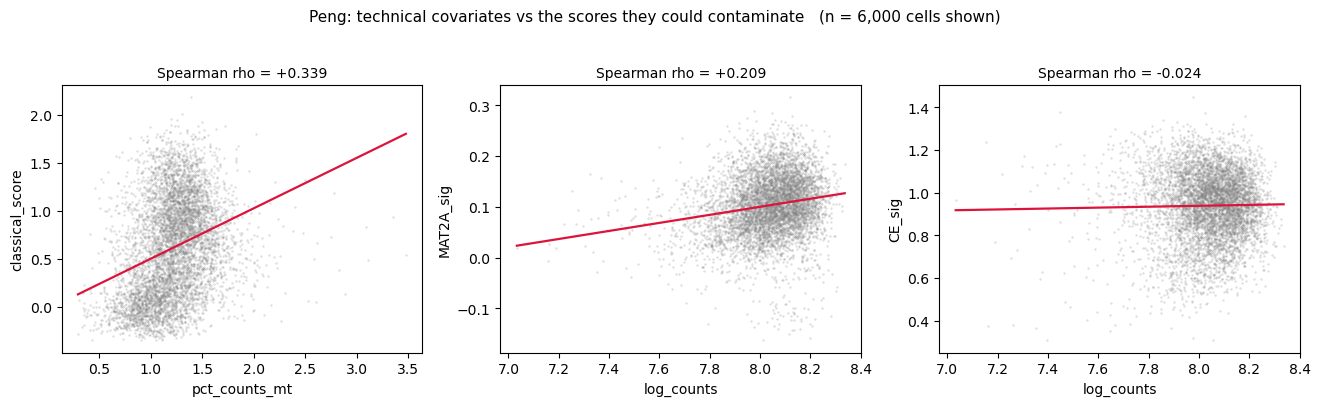

Both panels are non-flat, which is why every rho in this notebook is a PARTIAL
rho with both sides residualised on QC ranks. A flat panel would mean the
correction was unnecessary; these are not flat.


In [19]:
# ==========================================================================
# 13b · TECHNICAL COVARIATES, DRAWN (Peng et al.)
# Same associations as the table above, as scatter + fit. Non-flat panels are the point:
# they are why every coefficient in this notebook is a partial rho with both sides
# residualised on QC ranks.
# ==========================================================================

# FIGURE: the confound, drawn. Same numbers as the table above.
fig_confound(mal.obs,
             [("pct_counts_mt", "classical_score"),
              ("log_counts", "MAT2A_sig"),
              ("log_counts", "CE_sig")],
             "Peng: technical covariates vs the scores they could contaminate",
             "peng")
print("Both panels are non-flat, which is why every rho in this notebook is a PARTIAL")
print("rho with both sides residualised on QC ranks. A flat panel would mean the")
print("correction was unnecessary; these are not flat.")

## 14 · Uncontrolled within-patient baseline

*Results → Distribution of the dependency signatures across malignant states.* The within-patient Spearman correlation with **no** covariate correction: the analysis a standard pipeline would run. It is reported so that the effect of the controls in the following sections is visible as a change from this baseline rather than asserted.

In [20]:
# ==========================================================================
# 14 · UNCONTROLLED WITHIN-PATIENT BASELINE
# Within-patient Spearman with NO covariate correction -- the baseline a standard pipeline
# would report, shown so the effect of the controls is visible as a change from it.
# ==========================================================================

print("NAIVE within-patient Spearman vs classical score (NO controls)\n")
show([summarise(naive_spearman(mal.obs, t + "_sig"), t) for t in TARGETS])

NAIVE within-patient Spearman vs classical score (NO controls)

  signature                   n       neg    mean_rho         p
  VPS4A                      24     16/24     -0.0487    0.1074
  PRMT5                      24     10/24     +0.0207    0.2182
  MAT2A                      24      1/24     +0.3272    0.0000


## 15 · QC-controlled partial correlation and negative controls: Peng et al.  ·  Supplementary Table S2, Fig. 3a

*Methods → Statistical analysis; Controls. Results → Distribution of the dependency signatures across malignant states.* The within-patient partial Spearman correlation with the classical score (both sides residualised on the QC covariates) is computed for the three target signatures and the commonly essential control, together with the first two negative controls of Supplementary Table S3:

- **random-gene null**: 1,000 sets of 96 genes drawn from the detected transcriptome. Is the coefficient above chance?
- **expression-matched null** (section 18): 1,000 sets in which each signature gene is replaced by a gene of comparable mean expression (±20%). Is the coefficient explained by expression level alone?
- **commonly essential control**: does generic essentiality move with the classical score, and how far?

Each coefficient is expressed as its distance from the random-gene null in null SDs. The variability/detection-matched and covariance-matched nulls, confidence intervals, empirical p values, Benjamini–Hochberg q values and equivalence tests are added in section 28.

**Each stochastic step takes its own generator seeded from `SEED`**, rather than drawing from a shared stream, so the draws of one null cannot depend on how many random numbers earlier cells consumed. Gene pools are sorted before sampling, because Python orders sets of strings differently in each new process.

**Why these choices**

| choice | why |
|---|---|
| Random sets of 96 detected genes | The same size as the scored signatures and drawn only from detected genes, so a null set has the same opportunity to be scored as a signature. |
| Expression-matched sets, each gene replaced by one within ±20% mean expression | Tight enough to match expression level, loose enough to leave many candidates per gene. |
| 1,000 sets per null | A precise null mean and SD; empirical p down to 0.001. |
| Two SDs as the reference line | A convention, fixed before the results and reported as one, alongside empirical p values, CIs and q values (section 28). |
| The commonly essential control | If a target signature behaved like generic essentiality, it would move with the classical score in the same way. |

In [21]:
# ==========================================================================
# 15a · QC-CONTROLLED PARTIAL CORRELATION + NEGATIVE CONTROLS (Peng et al.)   ·   Supplementary Table S2, Fig. 3a
# res: partial Spearman vs classical score for the three targets + commonly-essential.
# null: the random-gene-set null (N_NULL size-matched draws). SD-from-random reported for
# each. See the inline note on why each stochastic step gets its OWN generator.
# ==========================================================================

# Each stochastic step below takes its OWN generator, seeded from SEED, rather than
# drawing from the shared `rng`. With a shared generator, which gene sets the null
# draws depends on how many random numbers every earlier cell happened to consume --
# so adding a figure, or a QC step that subsamples, silently reseeds the null. That is
# what moved common-essential from -3.5 to -2.5 to -1.9 SD across runs whose rhos were
# byte-identical. Separate streams make each null reproducible on its own terms.
# WHY the random null: SIG_SIZE genes drawn from DETECTED genes only, so a null set has the same
# chance of being scored as a signature. Sorted before sampling because Python randomises string
# hashing per process, so the order of a set of gene names changes between sessions.
def random_null(ad, present, n=N_NULL):
    _null_rng = np.random.default_rng(SEED)
    out = []
    for _ in range(n):
        g = list(_null_rng.choice(sorted(present), size=SIG_SIZE, replace=False))
        sc.tl.score_genes(ad, g, score_name="_r", use_raw=True)
        out.append(np.mean(list(partial_spearman(ad.obs, "_r").values())))
    return np.array(out)

# WHY +/-20% mean expression: tight enough to match expression level, loose enough to leave many
# candidates per gene. The question it answers: does expression level alone explain the effect?
def expression_matched_null(ad, template, n=N_NULL):
    _expr_rng = np.random.default_rng(SEED + 1)   # own stream -- see random_null
    # .raw.X directly -- to_adata() here copied the entire matrix for a column mean
    gm = pd.Series(np.asarray(ad.raw.X.mean(axis=0)).ravel(),
                   index=list(ad.raw.var_names))
    out = []
    for _ in range(n):
        picked = []
        for g in template:
            if g not in gm.index:
                continue
            cands = gm[(gm > gm[g] * 0.8) & (gm < gm[g] * 1.2)].index
            if len(cands):
                picked.append(str(_expr_rng.choice(cands)))
        sc.tl.score_genes(ad, list(set(picked)), score_name="_m", use_raw=True)
        out.append(np.mean(list(partial_spearman(ad.obs, "_m").values())))
    return np.array(out)

res = {t: partial_spearman(mal.obs, t + "_sig") for t in TARGETS}
res["common_essential"] = partial_spearman(mal.obs, "CE_sig")
null = random_null(mal, raw)

print("PARTIAL SPEARMAN vs classical score (QC-controlled, BOTH sides)\n")
show([summarise(v, k) for k, v in res.items()])
print("\nrandom null (n={}): mean {:+.4f} | sd {:.4f}\n".format(N_NULL, null.mean(), null.std()))
print("  {:<24}{:>16}".format("signature", "SD from random"))
for k, v in res.items():
    print("  {:<24}{:>+16.1f}".format(k, sd_from(summarise(v)["mean_rho"], null)))

PARTIAL SPEARMAN vs classical score (QC-controlled, BOTH sides)

  signature                   n       neg    mean_rho         p
  VPS4A                      24     15/24     -0.0365    0.1515
  PRMT5                      24      9/24     +0.0325    0.0691
  MAT2A                      24      2/24     +0.3094    0.0000
  common_essential           24     19/24     -0.1650    0.0007

random null (n=1000): mean +0.0186 | sd 0.0850

  signature                 SD from random
  VPS4A                               -0.6
  PRMT5                               +0.2
  MAT2A                               +3.4
  common_essential                    -2.2


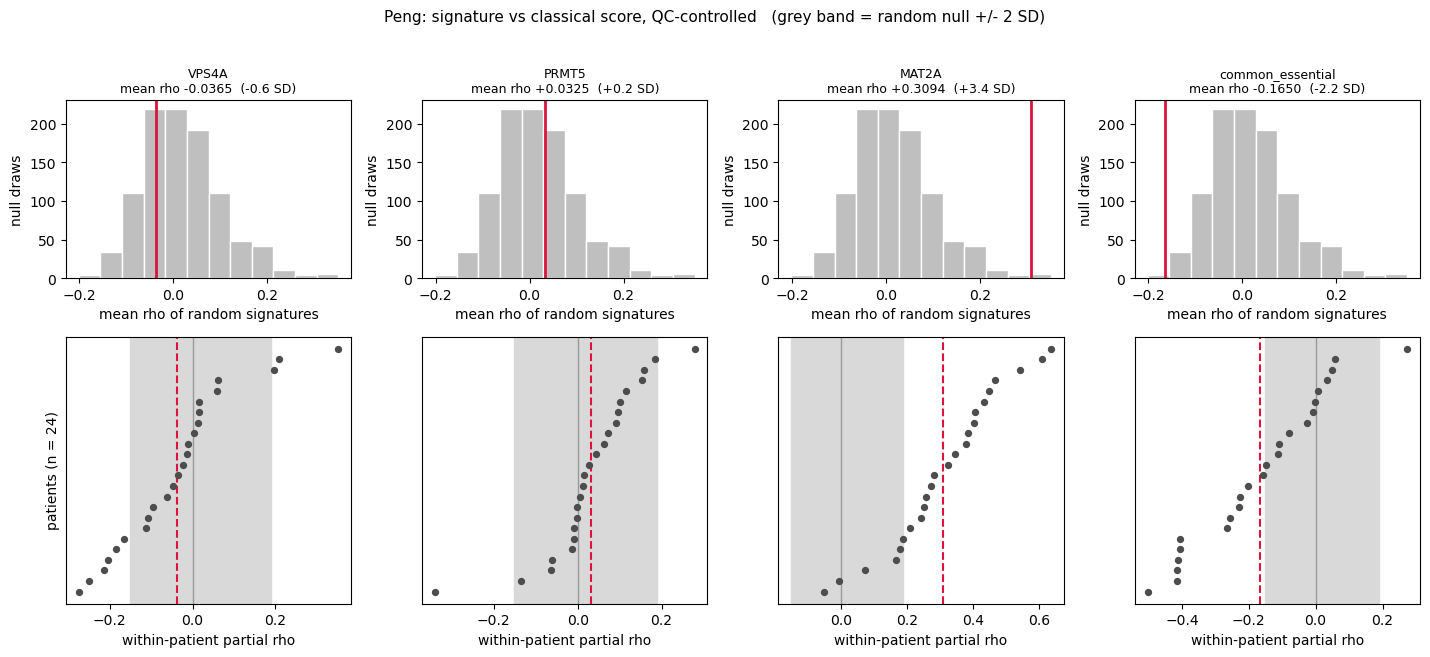

In [22]:
# ==========================================================================
# 15b · RANDOM-GENE NULL + PER-PATIENT FOREST (Peng et al.)
# Pure consumer: reads res and null from the cell above and recomputes nothing.
# ==========================================================================

# FIGURE: null distributions and per-patient consistency (Peng).
# Reads the objects computed in the cell above; recomputes nothing.
fig_null_and_forest(res, null,
                    "Peng: signature vs classical score, QC-controlled",
                    "peng",
                    keys=TARGETS + ["common_essential"])

## 16 · Head-to-head comparison with the commonly essential control  ·  Fig. 3e

*Methods → Controls; Results → Distribution of the dependency signatures across malignant states.* Paired **within patient**, on the same cells: each patient contributes its target coefficient and its commonly essential coefficient, and the **difference** (Δρ) is tested across patients with a Wilcoxon signed-rank test, so any patient-level factor that moves both signatures cancels. A target that merely matches generic essentiality *is* generic essentiality. The interpretation turns on **direction**: because the commonly essential control falls with the classical score, a signature that stays flat sits above it only because the control is depleted, whereas a signature that rises with the classical score sits above it in the one direction a generic-essentiality confound cannot produce.

**Why a paired test.** Both coefficients come from the same cells of the same patient, so anything that moves both (cell number, sequencing depth, tumour composition) cancels in the difference.

In [23]:
# ==========================================================================
# 16a · HEAD-TO-HEAD vs THE COMMONLY ESSENTIAL CONTROL (Peng et al.)   ·   data for Fig. 3e
# Paired within patient (Delta-rho), Wilcoxon-tested. MAT2A beats the control in the
# OPPOSITE direction -- the one direction a generic-essentiality confound cannot fake.
# ==========================================================================

print("HEAD-TO-HEAD vs COMMON-ESSENTIAL (paired, within patient) -- PENG\n")
print("  {:<12}{:>5}{:>13}{:>20}{:>10}".format("target", "n", "mean diff", "more neg than CE", "p"))
for t in TARGETS:
    r = paired_vs(res[t], res["common_essential"])
    print("  {:<12}{:>5}{:>+13.4f}{:>20}{:>10.2g}".format(
        t, r["n"], r["mean_diff"], "{}/{}".format(r["n_more_neg"], r["n"]), r["p"]))
print("\n  MAT2A beats the control in the OPPOSITE direction, the one direction a")
print("  generic-essentiality confound cannot fake.")

HEAD-TO-HEAD vs COMMON-ESSENTIAL (paired, within patient) -- PENG

  target          n    mean diff    more neg than CE         p
  VPS4A          24      +0.1285                8/24     0.049
  PRMT5          24      +0.1976                3/24   8.3e-06
  MAT2A          24      +0.4744                3/24     3e-06

  MAT2A beats the control in the OPPOSITE direction, the one direction a
  generic-essentiality confound cannot fake.


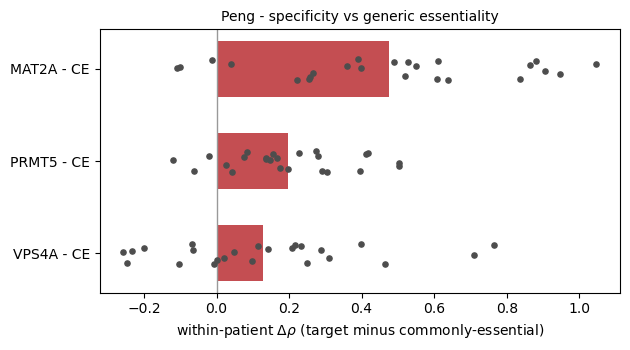

MAT2A is displaced above the control by being ENRICHED; VPS4A/PRMT5 sit above
it only because the control is depleted and they are flat.


In [24]:
# ===========================================================================
# 16b · FIGURE - HEAD-TO-HEAD vs THE COMMONLY ESSENTIAL CONTROL (Peng et al.)
# ===========================================================================
# Pure consumer of `res` from Section 16's cell: the within-patient difference
# (Delta-rho) between each target signature and the commonly-essential control.
# Bar = mean across patients; grey points = individual patients. Recomputes
# nothing stochastic.
if FIGURES:
    _keys = TARGETS
    _fig, _ax = plt.subplots(figsize=(6.4, 3.6))
    for _i, _t in enumerate(_keys):
        _pats = sorted(set(res[_t]) & set(res["common_essential"]))
        _d = np.array([res[_t][p] - res["common_essential"][p] for p in _pats])
        _ax.barh(_i, _d.mean(), color="#C44E52", height=0.6, zorder=2)
        _ax.scatter(_d, np.full(len(_d), _i) + np.random.default_rng(SEED).uniform(-0.12, 0.12, len(_d)),
                    s=14, color="0.3", zorder=3)
    _ax.axvline(0, color="0.6", lw=1)
    _ax.set_yticks(range(len(_keys)))
    _ax.set_yticklabels([t + " - CE" for t in _keys])
    _ax.set_xlabel(r"within-patient $\Delta\rho$ (target minus commonly-essential)")
    _ax.set_title("Peng - specificity vs generic essentiality", fontsize=10)
    plt.tight_layout()
    _show("peng_head_to_head")
    print("MAT2A is displaced above the control by being ENRICHED; VPS4A/PRMT5 sit above")
    print("it only because the control is depleted and they are flat.")

## 17 · Gene-overlap positive controls

*Methods → Controls; Results → Distribution of the dependency signatures across malignant states.* Two signatures with **known** state restriction, the proliferation signature against the cell-cycle program and the classical score against the classical program, are passed through the same program-restriction comparison (each patient's program-high cells, the top tertile, against the rest). The three target signatures are shown on the same axis for scale.

These controls share genes with the program they are tested against, so they show only that the comparison detects restriction in that favourable case and exclude only gross insensitivity. They do not establish sensitivity for a signature derived from DepMap. That is measured with dependency-based controls: two from the literature (section 29, uninformative because their DepMap premise fails) and 40 selected in DepMap by a fixed rule (sections 35–38). Equivalence to zero for the flat results is tested in section 28. Section 29b re-expresses this comparison on standardised and rank scales (Supplementary Fig. S4).

**Why tertiles.** Splitting each patient's cells at the top third of a program score gives a program-high group large enough for a stable mean in every patient, without a model of the score's distribution; section 29b shows that the choice of scale does not drive the comparison.

In [25]:
# ==========================================================================
# 17a · GENE-OVERLAP POSITIVE CONTROLS (program restriction)
# program_restriction: within-patient difference between program-high cells (top tertile)
# and the rest. Proliferation->cell-cycle and classical->classical are KNOWN state-restricted
# and should register strongly; the targets, on the same axis, should not. These controls
# share genes with their programs, so they show the pipeline can detect restriction in that
# favourable case only; sensitivity for derived signatures is measured in §28 (equivalence),
# §29 (literature dependency controls) and §35-37 (dependency controls chosen in DepMap).
# ==========================================================================

def program_restriction(obs, score_col, program, min_cells=MIN_CELLS):
    col = "prog_" + program
    diffs = []
    for pat, g in obs.groupby("Patient", observed=True):
        if len(g) < min_cells:
            continue
        thr = g[col].quantile(0.66)
        hi, lo = g.loc[g[col] >= thr, score_col], g.loc[g[col] < thr, score_col]
        if len(hi) >= 10 and len(lo) >= 10:
            diffs.append(hi.mean() - lo.mean())
    d = np.array(diffs)
    return dict(n=len(d), mean_diff=float(d.mean()), p=float(wilcoxon(d)[1]))

print("POSITIVE CONTROLS (known state-restriction)\n")
print("  {:<18}{:<16}{:>5}{:>13}{:>10}".format("score", "program", "n", "mean diff", "p"))
for s_col, prog in [("prolif", "4_cellcycle"),
                    ("classical_score", CLASSICAL_PROG)]:
    r = program_restriction(mal.obs, s_col, prog)
    print("  {:<18}{:<16}{:>5}{:>+13.4f}{:>10.4f}".format(
        s_col, prog, r["n"], r["mean_diff"], r["p"]))
print("\n  The targets on the same axis, for scale:\n")
for t in TARGETS:
    r = program_restriction(mal.obs, t + "_sig", CLASSICAL_PROG)
    print("  {:<18}{:<16}{:>5}{:>+13.4f}{:>10.4f}".format(
        t + "_sig", CLASSICAL_PROG, r["n"], r["mean_diff"], r["p"]))
print("\n  -> the gene-overlap controls register far more strongly than the targets. Because they")
print("     share genes with their programs, this does not by itself show power for the targets;")
print("     see §28 (equivalence) and §35-37 (dependency-based positive controls).")

POSITIVE CONTROLS (known state-restriction)

  score             program             n    mean diff         p
  prolif            4_cellcycle        24      +0.2108    0.0000
  classical_score   8_classical        24      +0.3509    0.0000

  The targets on the same axis, for scale:

  VPS4A_sig         8_classical        24      +0.0047    0.2076
  PRMT5_sig         8_classical        24      -0.0082    0.0001
  MAT2A_sig         8_classical        24      +0.0292    0.0000

  -> the gene-overlap controls register far more strongly than the targets. Because they
     share genes with their programs, this does not by itself show power for the targets;
     see §28 (equivalence) and §35-37 (dependency-based positive controls).


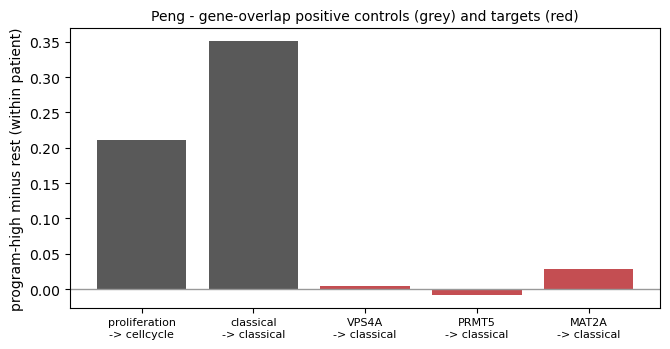

The gene-overlap controls register; compare the targets on the same axis.
Whether the VPS4A/PRMT5 results are true absences is tested in §28 (equivalence)
and §35-37 (dependency-based positive controls).


In [26]:
# ===========================================================================
# 17b · FIGURE - GENE-OVERLAP POSITIVE CONTROLS vs TARGETS on the program-restriction axis
# ===========================================================================
# Recomputes via the same deterministic helper (program_restriction) used in the
# table above - no RNG, so identical to the printed values. The two gene-overlap
# controls are drawn next to the three targets.
if FIGURES:
    _rows = [("proliferation", "prolif", "4_cellcycle"),
             ("classical", "classical_score", CLASSICAL_PROG),
             ("VPS4A", "VPS4A_sig", CLASSICAL_PROG),
             ("PRMT5", "PRMT5_sig", CLASSICAL_PROG),
             ("MAT2A", "MAT2A_sig", CLASSICAL_PROG)]
    _labels, _vals, _cols = [], [], []
    for _name, _sc, _prog in _rows:
        _r = program_restriction(mal.obs, _sc, _prog)
        _labels.append("{}\n-> {}".format(_name, _prog.split("_", 1)[-1]))
        _vals.append(_r["mean_diff"])
        _cols.append("0.35" if _name in ("proliferation", "classical") else "#C44E52")
    _fig, _ax = plt.subplots(figsize=(6.8, 3.6))
    _ax.bar(range(len(_labels)), _vals, color=_cols)
    _ax.axhline(0, color="0.6", lw=1)
    _ax.set_xticks(range(len(_labels)))
    _ax.set_xticklabels(_labels, fontsize=8)
    _ax.set_ylabel("program-high minus rest (within patient)")
    _ax.set_title("Peng - gene-overlap positive controls (grey) and targets (red)", fontsize=10)
    plt.tight_layout()
    _show("peng_positive_controls")
    print("The gene-overlap controls register; compare the targets on the same axis.")
    print("Whether the VPS4A/PRMT5 results are true absences is tested in §28 (equivalence)")
    print("and §35-37 (dependency-based positive controls).")

## 18 · Robustness of the MAT2A association: the first six tests, Peng et al.  ·  Table 1

*Methods → Robustness tests; Results → Robustness of the MAT2A association with the classical state.* Only the *MAT2A* signature cleared the negative controls on the classical axis, so it alone enters the robustness tests. **Each pass criterion was fixed before the test was computed** (Supplementary Table S6). This section runs the six tests that need only the objects of sections 11–17; the further tests of Table 1 (doublets, high-confidence cells, passenger loss, independent programs, identity genes, alternative derivations, matched nulls) follow in sections 22–32, and section 32 collects every test for both discovery cohorts with 95% confidence intervals (Fig. 4c).

| test | challenge | passes if |
|---|---|---|
| **Circularity** | overlap with the Moffitt et al. classical and basal genes | no shared classical gene drives it |
| **Proliferation** | proliferation added to the QC covariates | the effect persists |
| **Scoring method** | re-scored with a rank-based measure | the effect persists |
| **Aneuploidy** | restricted to CNV-positive cells (Peng et al., section 10) | the effect persists |
| **Single gene** | each gene dropped in turn | no gene shifts the mean by more than 30% |
| **Compositional** | compared with the expression-matched null | at least 2 SD from that null |

**Why each test**

| test | the alternative explanation it addresses |
|---|---|
| Circularity | The signature shares genes with the classical list, so the correlation would partly be a gene list correlating with itself. A shared *basal* gene works against the association, so it is conservative. |
| Proliferation | Cell cycling drives both the classical score and the signature. |
| Scoring method | The association is an artefact of the control-gene subtraction in `score_genes`. |
| Aneuploidy | Non-malignant cells in the compartment create the association. Restricting to CNV-positive cells removes cells from every patient, so the per-patient minimum is 30 here. |
| Single gene | One gene carries the association. A gene shifting the mean by more than 30% would make the signature effectively a single-gene readout. |
| Compositional | Expression level alone produces the association. |

In [27]:
# ==========================================================================
# 18a · MAT2A ROBUSTNESS -- CIRCULARITY, PROLIFERATION (Peng et al.)   ·   Table 1
# Circularity: MAT2A signature genes vs the Moffitt classical/basal lists (a shared basal
# gene works AGAINST the enrichment, so it is conservative, not circular).
# Proliferation: adding proliferation to the QC covariates barely moves the coefficient,
# so the association is not a proliferation effect.
# ==========================================================================

mat = [g for g in signatures["MAT2A"] if g in raw]
full = summarise(res["MAT2A"])["mean_rho"]

print("CIRCULARITY")
print("    MAT2A n Moffitt-CLASSICAL: {}  {}".format(
    len(set(mat) & set(MOFFITT_CLASSICAL)), sorted(set(mat) & set(MOFFITT_CLASSICAL))))
print("    MAT2A n Moffitt-BASAL:     {}  {}".format(
    len(set(mat) & set(MOFFITT_BASAL)), sorted(set(mat) & set(MOFFITT_BASAL))))
print("    NB: a BASAL marker in a classical-ENRICHED signature works AGAINST the")
print("        finding -- it makes the result conservative, not circular.\n")

print("PROLIFERATION")
print("    classical vs prolif: {:+.3f} | MAT2A vs prolif: {:+.3f}".format(
    spearmanr(mal.obs["classical_score"], mal.obs["prolif"])[0],
    spearmanr(mal.obs["MAT2A_sig"], mal.obs["prolif"])[0]))
print("    (both nonzero => the mediation path classical <- prolif -> MAT2A is OPEN)\n")
show([summarise(res["MAT2A"], "MAT2A | QC only"),
      summarise(partial_spearman(mal.obs, "MAT2A_sig", covars=QC_COVARS + ["prolif"]),
                "MAT2A | QC + prolif")])

CIRCULARITY
    MAT2A n Moffitt-CLASSICAL: 0  []
    MAT2A n Moffitt-BASAL:     1  ['CTSV']
    NB: a BASAL marker in a classical-ENRICHED signature works AGAINST the
        finding -- it makes the result conservative, not circular.

PROLIFERATION
    classical vs prolif: -0.114 | MAT2A vs prolif: -0.183
    (both nonzero => the mediation path classical <- prolif -> MAT2A is OPEN)

  signature                   n       neg    mean_rho         p
  MAT2A | QC only            24      2/24     +0.3094    0.0000
  MAT2A | QC + prolif        24      2/24     +0.2965    0.0000


In [28]:
# ==========================================================================
# 18b · MAT2A ROBUSTNESS -- SCORING METHOD, ANEUPLOIDY (Peng et al.)   ·   Table 1
# Scoring method: AUCell-style rank scoring reproduces the effect (no shared arithmetic
# with score_genes). Aneuploidy: restricting to CNV-positive cells (30-cell floor, since
# the restriction thins each patient) leaves MAT2A intact and VPS4A/PRMT5 null.
# ==========================================================================

print("SCORING METHOD -- AUCell-style rank scoring\n")
mal.obs["MAT2A_auc"] = manual_aucell(mal, mat)
show([summarise(partial_spearman(mal.obs, "MAT2A_auc"), "MAT2A | AUCell")])
print("\n    AUCell vs score_genes agreement: {:+.3f}".format(
    spearmanr(mal.obs["MAT2A_auc"], mal.obs["MAT2A_sig"])[0]))

sub = None                                   # stays None if the aneuploidy test cannot run
if not os.path.exists(PENG_CNV):
    print("\n\nANEUPLOIDY test skipped -- peng_infercnv_v2.h5ad is missing (§23 gives the per-patient CNV-positive test)")
else:
    print("\n\nANEUPLOIDY -- CNV-positive cells only\n")
    cnvobj = sc.read_h5ad(PENG_CNV)
    ref = cnvobj.obs.loc[cnvobj.obs[MAL_COL].isin(["Immune cells", "Stromal cells"]), "cnv_score"]
    aneu = set(cnvobj.obs.index[(cnvobj.obs[MAL_COL] == "Malignant cells") &
                                (cnvobj.obs["cnv_score"] > ref.quantile(0.95))])
    sub = mal.obs[mal.obs.index.isin(aneu)].copy()
    print("    CNV-positive cells: {:,}\n".format(len(sub)))
    show([summarise(partial_spearman(sub, t + "_sig", min_cells=30), t + " | CNV-positive")
          for t in TARGETS])

SCORING METHOD -- AUCell-style rank scoring

  signature                   n       neg    mean_rho         p
  MAT2A | AUCell             24      0/24     +0.2479    0.0000

    AUCell vs score_genes agreement: +0.693


ANEUPLOIDY -- CNV-positive cells only

    CNV-positive cells: 3,329

  signature                   n       neg    mean_rho         p
  VPS4A | CNV-positive       20     13/20     -0.0430    0.1327
  PRMT5 | CNV-positive       20      6/20     +0.0101    0.3488
  MAT2A | CNV-positive       20      1/20     +0.2403    0.0000


In [29]:
# ==========================================================================
# 18c · MAT2A ROBUSTNESS -- SINGLE-GENE, COMPOSITIONAL (Peng et al.)   ·   Table 1
# Single-gene (leave-one-out): no single gene shifts the mean coefficient by more than 30%.
# Compositional: MAT2A sits > 2 SD above the harder EXPRESSION-MATCHED null.
# ==========================================================================

print("SINGLE-GENE -- leave-one-out\n")
deltas = []
for g in mat:
    sc.tl.score_genes(mal, [x for x in mat if x != g], score_name="_lo", use_raw=True)
    deltas.append((g, np.mean(list(partial_spearman(mal.obs, "_lo").values())) - full))
deltas.sort(key=lambda x: abs(x[1]), reverse=True)
print("    MAT2A full mean |rho = {:+.4f}\n".format(full))
for g, d in deltas[:5]:
    print("      drop {:<12} -> {:+.4f}   ({:.0f}% of effect)".format(
        g, d, abs(d) / abs(full) * 100))

print("\n\nCOMPOSITIONAL -- expression-matched null\n")
mnull = expression_matched_null(mal, mat)
print("    MAT2A                          : {:+.4f}".format(full))
print("    expression-matched nulls (n={}) : mean {:+.4f} | sd {:.4f}".format(
    N_NULL, mnull.mean(), mnull.std()))
print("\n    -> MAT2A is {:+.1f} SD from the EXPRESSION-MATCHED null".format(sd_from(full, mnull)))

SINGLE-GENE -- leave-one-out

    MAT2A full mean |rho = +0.3094

      drop C19orf33     -> -0.0323   (10% of effect)
      drop CAPN8        -> -0.0298   (10% of effect)
      drop TPD52        -> -0.0209   (7% of effect)
      drop APOBEC3H     -> -0.0147   (5% of effect)
      drop TNFSF13      -> -0.0141   (5% of effect)


COMPOSITIONAL -- expression-matched null

    MAT2A                          : +0.3094
    expression-matched nulls (n=1000) : mean +0.0785 | sd 0.0932

    -> MAT2A is +2.5 SD from the EXPRESSION-MATCHED null


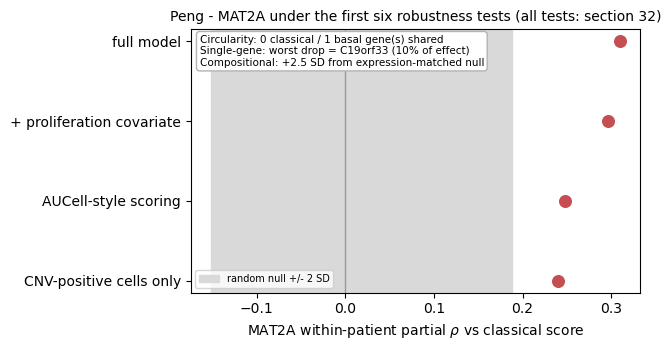

In [30]:
# ===========================================================================
# 18d · FIGURE - MAT2A UNDER THE FIRST SIX ROBUSTNESS TESTS (Peng et al.)
# ===========================================================================
# Consumes objects the robustness cells above already left in the namespace
# (full, sub, mnull, deltas, mat, null) and recomputes only the two cheap,
# deterministic partial-Spearman means for the +proliferation and AUCell rows
# (no RNG, no h5ad re-read). Each row is the MAT2A partial rho under one
# challenge, against the same +/-2 SD random-null band as section 15. Section 32 extends this
# to every test in Table 1 and both discovery cohorts (the version drawn in Fig. 4c).
if FIGURES:
    _full_rho  = full                                              # full model
    _prolif_rho = np.mean(list(partial_spearman(
        mal.obs, "MAT2A_sig", covars=QC_COVARS + ["prolif"]).values()))
    _auc_rho   = np.mean(list(partial_spearman(mal.obs, "MAT2A_auc").values()))
    _rows = [("full model", _full_rho),
             ("+ proliferation covariate", _prolif_rho),
             ("AUCell-style scoring", _auc_rho)]
    if sub is not None:                                            # the aneuploidy test ran
        _rows.append(("CNV-positive cells only",
                      np.mean(list(partial_spearman(sub, "MAT2A_sig", min_cells=30).values()))))
    _fig, _ax = plt.subplots(figsize=(6.6, 3.6))
    _y = np.arange(len(_rows))[::-1]
    _ax.axvspan(null.mean() - 2 * null.std(), null.mean() + 2 * null.std(),
                color="0.85", zorder=0, label="random null +/- 2 SD")
    _ax.axvline(0, color="0.6", lw=1)
    _ax.scatter([v for _, v in _rows], _y, s=70, color="#C44E52", zorder=3)
    _ax.set_yticks(_y)
    _ax.set_yticklabels([n for n, _ in _rows])
    _ax.set_xlabel(r"MAT2A within-patient partial $\rho$ vs classical score")
    _ax.set_title("Peng - MAT2A under the first six robustness tests (all tests: section 32)", fontsize=10)
    # circularity / single-gene / compositional are not coefficients on this axis -> annotate them
    _circ_c = len(set(mat) & set(MOFFITT_CLASSICAL))
    _circ_b = len(set(mat) & set(MOFFITT_BASAL))
    _worst_g, _worst_d = deltas[0]
    _comp_sd = sd_from(full, mnull)
    _txt = ("Circularity: {} classical / {} basal gene(s) shared\n"
            "Single-gene: worst drop = {} ({:.0f}% of effect)\n"
            "Compositional: {:+.1f} SD from expression-matched null").format(
        _circ_c, _circ_b, _worst_g, abs(_worst_d) / abs(full) * 100, _comp_sd)
    # All four points hug the RIGHT edge, so both annotations live on the LEFT half:
    # the annotation box in the upper-left (va="top", y=0.98) and the legend in the
    # lower-left, which keeps the whole right column clear for the points.
    _ax.legend(loc="lower left", fontsize=7)
    _ax.text(0.02, 0.98, _txt, transform=_ax.transAxes, fontsize=7.5, va="top",
             bbox=dict(boxstyle="round", fc="white", ec="0.7"))
    plt.tight_layout()
    _show("peng_mat2a_robustness")

## 19 · Steele et al.: the same analysis  ·  Supplementary Table S2, Fig. 3b

*Results → Distribution of the dependency signatures across malignant states.* The **entire** pipeline of sections 15–18 (the QC-controlled partial correlation, the random-gene null, the head-to-head comparison with the commonly essential control, and the proliferation, scoring-method and compositional tests) is re-run on the second discovery cohort with the same functions and thresholds. The two discovery cohorts were generated and processed upstream by different groups, and the Steele et al. malignant compartment is assigned from clusters (section 7), so the comparison is informative about the data rather than the settings. This section also plots each signature's mean coefficient in Peng et al. against Steele et al.

**Why the same code.** Running the identical functions, thresholds and controls on the second cohort means that any difference between cohorts comes from the data, not from the analysis.

In [31]:
# ==========================================================================
# 19a · STEELE ET AL. -- THE SAME ANALYSIS   ·   Supplementary Table S2, Fig. 3b
# The whole pipeline on the second cohort: partial Spearman + nulls, head-to-head vs
# commonly-essential, and the proliferation, scoring-method and compositional robustness
# tests. s_res / s_null mirror res / null.
# ==========================================================================

s_res = {t: partial_spearman(steele.obs, t + "_sig") for t in TARGETS}
s_res["common_essential"] = partial_spearman(steele.obs, "CE_sig")
s_null = random_null(steele, sraw)

print("STEELE -- partial Spearman vs classical score\n")
show([summarise(v, k) for k, v in s_res.items()])
print("\n  {:<24}{:>16}".format("signature", "SD from random"))
for k, v in s_res.items():
    print("  {:<24}{:>+16.1f}".format(k, sd_from(summarise(v)["mean_rho"], s_null)))

print("\n\nSTEELE -- head-to-head vs common-essential (paired)\n")
print("  {:<12}{:>5}{:>13}{:>20}{:>10}".format("target", "n", "mean diff", "more neg than CE", "p"))
for t in TARGETS:
    r = paired_vs(s_res[t], s_res["common_essential"])
    print("  {:<12}{:>5}{:>+13.4f}{:>20}{:>10.4f}".format(
        t, r["n"], r["mean_diff"], "{}/{}".format(r["n_more_neg"], r["n"]), r["p"]))

print("\n\nSTEELE -- MAT2A ROBUSTNESS TESTS (proliferation, scoring method, compositional)\n")
s_mat = [g for g in signatures["MAT2A"] if g in sraw]
steele.obs["MAT2A_auc"] = manual_aucell(steele, s_mat)
show([summarise(s_res["MAT2A"], "MAT2A | QC only"),
      summarise(partial_spearman(steele.obs, "MAT2A_sig", covars=QC_COVARS + ["prolif"]),
                "MAT2A | QC + prolif"),
      summarise(partial_spearman(steele.obs, "MAT2A_auc"), "MAT2A | AUCell")])
s_mnull = expression_matched_null(steele, s_mat)
print("\n  MAT2A is {:+.1f} SD from the expression-matched null (Steele)".format(
    sd_from(summarise(s_res["MAT2A"])["mean_rho"], s_mnull)))

STEELE -- partial Spearman vs classical score

  signature                   n       neg    mean_rho         p
  VPS4A                      14      3/14     +0.1573    0.0494
  PRMT5                      14     12/14     -0.1242    0.0134
  MAT2A                      14      0/14     +0.4290    0.0001
  common_essential           14     12/14     -0.2687    0.0009

  signature                 SD from random
  VPS4A                               +1.7
  PRMT5                               -1.2
  MAT2A                               +4.4
  common_essential                    -2.6


STEELE -- head-to-head vs common-essential (paired)

  target          n    mean diff    more neg than CE         p
  VPS4A          14      +0.4259                2/14    0.0031
  PRMT5          14      +0.1444                3/14    0.0052
  MAT2A          14      +0.6976                1/14    0.0002


STEELE -- MAT2A ROBUSTNESS TESTS (proliferation, scoring method, compositional)

  signature                

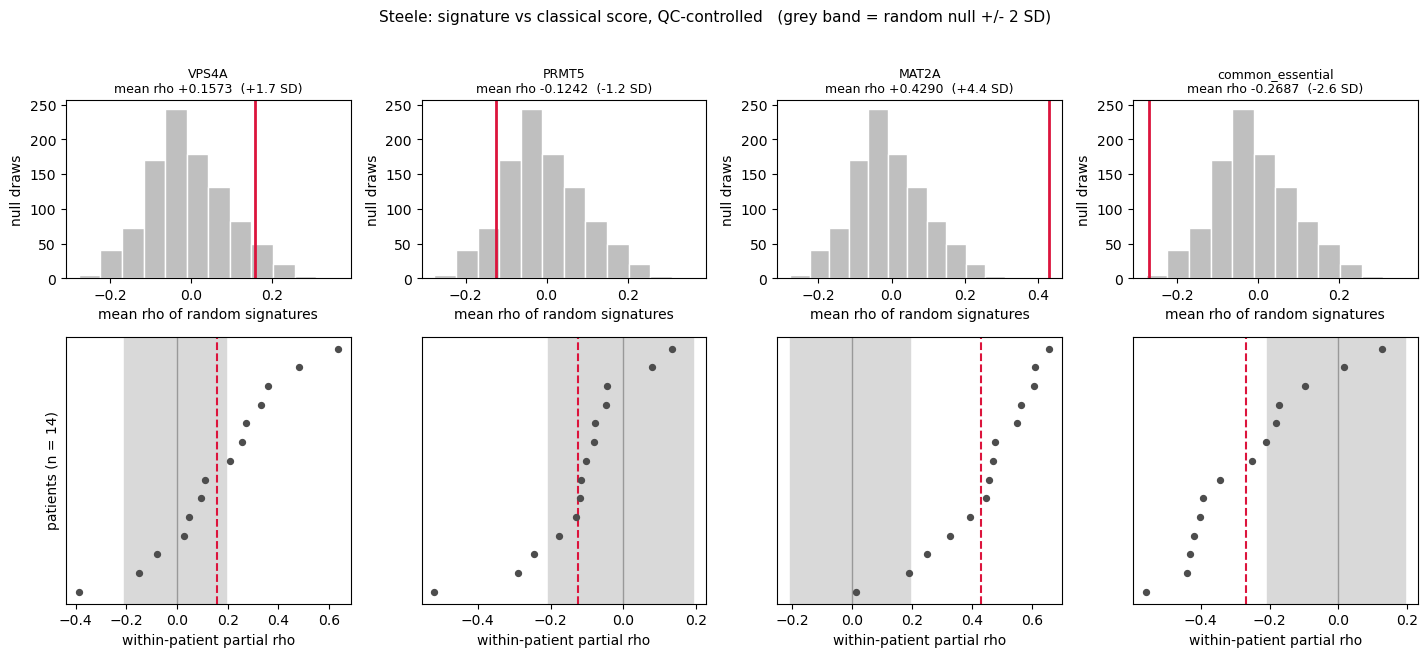

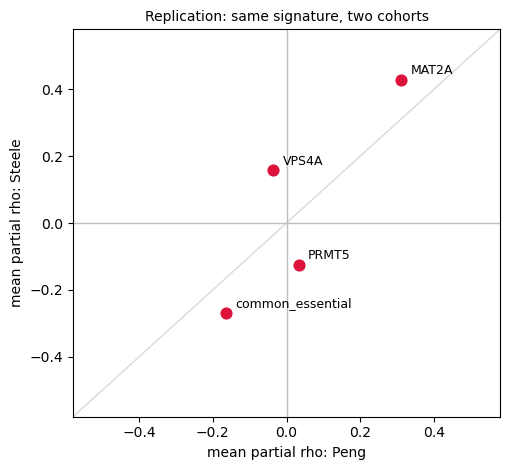

In [32]:
# ==========================================================================
# 19b · RANDOM-GENE NULL + FOREST (Steele et al.) and the PENG-vs-STEELE COMPARISON
# Mirrors the Peng figure so the cohorts can be compared by eye, then plots each signature's
# mean coefficient in Peng vs Steele (points on the diagonal = the cohorts agree).
# ==========================================================================

# FIGURE: null distributions and per-patient consistency (Steele).
# Mirrors the Peng figure exactly so the two cohorts can be compared by eye.
fig_null_and_forest(s_res, s_null,
                    "Steele: signature vs classical score, QC-controlled",
                    "steele",
                    keys=TARGETS + ["common_essential"])

# FIGURE: replication at a glance: each signature's rho in both cohorts.
if FIGURES:
    fig, ax = plt.subplots(figsize=(5.2, 4.8))
    keys = TARGETS + ["common_essential"]
    xs = [np.mean(list(res[k].values())) for k in keys]
    ys = [np.mean(list(s_res[k].values())) for k in keys]
    ax.axhline(0, color="0.75", lw=1)
    ax.axvline(0, color="0.75", lw=1)
    lim = max(map(abs, xs + ys)) * 1.35
    ax.plot([-lim, lim], [-lim, lim], color="0.85", lw=1, zorder=0)
    ax.scatter(xs, ys, s=60, color="crimson", zorder=3)
    for k, x, y in zip(keys, xs, ys):
        ax.annotate(k, (x, y), textcoords="offset points", xytext=(7, 4), fontsize=9)
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_xlabel("mean partial rho: Peng")
    ax.set_ylabel("mean partial rho: Steele")
    ax.set_title("Replication: same signature, two cohorts", fontsize=10)
    plt.tight_layout()
    _show("peng_vs_steele_replication")

## 20 · Werba et al.: the same analysis  ·  Supplementary Table S9b, Fig. 3c

*Results → Replication in an independent cohort.* The section 19 pipeline, unchanged, on the replication cohort (section 8): the QC-controlled partial correlation with the classical score against the random-gene null, the head-to-head comparison with the commonly essential control, and the proliferation, scoring-method and expression-matched tests for *MAT2A*. `w_res` and `w_null` mirror `res` / `null` (Peng et al.) and `s_res` / `s_null` (Steele et al.); every later section runs on all three cohorts. The two nulls, the slowest step on this cohort's malignant cells, are cached and recomputed only with `FORCE_REBUILD = True`.

**The replication criteria were fixed before any Werba et al. expression data were analysed** (Methods → Replication criteria). The *VPS4A*–basal and *MAT2A*–classical associations replicate if the mean is positive, the 95% patient-bootstrap CI excludes zero and the association clears the random-gene null on its axis (empirical p < 0.05). The *PRMT5* result replicates if the association is equivalent to zero within ±0.10 (two one-sided tests); if instead its 95% CI excludes zero it does not replicate, and otherwise the result is inconclusive. The verdicts are applied in section 34, once the basal-axis null (section 31a) and the equivalence test (section 28b) exist for this cohort.

WERBA -- partial Spearman vs classical score

  signature                   n       neg    mean_rho         p
  VPS4A                      11      6/11     -0.0167    0.8311
  PRMT5                      11      5/11     +0.0216    0.7646
  MAT2A                      11      0/11     +0.2978    0.0010
  common_essential           11      6/11     -0.0442    0.4131

random null (n=1000): mean -0.0224 | sd 0.0790

  signature                 SD from random
  VPS4A                               +0.1
  PRMT5                               +0.6
  MAT2A                               +4.1
  common_essential                    -0.3


WERBA -- head-to-head vs common-essential (paired)

  target          n    mean diff    more neg than CE         p
  VPS4A          11      +0.0275                4/11    0.7002
  PRMT5          11      +0.0658                3/11    0.3203
  MAT2A          11      +0.3420                1/11    0.0020


WERBA -- MAT2A ROBUSTNESS TESTS (proliferation, scoring method

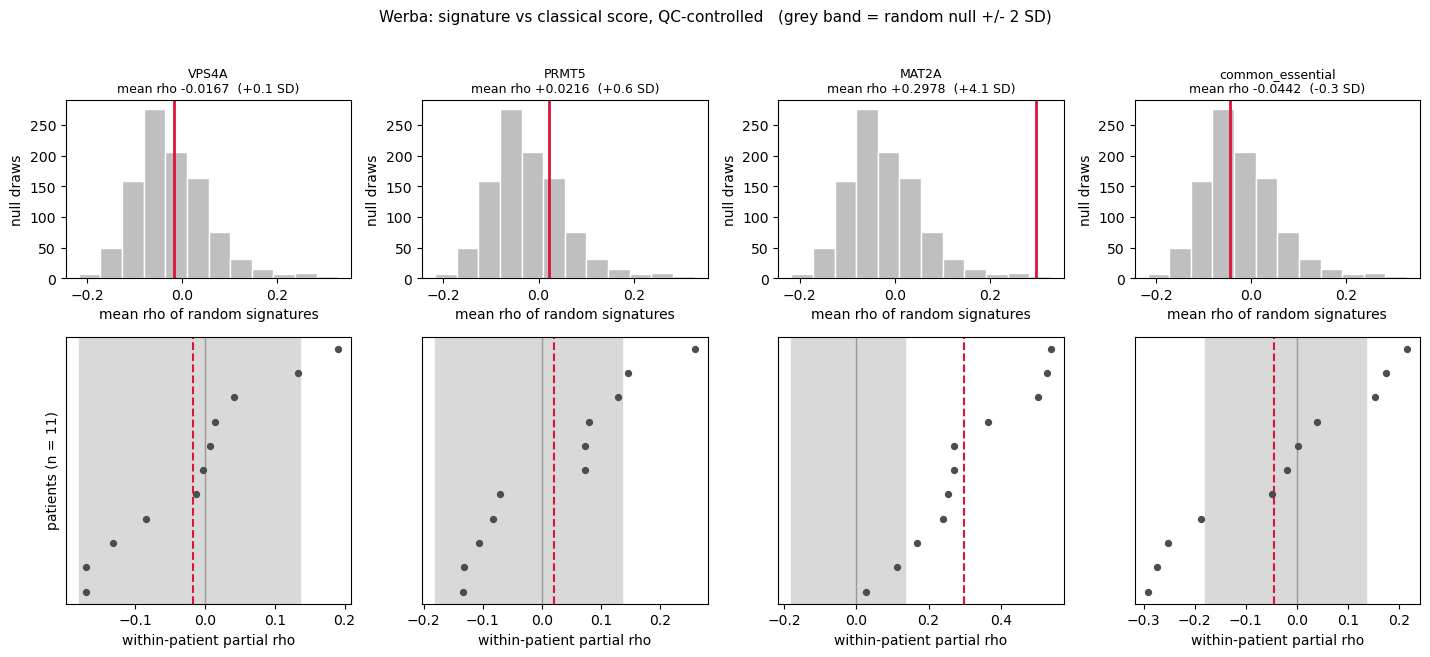

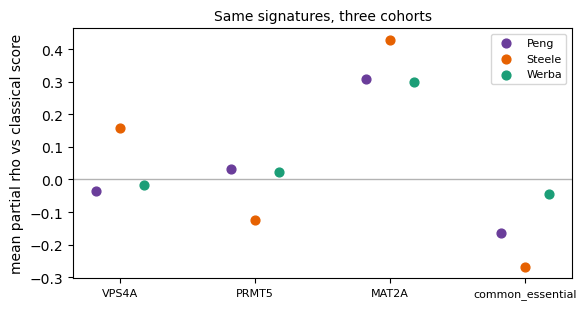

In [33]:
# ==========================================================================
# 20 · WERBA ET AL. -- THE SAME ANALYSIS   ·   Supplementary Table S9b, Fig. 3c
# Section 19's cell, unchanged, on Werba et al.: partial Spearman + random null, head-to-head vs
# commonly-essential, and the MAT2A proliferation / scoring-method / expression-matched tests.
# w_res / w_null mirror res / null and s_res / s_null. The two nulls (~35 min on Werba's ~38,000
# malignant cells) are cached in Downloads and recomputed only with FORCE_REBUILD = True.
# ==========================================================================

w_res = {t: partial_spearman(werba.obs, t + "_sig") for t in TARGETS}
w_res["common_essential"] = partial_spearman(werba.obs, "CE_sig")
w_mat = [g for g in signatures["MAT2A"] if g in wraw]
_wcache = os.path.join(DOWNLOADS, "werba_classical_nulls.npz")
if need_build(_wcache):
    w_null = random_null(werba, wraw)                     # section 15's generator, draws and statistic
    w_mnull = expression_matched_null(werba, w_mat)
    np.savez(_wcache, random=w_null, expression_matched=w_mnull)
else:
    _z = np.load(_wcache)
    w_null, w_mnull = _z["random"], _z["expression_matched"]

print("WERBA -- partial Spearman vs classical score\n")
show([summarise(v, k) for k, v in w_res.items()])
print("\nrandom null (n={}): mean {:+.4f} | sd {:.4f}".format(N_NULL, w_null.mean(), w_null.std()))
print("\n  {:<24}{:>16}".format("signature", "SD from random"))
for k, v in w_res.items():
    print("  {:<24}{:>+16.1f}".format(k, sd_from(summarise(v)["mean_rho"], w_null)))

print("\n\nWERBA -- head-to-head vs common-essential (paired)\n")
print("  {:<12}{:>5}{:>13}{:>20}{:>10}".format("target", "n", "mean diff", "more neg than CE", "p"))
for t in TARGETS:
    r = paired_vs(w_res[t], w_res["common_essential"])
    print("  {:<12}{:>5}{:>+13.4f}{:>20}{:>10.4f}".format(
        t, r["n"], r["mean_diff"], "{}/{}".format(r["n_more_neg"], r["n"]), r["p"]))

print("\n\nWERBA -- MAT2A ROBUSTNESS TESTS (proliferation, scoring method, compositional)\n")
werba.obs["MAT2A_auc"] = manual_aucell(werba, w_mat)
show([summarise(w_res["MAT2A"], "MAT2A | QC only"),
      summarise(partial_spearman(werba.obs, "MAT2A_sig", covars=QC_COVARS + ["prolif"]), "MAT2A | QC + prolif"),
      summarise(partial_spearman(werba.obs, "MAT2A_auc"), "MAT2A | AUCell")])
print("\n  MAT2A is {:+.1f} SD from the expression-matched null (Werba)".format(
    sd_from(summarise(w_res["MAT2A"])["mean_rho"], w_mnull)))

# FIGURE: null distributions and per-patient consistency (Werba), as for Peng and Steele
fig_null_and_forest(w_res, w_null, "Werba: signature vs classical score, QC-controlled", "werba",
                    keys=TARGETS + ["common_essential"])

# FIGURE: each signature's mean coefficient in all three cohorts
if FIGURES:
    fig, ax = plt.subplots(figsize=(6.0, 3.2))
    keys = TARGETS + ["common_essential"]
    for j, (lab, rr, col) in enumerate([("Peng", res, "#6A3D9A"), ("Steele", s_res, "#E66101"),
                                        ("Werba", w_res, "#1B9E77")]):
        ax.scatter(np.arange(len(keys)) + (j - 1) * 0.18, [np.mean(list(rr[k].values())) for k in keys],
                   s=40, color=col, label=lab, zorder=3)
    ax.axhline(0, color="0.7", lw=1)
    ax.set_xticks(range(len(keys)))
    ax.set_xticklabels(keys, fontsize=8)
    ax.set_ylabel("mean partial rho vs classical score")
    ax.set_title("Same signatures, three cohorts", fontsize=10)
    ax.legend(fontsize=8)
    plt.tight_layout()
    _show("three_cohort_classical")

# Part IV · Malignant identity, doublets, passenger-gene loss and transcriptional programs

*Methods → Single-cell preprocessing; Transcriptional programs and copy-number inference; Inference of passenger-gene loss. Supplementary Methods → Doublet detection; Copy-number references and high-confidence malignant cells; Passenger-gene loss; Benchmark against standard cNMF.* Section 21 sets up everything Parts IV–VII share. The following sections test whether the cells analysed as malignant are malignant and single, infer passenger-gene loss in each tumour, and benchmark the factorisation of section 9. None of them overwrites `res`, `s_res`, `w_res`, `null`, `s_null`, `w_null` or any signature score.

## 21 · Settings and helpers shared by sections 22–51

Every constant of sections 22–51 is set here, before the cells that use it, together with the helpers they share:

- `ps_vs`, the partial correlation of section 4 generalised to any state score (basal score, program score, published subtype score), with a guard that it reproduces `partial_spearman` exactly;
- `boot_ci` (95% CI of the across-patient mean, resampling patients), `emp_p` (two-sided empirical p, (k + 1)/(n + 1)), `tost` (two one-sided tests against ±`EQ_MARGIN`), `bh` (Benjamini–Hochberg) and `stat_row` (one row of a results table);
- readers that load only the rows a step needs from an `.h5ad` file;
- gene positions from Ensembl (cached) and the genes of the 9p21 and 18q loci;
- the print settings and layout check of the figures drawn at printed size (sections 42–50), and `gi`, which sets gene symbols in italics in figure text.

Expensive steps cache their output in `OUT_DIR`; `RECOMPUTE = True` recomputes every cached step, as for the reported run. `RESULTS` collects the numbers of sections 22–51, and section 51 writes it to `results.json`.

**Additional inputs.** Download these into `~/Downloads` before running; each is looked for under every name DepMap has used and in one folder below `~/Downloads`. A missing input skips only the part that needs it, and the printout says which.

| input | source | without it |
|---|---|---|
| `OmicsCNGeneWGS.csv` (or another gene-level copy-number file) | DepMap Downloads | deletion-based derivations and deleted-versus-intact comparisons (sections 26, 31) are skipped |
| `Model.csv` | DepMap Downloads | lineage-held derivation, PDAC hold-out, DEMETER2 mapping and line-level scores are skipped |
| `D2_combined_gene_dep_scores.csv` | DEMETER2 Data v6 | the check against RNA-interference dependency is skipped |
| `raghavan2021_signatures.csv` | Raghavan et al. 2021 supplementary tables, as columns `signature,gene` | the rows that use the published single-cell signatures are skipped |
| `peng_counts.h5ad`, `steele_counts.h5ad` (optional) | original integer UMI matrices | needed only if section 22a reports that it cannot recover exact counts |

**Packages:** `pip install gseapy cnmf` (gene-set libraries and over-representation; the cNMF benchmark).

**Why these constants** (each section repeats the reasoning for its own)

| constant | value | why |
|---|---|---|
| `DOUBLET_RATE_PER_1K` | 0.8% per 1,000 cells recovered | 10x Genomics loading guidance |
| `HET_THR`, `HET_EPI`, `HET_STROMA`, `HET_IMMUNE` | log1p(CP10k) > 1.5; *KRT19*/*EPCAM*/*KRT8*; ≥ 2 of *COL1A1*, *COL1A2*, *DCN*, *LUM*; *PTPRC* | About 3.5 counts per 10,000, above the signal of a stray ambient transcript; two stromal markers so one ambient collagen transcript cannot flag a cell; *PTPRC* alone because epithelium does not express it |
| `CNV_WINDOW`, `FOCAL_WINDOW` | 250, 51 genes | arm-level aneuploidy call (as section 10); focal 9p21 and 18q values |
| `REF_MAX_PER_CAT`, `NORMAL_EPI_MAX`, `REF_MIN`, `MIN_MAL_CNV` | 1,000; 500; 100; 20 | bounded memory, no reference category dominates, a stable 95th percentile |
| `LOSS_REF_Q`, `LOSS_FRAC_MIN` | 5th percentile; 30% of malignant cells | per-cell false-positive rate fixed at 5%; a clonal or major subclonal loss |
| `HOM_RATIO_MAX`, `HET_RATIO_MAX` | 0.25; 0.75 | transcript near-absent (homozygous); roughly halved (heterozygous) |
| `CV_FOLDS`, `CV_REPEATS` | 5, 10 | a standard split, repeated to average out the luck of one split |
| `LOSS_CN` | *MTAP* < 0.25 (deep deletion); *VPS4B* < 0.75 (copy loss) | the *PRMT5* and *MAT2A* vulnerabilities need homozygous *MTAP* loss; homozygous *VPS4B* deletion is rare, and the *VPS4A* vulnerability was defined by 18q copy loss |
| `EPI_CORR_MAX` | 0.40 | a conventional moderate correlation, for identity genes |
| `EQ_MARGIN` | 0.10 | a correlation explaining 1% of rank variance and under one-third of the *MAT2A* coefficient |
| `N_BOOT_CI` | 10,000 | stable 95% interval endpoints |
| `DET_TOL`, `COV_TOL` | 0.05; 0.005 | tolerances of the variability/detection-matched and covariance-matched nulls |
| `CNMF_BENCH_K`, `CNMF_BENCH_ITER`, `CNMF_DENSITY` | K = 6–12; 50; 0.5 | the K grid of section 9; the `cnmf` default density threshold |

In [34]:
# ==========================================================================
# 21 · SETTINGS AND HELPERS SHARED BY SECTIONS 22-51
# Paths to the additional inputs, every constant of sections 22-51 (set here, in one place, before
# the cells that use them), and the helpers they share. Expensive steps cache their output in
# OUT_DIR (section 1); RECOMPUTE = True recomputes every cached step from scratch, which is how
# the reported run was made. Nothing here touches res / s_res / null / s_null or any score column.
# ==========================================================================

import json, h5py, zlib
from scipy.stats import mannwhitneyu, t as tdist
from statsmodels.stats.multitest import multipletests
try:
    from anndata.io import read_elem, sparse_dataset
except ImportError:
    from anndata.experimental import read_elem, sparse_dataset

os.makedirs(OUT_DIR, exist_ok=True)                 # OUT_DIR is set in section 1
RECOMPUTE = True                                    # True = recompute every cached step

def out_path(name):
    return os.path.join(OUT_DIR, name)

# gi: gene symbols italic in figure text, as in the manuscript (human gene symbols are italicized).
# Wraps each symbol in matplotlib mathtext italics; other words untouched.
import re as _re_gi
GENE_SYMBOLS = ["VPS4A", "VPS4B", "PRMT5", "MAT2A", "MTAP", "CDKN2A", "SMAD4", "KRAS", "CDS1", "CDS2", "EMP1"]


def gi(text):
    return _re_gi.sub(r"\b({})\b".format("|".join(GENE_SYMBOLS)), r"$\\mathit{\1}$", str(text))


# ---- manuscript-figure layout -------------------------------------------------------------
# Every figure drawn for print (Figs. 1-7, sections 43-49; Supplementary Fig. S3, section 50) uses
# these settings at its printed size, so the font sizes are the sizes on the page (6-7 pt text,
# 7.5 pt titles).
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.legend_handler import HandlerTuple

MS_RC = {"font.size": 6.5, "axes.titlesize": 7.5, "axes.labelsize": 6.5, "xtick.labelsize": 6,
         "ytick.labelsize": 6, "legend.fontsize": 6, "axes.linewidth": 0.6, "xtick.major.width": 0.6,
         "ytick.major.width": 0.6, "xtick.major.size": 2.5, "ytick.major.size": 2.5}


def ms_figure(figsize):
    """A manuscript figure on matplotlib's constrained layout, which places every panel's tick
    labels, axis labels, titles, colorbars and legends so they cannot overlap one another
    (matplotlib >= 3.5; older versions take the equivalent constrained_layout=True)."""
    try:
        return plt.figure(figsize=figsize, layout="constrained")
    except TypeError:
        return plt.figure(figsize=figsize, constrained_layout=True)


def ms_legend_under_labels(ax, handles, labels, **kw):
    """A legend in the otherwise empty corner below a panel's y tick labels and beside its x
    label: right-aligned just left of the panel's lower-left corner, outside the plotting area.
    Constrained layout counts it with the panel, so it cannot overlap another element."""
    kw.setdefault("ncol", 1)
    return ax.legend(handles, labels, loc="upper right", bbox_to_anchor=(-0.02, -0.02), frameon=False,
                     borderaxespad=0.0, **kw)


def ms_legend(fig, handles, labels, where="lower", **kw):
    """One legend for the whole figure, in its own strip outside every panel, so it can never
    cover data. 'outside ...' locations need matplotlib >= 3.7; older versions put the same
    legend just below (or above) the figure, which bbox_inches='tight' then includes."""
    kw.setdefault("ncol", len(labels))
    try:
        return fig.legend(handles, labels, loc="outside {} center".format(where), frameon=False, **kw)
    except (ValueError, TypeError):
        y, va = (0.0, "upper") if where == "lower" else (1.0, "lower")
        return fig.legend(handles, labels, loc="{} center".format(va), bbox_to_anchor=(0.5, y),
                          frameon=False, **kw)


def fig_layout_check(fig, name, max_empty_frac=0.03, min_empty_in=0.35):
    """Treat every element of a figure as a box -- each panel's plotting area, colorbar, tick
    label, axis label, panel title, legend and piece of text -- and check two things: that no
    two boxes intersect, and that no large region of the figure is left empty (the largest
    empty rectangle is reported; it is flagged when both its sides exceed `min_empty_in` inches
    and it covers more than `max_empty_frac` of the figure). Text placed deliberately inside its
    own panel (the heatmap values of Supplementary Fig. S3) belongs to that panel. Prints one verdict line;
    changes nothing in the figure."""
    fig.canvas.draw()                                   # runs the layout, so the boxes are final
    rnd = fig.canvas.get_renderer()
    boxes = []

    def add(kind, art, owner):
        if art is None or not art.get_visible():
            return
        if hasattr(art, "get_text") and not str(art.get_text()).strip():
            return
        try:
            bb = art.get_window_extent(rnd)
        except Exception:
            return
        if bb.width > 0.5 and bb.height > 0.5 and np.all(np.isfinite(bb.extents)):
            boxes.append((kind, bb, owner))

    def in_view(t, axis, ax):
        lo, hi = sorted(ax.get_xlim() if axis == "x" else ax.get_ylim())
        v = t.get_position()[0 if axis == "x" else 1]
        return lo - 1e-9 <= v <= hi + 1e-9

    def walk(f):                                        # the figure and its subfigures, if any
        yield f
        for sf in getattr(f, "subfigs", []):
            yield from walk(sf)
    figs = list(walk(fig))
    axes_all = list({id(a): a for f in figs for a in f.axes}.values())
    for i, ax in enumerate(axes_all):
        if not ax.get_visible():
            continue
        tag = "panel {}".format(i + 1)
        add(tag + " plotting area", ax, ("area", i))
        for axis, labels in (("x", ax.get_xticklabels()), ("y", ax.get_yticklabels())):
            for t in labels:
                if in_view(t, axis, ax):
                    add("{} tick label '{}'".format(tag, t.get_text()), t, ("dec", i))
        add(tag + " x label", ax.xaxis.label, ("dec", i))
        add(tag + " y label", ax.yaxis.label, ("dec", i))
        for t in (ax.title, getattr(ax, "_left_title", None), getattr(ax, "_right_title", None)):
            add(tag + " title", t, ("dec", i))
        add(tag + " legend", ax.get_legend(), ("leg", i))
        for t in ax.texts:
            add("{} text '{}'".format(tag, t.get_text()[:20]), t, ("in", i))
    for f in figs:
        for lg in f.legends:
            add("figure legend", lg, ("fig", -1))
        for t in f.texts:
            add("figure text '{}'".format(t.get_text()[:20]), t, ("fig", -1))

    tol = fig.dpi / 72.0                                # one point
    hits = []
    for a_ in range(len(boxes)):
        ka, ba, oa = boxes[a_]
        for b_ in range(a_ + 1, len(boxes)):
            kb, bb, ob = boxes[b_]
            if {oa[0], ob[0]} == {"area", "in"} and oa[1] == ob[1]:
                continue
            w = min(ba.x1, bb.x1) - max(ba.x0, bb.x0)
            h = min(ba.y1, bb.y1) - max(ba.y0, bb.y0)
            if w > tol and h > tol:
                hits.append((ka, kb))

    # largest empty rectangle on a 0.05-inch grid over the saved (tight) extent of the figure
    tb = fig.get_tightbbox(rnd)                         # inches
    nx, ny = max(1, int(tb.width * 20)), max(1, int(tb.height * 20))
    cw, ch = tb.width * fig.dpi / nx, tb.height * fig.dpi / ny
    full = np.zeros((ny, nx), bool)
    for _, bb, _ in boxes:
        i0 = int(np.floor((bb.x0 - tb.x0 * fig.dpi) / cw)); i1 = int(np.ceil((bb.x1 - tb.x0 * fig.dpi) / cw))
        j0 = int(np.floor((bb.y0 - tb.y0 * fig.dpi) / ch)); j1 = int(np.ceil((bb.y1 - tb.y0 * fig.dpi) / ch))
        full[max(j0, 0):max(min(j1, ny), 0), max(i0, 0):max(min(i1, nx), 0)] = True
    best, heights = (0, 0, 0), np.zeros(nx, int)
    for j in range(ny):
        heights = np.where(full[j], 0, heights + 1)
        stack = []
        for i in range(nx + 1):
            hgt = heights[i] if i < nx else 0
            start = i
            while stack and stack[-1][1] >= hgt:
                s0, h0 = stack.pop()
                if h0 * (i - s0) > best[0]:
                    best = (h0 * (i - s0), i - s0, h0)
                start = s0
            stack.append((start, hgt))
    ew, eh = best[1] * tb.width / nx, best[2] * tb.height / ny
    frac = best[0] / float(nx * ny)
    gap = frac > max_empty_frac and min(ew, eh) > min_empty_in
    print("{} layout: {} boxes, {} intersecting pair(s); largest empty area {:.2f} x {:.2f} in "
          "({:.1%} of the figure) -> {}".format(name, len(boxes), len(hits), ew, eh, frac,
                                                "OK" if not hits and not gap else "CHECK"))
    for ka, kb in hits[:10]:
        print("   overlap: {}  <->  {}".format(ka, kb))
    return dict(boxes=len(boxes), overlaps=hits, empty_in=(ew, eh), empty_frac=frac, ok=not hits and not gap)


LAYOUT = {}                                         # fig_layout_check verdict per figure drawn for print


def need_compute(path):
    """Same contract as need_build(), for the caches of sections 22-51."""
    return RECOMPUTE or not os.path.exists(path)

# ---- extra inputs (optional: each missing one skips only the analysis that needs it) --
# None of these is produced by sections 1-20: each has to be downloaded (or, for the Raghavan
# signatures, typed in) once, by hand. The printout below says which are missing and where from.
# DepMap renames files between releases and browsers rename repeat downloads ("Model (1).csv"),
# so each input is looked for under every known name, case-insensitively, in ~/Downloads and
# one folder below it (e.g. an unzipped "DepMap Public 26Q1" folder). The first match wins.
import re as _re

def _find_input(names):
    want = [n.lower() for n in names]
    folders = [DOWNLOADS] + sorted(d for d in glob.glob(os.path.join(DOWNLOADS, "*"))
                                   if os.path.isdir(d) and os.path.abspath(d) != os.path.abspath(OUT_DIR))
    hits = {}
    for folder in folders:
        try:
            files = sorted(os.listdir(folder))
        except OSError:
            continue
        for f in files:
            base, ext = os.path.splitext(f)
            key = (_re.sub(r"\s*\(\d+\)$", "", base) + ext).lower()    # "Model (1).csv" -> "model.csv"
            if key in want and key not in hits:
                hits[key] = os.path.join(folder, f)
    for n in want:                                    # preference order = order of `names`
        if n in hits:
            return hits[n]
    return os.path.join(DOWNLOADS, names[0])          # not found: a path that does not exist

INPUTS = {   # variable: (accepted file names, where to get it, what is skipped without it)
    "DEPMAP_CN": (["OmicsCNGene.csv", "OmicsCNGeneWGS.csv", "PortalOmicsCNGeneLog2.csv",
                   "OmicsCNGeneLog2.csv", "OmicsAbsoluteCNGene.csv"],
                  "depmap.org/portal -> Data -> Downloads -> All Data -> DepMap Public 26Q1 "
                  "(same release as CRISPRGeneEffect.csv); the gene-level copy-number file",
                  "§26 deletion-based derivation and deleted-vs-intact tests are skipped"),
    "DEPMAP_MODEL": (["Model.csv", "Models.csv"],
                     "same DepMap Public 26Q1 file list (model metadata)",
                     "§26 lineage-held derivation, PDAC hold-out, DEMETER2 mapping and §29 line scores are skipped"),
    "DEMETER2": (["D2_combined_gene_dep_scores.csv"],
                 "DepMap Downloads -> choose the dataset 'DEMETER2 Data v6' (not a 26Q1 file), "
                 "or figshare.com/articles/DEMETER2_data/6025238",
                 "the §26 check against a second (RNAi) dependency dataset is skipped"),
    "RAGHAVAN_SIGS": (["raghavan2021_signatures.csv"],
                      "made by hand: columns signature,gene from the scClassical / scBasal gene "
                      "lists in Raghavan et al. 2021 (Cell) supplementary tables",
                      "the Raghavan rows of §27 and §30 are skipped"),
    "PENG_COUNTS": (["peng_counts.h5ad"], "optional -- only needed if §22 says it cannot invert the stored counts",
                    "nothing is skipped unless §22 asks for this file"),
    "STEELE_COUNTS": (["steele_counts.h5ad"], "optional -- only needed if §22 says it cannot invert the stored counts",
                      "nothing is skipped unless §22 asks for this file"),
}
for _k, (_names, _where, _skip) in INPUTS.items():
    globals()[_k] = _find_input(_names)
GENE_POS_CSV  = out_path("gene_positions_grch38.csv")   # cache of the Ensembl positions
GENESET_JSON  = out_path("enrichr_genesets.json")       # cache of the Enrichr libraries

print("ADDITIONAL INPUTS FOR SECTIONS 22-51 (searched in {} and one folder below)\n".format(DOWNLOADS))
for _k, (_names, _where, _skip) in INPUTS.items():
    _p = globals()[_k]
    if os.path.exists(_p):
        print("  [OK ] {:<14} {}".format(_k, os.path.relpath(_p, DOWNLOADS)))
    else:
        print("  [-- ] {:<14} none of: {}".format(_k, ", ".join(_names)))
        print("         get it: {}".format(_where))
        print("         without it: {}".format(_skip))
_csvs = sorted(f for f in os.listdir(DOWNLOADS) if "cn" in f.lower() and f.lower().endswith(".csv"))
if not os.path.exists(DEPMAP_CN) and _csvs:
    print("\n  CSVs in Downloads with 'CN' in the name (rename the gene-level copy-number one): " + ", ".join(_csvs))
for pkg in ["gseapy", "cnmf"]:
    try:
        __import__(pkg)
        print("  [OK ] package {}".format(pkg))
    except ImportError:
        print("  [-- ] package {}   <- pip install {}".format(pkg, pkg))

# ---- constants of sections 22-51, fixed before any of their results is computed ----------------
# ---- WHY THESE CONSTANTS (each section's markdown has the full table) --------------------------
# §22  0.8% doublets per 1,000 cells = 10x loading guidance; log1p(CP10k) 1.5 ~ 3.5 counts per 10k,
#     above stray ambient transcripts; >= 2 of 4 stromal markers so one ambient collagen read cannot
#     flag a cell; PTPRC alone because epithelium does not express it; top 10% = sensitivity bound.
# §23  per-patient reference; caps bound memory and stop one reference category dominating;
#     95th percentile = 5% false-positive rate among diploid reference cells by construction.
# §24  5th percentile = 5% per-cell false positives; 30% of cells = clonal / major subclonal loss;
#     ratio < 0.25 = transcript near-absent (homozygous); 0.25-0.75 = roughly halved (heterozygous).
# §26  5 folds x 10 repeats; MTAP by DEEP deletion (homozygous loss is what PRMT5/MAT2A need);
#     VPS4B by copy LOSS (VPS4A dependency scales with VPS4B copy number, Neggers et al. 2020).
#     |rho| > 0.40 = conventional moderate correlation for identity genes.
# §28  +/-0.10 = 1% of rank variance (a 'small' correlation); 10,000 bootstraps for stable CI ends.
# §25  cnmf defaults (density threshold 0.5) at the same K grid as section 9.
# §22 doublets
DOUBLET_RATE_PER_1K = 0.008     # 10x guidance: ~0.8% doublets per 1,000 cells recovered
HET_THR    = 1.5                # log1p(CP10k) above which a marker counts as expressed
HET_EPI    = ["KRT19", "EPCAM", "KRT8"]
HET_STROMA = ["COL1A1", "COL1A2", "DCN", "LUM"]   # >= 2 of these = stromal signal
HET_IMMUNE = ["PTPRC"]
TOP_SCORE_EXCLUDE = 0.10        # sensitivity: drop the top 10% doublet scores per sample
# §23 copy number
CNV_WINDOW   = 250              # same window as section 10, for the aneuploidy call
FOCAL_WINDOW = 51               # narrower window for 9p21 / 18q (focal resolution)
CNV_STEP     = 10
REF_MAX_PER_CAT = 1000          # per-patient immune / stromal reference cells (max)
NORMAL_EPI_MAX  = 500           # normal epithelial reference cells (max)
REF_MIN       = 100             # fewer own reference cells than this -> patient skipped
CNV_POS_Q     = 0.95            # CNV-positive = above the patient's reference 95th pctile
MIN_MAL_CNV   = 20              # patients need this many malignant-labelled cells for §23
NORMAL_EPI_KEYS = ["ductal", "acinar", "acinal", "endocrine", "epithelial"]
# §24 passenger loss
LOCI = {"9p21": ["MTAP", "CDKN2A"], "18q": ["SMAD4", "VPS4B"]}
LOCUS_PASSENGER = {"9p21": "MTAP", "18q": "VPS4B"}
TARGET_LOCUS = {"VPS4A": "18q", "PRMT5": "9p21", "MAT2A": "9p21"}
LOCUS_PAD_MB  = 2.0             # genes within 2 Mb of the anchor genes
LOSS_REF_Q    = 0.05            # a cell has a loss below its patient's reference 5th pctile
LOSS_FRAC_MIN = 0.30            # tumour-level copy-number loss: >= 30% of malignant cells
HOM_RATIO_MAX = 0.25            # malignant/non-malignant expression < 0.25 = near-absent
HET_RATIO_MAX = 0.75            # 0.25-0.75 = reduced
N_BOOT_CALL   = 1000
# §26 DepMap validation
CV_FOLDS, CV_REPEATS = 5, 10
STRONG_DEP_ABS = -0.5           # Chronos at or below this = strongly dependent
DEL_REL_CN     = 0.25           # relative copy number below this = deep deletion
# how each passenger is called lost from copy number: MTAP by DEEP deletion (the PRMT5 / MAT2A
# vulnerability needs homozygous loss); VPS4B by copy LOSS, because its homozygous deletion is
# rare and the VPS4A vulnerability was defined by 18q loss (Neggers et al. 2020)
LOSS_CN        = {"MTAP": DEL_REL_CN, "VPS4B": 0.75}
LOSS_WORD      = {"MTAP": "deep deletion", "VPS4B": "copy loss"}
CN_SCALE       = "auto"         # scale of the DepMap copy-number file: "auto", "linear",
                                # "log2(x+1)", "log2" or "absolute" (auto: see §26a)
CUTOFFS        = [0.10, 0.25, 0.33, 0.50]
EPI_MARKERS = ["EPCAM", "CDH1", "KRT8", "KRT18", "KRT19", "CLDN4", "CLDN7",
               "ESRP1", "GRHL2", "SPINT1", "ELF3"]
EMT_MARKERS = ["VIM", "CDH2", "ZEB1", "ZEB2", "SNAI2", "TWIST1", "FN1"]
EPI_CORR_MAX = 0.40             # |rho| with the DepMap epithelial score above this = epithelial-identity gene
# §27 independent programs (curated methionine cycle / salvage / SAM-dependent polyamine genes)
METHIONINE = ["MAT1A", "MAT2A", "MAT2B", "AHCY", "AHCYL1", "AHCYL2", "MTR", "MTRR", "BHMT",
              "BHMT2", "CBS", "CTH", "GNMT", "MTAP", "AMD1", "SRM", "SMS", "ODC1", "APIP",
              "ENOPH1", "ADI1", "MRI1"]
GO_EPITHELIAL = "GO:0030855"    # epithelial cell differentiation
GO_SECRETORY  = "GO:0045055"    # regulated exocytosis
# §28 nulls and statistics
EQ_MARGIN  = 0.10               # equivalence margin on the mean partial rho
N_BOOT_CI  = 10000
DET_TOL    = 0.05               # detection-frequency tolerance for the variability-matched null
COV_TOL    = 0.005              # mean intergene correlation tolerance for the covariance-matched null
# §25 cNMF benchmark
CNMF_BENCH_K    = [6, 8, 10, 12]
CNMF_BENCH_ITER = 50
CNMF_DENSITY    = 0.50           # cnmf consensus() default local-density threshold

RESULTS = {}                        # every number of sections 22-51 lands here; §51 writes it to disk


# ---- statistics ---------------------------------------------------------------------
def ps_vs(obs, score_col, state_col="classical_score", covars=None, min_cells=MIN_CELLS):
    """partial_spearman generalised to any state column (basal score, a program score, a
    published subtype score). Identical arithmetic: within each patient, rank everything,
    OLS-residualise BOTH ranked scores on the ranked covariates, Pearson the residuals."""
    if covars is None:
        covars = QC_COVARS
    out = {}
    for pat, g in obs.groupby("Patient", observed=True):
        if len(g) < min_cells:
            continue
        y = rankdata(g[score_col].values)
        c = rankdata(g[state_col].values)
        Q = np.column_stack([rankdata(g[q].values) for q in covars])
        ry, rc = resid(y, Q), resid(c, Q)
        if ry.std() < 1e-9 or rc.std() < 1e-9:
            continue
        out[pat] = float(np.corrcoef(ry, rc)[0, 1])
    return out

# guard: with the default state column ps_vs must reproduce partial_spearman exactly
_chk = np.mean(list(ps_vs(mal.obs, "MAT2A_sig").values())) - np.mean(list(res["MAT2A"].values()))
assert abs(_chk) < 1e-12, "ps_vs does not reproduce partial_spearman"


def _vals(rhos):
    return np.asarray(list(rhos.values()) if isinstance(rhos, dict) else rhos, float)


def boot_ci(rhos, n_boot=N_BOOT_CI, seed=SEED):
    """95% CI of the across-patient mean, resampling PATIENTS (the unit of replication)."""
    v = _vals(rhos)
    if len(v) < 3:
        return (np.nan, np.nan)
    r = np.random.default_rng(seed)                 # own stream -- see the note in section 15
    m = v[r.integers(0, len(v), size=(n_boot, len(v)))].mean(axis=1)
    return float(np.quantile(m, 0.025)), float(np.quantile(m, 0.975))


def emp_p(value, nulldist):
    """Two-sided empirical p: (k + 1) / (n + 1), k = null draws at least as far from the
    null mean as the observed value."""
    nd = np.asarray(nulldist, float)
    k = int(np.sum(np.abs(nd - nd.mean()) >= abs(value - nd.mean())))
    return (k + 1) / (len(nd) + 1)


def tost(rhos, margin=EQ_MARGIN):
    """Two one-sided t-tests that the across-patient mean lies inside (-margin, +margin).
    Equivalence is declared when the 90% CI lies entirely inside the margin."""
    v = _vals(rhos)
    n, m = len(v), v.mean()
    se = v.std(ddof=1) / np.sqrt(n)
    p_lo = 1 - tdist.cdf((m + margin) / se, n - 1)   # H0: mean <= -margin
    p_hi = tdist.cdf((m - margin) / se, n - 1)       # H0: mean >= +margin
    h = tdist.ppf(0.95, n - 1) * se
    return dict(mean=float(m), ci90=(float(m - h), float(m + h)),
                p_tost=float(max(p_lo, p_hi)), equivalent=bool(m - h > -margin and m + h < margin))


def stat_row(label, rhos, nulldist=None):
    """One row of a results table: n, negatives, mean, 95% patient-bootstrap CI,
    Wilcoxon p, and (when a null is given) SD from it and the empirical p."""
    v = _vals(rhos)
    if len(v) == 0:                                  # nothing testable (e.g. too few cells)
        return dict(label=label, n=0, neg=0, mean=np.nan, ci_lo=np.nan, ci_hi=np.nan, p=np.nan,
                    **({"sd_null": np.nan, "emp_p": np.nan} if nulldist is not None else {}))
    lo, hi = boot_ci(v)
    row = dict(label=label, n=len(v), neg=int((v < 0).sum()), mean=float(v.mean()),
               ci_lo=lo, ci_hi=hi, p=float(wilcoxon(v)[1]) if len(v) >= 3 else np.nan)   # as summarise()
    if nulldist is not None:
        row["sd_null"] = float(sd_from(row["mean"], nulldist))
        row["emp_p"] = emp_p(row["mean"], nulldist)
    return row


def show_rows(rows):
    print("  {:<40}{:>4}{:>8}{:>10}{:>21}{:>10}{:>8}{:>9}".format(
        "", "n", "neg", "mean", "95% CI (patients)", "p", "SD", "emp p"))
    for r in rows:
        print("  {:<40}{:>4}{:>8}{:>+10.4f}   [{:>+7.4f}, {:>+7.4f}]{:>10.4f}{:>8}{:>9}".format(
            r["label"][:40], r["n"], "{}/{}".format(r["neg"], r["n"]), r["mean"],
            r["ci_lo"], r["ci_hi"], r["p"],
            "{:+.1f}".format(r["sd_null"]) if "sd_null" in r else "",
            "{:.4f}".format(r["emp_p"]) if "emp_p" in r else ""))


def bh(pvals):
    p = np.asarray(pvals, float)
    q = np.full(len(p), np.nan)
    ok = np.isfinite(p)
    if ok.any():
        q[ok] = multipletests(p[ok], method="fdr_bh")[1]
    return q


def mean_rho(rhos):
    return float(np.mean(list(rhos.values()))) if len(rhos) else np.nan


# ---- reading only the rows you need from an .h5ad (same idea as section 10) ----------
def h5_obs(path):
    with h5py.File(path, "r") as f:
        return read_elem(f["obs"])


def h5_has(path, key):
    with h5py.File(path, "r") as f:
        return key in f


def h5_rows(path, rows, key=None):
    """Read only `rows` of a stored matrix and its gene names, never the whole file.
    Default key: 'raw/X' (full transcriptome) when present, else 'X'."""
    rows = np.sort(np.asarray(rows, dtype=np.int64))
    with h5py.File(path, "r") as f:
        if key is None:
            key = "raw/X" if "raw/X" in f else "X"
        var_key = "raw/var" if key.startswith("raw") else "var"
        node = f[key]
        if isinstance(node, h5py.Dataset):                    # dense on disk
            X = sparse.csr_matrix(node[rows, :])
        else:
            X = sparse.csr_matrix(sparse_dataset(node)[rows])
        genes = [str(g) for g in read_elem(f[var_key]).index]
    return X, genes, rows


def matrix_kind(path, n=200):
    """'counts' if the default matrix holds integer UMI counts, else 'log-normalized'.
    Checked once per file, because CNV inference and CP10k arithmetic assume log1p(CP10k)."""
    if path not in _KIND:
        X, _, _ = h5_rows(path, np.arange(n))
        d = X.data
        _KIND[path] = ("counts" if d.size and np.mean(np.abs(d - np.rint(d)) < 1e-6) > 0.98
                       and d.max() > 20 else "log-normalized")
    return _KIND[path]


_KIND = {}


def h5_rows_lognorm(path, rows):
    """h5_rows, guaranteed log1p(CP10k): converts on the fly if the file stores counts."""
    X, genes, rows = h5_rows(path, rows)
    if matrix_kind(path) == "counts":
        tot = np.asarray(X.sum(axis=1)).ravel()
        X = sparse.csr_matrix(X.multiply((1e4 / np.maximum(tot, 1))[:, None]))
        X.data = np.log1p(X.data)
    return X, genes, rows


def expm1_sparse(X):
    """log1p(CP10k) -> CP10k, staying sparse."""
    Y = sparse.csr_matrix(X, dtype=np.float64, copy=True)
    Y.data = np.expm1(Y.data)
    return Y


# ---- gene positions (Ensembl), cached so later runs need no internet ------------------
def gene_positions():
    if os.path.exists(GENE_POS_CSV) and not RECOMPUTE:
        gp = pd.read_csv(GENE_POS_CSV, index_col=0)
    else:
        try:
            gp = bm.copy()                                   # built in section 10
        except NameError:
            from pybiomart import Server
            _ds = (Server(host="http://www.ensembl.org")
                   .marts["ENSEMBL_MART_ENSEMBL"].datasets["hsapiens_gene_ensembl"])
            gp = _ds.query(attributes=["external_gene_name", "chromosome_name",
                                       "start_position", "end_position"])
            gp.columns = ["gene", "chromosome", "start", "end"]
            _valid = [str(i) for i in range(1, 23)] + ["X", "Y"]
            gp = gp[gp["chromosome"].isin(_valid)].drop_duplicates("gene").set_index("gene")
        gp.to_csv(GENE_POS_CSV)
    gp["chromosome"] = gp["chromosome"].astype(str)
    return gp


GP = gene_positions()


def locus_genes(anchors, pad_mb=LOCUS_PAD_MB):
    a = GP.loc[[g for g in anchors if g in GP.index]]
    chrom = a["chromosome"].iloc[0]
    lo, hi = a["start"].min() - pad_mb * 1e6, a["end"].max() + pad_mb * 1e6
    sel = GP[(GP["chromosome"] == chrom) & (GP["end"] >= lo) & (GP["start"] <= hi)]
    return list(sel.index), "chr" + chrom, int(lo), int(hi)


LOCUS_GENES = {}
for _loc, _anch in LOCI.items():
    _g, _c, _lo, _hi = locus_genes(_anch)
    LOCUS_GENES[_loc] = _g
    print("\nlocus {:<5} {}:{:,}-{:,}  {} genes (anchors {})".format(
        _loc, _c, _lo, _hi, len(_g), ", ".join(_anch)))

# §22–24 need the FULL processed objects (every cell, not only the malignant compartment):
# doublets form between any two cells, and each patient's copy-number reference is its own
# immune / stromal / normal epithelial cells. Without both files §22–24 skip, and every later
# result that depends on them (high-confidence cells, doublet-free and loss-stratified rows)
# is reported as missing rather than computed on something else.
RAW_SC_OK = os.path.exists(PENG_PROC) and os.path.exists(STEELE_QC) and os.path.exists(WERBA_QC)
for _p in [PENG_PROC, STEELE_QC, WERBA_QC]:
    if os.path.exists(_p):
        print("{}: default matrix is {}".format(os.path.basename(_p), matrix_kind(_p)))
    else:
        print("!! {} missing".format(os.path.basename(_p)))
if not RAW_SC_OK:
    print("!! §22 (doublets), §23 (per-patient copy number) and §24 (9p21 / 18q loss) will be SKIPPED:\n"
          "   they need peng_processed.h5ad, steele_qc_lognorm.h5ad AND werba_qc_lognorm.h5ad (section 8).")
SIG_COLS = [t + "_sig" for t in TARGETS] + ["CE_sig"]   # the four signatures every later test re-runs
print("\nshared helpers defined | outputs ->", OUT_DIR, "|", mem())

ADDITIONAL INPUTS FOR SECTIONS 22-51 (searched in C:\Users\The_R/Downloads and one folder below)

  [OK ] DEPMAP_CN      OmicsCNGeneWGS.csv
  [OK ] DEPMAP_MODEL   Model.csv
  [OK ] DEMETER2       D2_combined_gene_dep_scores.csv
  [OK ] RAGHAVAN_SIGS  raghavan2021_signatures.csv
  [-- ] PENG_COUNTS    none of: peng_counts.h5ad
         get it: optional -- only needed if §22 says it cannot invert the stored counts
         without it: nothing is skipped unless §22 asks for this file
  [-- ] STEELE_COUNTS  none of: steele_counts.h5ad
         get it: optional -- only needed if §22 says it cannot invert the stored counts
         without it: nothing is skipped unless §22 asks for this file
  [OK ] package gseapy
  [OK ] package cnmf

locus 9p21  chr9:19,802,614-23,995,301  60 genes (anchors MTAP, CDKN2A)

locus 18q   chr18:49,028,528-65,422,521  173 genes (anchors SMAD4, VPS4B)
peng_processed.h5ad: default matrix is log-normalized
steele_qc_lognorm.h5ad: default matrix is log-normalized
we

## 22 · Doublet detection on the original counts  ·  Supplementary Fig. S2, Supplementary Table S4c

*Methods → Single-cell preprocessing; Supplementary Methods → Doublet detection.* The preliminary screen of section 5b ran on counts reconstructed from log-normalised values, which cannot recover the original UMI counts, and it called no doublets. This section performs the doublet detection reported in the manuscript.

1. **Original counts (22a).** In order of preference: a counts file supplied by the user; a stored `layers/counts`; or an **exact** inversion of `log1p(CP10k)` using a stored library-size column, accepted only if the recovered values are integers (checked and printed). Where none exists (Peng et al., whose original counts TISCH does not distribute), Scrublet is **not** run and that is printed, rather than running it on approximate counts.
2. **Scrublet per lane or sample (22b).** One model per 10x lane, with an expected doublet rate of 0.8% per 1,000 cells recovered. The threshold is the minimum between the two modes of the simulated-doublet score histogram (Scrublet's own rule); where that histogram is not bimodal, the top expected-rate fraction of scores is flagged instead, and the rule used is reported per sample.
3. **Heterotypic doublets (22c).** Malignant-compartment cells that express an epithelial marker together with at least two stromal markers, or with *PTPRC*, are flagged. This needs no counts, so it runs in all three cohorts.
4. **Sensitivity analysis (22c).** The partial correlation for every signature is recomputed after excluding flagged cells and, in Steele et al., after excluding the top 10% of doublet scores in each lane (Supplementary Table S4c).

For Werba et al., the doublets Scrublet called on the original counts were already removed before normalisation (section 8); here Scrublet runs a second time on the retained cells, on counts recovered exactly from the stored values and library sizes.

**Why these choices**

| choice | why |
|---|---|
| Only exact original counts | Scrublet simulates doublets by summing UMI counts; counts reconstructed from normalised values cannot reproduce library sizes, so approximate counts are rejected. |
| One model per 10x lane | The doublet rate depends on how many cells were loaded in each lane, so a pooled model would mis-set the expected rate. |
| Expected rate 0.8% per 1,000 cells recovered | 10x Genomics loading guidance. |
| Threshold at the minimum between the two modes | Scrublet's recommended rule: the dip between the simulated-doublet mode and the singlet mode. The fallback (the top expected-rate fraction) is reported wherever it is used. |
| Heterotypic marker flags | Detect epithelial–stromal and epithelial–immune doublets directly and need no counts, so they cover Peng et al. too. |
| Marker threshold log1p(CP10k) > 1.5 | About 3.5 counts per 10,000, well above the low-level ambient signal a single stray transcript produces. |
| At least two of four stromal markers, but *PTPRC* alone | One ambient collagen transcript should not flag an epithelial cell, so two stromal markers are required; *PTPRC* is a pan-immune marker that epithelial cells do not express. |
| Sensitivity analyses | Every signature is re-tested without flagged cells, so no conclusion depends on where a threshold sits. |

In [35]:
# ==========================================================================
# 22a · ORIGINAL COUNTS -- where they come from, verified
# A library-size column is accepted only if expm1(X) * lib / 1e4 gives INTEGER counts
# (>= 98% of nonzero entries within 0.02 of an integer, smallest nonzero ~ 1). Anything
# less is an approximation, and Scrublet on approximate counts is not a valid doublet screen.
#
# WHY: Scrublet builds synthetic doublets by summing UMI counts, so only exact integer counts are
# valid input. Counts reconstructed from normalised values (section 5b's screen) are rejected; a
# cohort without exact counts is skipped and reported rather than run on approximations.
# ==========================================================================

if not RAW_SC_OK:
    print("§22a skipped -- needs peng_processed.h5ad and steele_qc_lognorm.h5ad (see §21)")
else:
    LIB_CANDIDATES = ["nCount_RNA", "n_counts", "total_counts", "nUMI", "UMI", "n_umi",
                      "total_UMIs", "nCount"]


    def integral_fraction(M):
        d = np.asarray(M.data, float)
        return float(np.mean(np.abs(d - np.rint(d)) < 0.02)) if d.size else 0.0


    def find_count_source(path, obs, user_counts, label):
        """Return (reader, description). reader(rows) -> (csr int counts, genes) for rows of
        `path`, or reader = None if no exact source exists."""
        # 1. a counts file supplied by hand, matched on obs_names
        if user_counts and os.path.exists(user_counts):
            u_obs = h5_obs(user_counts)
            pos = pd.Series(np.arange(len(u_obs)), index=u_obs.index.astype(str))
            missing = (~obs.index.astype(str).isin(pos.index)).sum()
            print("  {}: user counts file found ({:,} cells; {:,} processed cells not in it)".format(
                label, len(u_obs), missing))
            def reader(rows):
                names = obs.index.astype(str)[np.sort(rows)]
                idx = pos.reindex(names)
                ok = idx.notna().values
                ui = idx[ok].astype(int).values                  # rows in the user file
                X, genes, _ = h5_rows(user_counts, ui, key="X")  # returned in sorted-ui order
                order = np.flatnonzero(ok)[np.argsort(ui)]       # where each returned row belongs
                P = sparse.csr_matrix((np.ones(len(order)), (order, np.arange(len(order)))),
                                      shape=(len(names), len(order)))
                return sparse.csr_matrix(P @ X), genes           # cells absent from the file stay empty
            return reader, "user-supplied counts file"
        # 2. a stored counts layer
        if h5_has(path, "layers/counts"):
            return (lambda rows: h5_rows(path, rows, key="layers/counts")[:2]), "stored layers/counts"
        # 3. the default matrix already holds integer counts
        if matrix_kind(path) == "counts":
            return (lambda rows: h5_rows(path, rows)[:2]), "default matrix already holds integer counts"
        # 4. exact inversion from a library-size column, verified on real rows
        first_pat = obs["Patient"].astype(str).iloc[0]
        test_rows = np.flatnonzero(obs["Patient"].astype(str).values == first_pat)[:300]
        X, genes, test_rows = h5_rows(path, test_rows)
        for col in LIB_CANDIDATES:
            if col not in obs.columns:
                continue
            lib = pd.to_numeric(obs[col], errors="coerce").values
            if not np.all(np.isfinite(lib[test_rows])) or lib[test_rows].min() <= 0:
                continue
            for target_sum in (1e4, 1e6):
                C = expm1_sparse(X).multiply((lib[test_rows] / target_sum)[:, None]).tocsr()
                frac = integral_fraction(C)
                nz = C.data[C.data > 0]
                print("  {}: library column '{}' x {:.0e}: {:.1%} integral, smallest nonzero {:.3f}".format(
                    label, col, target_sum, frac, nz.min() if nz.size else np.nan))
                if frac >= 0.98 and nz.size and abs(nz.min() - 1) < 0.05:
                    def reader(rows, col=col, ts=target_sum):
                        Xr, g, rr = h5_rows(path, rows)
                        Cr = expm1_sparse(Xr).multiply((lib[rr] / ts)[:, None]).tocsr()
                        Cr.data = np.rint(Cr.data)
                        Cr.eliminate_zeros()
                        return Cr, g
                    return reader, "exact inversion via '{}' (verified integral)".format(col)
        print("  {}: obs columns available: {}".format(label, ", ".join(map(str, obs.columns[:25]))))
        return None, "NO exact count source -- Scrublet not re-run for this cohort"


    print("ORIGINAL-COUNT SOURCES\n")
    peng_obs_all   = h5_obs(PENG_PROC)
    steele_obs_all = h5_obs(STEELE_QC)
    werba_obs_all  = h5_obs(WERBA_QC)
    COUNT_SRC = {}
    for _lab, _path, _obs, _user in [("Peng", PENG_PROC, peng_obs_all, PENG_COUNTS),
                                     ("Steele", STEELE_QC, steele_obs_all, STEELE_COUNTS),
                                     ("Werba", WERBA_QC, werba_obs_all, None)]:
        COUNT_SRC[_lab] = find_count_source(_path, _obs, _user, _lab)
        print("  -> {}: {}\n".format(_lab, COUNT_SRC[_lab][1]))
    RESULTS["count_source"] = {k: v[1] for k, v in COUNT_SRC.items()}
    print("If a cohort has no exact source: Steele -> GEO GSE155698 per-sample matrices;")
    print("Peng -> original count matrix (Genome Sequence Archive CRA001160). Save as")
    print("peng_counts.h5ad / steele_counts.h5ad with obs_names matching the processed files.")

ORIGINAL-COUNT SOURCES

  Peng: obs columns available: UMAP_1, UMAP_2, Celltype (malignancy), Celltype (major-lineage), Celltype (minor-lineage), Celltype (original), Cluster, Celltype, Patient, Source, Gender, Stage, TNMstage
  -> Peng: NO exact count source -- Scrublet not re-run for this cohort

  -> Steele: stored layers/counts

  Werba: library column 'total_counts' x 1e+04: 100.0% integral, smallest nonzero 1.000
  -> Werba: exact inversion via 'total_counts' (verified integral)

If a cohort has no exact source: Steele -> GEO GSE155698 per-sample matrices;
Peng -> original count matrix (Genome Sequence Archive CRA001160). Save as
peng_counts.h5ad / steele_counts.h5ad with obs_names matching the processed files.



Peng: no exact original counts -> Scrublet NOT re-run (see §22a).

SCRUBLET ON ORIGINAL COUNTS -- Steele

  sample         cells  expected  observed  threshold  rule
  TISSUE_1       1,043     0.8%      0.6%      0.053  bimodal minimum
  TISSUE_2       1,735     1.4%      0.2%      0.113  bimodal minimum
  TISSUE_3       1,888     1.5%      0.1%      0.169  bimodal minimum
  TISSUE_4       1,849     1.5%      0.2%      0.127  bimodal minimum
  TISSUE_5       1,295     1.0%      0.2%      0.073  bimodal minimum
  TISSUE_6       1,921     1.5%      0.4%      0.132  bimodal minimum
  TISSUE_7       7,160     5.7%      1.7%      0.310  bimodal minimum
  TISSUE_8       4,268     3.4%      0.0%      0.419  bimodal minimum
  TISSUE_9       4,045     3.2%      0.0%      0.400  bimodal minimum
  TISSUE_10      1,211     1.0%      0.7%      0.048  bimodal minimum
  TISSUE_11A     2,893     2.3%      0.0%      0.282  bimodal minimum
  TISSUE_11B     1,631     1.3%      0.0%      0.101  bimodal m

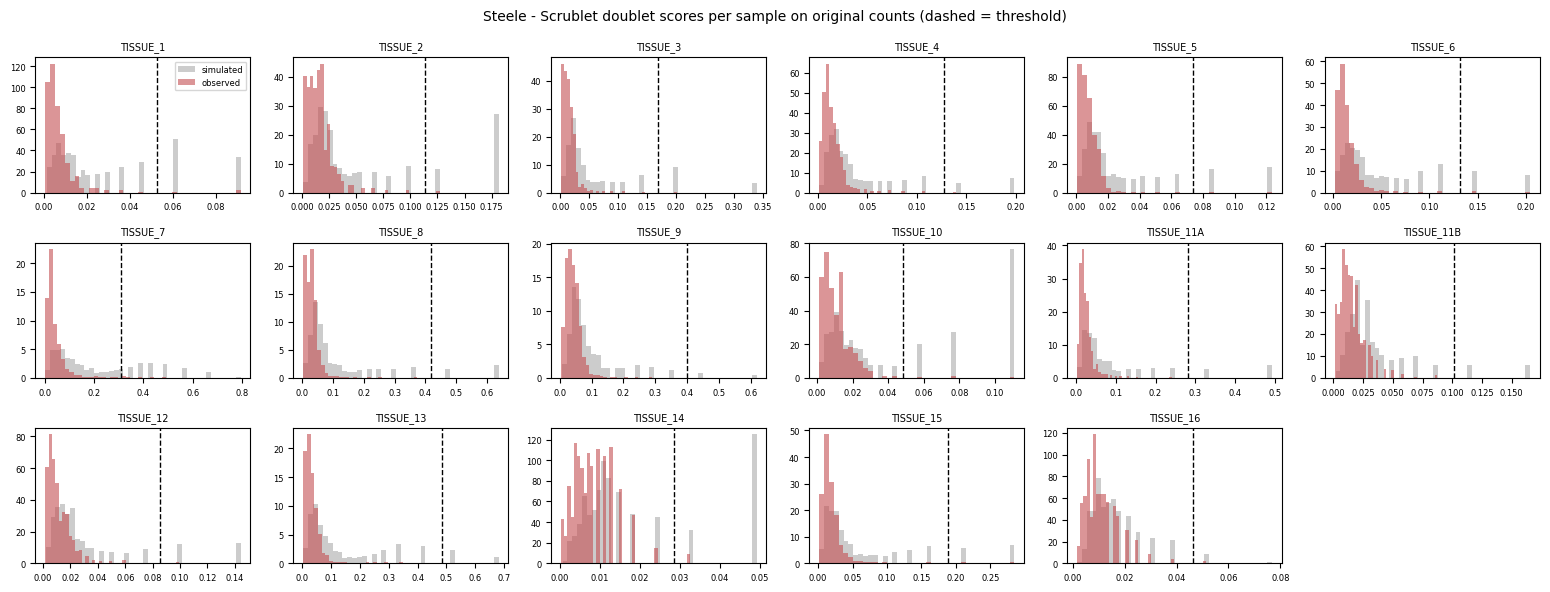


  Steele: expected 2.9% | observed 0.4% | bimodal in 17/17 samples

SCRUBLET ON ORIGINAL COUNTS -- Werba

  sample         cells  expected  observed  threshold  rule
  P04            2,750     2.2%      0.0%      0.268  bimodal minimum
  P05           15,804    12.6%      0.0%      0.797  bimodal minimum
  P07            4,816     3.9%      0.0%      0.467  bimodal minimum
  P15            8,021     6.4%      0.0%      0.662  bimodal minimum
  P19           16,529    13.2%      0.0%      0.810  bimodal minimum
  P23            9,445     7.6%      0.0%      0.650  bimodal minimum
  P09            1,741     1.4%      0.0%      0.110  bimodal minimum
  P13            2,580     2.1%      0.3%      0.178  bimodal minimum
  P20           12,008     9.6%      0.0%      0.785  bimodal minimum
  P22            6,103     4.9%      0.0%      0.531  bimodal minimum
  P26           14,911    11.9%     14.3%      0.317  bimodal minimum


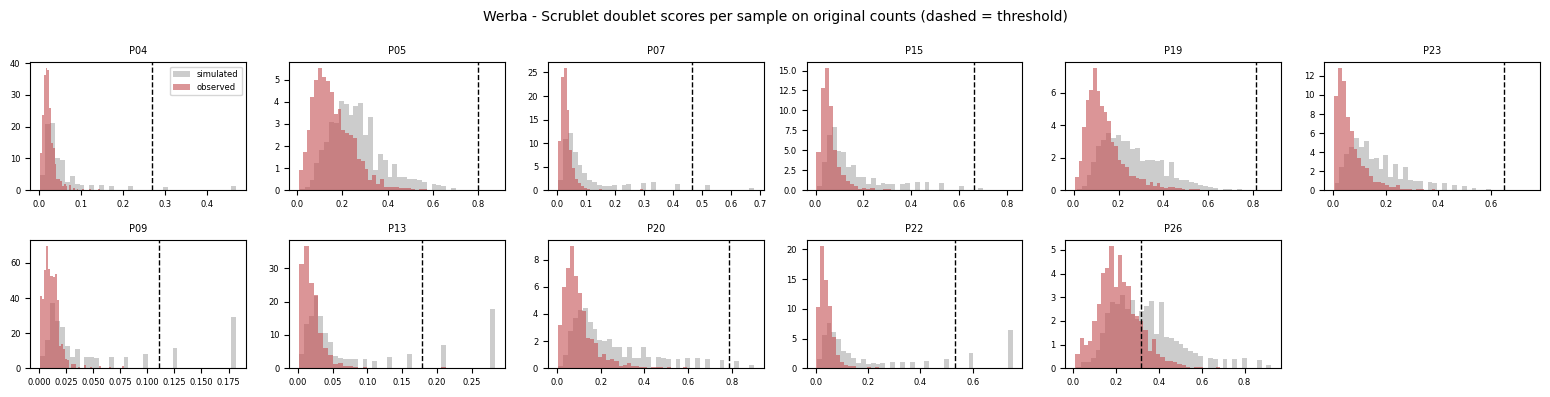


  Werba: expected 9.5% | observed 2.3% | bimodal in 11/11 samples
RAM in use: 0.7 GB


In [36]:
# ==========================================================================
# 22b · SCRUBLET PER SAMPLE ON ORIGINAL COUNTS   ·   Supplementary Fig. S2
# Expected rate = 0.8% per 1,000 cells recovered in that sample. Threshold = minimum
# between the two modes of the SIMULATED-doublet score histogram (Scrublet's own rule,
# implemented here so no scikit-image is needed); if that histogram is not bimodal the top
# expected-rate fraction of observed scores is flagged and the rule is recorded.
# Cached per cohort in OUT_DIR/doublets_<cohort>.csv.
#
# WHY: one model per 10x lane because doublet rate scales with cells loaded per lane; expected rate
# from 10x guidance (0.8% per 1,000 cells); threshold at the minimum between the two modes of the
# simulated-doublet scores, Scrublet's recommended rule (fallback: top expected-rate fraction).
# ==========================================================================

if not RAW_SC_OK:
    print("§22b skipped -- needs peng_processed.h5ad and steele_qc_lognorm.h5ad (see §21)")
else:
    try:
        _scrub = sc.pp.scrublet
    except AttributeError:
        _scrub = sc.external.pp.scrublet


    def minimum_threshold(x, nbins=256, max_iter=10000):
        """Threshold at the minimum between exactly two histogram peaks, found by repeated
        3-point smoothing (the rule behind skimage.filters.threshold_minimum, which Scrublet
        uses). Returns None when the histogram never resolves into two peaks."""
        hist, edges = np.histogram(np.asarray(x, float), bins=nbins)
        h = hist.astype(float)
        centers = (edges[:-1] + edges[1:]) / 2
        for _ in range(max_iter):
            h = np.convolve(np.pad(h, 1, mode="edge"), np.ones(3) / 3, mode="valid")
            peaks = [i for i in range(1, len(h) - 1) if h[i - 1] < h[i] and h[i + 1] < h[i]]
            if len(peaks) == 2:
                a, b = peaks
                return float(centers[a + int(np.argmin(h[a:b + 1]))])
            if len(peaks) < 2:
                return None
        return None


    def scrublet_cohort(label, path, obs_all, reader):
        cache = out_path("doublets_{}.csv".format(label.lower()))
        if not need_compute(cache):
            print("{}: using cached {}".format(label, os.path.basename(cache)))
            return pd.read_csv(cache, index_col=0), pd.read_csv(cache.replace(".csv", "_samples.csv"))
        # one Scrublet model per 10x lane: doublets form within a lane. The rebuilt Steele file
        # records the lane (TISSUE_11 = lanes 11A + 11B); otherwise each patient is one lane.
        _grp = "lane" if "lane" in obs_all.columns else "Patient"
        pats = obs_all[_grp].astype(str).values
        rows_out, samples, sims = [], [], {}
        print("\nSCRUBLET ON ORIGINAL COUNTS -- {}\n".format(label))
        print("  {:<12}{:>8}{:>10}{:>10}{:>11}  rule".format("sample", "cells", "expected", "observed", "threshold"))
        for p in pd.unique(pats):
            rows = np.flatnonzero(pats == p)
            if len(rows) < SCRUBLET_MIN_CELLS:
                print("  {:<12}{:>8,}  too few cells -- not scored".format(p, len(rows)))
                continue
            C, genes = reader(rows)
            rate = DOUBLET_RATE_PER_1K * len(rows) / 1000.0
            sub = anndata.AnnData(X=C.astype(np.float32), var=pd.DataFrame(index=pd.Index(genes)))
            sub.var_names_make_unique()
            _scrub(sub, expected_doublet_rate=rate, random_state=SEED, verbose=False, threshold=1.0)
            obs_s = sub.obs["doublet_score"].values
            sim_s = np.asarray(sub.uns["scrublet"]["doublet_scores_sim"])
            thr, rule = minimum_threshold(sim_s), "bimodal minimum"
            # a minimum that would call more than 3x the expected rate (+5 points) is a spurious
            # dip in the histogram, not the singlet/doublet boundary -> fall back, and say so
            if thr is not None and np.mean(obs_s > thr) > 3 * rate + 0.05:
                thr, rule = None, "minimum rejected (implausible rate); top expected fraction"
            if thr is None:
                thr = float(np.quantile(obs_s, 1 - rate))
                rule = rule if rule.startswith("minimum rejected") else "top expected fraction"
            called = obs_s > thr
            top10 = obs_s >= np.quantile(obs_s, 1 - TOP_SCORE_EXCLUDE)
            rows_out.append(pd.DataFrame({"Patient": p, "doublet_score": obs_s, "doublet_call": called,
                                          "top_score": top10}, index=obs_all.index[np.sort(rows)]))
            samples.append(dict(sample=p, cells=len(rows), expected_rate=rate,
                                observed_rate=float(called.mean()), threshold=thr, rule=rule))
            sims[p] = (obs_s, sim_s, thr)
            print("  {:<12}{:>8,}{:>9.1%}{:>10.1%}{:>11.3f}  {}".format(
                p, len(rows), rate, called.mean(), thr, rule))
            free(sub, C)
        tab = pd.concat(rows_out)
        samp = pd.DataFrame(samples)
        tab.to_csv(cache)
        samp.to_csv(cache.replace(".csv", "_samples.csv"), index=False)
        # ---- Supplementary Fig. S2: per-sample score distributions -----------------
        if FIGURES and sims:
            n = len(sims); ncol = 6; nrow = int(np.ceil(n / ncol))
            fig, axes = plt.subplots(nrow, ncol, figsize=(2.6 * ncol, 2.0 * nrow), squeeze=False)
            for ax, (p, (o, s, t)) in zip(axes.ravel(), sims.items()):
                ax.hist(s, bins=40, color="0.8", density=True, label="simulated")
                ax.hist(o, bins=40, color="#C44E52", alpha=0.6, density=True, label="observed")
                ax.axvline(t, color="k", lw=1, ls="--")
                ax.set_title(p, fontsize=7); ax.tick_params(labelsize=6)
            for ax in axes.ravel()[n:]:
                ax.axis("off")
            axes[0, 0].legend(fontsize=6)
            fig.suptitle("{} - Scrublet doublet scores per sample on original counts "
                         "(dashed = threshold)".format(label), fontsize=10)
            plt.tight_layout()
            _show("FigS2_{}_doublet_scores".format(label.lower()))
        return tab, samp


    DOUBLETS, DOUBLET_SAMPLES = {}, {}
    for _lab, _path, _obs in [("Peng", PENG_PROC, peng_obs_all), ("Steele", STEELE_QC, steele_obs_all), ("Werba", WERBA_QC, werba_obs_all)]:
        _reader = COUNT_SRC[_lab][0]
        if _reader is None:
            print("\n{}: no exact original counts -> Scrublet NOT re-run (see §22a).".format(_lab))
            continue
        DOUBLETS[_lab], DOUBLET_SAMPLES[_lab] = scrublet_cohort(_lab, _path, _obs, _reader)
        _s = DOUBLET_SAMPLES[_lab]
        print("\n  {}: expected {:.1%} | observed {:.1%} | bimodal in {}/{} samples".format(
            _lab, np.average(_s["expected_rate"], weights=_s["cells"]),
            np.average(_s["observed_rate"], weights=_s["cells"]),
            int((_s["rule"] == "bimodal minimum").sum()), len(_s)))
    RESULTS["doublet_samples"] = {k: v.to_dict(orient="records") for k, v in DOUBLET_SAMPLES.items()}
    print(mem())

In [37]:
# ==========================================================================
# 22c · HETEROTYPIC DOUBLETS + SENSITIVITY ANALYSIS   ·   Supplementary Table S4c
# Flags malignant-compartment cells co-expressing an epithelial marker with >= 2 stromal
# markers (epithelial-stromal) or with PTPRC (epithelial-immune). Then recomputes the
# partial Spearman for every signature (a) without flagged cells (heterotypic OR Scrublet
# call) and (b) without the top 10% doublet scores per sample.
#
# WHY: marker co-expression catches epithelial-stromal and epithelial-immune doublets directly and needs no counts, so
# it covers Peng too. Every signature is re-tested without flagged cells (and, for Steele, without
# the top 10% of doublet scores) so no conclusion depends on where a threshold sits.
# ==========================================================================

if not RAW_SC_OK:
    print("§22c skipped -- needs peng_processed.h5ad and steele_qc_lognorm.h5ad (see §21)")
else:
    def _raw_cols(ad, genes):
        names = pd.Index(ad.raw.var_names)
        out = {}
        for g in genes:
            if g in names:
                v = ad.raw.X[:, names.get_loc(g)]
                out[g] = np.asarray(v.todense()).ravel() if sparse.issparse(v) else np.asarray(v).ravel()
            else:
                out[g] = np.zeros(ad.n_obs)
        return out


    def hetero_flags(ad):
        c = _raw_cols(ad, HET_EPI + HET_STROMA + HET_IMMUNE)
        epi = np.max([c[g] for g in HET_EPI], axis=0) > HET_THR
        stro = (np.vstack([c[g] for g in HET_STROMA]) > HET_THR).sum(axis=0) >= 2
        imm = np.max([c[g] for g in HET_IMMUNE], axis=0) > HET_THR
        return epi & stro, epi & imm


    SIG_COLS = [t + "_sig" for t in TARGETS] + ["CE_sig"]
    RESULTS["doublet_sensitivity"] = {}
    for _lab, _ad in [("Peng", mal), ("Steele", steele), ("Werba", werba)]:
        es, ei = hetero_flags(_ad)
        _ad.obs["het_epi_stroma"], _ad.obs["het_epi_immune"] = es, ei
        flag = es | ei
        if _lab in DOUBLETS:
            d = DOUBLETS[_lab].reindex(_ad.obs_names)
            _ad.obs["doublet_score_raw"] = d["doublet_score"].values
            _ad.obs["doublet_call"] = d["doublet_call"].fillna(False).astype(bool).values
            _ad.obs["top_score"] = d["top_score"].fillna(False).astype(bool).values
            flag = flag | _ad.obs["doublet_call"].values
        _ad.obs["doublet_flag"] = flag
        print("\n{} malignant compartment ({:,} cells)".format(_lab, _ad.n_obs))
        print("  epithelial-stromal co-expression : {:,} ({:.2%})".format(int(es.sum()), es.mean()))
        print("  epithelial-immune co-expression  : {:,} ({:.2%})".format(int(ei.sum()), ei.mean()))
        if _lab in DOUBLETS:
            print("  Scrublet call (original counts)  : {:,} ({:.2%})".format(
                int(_ad.obs["doublet_call"].sum()), _ad.obs["doublet_call"].mean()))
        print("  any flag                         : {:,} ({:.2%})\n".format(int(flag.sum()), flag.mean()))
        rows = []
        for col in SIG_COLS:
            base = ps_vs(_ad.obs, col)
            kept = ps_vs(_ad.obs[~_ad.obs["doublet_flag"].values], col)
            rows += [stat_row("{} | all cells".format(col), base),
                     stat_row("{} | flagged cells removed".format(col), kept)]
            RESULTS["doublet_sensitivity"]["{}|{}|flag_removed".format(_lab, col)] = mean_rho(kept)
            if "top_score" in _ad.obs:
                top = ps_vs(_ad.obs[~_ad.obs["top_score"].values], col)
                rows.append(stat_row("{} | top-10% scores removed".format(col), top))
                RESULTS["doublet_sensitivity"]["{}|{}|top10_removed".format(_lab, col)] = mean_rho(top)
        show_rows(rows)


Peng malignant compartment (11,280 cells)
  epithelial-stromal co-expression : 1,269 (11.25%)
  epithelial-immune co-expression  : 24 (0.21%)
  any flag                         : 1,289 (11.43%)

                                             n     neg      mean    95% CI (patients)         p      SD    emp p
  VPS4A_sig | all cells                     24   15/24   -0.0365   [-0.0933, +0.0229]    0.1515                 
  VPS4A_sig | flagged cells removed         23   13/23   -0.0303   [-0.0873, +0.0320]    0.2595                 
  PRMT5_sig | all cells                     24    9/24   +0.0325   [-0.0145, +0.0772]    0.0691                 
  PRMT5_sig | flagged cells removed         23    8/23   +0.0345   [-0.0167, +0.0826]    0.0698                 
  MAT2A_sig | all cells                     24    2/24   +0.3094   [+0.2397, +0.3762]    0.0000                 
  MAT2A_sig | flagged cells removed         23    2/23   +0.3089   [+0.2407, +0.3768]    0.0000                 
  CE_sig | al

## 23 · Per-patient copy number and high-confidence malignant cells  ·  Fig. 1g, Supplementary Fig. S1

*Methods → Transcriptional programs and copy-number inference; Supplementary Methods → Copy-number references and high-confidence malignant cells.* Section 10 inferred copy number once per cohort on a subsample, against pooled immune and stromal cells. Here it is inferred **per patient**, on **every** QC-passed malignant-compartment cell, against that patient's **own** immune and stromal cells **plus normal epithelial cells** (the patient's own where at least 30 exist, otherwise a pooled sample of the cohort's normal epithelium):

- **Peng et al.**: normal epithelium = non-malignant cells whose TISCH lineage label is ductal, acinar, endocrine or epithelial (the column and labels used are printed);
- **Steele et al. and Werba et al.**: no normal ductal annotation exists, so normal epithelium = cells labelled acinar by the compartment marker sets. This reference is weaker, as the Supplementary Methods state.

The per-cell CNV score is the mean absolute inferred copy number over all windows (section 10 used infercnvpy's cluster-level score; a per-cell value is needed to call individual cells). A cell is **CNV-positive** above its own patient's reference 95th percentile. A **high-confidence malignant cell** is CNV-positive, not doublet-flagged (section 22) and not from a control pancreas. The same runs also produce the focal 9p21 and 18q values used in section 24, from a narrower window with no noise thresholding, so that a focal deletion is not averaged away.

Outputs: the per-patient copy-number heatmap of each cohort, a cell-level chromosome heatmap, the CNV-positive fraction per patient (Fig. 1g), the *MAT2A* signature score in CNV-positive and CNV-negative cells (Supplementary Fig. S1d), and every signature re-tested on high-confidence cells in all three cohorts.

**Why these choices**

| choice | why |
|---|---|
| A reference per patient | Baseline expression differs between patients; a pooled reference can make patient-specific expression look like copy-number change. |
| Normal epithelium in the reference | Epithelial expression programs that immune and stromal cells lack could otherwise mimic copy-number change in malignant epithelium. |
| Caps of 1,000 immune, 1,000 stromal and 500 normal epithelial cells | Bounded memory and runtime, and no single reference category dominates. |
| At least 20 malignant and 100 reference cells per patient | Fewer reference cells would make the 95th-percentile threshold unstable. |
| Per-cell CNV score = mean absolute inferred copy number | A per-cell value is needed to call individual cells. |
| 30-cell floor for the high-confidence tests | Removing CNV-negative and flagged cells shrinks every patient; 30 keeps most patients while the per-patient standard error stays about 0.19. |

In [38]:
# ==========================================================================
# 23a · CELL ROLES FOR THE PER-PATIENT REFERENCE
# Peng: TISCH labels (malignant from the QC-passed object; immune / stromal from MAL_COL;
# normal epithelium from the lineage column). Steele: the section 10 marker vocabulary,
# computed once on the full object and cached (needs ~6 GB once; afterwards read from CSV).
#
# WHY: the per-patient reference needs explicit roles. Peng roles come from the TISCH lineage labels
# (made independently of this notebook); Steele has none, so roles come from marker scoring, with
# acinar-marker cells standing in for normal epithelium (a weaker reference, stated in the methods).
# ==========================================================================

if not RAW_SC_OK:
    print("§23a skipped -- needs peng_processed.h5ad and steele_qc_lognorm.h5ad (see §21)")
else:
    def peng_roles():
        obs = peng_obs_all
        roles = np.full(len(obs), "other", dtype=object)
        roles[(obs[MAL_COL] == "Immune cells").values] = "immune"
        roles[(obs[MAL_COL] == "Stromal cells").values] = "stromal"
        lin_cols = [c for c in obs.columns if "lineage" in str(c).lower() and c != MAL_COL]
        epi = np.zeros(len(obs), bool)
        if lin_cols:
            lc = lin_cols[0]
            lab = obs[lc].astype(str).str.lower()
            epi = lab.apply(lambda s: any(k in s for k in NORMAL_EPI_KEYS)).values & \
                  (obs[MAL_COL] != "Malignant cells").values
            print("Peng lineage column used: '{}'".format(lc))
            print("non-malignant lineage labels counted as normal epithelium:")
            print(obs.loc[epi, lc].astype(str).value_counts().to_string())
        else:
            print("Peng: no lineage column -- normal-epithelial reference unavailable")
        roles[epi] = "normal_epithelial"
        roles[obs.index.isin(mal.obs_names)] = "malignant"       # QC-passed malignant cells
        return roles


    def steele_roles():
        cache = out_path("steele_cell_roles.csv")
        if not need_compute(cache):
            r = pd.read_csv(cache, index_col=0)["role"].reindex(steele_obs_all.index)
            return r.fillna("other").values.astype(object)
        sst = sc.read_h5ad(STEELE_QC)
        if sst.raw is not None and sst.raw.n_vars >= sst.n_vars:
            sst = sst.raw.to_adata()
        sets = {"immune": COMPARTMENT_MARKERS["Tcell"] + COMPARTMENT_MARKERS["myeloid"]
                          + COMPARTMENT_MARKERS["Bcell"],
                "stromal": COMPARTMENT_MARKERS["fibroblast"] + COMPARTMENT_MARKERS["endothelial"],
                "normal_epithelial": COMPARTMENT_MARKERS["acinar"]}
        sco = {}
        for name, genes in sets.items():
            sc.tl.score_genes(sst, [g for g in genes if g in sst.var_names], score_name="_s", use_raw=False)
            sco[name] = sst.obs["_s"].values.astype(float)
        lab = pd.DataFrame(sco, index=sst.obs_names).idxmax(axis=1)
        lab[sst.obs_names.isin(steele.obs_names)] = "malignant"
        lab[(~sst.obs_names.isin(steele.obs_names)) & lab.eq("malignant")] = "other"
        pd.DataFrame({"role": lab}).to_csv(cache)
        free(sst)
        return lab.reindex(steele_obs_all.index).fillna("other").values.astype(object)


    def werba_roles():
        """Werba: the same marker vocabulary and the same code as steele_roles(), on every QC'd cell
        of section 8 (werba_qc_lognorm.h5ad stores the full log-normalised matrix in X)."""
        cache = out_path("werba_cell_roles.csv")
        if not need_compute(cache):
            r = pd.read_csv(cache, index_col=0)["role"].reindex(werba_obs_all.index)
            return r.fillna("other").values.astype(object)
        wq = sc.read_h5ad(WERBA_QC)
        sets = {"immune": COMPARTMENT_MARKERS["Tcell"] + COMPARTMENT_MARKERS["myeloid"]
                          + COMPARTMENT_MARKERS["Bcell"],
                "stromal": COMPARTMENT_MARKERS["fibroblast"] + COMPARTMENT_MARKERS["endothelial"],
                "normal_epithelial": COMPARTMENT_MARKERS["acinar"]}
        sco = {}
        for name, genes in sets.items():
            sc.tl.score_genes(wq, [g for g in genes if g in wq.var_names], score_name="_s", use_raw=False)
            sco[name] = wq.obs["_s"].values.astype(float)
        lab = pd.DataFrame(sco, index=wq.obs_names).idxmax(axis=1)
        lab[wq.obs_names.isin(werba.obs_names)] = "malignant"
        lab[(~wq.obs_names.isin(werba.obs_names)) & lab.eq("malignant")] = "other"
        pd.DataFrame({"role": lab}).to_csv(cache)
        del wq
        gc.collect()
        return lab.reindex(werba_obs_all.index).fillna("other").values.astype(object)


    ROLES = {"Peng": peng_roles(), "Steele": steele_roles(), "Werba": werba_roles()}
    for _lab, _r in ROLES.items():
        print("\n{} roles:".format(_lab))
        print(pd.Series(_r).value_counts().to_string())
    print(mem())

Peng lineage column used: 'Celltype (major-lineage)'
non-malignant lineage labels counted as normal epithelium:
Celltype (major-lineage)
Ductal       10205
Acinar        2018
Endocrine      620

Peng roles:
stromal              16280
normal_epithelial    12843
immune               11654
malignant            11280
other                 5386

Steele roles:
immune               22106
malignant             9954
stromal               5727
normal_epithelial     3632

Werba roles:
immune               38749
malignant            37956
stromal              11251
normal_epithelial     6752
RAM in use: 1.9 GB



PER-PATIENT inferCNV -- Peng

  Healthy1     6 malignant cells
  Healthy11    3 malignant cells
  Healthy3     2 malignant cells
  Healthy7     1 malignant cells
  Healthy9     4 malignant cells


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  T1           ok (430 malignant, 618 reference, epithelium own)


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

... (8 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

  T13          ok (247 malignant, 1451 reference, epithelium own)


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

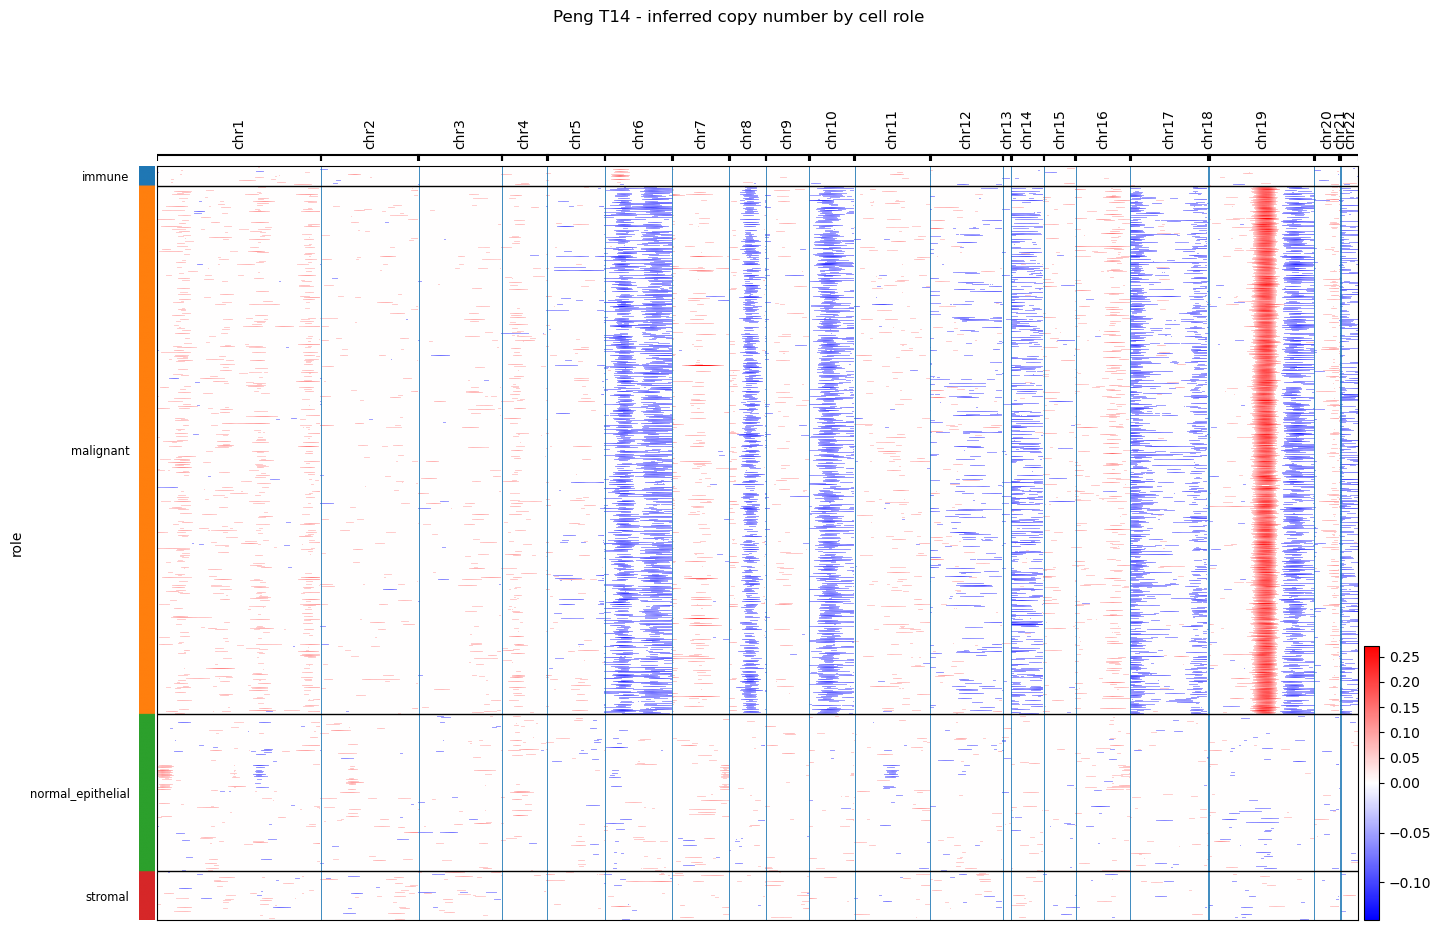

  T14          ok (1679 malignant, 717 reference, epithelium pooled)


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  T15          ok (119 malignant, 1442 reference, epithelium own)


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

... (59 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

  TISSUE_12    ok (26 malignant, 1278 reference, epithelium own)


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

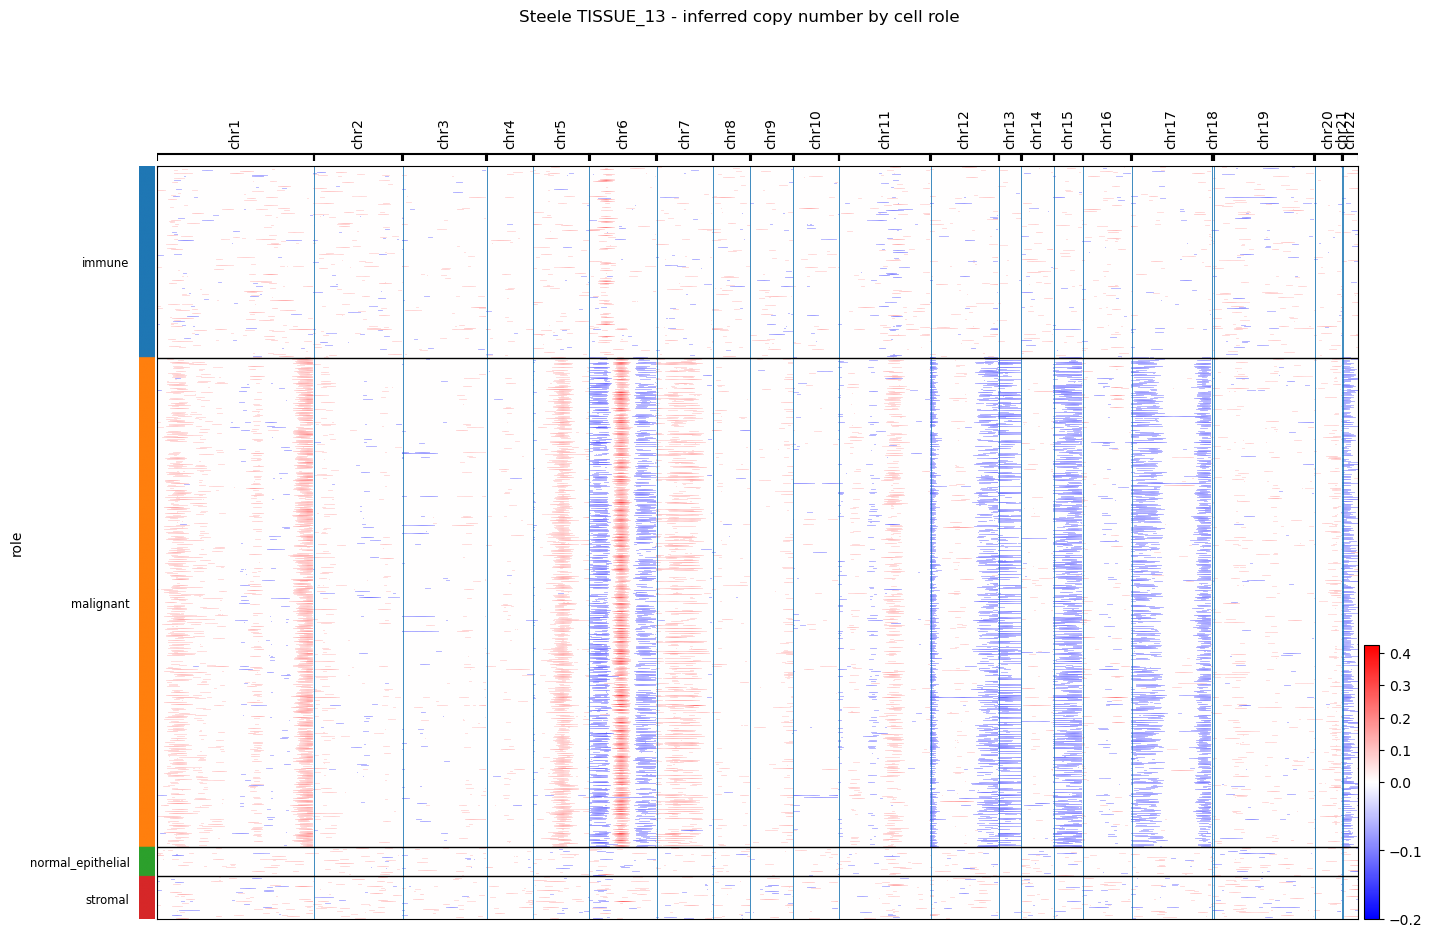

  TISSUE_13    ok (2548 malignant, 1376 reference, epithelium own)


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  TISSUE_14    ok (26 malignant, 634 reference, epithelium own)


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

... (29 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

  P04          ok (643 malignant, 2039 reference, epithelium own)


  0%|          | 0/3 [00:00<?, ?it/s]

  0%|          | 0/3 [00:00<?, ?it/s]

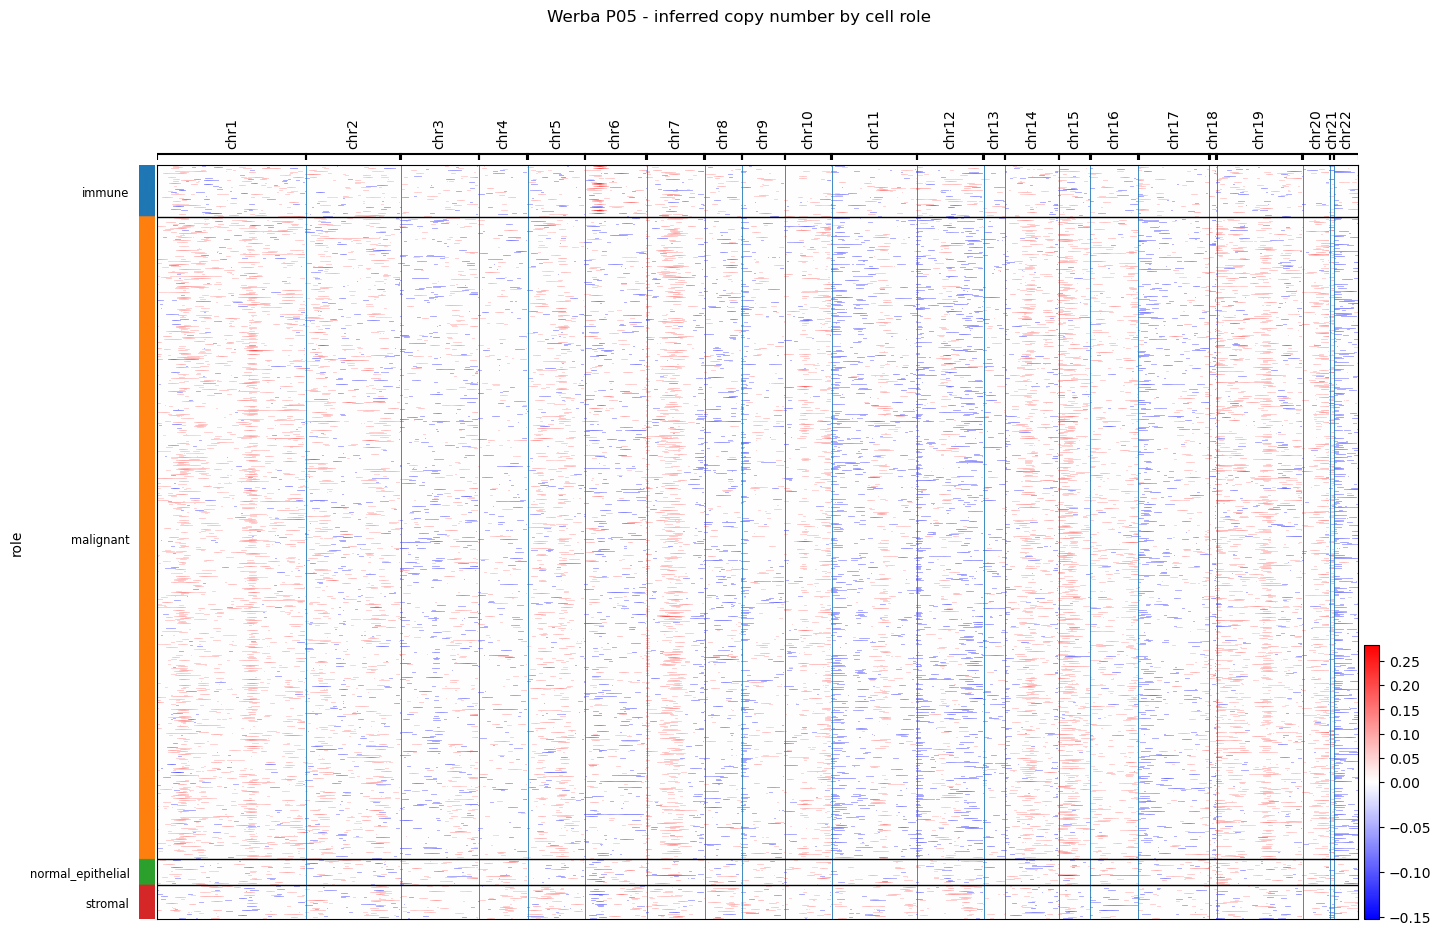

  P05          ok (12538 malignant, 2170 reference, epithelium own)


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  P07          ok (2187 malignant, 2122 reference, epithelium own)


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

... (18 outputs left out)

  P23          ok (4041 malignant, 2211 reference, epithelium own)


  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

  P26          ok (4341 malignant, 2390 reference, epithelium own)
RAM in use: 0.5 GB


In [39]:
# ==========================================================================
# 23b · PER-PATIENT inferCNV (two windows) -- cached per cohort
# Window CNV_WINDOW (as section 10) -> per-cell CNV score and the CNV-positive call.
# Window FOCAL_WINDOW, dynamic_threshold=None -> 9p21 / 18q values for §24. Each run reads
# only that patient's rows. Per-cell results: OUT_DIR/cnv_percell_<cohort>.csv; mean
# malignant profiles: OUT_DIR/cnv_profiles_<cohort>.npz.
#
# WHY per patient: baseline expression differs between patients, and a pooled reference can make it
# look like copy-number change. Normal epithelium joins immune + stromal cells so epithelial
# expression programs cannot mimic CNV. Two windows: 250 genes for the arm-level CNV-positive call,
# 51 genes so focal 9p21/18q deletions are not averaged away (§24).
# ==========================================================================

if not RAW_SC_OK:
    print("§23b skipped -- needs peng_processed.h5ad and steele_qc_lognorm.h5ad (see §21)")
else:
    import infercnvpy as cnv


    def _infercnv(ad, key, window, dyn=1.5):
        kw = dict(reference_key="role", reference_cat=ad.uns["_ref_cats"], window_size=window,
                  step=CNV_STEP, key_added=key, dynamic_threshold=dyn)
        try:
            cnv.tl.infercnv(ad, n_jobs=1, **kw)
        except TypeError:                     # older infercnvpy without n_jobs
            cnv.tl.infercnv(ad, **kw)


    def region_values(ad, key, genes_in_region, window):
        """Per-cell mean inferred copy number over the windows that cover a set of genes.
        Reproduces infercnvpy's bookkeeping: within a chromosome genes are sorted by start and
        window k covers sorted genes [k*step, k*step + window). Checked against infercnvpy's own
        calculate_gene_values output on synthetic data before release."""
        X = ad.obsm["X_" + key]
        chr_pos = ad.uns[key]["chr_pos"]
        var = ad.var
        cols = set()
        present = [g for g in genes_in_region if g in var.index]
        for chrom in sorted(set(var.loc[present, "chromosome"])):
            if chrom not in chr_pos:
                continue
            genes = var.loc[var["chromosome"] == chrom].sort_values("start").index.values
            n = len(genes)
            pos = {g: i for i, g in enumerate(genes)}
            n_win = 1 if n <= window else len(range(0, n - window + 1, CNV_STEP))
            for g in present:
                if g not in pos:
                    continue
                i = pos[g]
                if n <= window:
                    ks = [0]
                else:
                    ks = range(max(0, int(np.ceil((i - window + 1) / CNV_STEP))),
                               min(n_win - 1, i // CNV_STEP) + 1)
                cols.update(chr_pos[chrom] + k for k in ks)
        cols = sorted(cols)
        if not cols:
            return np.full(ad.n_obs, np.nan)
        sub = X[:, cols]
        sub = sub.toarray() if sparse.issparse(sub) else np.asarray(sub)
        return sub.mean(axis=1)


    def cnv_patient(label, path, obs_all, roles, pat, rng, sig_genes, make_heatmap=False):
        pats = obs_all["Patient"].astype(str).values
        in_p = pats == pat
        mal_r = np.flatnonzero(in_p & (roles == "malignant"))
        imm = np.flatnonzero(in_p & (roles == "immune"))
        stro = np.flatnonzero(in_p & (roles == "stromal"))
        own_epi = np.flatnonzero(in_p & (roles == "normal_epithelial"))
        if len(mal_r) < MIN_MAL_CNV:
            return None, "{} malignant cells".format(len(mal_r))
        if len(imm) + len(stro) < REF_MIN:
            return None, "only {} own reference cells".format(len(imm) + len(stro))

        def take(idx, n):
            return np.sort(rng.choice(idx, size=min(n, len(idx)), replace=False)) if len(idx) else idx
        imm, stro = take(imm, REF_MAX_PER_CAT), take(stro, REF_MAX_PER_CAT)
        if len(own_epi) >= 30:
            epi, epi_src = take(own_epi, NORMAL_EPI_MAX), "own"
        else:
            epi, epi_src = take(np.flatnonzero((roles == "normal_epithelial") & ~in_p), NORMAL_EPI_MAX), "pooled"
        role_by_row = pd.Series(
            ["malignant"] * len(mal_r) + ["immune"] * len(imm) + ["stromal"] * len(stro)
            + ["normal_epithelial"] * len(epi),
            index=np.concatenate([mal_r, imm, stro, epi]))
        role_by_row = role_by_row[~role_by_row.index.duplicated()]
        X, genes, srt = h5_rows_lognorm(path, role_by_row.index.values)
        run = anndata.AnnData(X=X.astype(np.float32),
                              obs=pd.DataFrame({"role": role_by_row.reindex(srt).values},
                                               index=obs_all.index[srt].astype(str)),
                              var=pd.DataFrame(index=pd.Index(genes)))
        run.var_names_make_unique()
        # MAT2A signature score inside this run (comparable across this patient's cells only)
        sc.tl.score_genes(run, [g for g in sig_genes if g in run.var_names],
                          score_name="MAT2A_run", use_raw=False)
        # passenger / tumour-suppressor expression on the linear scale (CP10k)
        cp = {}
        for g in ["MTAP", "VPS4B", "CDKN2A", "SMAD4"]:
            if g in run.var_names:
                v = run[:, g].X
                v = v.toarray().ravel() if sparse.issparse(v) else np.asarray(v).ravel()
                cp[g] = np.expm1(v.astype(float))
            else:
                cp[g] = np.full(run.n_obs, np.nan)
        # genomic positions; autosomes only (infercnvpy drops chrX/chrY by default)
        run.var["chromosome"] = "chr" + run.var_names.map(GP["chromosome"]).astype(str)
        run.var["start"] = run.var_names.map(GP["start"])
        run.var["end"] = run.var_names.map(GP["end"])
        keep = run.var["start"].notna() & run.var["chromosome"].isin(["chr" + str(i) for i in range(1, 23)])
        run = run[:, keep.values].copy()
        run.var["start"] = run.var["start"].astype(int)
        run.var["end"] = run.var["end"].astype(int)
        run.uns["_ref_cats"] = [c for c in ["immune", "stromal", "normal_epithelial"]
                                if (run.obs["role"] == c).sum() > 0]
        _infercnv(run, "cnv", CNV_WINDOW)
        Xc = run.obsm["X_cnv"]
        score = np.asarray(abs(Xc).mean(axis=1)).ravel()
        is_ref = run.obs["role"].isin(run.uns["_ref_cats"]).values
        ref95 = float(np.quantile(score[is_ref], CNV_POS_Q))
        _infercnv(run, "cnvf", FOCAL_WINDOW, dyn=None)
        out = pd.DataFrame({"Patient": pat, "role": run.obs["role"].values, "cnv_score": score,
                            "cnv_pos": score > ref95, "ref95": ref95, "epi_ref": epi_src,
                            "MAT2A_run": run.obs["MAT2A_run"].values}, index=run.obs_names)
        for loc, lg in LOCUS_GENES.items():
            out["focal_" + loc] = region_values(run, "cnvf", lg, FOCAL_WINDOW)
        for g, v in cp.items():
            out[g + "_cp10k"] = v
        is_mal = run.obs["role"].values == "malignant"
        prof = np.asarray(Xc[is_mal].mean(axis=0)).ravel()
        if make_heatmap and FIGURES:
            try:
                cnv.pl.chromosome_heatmap(run, groupby="role", show=False)
                plt.suptitle("{} {} - inferred copy number by cell role".format(label, pat), y=1.02)
                _show("cnv_{}_{}_chromosome_heatmap".format(label.lower(), pat))
            except Exception as err:
                print("  [chromosome heatmap skipped: {}]".format(str(err)[:60]))
        chr_pos = dict(run.uns["cnv"]["chr_pos"])
        free(run, X, Xc)
        return (out, prof, chr_pos), "ok ({} malignant, {} reference, epithelium {})".format(
            int(is_mal.sum()), int(is_ref.sum()), epi_src)


    def cnv_cohort(label, path, obs_all, roles, sig_genes):
        cache = out_path("cnv_percell_{}.csv".format(label.lower()))
        pcache = out_path("cnv_profiles_{}.npz".format(label.lower()))
        if not need_compute(cache) and os.path.exists(pcache):
            print("{}: using cached {}".format(label, os.path.basename(cache)))
            z = np.load(pcache, allow_pickle=True)
            return pd.read_csv(cache, index_col=0), dict(z["profiles"].item()), dict(z["chr_pos"].item())
        pats_all = obs_all["Patient"].astype(str).values
        order = sorted(set(pats_all[roles == "malignant"]))
        n_mal = pd.Series(pats_all[roles == "malignant"]).value_counts()
        example = n_mal.index[0]
        tabs, profiles, chr_pos = [], {}, None
        print("\nPER-PATIENT inferCNV -- {}\n".format(label))
        for i, pat in enumerate(order):
            rng_p = np.random.default_rng([SEED, i])          # own stream per patient
            res_p, msg = cnv_patient(label, path, obs_all, roles, pat, rng_p, sig_genes,
                                     make_heatmap=(pat == example))
            print("  {:<12} {}".format(pat, msg))
            if res_p is None:
                continue
            tab, prof, cp = res_p
            tabs.append(tab); profiles[pat] = prof; chr_pos = cp
        out = pd.concat(tabs)
        out.to_csv(cache)
        np.savez(pcache, profiles=np.array(profiles, dtype=object), chr_pos=np.array(chr_pos, dtype=object))
        print(mem())
        return out, profiles, chr_pos


    CNVT, CNVPROF = {}, {}
    _mat_sig = signatures["MAT2A"]
    CNVT["Peng"], CNVPROF["Peng"], _cp_peng = cnv_cohort("Peng", PENG_PROC, peng_obs_all, ROLES["Peng"], _mat_sig)
    CNVT["Steele"], CNVPROF["Steele"], _cp_steele = cnv_cohort("Steele", STEELE_QC, steele_obs_all, ROLES["Steele"], _mat_sig)
    CNVT["Werba"], CNVPROF["Werba"], _cp_werba = cnv_cohort("Werba", WERBA_QC, werba_obs_all, ROLES["Werba"], _mat_sig)
    CHR_POS = {"Peng": _cp_peng, "Steele": _cp_steele, "Werba": _cp_werba}


Peng: CNV-positive malignant-labelled cells 8,721/11,264 (77.4%) across 24 patients
  per patient: T12 17%, T10 38%, T4 41%, T20 45%, T18 55%, T1 55%, T24 56%, T13 56%, T23 59%, T2 63%, T21 63%, T16 68%, T11 68%, T19 72%, T5 75%, T17 82%, T22 84%, T3 87%, T8 88%, T6 93%, T9 94%, T15 94%, T7 96%, T14 100%


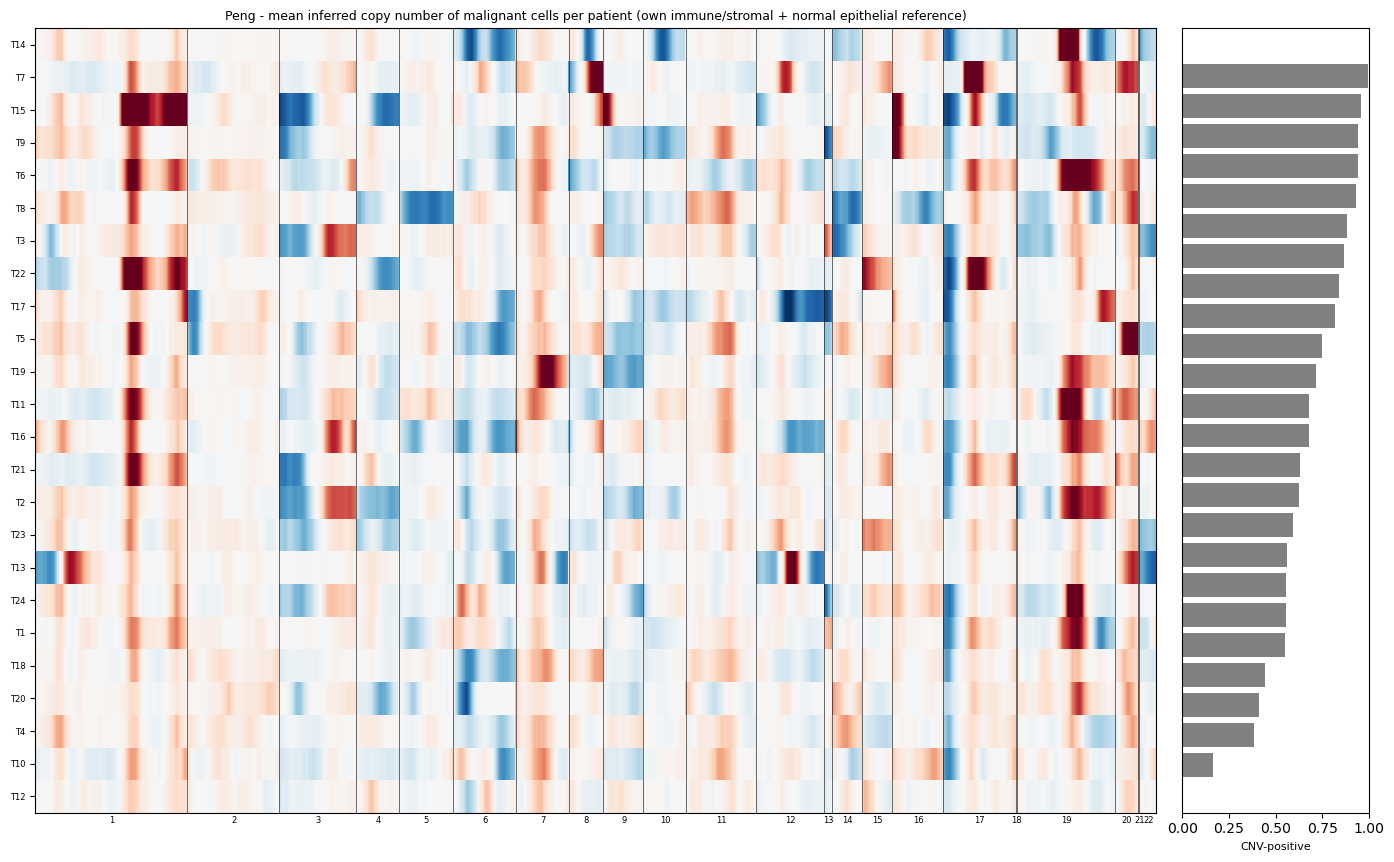


Steele: CNV-positive malignant-labelled cells 6,701/9,954 (67.3%) across 16 patients
  per patient: TISSUE_16 7%, TISSUE_4 19%, TISSUE_11 36%, TISSUE_12 38%, TISSUE_7 44%, TISSUE_5 46%, TISSUE_14 46%, TISSUE_10 68%, TISSUE_15 70%, TISSUE_9 75%, TISSUE_1 84%, TISSUE_8 85%, TISSUE_13 87%, TISSUE_2 89%, TISSUE_6 93%, TISSUE_3 93%


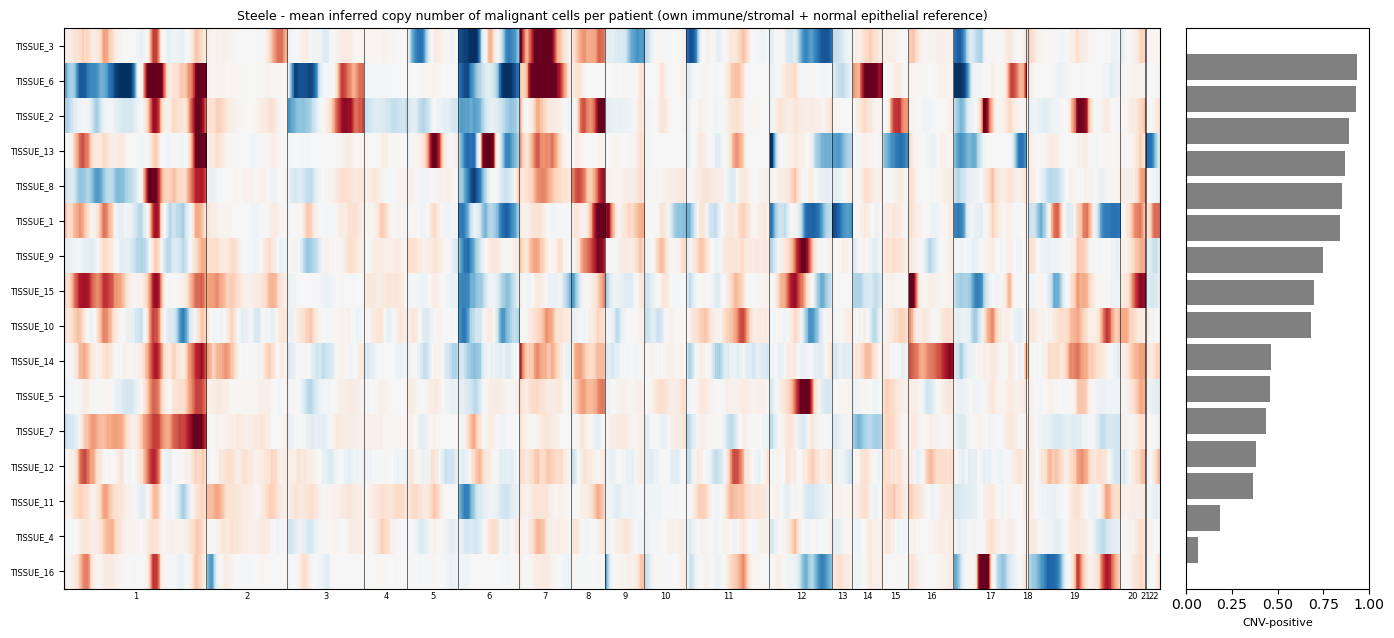


Werba: CNV-positive malignant-labelled cells 12,614/37,956 (33.2%) across 11 patients
  per patient: P15 10%, P05 11%, P26 13%, P19 14%, P04 46%, P20 58%, P13 67%, P23 72%, P09 72%, P07 78%, P22 80%


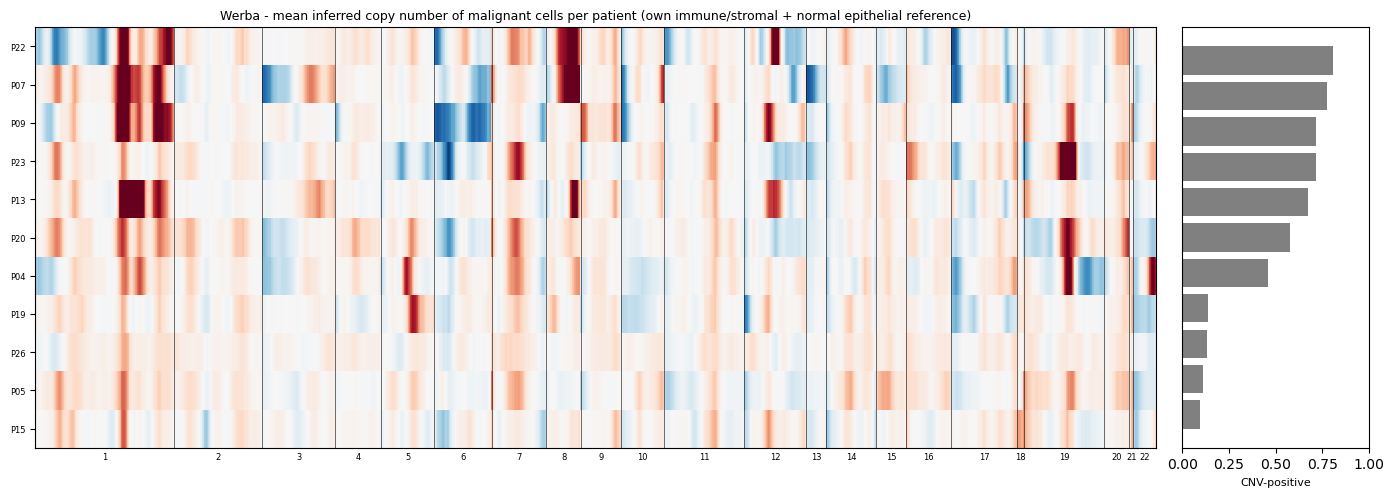


Peng: MAT2A score, CNV+ minus CNV- malignant (patient medians): mean +0.0163, 19/21 patients higher in CNV+, Wilcoxon p = 0.0009

Steele: MAT2A score, CNV+ minus CNV- malignant (patient medians): mean +0.0558, 15/16 patients higher in CNV+, Wilcoxon p = 0.0002

Werba: MAT2A score, CNV+ minus CNV- malignant (patient medians): mean +0.0397, 10/11 patients higher in CNV+, Wilcoxon p = 0.0098


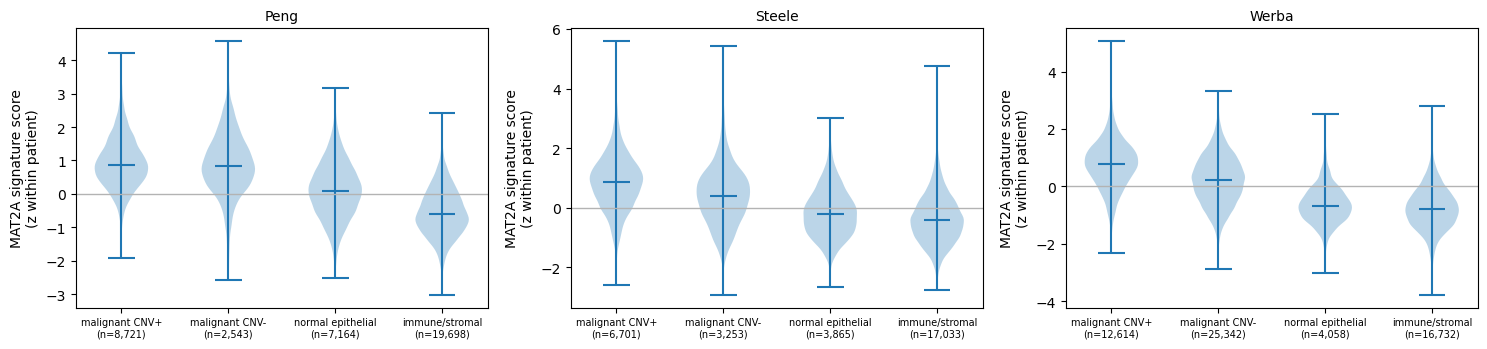

In [40]:
# ==========================================================================
# 23c · PER-PATIENT COPY-NUMBER FIGURES   ·   Supplementary Fig. S1
# (a) per-patient mean malignant copy-number profile, patients x genomic windows
# (b) fraction CNV-positive per patient
# (c) MAT2A signature score (within-patient z) in CNV-positive malignant, CNV-negative
#     malignant, and normal epithelial reference cells
# ==========================================================================

if not RAW_SC_OK:
    print("§23c skipped -- needs peng_processed.h5ad and steele_qc_lognorm.h5ad (see §21)")
else:
    for _lab in ["Peng", "Steele", "Werba"]:
        t = CNVT[_lab]
        m = t[t["role"] == "malignant"]
        frac = m.groupby("Patient")["cnv_pos"].mean().sort_values()
        print("\n{}: CNV-positive malignant-labelled cells {:,}/{:,} ({:.1%}) across {} patients".format(
            _lab, int(m["cnv_pos"].sum()), len(m), m["cnv_pos"].mean(), m["Patient"].nunique()))
        print("  per patient: " + ", ".join("{} {:.0%}".format(p, v) for p, v in frac.items()))
        RESULTS.setdefault("cnv_pos_frac", {})[_lab] = {"overall": float(m["cnv_pos"].mean()),
                                                    "per_patient": frac.round(3).to_dict()}
        if not FIGURES:
            continue
        prof = CNVPROF[_lab]
        pats = list(frac.index[::-1])
        M = np.vstack([prof[p] for p in pats if p in prof])
        vmax = np.quantile(np.abs(M), 0.99)
        fig, axes = plt.subplots(1, 2, figsize=(14, 0.28 * len(pats) + 2.0),
                                 gridspec_kw={"width_ratios": [6, 1]})
        ax = axes[0]
        ax.imshow(M, aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax, interpolation="nearest")
        cp = CHR_POS[_lab]
        starts = sorted(cp.items(), key=lambda kv: kv[1])
        for k, (chrom, s0) in enumerate(starts):
            ax.axvline(s0 - 0.5, color="k", lw=0.4)
            s1 = starts[k + 1][1] if k + 1 < len(starts) else M.shape[1]
            ax.text((s0 + s1) / 2, M.shape[0] - 0.4, chrom.replace("chr", ""), ha="center", va="top", fontsize=6)
        ax.set_yticks(range(len(pats))); ax.set_yticklabels(pats, fontsize=6)
        ax.set_xticks([])
        ax.set_title("{} - mean inferred copy number of malignant cells per patient "
                     "(own immune/stromal + normal epithelial reference)".format(_lab), fontsize=9)
        ax2 = axes[1]
        ax2.barh(range(len(pats)), [frac[p] for p in pats], color="0.5")
        ax2.set_yticks([]); ax2.set_xlim(0, 1); ax2.invert_yaxis()
        ax2.set_xlabel("CNV-positive", fontsize=8)
        plt.tight_layout()
        _show("FigS1_{}_patient_cnv_heatmap".format(_lab.lower()))

    # (c) MAT2A score by CNV status, z-scored within each patient's run
    if FIGURES:
        fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
    for j, _lab in enumerate(["Peng", "Steele", "Werba"]):
        t = CNVT[_lab].copy()
        t["z"] = t.groupby("Patient")["MAT2A_run"].transform(lambda v: (v - v.mean()) / v.std())
        t["group"] = np.where(t["role"] == "normal_epithelial", "normal epithelial",
                      np.where(t["role"] != "malignant", "immune/stromal",
                      np.where(t["cnv_pos"], "malignant CNV+", "malignant CNV-")))
        # within-patient paired comparison of CNV+ vs CNV- malignant medians
        pp = t[t["role"] == "malignant"].groupby(["Patient", "cnv_pos"])["MAT2A_run"].median().unstack()
        pp = pp.dropna()
        cnt = t[t["role"] == "malignant"].groupby(["Patient", "cnv_pos"]).size().unstack().reindex(pp.index)
        pp = pp[(cnt[True] >= 10) & (cnt[False] >= 10)]
        if len(pp) >= 5:
            d = pp[True] - pp[False]
            print("\n{}: MAT2A score, CNV+ minus CNV- malignant (patient medians): mean {:+.4f}, "
                  "{}/{} patients higher in CNV+, Wilcoxon p = {:.4f}".format(
                      _lab, d.mean(), int((d > 0).sum()), len(d), wilcoxon(d)[1]))
            RESULTS.setdefault("mat2a_cnv_pos_minus_neg", {})[_lab] = dict(
                mean=float(d.mean()), n=len(d), n_pos=int((d > 0).sum()), p=float(wilcoxon(d)[1]))
        else:
            print("\n{}: too few patients with >= 10 CNV+ and CNV- cells for the paired test".format(_lab))
        if FIGURES:
            ax = axes[j]
            groups = ["malignant CNV+", "malignant CNV-", "normal epithelial", "immune/stromal"]
            data = [t.loc[t["group"] == gname, "z"].dropna().values for gname in groups]
            ok = [k for k, dd in enumerate(data) if len(dd) > 5]
            ax.violinplot([data[k] for k in ok], positions=range(len(ok)), showmedians=True)
            ax.set_xticks(range(len(ok)))
            ax.set_xticklabels(["{}\n(n={:,})".format(groups[k], len(data[k])) for k in ok], fontsize=7)
            ax.axhline(0, color="0.7", lw=1)
            ax.set_ylabel("MAT2A signature score\n(z within patient)")
            ax.set_title(_lab, fontsize=10)
    if FIGURES:
        plt.tight_layout()
        _show("FigS1d_mat2a_by_cnv_status")

In [41]:
# ==========================================================================
# 23d · HIGH-CONFIDENCE MALIGNANT CELLS -- every signature re-tested, all three cohorts
# high-confidence = CNV-positive in its own patient's run AND not doublet-flagged (§22)
# AND not from a control pancreas. Also reports the cells TISCH labels malignant in the
# Peng control pancreata, and confirms none of those samples is among the analysed patients.
#
# WHY a 30-cell floor: removing CNV-negative and doublet-flagged cells shrinks every patient; 30 keeps
# most patients while the per-patient SE of the correlation stays about 0.19.
# ==========================================================================

if not RAW_SC_OK:
    print("§23d skipped -- needs peng_processed.h5ad and steele_qc_lognorm.h5ad (see §21)")
else:
    for _lab, _ad in [("Peng", mal), ("Steele", steele), ("Werba", werba)]:
        t = CNVT[_lab]
        pos = t.loc[t["role"] == "malignant", "cnv_pos"].reindex(_ad.obs_names)
        _ad.obs["cnv_pos_pp"] = pos.values                    # NaN = patient not run
        healthy = _ad.obs["Patient"].astype(str).str.startswith("Healthy").values
        _ad.obs["hc_malignant"] = (pos.fillna(False).astype(bool).values
                                   & ~_ad.obs["doublet_flag"].values & ~healthy)
        print("\n{}: high-confidence malignant cells {:,}/{:,} ({:.1%})".format(
            _lab, int(_ad.obs["hc_malignant"].sum()), _ad.n_obs, _ad.obs["hc_malignant"].mean()))
        RESULTS.setdefault("hc_cells", {})[_lab] = int(_ad.obs["hc_malignant"].sum())

    # Peng control pancreata: malignant-labelled cells, their CNV status, and the analysed set
    _h = mal.obs[mal.obs["Patient"].astype(str).str.startswith("Healthy")]
    print("\nPeng control pancreata: {:,} cells labelled malignant across {} samples".format(
        len(_h), _h["Patient"].nunique()))
    if len(_h):
        print(_h.groupby("Patient", observed=True).agg(
            cells=("cnv_pos_pp", "size"),
            cnv_positive=("cnv_pos_pp", lambda v: np.nanmean(v.astype(float)) if v.notna().any() else np.nan)
        ).to_string())
    _analysed = sorted(res["MAT2A"].keys())
    _bad = [p for p in _analysed if str(p).startswith("Healthy")]
    print("\nanalysed Peng patients (>= {} cells): {}".format(MIN_CELLS, ", ".join(map(str, _analysed))))
    print("control pancreata among them: {}".format(_bad if _bad else "NONE -- every analysed patient is a tumour"))
    RESULTS["peng_controls_in_analysis"] = _bad

    print("\nSIGNATURES ON HIGH-CONFIDENCE MALIGNANT CELLS (30-cell floor, as in the aneuploidy test)\n")
    RESULTS["hc_rhos"] = {}
    for _lab, _ad, _null in [("Peng", mal, null), ("Steele", steele, s_null), ("Werba", werba, w_null)]:
        sub_obs = _ad.obs[_ad.obs["hc_malignant"].values]
        rows = []
        for col in SIG_COLS:
            r = ps_vs(sub_obs, col, min_cells=30)
            RESULTS["hc_rhos"]["{}|{}".format(_lab, col)] = r
            rows.append(stat_row("{} {} | high-confidence".format(_lab, col), r, _null))
        show_rows(rows)
        print()


Peng: high-confidence malignant cells 7,653/11,280 (67.8%)

Steele: high-confidence malignant cells 6,640/9,954 (66.7%)

Werba: high-confidence malignant cells 11,925/37,956 (31.4%)

Peng control pancreata: 16 cells labelled malignant across 5 samples
           cells  cnv_positive
Patient                       
Healthy1       6           NaN
Healthy3       2           NaN
Healthy7       1           NaN
Healthy9       4           NaN
Healthy11      3           NaN

analysed Peng patients (>= 50 cells): T1, T10, T11, T12, T13, T14, T15, T16, T17, T18, T19, T2, T20, T21, T22, T23, T24, T3, T4, T5, T6, T7, T8, T9
control pancreata among them: NONE -- every analysed patient is a tumour

SIGNATURES ON HIGH-CONFIDENCE MALIGNANT CELLS (30-cell floor, as in the aneuploidy test)

                                             n     neg      mean    95% CI (patients)         p      SD    emp p
  Peng VPS4A_sig | high-confidence          22   15/22   -0.0701   [-0.1431, +0.0022]    0.1055    -1.0 

## 24 · Passenger-gene loss at 9p21 (*MTAP*) and 18q (*VPS4B*)  ·  Supplementary Table S13, Supplementary Fig. S7

*Methods → Inference of passenger-gene loss; Results → Associations in tumours with evidence of loss of passenger genes; Supplementary Methods → Passenger-gene loss.* No matched genomic sequencing or *MTAP* immunohistochemistry is public for these cohorts, so loss is inferred per tumour from **two lines of evidence** in the runs of section 23:

1. **Copy number.** The focal-window inferred copy number averaged over the genes within 2 Mb of the anchor genes (*MTAP* and *CDKN2A* for 9p21; *SMAD4* and *VPS4B* for 18q). A malignant cell has a loss when this value is below the 5th percentile of its own patient's reference; a tumour has copy-number loss when at least 30% of its malignant cells do.
2. **Expression.** A homozygous deletion removes the transcript, so pseudobulk *MTAP* (9p21) or *VPS4B* (18q) expression in the tumour's malignant cells is divided by that in the same tumour's immune and stromal cells.

| call | rule |
|---|---|
| likely homozygous | copy-number loss **and** expression ratio < 0.25 |
| possibly homozygous (expression only) | ratio < 0.25 without copy-number loss; a focal deletion can be narrower than the window |
| likely heterozygous | copy-number loss **and** ratio 0.25–0.75 |
| copy-number loss only | copy-number loss, expression not reduced |
| no evidence | neither |

The first three count as evidence of loss. Each call's uncertainty is the fraction of 1,000 bootstrap resamples of cells (malignant and reference cells resampled separately) that return the same call; the per-tumour calls with their agreement are the rows of Supplementary Table S13c. Expression-based inference is weak evidence for a focal homozygous deletion, and per-cell 9p21 calls are noisy, so tumour-level calls are primary and per-cell restriction is supporting evidence (24b).

**Why these thresholds**

| threshold | value | why |
|---|---|---|
| cell-level loss | below the patient's reference 5th percentile | By construction, 5% of diploid reference cells fall below it, so the per-cell false-positive rate is fixed. |
| tumour-level copy-number loss | ≥ 30% of malignant cells | A clonal or major subclonal deletion, rather than noise in a few cells. |
| near-absent expression | ratio < 0.25 | A homozygous deletion removes the transcript; the residual allows for ambient RNA and contaminating normal cells. |
| reduced expression | ratio 0.25–0.75 | Heterozygous loss roughly halves expression; the band allows for dosage compensation and noise. |
| 2 Mb padding, 51-gene window | | Enough genes around each anchor for a stable focal value without averaging in the whole chromosome arm. |
| 1,000 bootstrap resamples | | Malignant and reference cells are resampled separately, so each call's agreement reflects both sources of noise. |
| Subsets of fewer than three tumours not tested | | A confidence interval across patients needs at least three. |

The expression ratio compares malignant cells with immune and stromal cells, which also differ in baseline expression; that is why copy-number loss without reduced expression is kept as its own category rather than forced into a call.


Peng - 18q (VPS4B):
  call
  no_evidence            12
  cn_loss_only            9
  likely_heterozygous     3

Peng - 9p21 (MTAP):
  call
  no_evidence                      11
  likely_homozygous                 4
  likely_heterozygous               4
  cn_loss_only                      3
  possible_homozygous_expr_only     2

Steele - 18q (VPS4B):
  call
  no_evidence                      11
  likely_heterozygous               2
  cn_loss_only                      2
  possible_homozygous_expr_only     1

Steele - 9p21 (MTAP):
  call
  no_evidence                      8
  possible_homozygous_expr_only    4
  cn_loss_only                     2
  likely_homozygous                2

Werba - 18q (VPS4B):
  call
  no_evidence            5
  cn_loss_only           3
  likely_heterozygous    3

Werba - 9p21 (MTAP):
  call
  no_evidence                      6
  likely_homozygous                2
  cn_loss_only                     1
  possible_homozygous_expr_only    1
  likely_heterozygous  

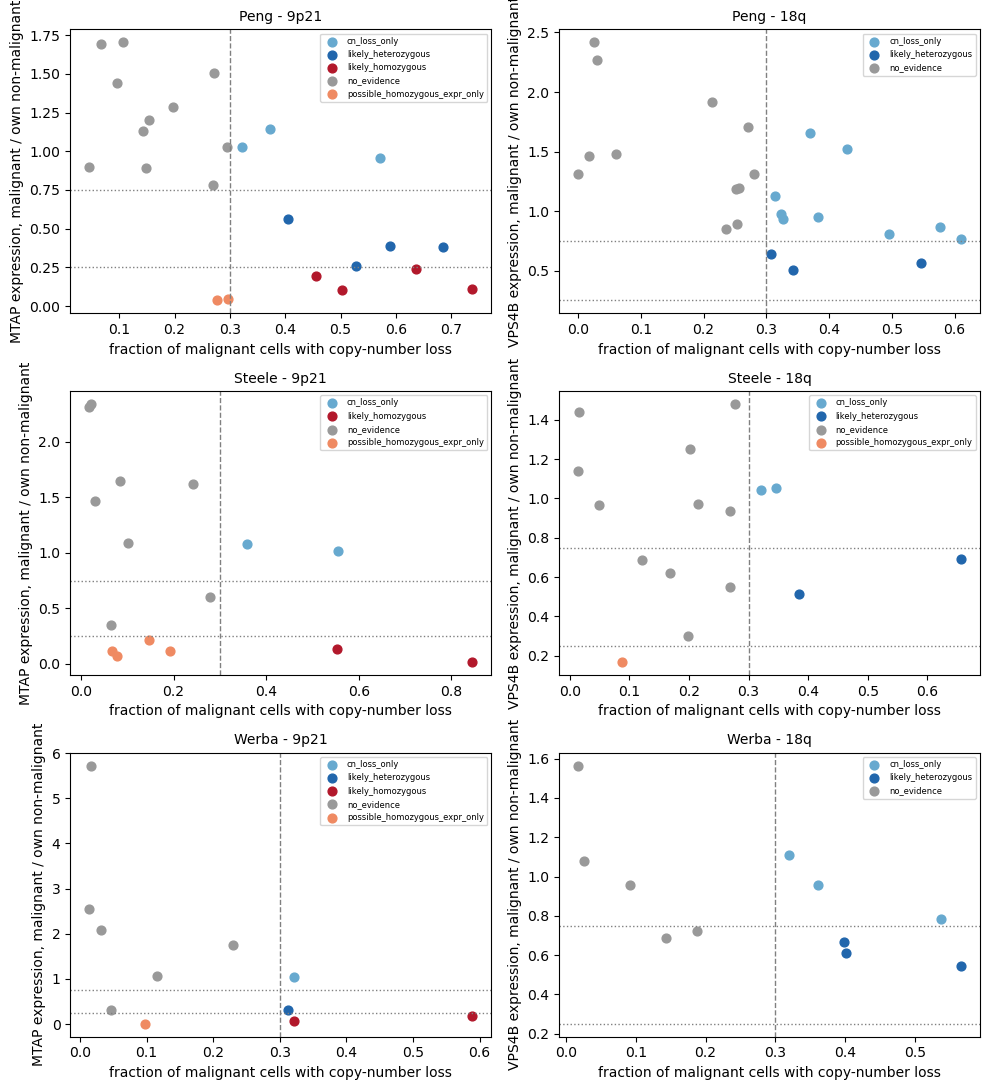

In [42]:
# ==========================================================================
# 24a · PER-TUMOUR LOSS CALLS WITH BOOTSTRAP UNCERTAINTY   ·   Supplementary Table S13, Fig. S7
#
# WHY two lines of evidence: inferred copy number alone is noisy at a focal locus, and expression
# alone is weak evidence for a homozygous deletion, so a call needs both, and
# each call's stability is measured by resampling malignant and reference cells separately.
# ==========================================================================

if not RAW_SC_OK:
    print("§24a skipped -- needs peng_processed.h5ad and steele_qc_lognorm.h5ad (see §21)")
else:
    LOSS_EVIDENCE = {"likely_homozygous", "possible_homozygous_expr_only", "likely_heterozygous"}


    def loss_call(frac_loss, ratio):
        if not np.isfinite(ratio):
            return "no_expression_reference"
        cn = frac_loss >= LOSS_FRAC_MIN
        if ratio < HOM_RATIO_MAX:
            return "likely_homozygous" if cn else "possible_homozygous_expr_only"
        if cn and ratio < HET_RATIO_MAX:
            return "likely_heterozygous"
        return "cn_loss_only" if cn else "no_evidence"


    def tumour_calls(label):
        t = CNVT[label]
        rows, cell_loss = [], {}
        for pat, g in t.groupby("Patient"):
            own_ref = g[g["role"].isin(["immune", "stromal"])]
            m = g[g["role"] == "malignant"]
            if len(own_ref) < 20 or len(m) < MIN_MAL_CNV:
                continue
            # seed from a STABLE hash of the patient name: Python's hash() changes every
            # process (the list(set) bug from section 15), zlib.crc32 does not
            rng_b = np.random.default_rng([SEED, 7, zlib.crc32(str(pat).encode())])
            for loc, passenger in LOCUS_PASSENGER.items():
                fcol, ecol = "focal_" + loc, passenger + "_cp10k"
                thr = np.nanquantile(own_ref[fcol], LOSS_REF_Q)
                loss = (m[fcol] < thr).values
                for cid, v in zip(m.index, loss):
                    cell_loss[(cid, loc)] = bool(v)
                frac = float(loss.mean())
                den = own_ref[ecol].mean()
                ratio = float(m[ecol].mean() / den) if den > 0 else np.nan
                call = loss_call(frac, ratio)
                # bootstrap: resample malignant and reference cells separately
                same = 0
                mf, me, re_ = m[fcol].values, m[ecol].values, own_ref[ecol].values
                rf = own_ref[fcol].values
                for _ in range(N_BOOT_CALL):
                    bm_ = rng_b.integers(0, len(mf), len(mf)); br = rng_b.integers(0, len(rf), len(rf))
                    thr_b = np.nanquantile(rf[br], LOSS_REF_Q)
                    fr_b = float(np.mean(mf[bm_] < thr_b))
                    den_b = np.nanmean(re_[br])
                    ra_b = float(np.nanmean(me[bm_]) / den_b) if den_b > 0 else np.nan
                    same += loss_call(fr_b, ra_b) == call
                epi = g[g["role"] == "normal_epithelial"][ecol].mean()
                rows.append(dict(cohort=label, patient=pat, locus=loc, passenger=passenger,
                                 n_malignant=len(m), frac_cells_loss=round(frac, 3),
                                 expr_ratio_vs_own_nonmalignant=round(ratio, 3) if np.isfinite(ratio) else np.nan,
                                 expr_ratio_vs_normal_epithelium=round(float(m[ecol].mean() / epi), 3)
                                 if epi and epi > 0 else np.nan,
                                 call=call, bootstrap_agreement=round(same / N_BOOT_CALL, 3)))
        return pd.DataFrame(rows), cell_loss


    CALLS, CELL_LOSS = [], {}
    for _lab in ["Peng", "Steele", "Werba"]:
        _c, _cl = tumour_calls(_lab)
        CALLS.append(_c); CELL_LOSS[_lab] = _cl
    CALLS = pd.concat(CALLS, ignore_index=True)
    CALLS.to_csv(out_path("TableS8_passenger_loss_calls.csv"), index=False)
    for (_lab, _loc), _g in CALLS.groupby(["cohort", "locus"]):
        print("\n{} - {} ({}):".format(_lab, _loc, LOCUS_PASSENGER[_loc]))
        print("  " + _g["call"].value_counts().to_string().replace("\n", "\n  "))
    print("\nfull table -> TableS8_passenger_loss_calls.csv")
    RESULTS["passenger_calls"] = CALLS.groupby(["cohort", "locus"])["call"].value_counts().unstack(fill_value=0).to_dict(orient="index")
    RESULTS["passenger_calls"] = {"{}|{}".format(*k): v for k, v in RESULTS["passenger_calls"].items()}

    if FIGURES:
        fig, axes = plt.subplots(3, 2, figsize=(10, 11))
        colors = {"likely_homozygous": "#B2182B", "possible_homozygous_expr_only": "#EF8A62",
                  "likely_heterozygous": "#2166AC", "cn_loss_only": "#67A9CF",
                  "no_evidence": "0.6", "no_expression_reference": "0.85"}
        for i, _lab in enumerate(["Peng", "Steele", "Werba"]):
            for j, _loc in enumerate(LOCI):
                ax = axes[i, j]
                g = CALLS[(CALLS["cohort"] == _lab) & (CALLS["locus"] == _loc)]
                for call, gg in g.groupby("call"):
                    ax.scatter(gg["frac_cells_loss"], gg["expr_ratio_vs_own_nonmalignant"],
                               s=40, color=colors.get(call, "k"), label=call)
                ax.axvline(LOSS_FRAC_MIN, color="0.5", ls="--", lw=1)
                ax.axhline(HOM_RATIO_MAX, color="0.5", ls=":", lw=1)
                ax.axhline(HET_RATIO_MAX, color="0.5", ls=":", lw=1)
                ax.set_xlabel("fraction of malignant cells with copy-number loss")
                ax.set_ylabel("{} expression, malignant / own non-malignant".format(LOCUS_PASSENGER[_loc]))
                ax.set_title("{} - {}".format(_lab, _loc), fontsize=10)
                ax.legend(fontsize=6)
        plt.tight_layout()
        _show("FigS7_passenger_loss_calls")

In [43]:
# ==========================================================================
# 24b · ASSOCIATIONS INSIDE TUMOURS (AND CELLS) WITH EVIDENCE OF THE RELEVANT LOSS   ·   Table S13b
# Each target is tested against its own passenger locus (VPS4A <- 18q; PRMT5, MAT2A <- 9p21):
# (i) tumours with any loss evidence, (ii) likely-homozygous tumours only, (iii) within
# tumours with evidence, only cells individually called as having the loss (30-cell floor).
#
# WHY tumour-level first: per-cell focal calls are noisy, so tumours with evidence of loss are the
# primary restriction and cells called with loss are supporting evidence. With <= 5 tumours a Wilcoxon
# test cannot reach p < 0.05 (smallest p = 0.0625), so those rows are read from their CIs.
# ==========================================================================

if not RAW_SC_OK:
    print("§24b skipped -- needs peng_processed.h5ad and steele_qc_lognorm.h5ad (see §21)")
else:
    RESULTS["loss_strat"] = {}
    for _lab, _ad, _null in [("Peng", mal, null), ("Steele", steele, s_null), ("Werba", werba, w_null)]:
        print("\n{} -- association restricted by passenger-loss evidence\n".format(_lab))
        rows = []
        for t in TARGETS:
            loc = TARGET_LOCUS[t]
            g = CALLS[(CALLS["cohort"] == _lab) & (CALLS["locus"] == loc)]
            ev = set(g.loc[g["call"].isin(LOSS_EVIDENCE), "patient"].astype(str))
            hom = set(g.loc[g["call"] == "likely_homozygous", "patient"].astype(str))
            pats = _ad.obs["Patient"].astype(str)
            for name, sel, mc in [("tumours with {} loss evidence".format(loc), pats.isin(ev).values, MIN_CELLS),
                                  ("likely-homozygous {} tumours".format(loc), pats.isin(hom).values, MIN_CELLS)]:
                r = ps_vs(_ad.obs[sel], t + "_sig", min_cells=mc)
                RESULTS["loss_strat"]["{}|{}|{}".format(_lab, t, name)] = r
                if len(r) >= 3:
                    rows.append(stat_row("{} | {}".format(t, name), r, _null))
                else:
                    print("  {:<8} {:<34} only {} tumours -- not tested".format(t, name, len(r)))
            cl = CELL_LOSS[_lab]
            cell_sel = np.array([pats.iloc[k] in ev and cl.get((cid, loc), False)
                                 for k, cid in enumerate(_ad.obs_names)])
            r = ps_vs(_ad.obs[cell_sel], t + "_sig", min_cells=30)
            RESULTS["loss_strat"]["{}|{}|cells with loss".format(_lab, t)] = r
            if len(r) >= 3:
                rows.append(stat_row("{} | cells called with {} loss".format(t, loc), r, _null))
        if rows:
            show_rows(rows)


Peng -- association restricted by passenger-loss evidence

  VPS4A    likely-homozygous 18q tumours      only 0 tumours -- not tested
                                             n     neg      mean    95% CI (patients)         p      SD    emp p
  VPS4A | tumours with 18q loss evidence     3     1/3   -0.0068   [-0.0957, +0.0590]    1.0000    -0.3   0.7622
  PRMT5 | tumours with 9p21 loss evidence   10    5/10   -0.0231   [-0.1111, +0.0519]    1.0000    -0.5   0.6054
  PRMT5 | likely-homozygous 9p21 tumours     4     2/4   +0.0300   [-0.0625, +0.1225]    0.6250    +0.1   0.8961
  PRMT5 | cells called with 9p21 loss       10    4/10   +0.0152   [-0.0445, +0.0681]    0.4922    -0.0   0.9690
  MAT2A | tumours with 9p21 loss evidence   10    1/10   +0.3070   [+0.2042, +0.4129]    0.0039    +3.4   0.0070
  MAT2A | likely-homozygous 9p21 tumours     4     1/4   +0.1834   [+0.0584, +0.2874]    0.2500    +1.9   0.0559
  MAT2A | cells called with 9p21 loss       10    0/10   +0.2600   [+0.166

## 25 · Benchmark of the consensus-clustered NMF against standard cNMF  ·  Supplementary Fig. S8, Supplementary Table S14

*Methods → Transcriptional programs and copy-number inference; Supplementary Methods → Benchmark against standard cNMF.* The published `cnmf` package (Kotliar et al. 2019) is run on the **same Peng et al. malignant cells and the same 2,000 genes** as section 9, but on **linear-scale** normalised expression (CP10k, the `expm1` of the log-normalised matrix; the Peng et al. data contain no raw counts), at K = 6, 8, 10 and 12 with its default local-density outlier filter. Compared: the gene-loading spectra (Spearman correlation, programs matched one to one by the Hungarian algorithm), the cell-level usages (cNMF usage against the program score used downstream), and the persistence of each program across K (Supplementary Table S14). The fibroblast/pericyte and acinar programs are then examined in high-confidence malignant versus excluded cells (section 23), to test whether they come from non-malignant or mixed cells. The benchmark takes 30–60 min and is cached.

**Why these choices**

| choice | why |
|---|---|
| The published `cnmf` package on linear CP10k values | The reference implementation, run as its authors recommend, so differences reflect the adaptation of section 9. |
| The same cells and the same 2,000 genes | Any difference comes from the method, not the input. |
| 50 iterations per K at K = 6, 8, 10, 12 | Enough repeated factorisations to form a consensus at every K of the section 9 sweep, within laptop runtime. |
| Local-density threshold 0.5 | The `cnmf` package's default. |
| One-to-one matching of programs by loading correlation | Each program is compared with exactly one partner, so one cNMF program cannot be credited twice; the best unconstrained partner at each K is reported as well. |

cNMF genes: 2000 of section 9's 2000 (dropped: 0 absent, 0 constant)
[Worker 0]. Starting task 0.
[Worker 0]. Starting task 1.
[Worker 0]. Starting task 2.
[Worker 0]. Starting task 3.
[Worker 0]. Starting task 4.
[Worker 0]. Starting task 5.
[Worker 0]. Starting task 6.
[Worker 0]. Starting task 7.
[Worker 0]. Starting task 8.
[Worker 0]. Starting task 9.
[Worker 0]. Starting task 10.
[Worker 0]. Starting task 11.
[Worker 0]. Starting task 12.
[Worker 0]. Starting task 13.
[Worker 0]. Starting task 14.
[Worker 0]. Starting task 15.
[Worker 0]. Starting task 16.
[Worker 0]. Starting task 17.
[Worker 0]. Starting task 18.
[Worker 0]. Starting task 19.
[Worker 0]. Starting task 20.
[Worker 0]. Starting task 21.
[Worker 0]. Starting task 22.
[Worker 0]. Starting task 23.
[Worker 0]. Starting task 24.
[Worker 0]. Starting task 25.
[Worker 0]. Starting task 26.
[Worker 0]. Starting task 27.
[Worker 0]. Starting task 28.
[Worker 0]. Starting task 29.
[Worker 0]. Starting task 30.
[Worker 0].

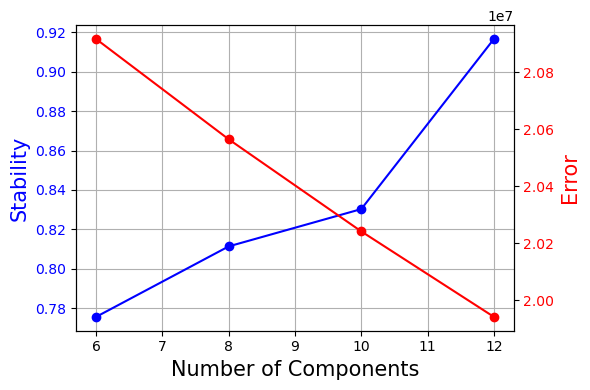

cNMF consensus loaded for K = 6, 8, 10, 12


In [44]:
# ==========================================================================
# 25a · STANDARD cNMF ON THE SAME CELLS AND GENES (cached in OUT_DIR/cnmf_bench)
#
# WHY the published package on linear counts: the reference implementation run as its authors
# recommend, on the same cells and genes, so any difference reflects the adaptation in section 9.
# ==========================================================================

try:
    from cnmf import cNMF
    HAVE_CNMF = True
except ImportError:
    HAVE_CNMF = False
    print("cnmf not installed (pip install cnmf) -> section 25 benchmark skipped")

CNMF_RES = {}
if HAVE_CNMF:
    cn_dir, cn_name = out_path("cnmf_bench"), "peng_malignant"
    cn = cNMF(output_dir=cn_dir, name=cn_name)
    done_flag = os.path.join(cn_dir, cn_name, "benchmark_done.flag")
    if need_compute(done_flag):
        lin = anndata.AnnData(X=expm1_sparse(mal.raw.X).astype(np.float32),
                              obs=pd.DataFrame(index=mal.obs_names),
                              var=pd.DataFrame(index=[str(g) for g in mal.raw.var_names]))
        lin.var_names_make_unique()
        # cnmf divides every gene by its standard deviation; a gene that is constant in these
        # cells would turn the final usage refit into NaN, so such genes are left out (and counted)
        _gi = lin.var_names.get_indexer(prog_genes)
        _Xg = lin.X[:, _gi[_gi >= 0]]
        _Xg = _Xg.toarray() if sparse.issparse(_Xg) else np.asarray(_Xg)
        cn_genes = [g for g, sd_ in zip(np.asarray(prog_genes)[_gi >= 0], _Xg.std(axis=0)) if sd_ > 0]
        print("cNMF genes: {} of section 9's {} (dropped: {} absent, {} constant)".format(
            len(cn_genes), len(prog_genes), int((_gi < 0).sum()), int((_gi >= 0).sum()) - len(cn_genes)))
        in_fn = out_path("cnmf_input_cp10k.h5ad")
        lin.write_h5ad(in_fn)
        free(lin, _Xg)
        genes_fn = out_path("cnmf_genes.txt")
        with open(genes_fn, "w") as fh:
            fh.write("\n".join(cn_genes))
        cn.prepare(counts_fn=in_fn, components=CNMF_BENCH_K, n_iter=CNMF_BENCH_ITER,
                   seed=SEED, genes_file=genes_fn)
        cn.factorize(worker_i=0, total_workers=1)
        cn.combine()
        dt_used = {}
        for k in CNMF_BENCH_K:
            # cnmf's outlier filter can (rarely) leave fewer spectra than K; then the
            # consensus is redone without the filter (threshold 2.0) and that is reported
            try:
                cn.consensus(k=k, density_threshold=CNMF_DENSITY, show_clustering=False)
                dt_used[k] = CNMF_DENSITY
            except (ValueError, RuntimeError) as err:
                print("  K={}: density filter {} left too few spectra ({}) -> consensus without filter".format(
                    k, CNMF_DENSITY, str(err)[:50]))
                cn.consensus(k=k, density_threshold=2.0, show_clustering=False)
                dt_used[k] = 2.0
        with open(done_flag, "w") as fh:
            json.dump({str(k): v for k, v in dt_used.items()}, fh)
    with open(done_flag) as fh:
        CNMF_DT = {int(k): float(v) for k, v in json.load(fh).items()}
    print("cNMF density threshold used per K:", CNMF_DT)
    try:
        cn.k_selection_plot(close_fig=False)
        plt.show()
    except Exception as err:
        print("  [k-selection plot skipped: {}]".format(str(err)[:60]))

    def load_cnmf(k):
        """(usage cells x programs, spectra programs x genes) from cnmf's consensus files."""
        try:
            u, s_, _, _ = cn.load_results(K=k, density_threshold=CNMF_DT[k])
            return u, s_.T                     # load_results returns genes x programs
        except Exception:
            dt = str(CNMF_DT[k]).replace(".", "_")
            base = os.path.join(cn_dir, cn_name)
            u = pd.read_csv(os.path.join(base, "{}.usages.k_{}.dt_{}.consensus.txt".format(cn_name, k, dt)),
                            sep="\t", index_col=0)
            s_ = pd.read_csv(os.path.join(base, "{}.gene_spectra_score.k_{}.dt_{}.txt".format(cn_name, k, dt)),
                             sep="\t", index_col=0)
            return u, s_

    for k in CNMF_BENCH_K:
        CNMF_RES[k] = load_cnmf(k)
    print("cNMF consensus loaded for K = {}".format(", ".join(map(str, CNMF_RES))))

     program  cnmf_program  spectra_rho  usage_rho  best_K10  best_rho_K10  best_rho_K6  best_rho_K8  best_rho_K12                                cnmf_top_genes
    1_ductal            10        0.011      0.171         1         0.259        0.272        0.264         0.428 GLIS3-AS1, MYT1, PGLYRP2, SNAI1, TTLL9, SOX30
       2_CAF             6        0.712      0.710         6         0.712        0.762        0.754         0.589       CALD1, SPARC, IGFBP7, ACTA2, THY1, MYL9
      3_tuft             8        0.594      0.267         8         0.594        0.589        0.594         0.592            LRMP, BMX, SH2D6, HCK, RGS13, AVIL
 4_cellcycle             7        0.539      0.464         7         0.539        0.550        0.558         0.520       PTTG1, TPX2, CDC20, CCNB1, BIRC5, HMGB2
    5_acinar             5        0.537      0.498         5         0.537        0.211        0.605         0.500     RAMP2, PLVAP, CD93, CLEC14A, ECSCR, GNG11
6_intestinal             4        

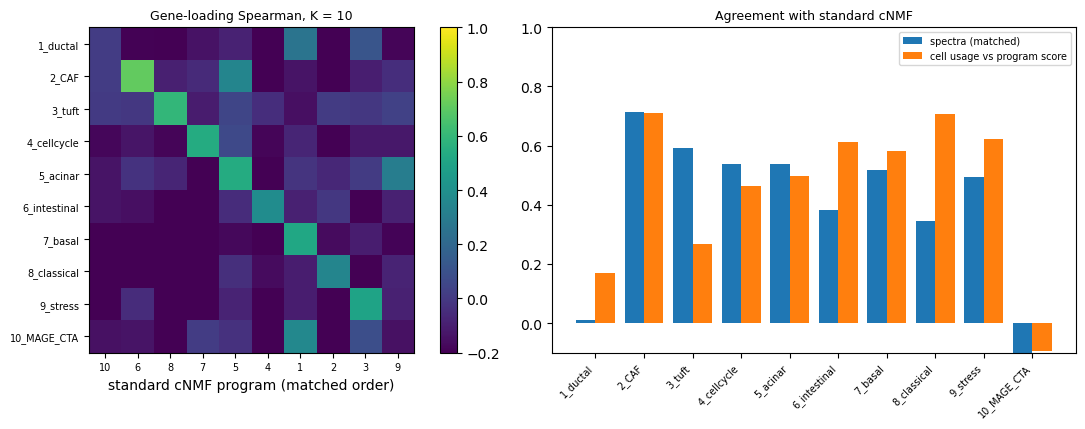

In [45]:
# ==========================================================================
# 25b · SPECTRA, USAGES AND PERSISTENCE ACROSS K   ·   Supplementary Fig. S8, Table S14
# spectra_rho / usage_rho: each of our programs paired one-to-one with a cNMF program at K = 10
# (Hungarian assignment on gene-loading Spearman). best_K10: the cNMF program it correlates with
# best when the one-to-one constraint is dropped -- where the two differ, two of our programs
# compete for the same cNMF program (one program split or merged). best_rho_K*: best match at
# each other K, also unconstrained.
#
# WHY one-to-one matching: each program is compared with exactly one partner, so a single cnmf
# program cannot be credited twice; the best partner at each K is reported as well.
# ==========================================================================

from scipy.optimize import linear_sum_assignment

if CNMF_RES:
    ours = pd.DataFrame(programs, index=PROG_NAMES, columns=prog_genes)
    u10, s10 = CNMF_RES[CNMF_K]
    common = [g for g in prog_genes if g in s10.columns]
    Rm = np.array([[spearmanr(ours.loc[p, common], s10.loc[q, common])[0] for q in s10.index]
                   for p in ours.index])
    ri, ci = linear_sum_assignment(-Rm)
    match = {PROG_NAMES[a]: (s10.index[b], Rm[a, b]) for a, b in zip(ri, ci)}
    un = u10.div(u10.sum(axis=1), axis=0).reindex(mal.obs_names)
    rows = []
    for p in PROG_NAMES:
        q, rs = match[p]
        ru = spearmanr(mal.obs["prog_" + p], un[q], nan_policy="omit")[0]
        persist = {}
        for k in CNMF_BENCH_K:
            if k == CNMF_K:
                continue
            sk = CNMF_RES[k][1]
            cc = [g for g in common if g in sk.columns]
            persist[k] = max(spearmanr(ours.loc[p, cc], sk.loc[qq, cc])[0] for qq in sk.index)
        top_c = ", ".join(s10.loc[q].sort_values(ascending=False).index[:6])
        a_ = PROG_NAMES.index(p)
        b_any = int(np.argmax(Rm[a_]))               # unconstrained best partner at K = 10
        rows.append(dict(program=p, cnmf_program=q, spectra_rho=rs, usage_rho=ru,
                         best_K10=s10.index[b_any], best_rho_K10=Rm[a_, b_any],
                         **{"best_rho_K{}".format(k): v for k, v in persist.items()}, cnmf_top_genes=top_c))
    BENCH = pd.DataFrame(rows)
    BENCH.to_csv(out_path("FigS8_cnmf_benchmark.csv"), index=False)
    RESULTS["cnmf_benchmark"] = BENCH.round(3).to_dict(orient="records")
    print(BENCH.round(3).to_string(index=False))
    _split = BENCH[BENCH["best_K10"].astype(str) != BENCH["cnmf_program"].astype(str)]
    for _, r_ in _split.iterrows():                  # where the one-to-one pairing was forced
        _rivals = BENCH.loc[BENCH["cnmf_program"].astype(str) == str(r_["best_K10"]), "program"].tolist()
        print("  {}: best cNMF partner is program {} (rho {:+.2f}), already paired with {}; "
              "the one-to-one match is program {} (rho {:+.2f})".format(
                  r_["program"], r_["best_K10"], r_["best_rho_K10"], ", ".join(_rivals) or "none",
                  r_["cnmf_program"], r_["spectra_rho"]))
    if FIGURES:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
        im = axes[0].imshow(Rm[:, ci][np.argsort(ri)], cmap="viridis", vmin=-0.2, vmax=1)
        axes[0].set_yticks(range(10)); axes[0].set_yticklabels(PROG_NAMES, fontsize=7)
        axes[0].set_xticks(range(10)); axes[0].set_xticklabels([str(s10.index[c]) for c in ci], fontsize=7)
        axes[0].set_xlabel("standard cNMF program (matched order)")
        axes[0].set_title("Gene-loading Spearman, K = 10", fontsize=9)
        plt.colorbar(im, ax=axes[0], fraction=0.046)
        x = np.arange(10)
        axes[1].bar(x - 0.2, BENCH["spectra_rho"], 0.4, label="spectra (matched)")
        axes[1].bar(x + 0.2, BENCH["usage_rho"], 0.4, label="cell usage vs program score")
        axes[1].set_xticks(x); axes[1].set_xticklabels(PROG_NAMES, rotation=45, ha="right", fontsize=7)
        axes[1].set_ylim(-0.1, 1); axes[1].legend(fontsize=7)
        axes[1].set_title("Agreement with standard cNMF", fontsize=9)
        plt.tight_layout()
        _show("FigS8_cnmf_benchmark")

In [46]:
# ==========================================================================
# 25c · WHERE DO THE FIBROBLAST/PERICYTE AND ACINAR PROGRAMS COME FROM?
# Program score in high-confidence malignant cells vs excluded cells (CNV-negative or
# doublet-flagged), and the CNV / doublet status of the top-5% cells for each program.
#
# WHY: fibroblast/pericyte and acinar programs are unexpected in a malignant compartment;
# doublet flags, CNV status and lineage markers in the top-scoring cells answer it.
# ==========================================================================

if "hc_malignant" not in mal.obs or "cnv_pos_pp" not in mal.obs:
    print("§25c skipped -- needs the §23 copy-number calls (peng_processed.h5ad / steele_qc_lognorm.h5ad)")
else:
    RESULTS["caf_acinar"] = {}
    o = mal.obs
    run_ok = o["cnv_pos_pp"].notna().values
    hc = o["hc_malignant"].values
    excl = run_ok & ~hc
    for p, markers in [("2_CAF", ["COL1A1", "PDGFRB", "ACTA2"]), ("5_acinar", ["PRSS1", "CTRB1", "CPA1"])]:
        col = "prog_" + p
        a, b = o.loc[hc, col], o.loc[excl, col]
        pv = mannwhitneyu(a, b)[1]
        top = o[col] >= o[col].quantile(0.95)
        mk = _raw_cols(mal, markers)
        print("\n{}: score in high-confidence malignant {:+.3f} (n={:,}) vs excluded {:+.3f} (n={:,}), p = {:.2e}".format(
            p, a.median(), len(a), b.median(), len(b), pv))
        print("  top-5% {} cells: CNV-positive {:.1%} (all cells {:.1%}), doublet-flagged {:.1%} (all {:.1%})".format(
            p, np.nanmean(o.loc[top & run_ok, "cnv_pos_pp"].astype(float)),
            np.nanmean(o.loc[run_ok, "cnv_pos_pp"].astype(float)),
            o.loc[top, "doublet_flag"].mean(), o["doublet_flag"].mean()))
        print("  marker expression (mean log1p CP10k), top-5% vs rest: " + ", ".join(
            "{} {:.2f} vs {:.2f}".format(g, mk[g][top.values].mean(), mk[g][~top.values].mean()) for g in markers))
        RESULTS["caf_acinar"][p] = dict(hc_median=float(a.median()), excl_median=float(b.median()), p=float(pv),
                                    top5_cnv_pos=float(np.nanmean(o.loc[top & run_ok, "cnv_pos_pp"].astype(float))),
                                    top5_doublet=float(o.loc[top, "doublet_flag"].mean()))


2_CAF: score in high-confidence malignant +0.056 (n=7,653) vs excluded +0.183 (n=3,611), p = 2.68e-256
  top-5% 2_CAF cells: CNV-positive 54.8% (all cells 77.4%), doublet-flagged 48.2% (all 11.4%)
  marker expression (mean log1p CP10k), top-5% vs rest: COL1A1 1.83 vs 0.50, PDGFRB 0.44 vs 0.04, ACTA2 1.32 vs 0.31

5_acinar: score in high-confidence malignant +0.967 (n=7,653) vs excluded +1.007 (n=3,611), p = 1.94e-23
  top-5% 5_acinar cells: CNV-positive 73.6% (all cells 77.4%), doublet-flagged 1.2% (all 11.4%)
  marker expression (mean log1p CP10k), top-5% vs rest: PRSS1 1.82 vs 0.25, CTRB1 1.17 vs 0.06, CPA1 0.87 vs 0.05


# Part V · Validation and content of the signatures

*Methods → Validation of signatures against measured dependency; Scoring of signatures; Controls. Results → Prediction of measured dependency by the signatures in DepMap; Robustness of the MAT2A association with the classical state.* Whether each signature predicts measured dependency in lines it was not derived from, what its genes are, whether the *MAT2A* association is carried by epithelial identity, how far each coefficient lies from matched nulls, and whether two dependency controls from the literature can measure sensitivity.

## 26 · Held-out validation of the signatures in DepMap  ·  Fig. 2, Supplementary Table S1

*Methods → Derivation of the dependency signature; Validation of signatures against measured dependency. Results → Prediction of measured dependency by the signatures in DepMap.* Before any single-cell use, each signature is tested **inside DepMap**, where dependency is measured.

**Held-out validation (26b–c).** Fivefold cross-validation stratified by lineage, repeated ten times. In every split the signature is **re-derived on the training lines only** and scored on the held-out lines as the mean z-scored expression of its genes (z computed with the training means and SDs), so no held-out line touches gene selection. Reported, on the pooled held-out predictions (Supplementary Table S1a):

- **ρ(score, Chronos)**, Spearman; *negative* means that a higher signature score predicts stronger dependency;
- **out-of-sample R²** of Chronos from a line fitted on the training folds (negative when the scores predict worse than the mean);
- **AUROC** separating the most from the least dependent quartile of lines (and, where both classes have at least 10 lines, at the absolute Chronos ≤ −0.5 cut);
- **ΔR²**: nested models of Chronos with target expression, lineage and proliferation, with and without the signature;
- **DEMETER2 ρ**: the out-of-fold scores against RNA-interference dependency for the lines it covers, with the target's own Chronos–DEMETER2 agreement printed as the ceiling.

**Alternative derivations (26c).** Passenger loss from **DepMap copy number** instead of an expression cut-off: *MTAP* by deep deletion (relative copy number < 0.25), because the *PRMT5* and *MAT2A* vulnerabilities need homozygous loss, and *VPS4B* by copy loss (relative copy number < 0.75), because its homozygous deletion is rare and the *VPS4A* vulnerability was defined by 18q loss. A context with fewer than 40 lines is reported and skipped. Also: **lineage held constant** (gene and Chronos ranks residualised on lineage before correlating); cut-offs of 10%, 33% and 50%; and **passenger-intact** lines (no deletion, passenger expression at or above the median), the comparison that should not carry the collateral-lethal interaction. Each is reported with its held-out performance, its overlap with the original 100 genes (Jaccard index) and its single-cell association. Deletion-derived and intact-derived signatures are also compared **in held-out PDAC lines**, with every PDAC line excluded from derivation (Supplementary Table S1b, Fig. 2h).

**Composition (26e).** Over-representation of all 100 genes of each signature in GO Biological Process, Reactome and MSigDB Hallmark, with the DepMap gene universe as background (Supplementary Table S1c).

**Passenger loss and dependency (26a, 26d).** Chronos scores of each target in lines with and without loss of its passenger gene, compared by Mann–Whitney U test (Fig. 2a–c). Section 26d draws diagnostic views of the Fig. 2 data; the figure itself is drawn in section 44.

**Why these choices**

| choice | why |
|---|---|
| Five folds, ten repeats | A standard split; repeating with new random folds averages out the luck of any single split. |
| Folds stratified by lineage | Each held-out fold has the training folds' lineage mix, so performance is not inflated or deflated by lineage imbalance. |
| Re-derivation inside each training fold, z-scores from training data | No held-out line influences gene selection or scaling, so the evaluation has no leakage. |
| AUROC between dependency quartiles | Avoids an arbitrary absolute dependency threshold; the AUROC at the absolute −0.5 cut is saved as well. |
| ΔR² over target expression, lineage and proliferation | Tests whether the signature adds anything beyond the obvious predictors. |
| Contexts with fewer than 40 lines skipped | A derivation from fewer lines is too noisy to interpret. |
| Copy-number scale detected from the values | DepMap has distributed copy number on linear and log2 scales in different releases; the scale is inferred and printed. |

In [47]:
# ==========================================================================
# 26a · DEPMAP METADATA, COPY NUMBER, DELETION CALLS   ·   data for Fig. 2a-c
# Lineage + PDAC flag from Model.csv. Copy number loaded for the passenger genes only (the
# full matrix is large), with the same default-entry / metadata / ' (entrez)' contract as
# section 11; its scale is detected and printed. Deep deletion = relative CN < DEL_REL_CN.
#
# WHY: deletion calls from DepMap copy number are the alternative to the expression cut-off used to
# derive the signatures; the cross-table shows how far the two agree. Copy-number scale is detected from the values because
# DepMap has shipped linear and log2 scales in different releases.
# ==========================================================================

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

HAVE_MODEL = os.path.exists(DEPMAP_MODEL)
HAVE_CN = os.path.exists(DEPMAP_CN)
if HAVE_MODEL:
    model = pd.read_csv(DEPMAP_MODEL).set_index("ModelID")
    LINEAGE = model["OncotreeLineage"].reindex(expr.index).fillna("Unknown").astype(str)
    IS_PDAC = (model["OncotreePrimaryDisease"].reindex(expr.index).fillna("")
               .str.contains("Pancreatic Adenocarcinoma", case=False))
    print("lineages: {} | PDAC lines with dependency + expression: {}".format(
        LINEAGE.nunique(), int(IS_PDAC.sum())))
else:
    LINEAGE = pd.Series("Unknown", index=expr.index)
    IS_PDAC = pd.Series(False, index=expr.index)
    print("!! Model.csv missing -> lineage-held, stratified CV and PDAC analyses are degraded")


def load_depmap_cols(path, genes):
    """Section 11's loader contract, reading only the requested gene columns."""
    head = list(pd.read_csv(path, nrows=0).columns)
    want = [head[0]] + [c for c in head if c in ("ModelID", "IsDefaultEntryForModel")] + \
           [c for c in head if c.split(" (")[0].strip() in genes]
    m = pd.read_csv(path, usecols=list(dict.fromkeys(want)))
    if "ModelID" in m.columns:
        if "IsDefaultEntryForModel" in m.columns:
            col = m["IsDefaultEntryForModel"]
            m = m[col.astype(str).str.lower().isin(["true", "yes", "1"]) | (col == True)]
        m = m.set_index("ModelID")
    else:
        m = m.set_index(m.columns[0])
    m = m.drop(columns=[c for c in m.columns if c.split(" (")[0].strip() in META], errors="ignore")
    m.columns = [c.split(" (")[0].strip() for c in m.columns]
    m = m.loc[:, ~m.columns.duplicated()].select_dtypes(include=[np.number])
    return m[~m.index.duplicated()]


DELETED = {}
if HAVE_CN:
    # The scale differs between DepMap copy-number files AND between releases: the 26Q2+
    # OmicsCNGeneWGS.csv is linear relative copy number, PortalOmicsCNGeneLog2.csv is log2(x+1),
    # and OmicsCNGene.csv was log2(x+1) up to 25Q1. Linear and log2(x+1) both centre on 1, so
    # the median cannot tell them apart; amplification-prone genes can: in log2(x+1) a value
    # above 6 would mean a 63-fold gain, while in linear scale ERBB2/MYC amplicons exceed it.
    _AMP = ["MYC", "ERBB2", "CCND1", "KRAS", "EGFR", "CDK4", "MDM2"]
    _cn_all = load_depmap_cols(DEPMAP_CN, ["MTAP", "VPS4B", "CDKN2A", "SMAD4", "CDS1"] + _AMP)
    cnm = _cn_all[[g for g in ["MTAP", "VPS4B", "CDKN2A", "SMAD4", "CDS1"] if g in _cn_all.columns]]
    med, vmin = float(np.nanmedian(cnm.values)), float(np.nanmin(cnm.values))
    _ampc = [g for g in _AMP if g in _cn_all.columns]
    amp_max = float(np.nanmax(_cn_all[_ampc].values)) if _ampc else float("nan")
    _nm = os.path.basename(DEPMAP_CN).lower()
    if CN_SCALE != "auto":
        scale = CN_SCALE
    elif "log2" in _nm:
        scale = "log2(x+1)"
    elif "absolute" in _nm or med >= 1.4:
        scale = "absolute"
    elif -0.4 < med < 0.4 and vmin < 0:
        scale = "log2"
    elif "wgs" in _nm or amp_max > 6:
        scale = "linear"
    else:
        scale = "log2(x+1)"
    rel = {"linear": cnm, "log2(x+1)": 2 ** cnm - 1, "log2": 2 ** cnm, "absolute": cnm / 2.0}[scale]
    print("copy number: {} ({} lines) | median {:.2f}, min {:.2f}, max over amplicon genes {:.1f} "
          "-> read as {} relative copy number (set CN_SCALE in §21 to override)".format(
              os.path.basename(DEPMAP_CN), len(cnm), med, vmin, amp_max, scale))
    for pg in ["MTAP", "VPS4B"]:
        d = (rel[pg] < LOSS_CN[pg]).reindex(expr.index)
        DELETED[pg] = d
        print("  {:<6} {} (relative CN < {}) in {:,} of {:,} lines with copy number".format(
            pg, LOSS_WORD[pg], LOSS_CN[pg], int(d.fillna(False).astype(bool).sum()), int(d.notna().sum())))
    # MTAP deep deletion is common but far from universal (published: roughly 10-20% of lines);
    # a fraction outside 3-40% means the scale was misread, and the deletion analyses are skipped
    _f = float(DELETED["MTAP"].dropna().astype(float).mean())
    if not 0.03 <= _f <= 0.40:
        print("!! MTAP called deleted in {:.0%} of lines -- implausible, so the copy-number scale was "
              "probably misread. Deletion-based analyses skipped; check the file.".format(_f))
        DELETED = {}
    # how the expression cut-off and the deletion call agree
    for pg in [g for g in ("MTAP", "VPS4B") if g in DELETED]:
        q = expr[pg] <= expr[pg].quantile(LOW_Q)
        ok = DELETED[pg].notna()
        print("\n  {}: bottom-quartile expression vs {}".format(pg, LOSS_WORD[pg]))
        print("  " + pd.crosstab(q[ok], DELETED[pg][ok].astype(bool),
                                 rownames=["expr_bottom_quartile"], colnames=["deleted"])
              .to_string().replace("\n", "\n  "))
else:
    print("!! {} missing -> deletion-based analyses skipped".format(os.path.basename(DEPMAP_CN)))

# deletion-positive vs deletion-negative: is the target more needed when its passenger is lost?
print("\nTARGET DEPENDENCY BY PASSENGER LOSS (Chronos; lower = more dependent)\n")
RESULTS["del_vs_intact_chronos"] = {}
for t in TARGETS:
    pg = TARGET_CONTEXT[t]
    if pg not in DELETED:
        continue
    d = DELETED[pg].reindex(dep.index)
    a, b = dep.loc[d == True, t].dropna(), dep.loc[d == False, t].dropna()
    if len(a) < 3 or len(b) < 3:
        print("  {:<6} too few {} {} lines (n={}) for the comparison".format(t, pg, LOSS_WORD[pg], len(a)))
        continue
    p = mannwhitneyu(a, b, alternative="two-sided")[1]
    print("  {:<6} {} {} median {:+.3f} (n={}) vs intact {:+.3f} (n={})   p = {:.2e}".format(
        t, pg, LOSS_WORD[pg], a.median(), len(a), b.median(), len(b), p))
    RESULTS["del_vs_intact_chronos"][t] = dict(med_del=float(a.median()), n_del=len(a),
                                          med_intact=float(b.median()), n_intact=len(b), p=float(p),
                                          call="{} < {}".format(LOSS_WORD[pg], LOSS_CN[pg]))

# line-level programs (unsupervised: no dependency information, so no leakage in CV)
def line_score(genes):
    g = [x for x in genes if x in expr.columns]
    z = (expr[g] - expr[g].mean()) / expr[g].std().replace(0, np.nan)
    return z.mean(axis=1)

PROLIF_LINE, EPI_LINE, EMT_LINE = line_score(PROLIF), line_score(EPI_MARKERS), line_score(EMT_MARKERS)
print("\nline-level proliferation / epithelial / EMT scores computed")

lineages: 29 | PDAC lines with dependency + expression: 44
copy number: OmicsCNGeneWGS.csv (1763 lines) | median 0.88, min 0.00, max over amplicon genes 254.9 -> read as linear relative copy number (set CN_SCALE in §21 to override)
  MTAP   deep deletion (relative CN < 0.25) in 183 of 1,063 lines with copy number
  VPS4B  copy loss (relative CN < 0.75) in 362 of 1,063 lines with copy number

  MTAP: bottom-quartile expression vs deep deletion
  deleted               False  True 
  expr_bottom_quartile              
  False                   796      2
  True                     84    181

  VPS4B: bottom-quartile expression vs copy loss
  deleted               False  True 
  expr_bottom_quartile              
  False                   601    194
  True                    100    168

TARGET DEPENDENCY BY PASSENGER LOSS (Chronos; lower = more dependent)

  VPS4A  VPS4B copy loss median -0.472 (n=362) vs intact -0.280 (n=701)   p = 1.04e-34
  PRMT5  MTAP deep deletion median -1.432 (n=183

In [48]:
# ==========================================================================
# 26b · DERIVATION AND HELD-OUT EVALUATION MACHINERY
# corr_with reproduces section 11's Spearman (Pearson of average ranks) in one matrix
# product; derive() must reproduce signatures[] exactly -- checked below before use.
#
# WHY this machinery: the signature is re-derived on the training folds ONLY and z-scored with training
# means and SDs, so no held-out line touches gene selection (no leakage). Folds are stratified by
# lineage so each held-out set has the training set's lineage mix.
# ==========================================================================

# corr_with: Pearson correlation of average ranks IS the Spearman correlation (ties get average
# ranks), computed for every gene at once as one matrix product instead of 19,000 spearmanr calls.
def corr_with(E, y):
    """Spearman of every column of E with y, ranks taken within these lines."""
    R = E.rank(axis=0).values
    r = rankdata(y)
    R = R - R.mean(axis=0)
    r = r - r.mean()
    with np.errstate(invalid="ignore", divide="ignore"):
        c = (R.T @ r) / (np.sqrt((R ** 2).sum(axis=0)) * np.sqrt((r ** 2).sum()))
    return pd.Series(c, index=E.columns)


# corr_within_lineage: projecting the lineage indicators out of both rank vectors gives a partial
# Spearman correlation with lineage held constant -- the derivation that stops
# genes that merely mark a tissue of origin from entering a dependency signature.
def corr_within_lineage(E, y, lin):
    """Lineage held constant: ranks of every gene and of y are residualised on lineage
    indicators before correlating, so a gene that only separates lineages scores ~0."""
    R = E.rank(axis=0).values
    r = rankdata(y).astype(float)
    D = pd.get_dummies(lin.astype(str)).values.astype(float)
    P = D @ np.linalg.pinv(D)
    R = R - P @ R
    r = r - P @ r
    with np.errstate(invalid="ignore", divide="ignore"):
        c = (R.T @ r) / (np.sqrt((R ** 2).sum(axis=0)) * np.sqrt((r ** 2).sum()))
    return pd.Series(c, index=E.columns)


# derive: the section-7 derivation as a function, so the identical rule can be re-run inside every
# cross-validation fold and every alternative context. `exclude` removes genes BEFORE ranking (used
# to rebuild signatures without identity genes, §27d / §31).
def derive(target, lines, n=100, lineage_held=False, exclude=None):
    lines = pd.Index(lines).intersection(dep.index[dep[target].notna()])
    e = expr.loc[lines]
    e = e.loc[:, e.std() > 0]
    if exclude:
        e = e.drop(columns=[g for g in exclude if g in e.columns])
    y = dep.loc[lines, target].values
    c = corr_within_lineage(e, y, LINEAGE.reindex(lines)) if lineage_held else corr_with(e, y)
    return c.dropna().sort_values().head(n).index.tolist()


def ctx_quantile(pg, q):
    return expr.index[expr[pg] <= expr[pg].quantile(q)]


def ctx_deleted(pg):
    return expr.index[DELETED[pg].reindex(expr.index).fillna(False).astype(bool).values]


# ctx_intact: lines with no deletion call AND passenger expression at or above the median -- lines
# that clearly keep the passenger, so the collateral-lethal interaction should be absent there.
def ctx_intact(pg):
    d = DELETED[pg].reindex(expr.index)
    return expr.index[(d == False).values & (expr[pg] >= expr[pg].median()).values]


# guard: the fast derivation must reproduce section 11's signatures
for t in TARGETS:
    again = derive(t, ctx_quantile(TARGET_CONTEXT[t], LOW_Q))
    ov = len(set(again) & set(signatures[t]))
    print("{:<6} fast derivation reproduces {}/100 of section 11's genes".format(t, ov))
    assert ov >= 98, "derivation does not reproduce section 11 -- stop"


# sig_score: each gene z-scored with TRAINING-line means and SDs, then averaged with equal weight per
# gene. Using training statistics for the held-out lines is what keeps the evaluation leak-free.
def sig_score(train, test, genes):
    g = [x for x in genes if x in expr.columns]
    mu = expr.loc[train, g].mean()
    sd = expr.loc[train, g].std().replace(0, np.nan)
    return ((expr.loc[test, g] - mu) / sd).mean(axis=1)


# _design: lineage indicators for lineages with >= 5 training lines; rarer lineages are pooled into
# 'other' so every coefficient is estimable. One indicator is dropped as the reference level so the
# design is not collinear with the intercept.
def _design(lines, levels, extra=None):
    lin = LINEAGE.reindex(lines).where(LINEAGE.reindex(lines).isin(levels), "other")
    D = pd.get_dummies(pd.Categorical(lin, categories=list(levels) + ["other"])).values[:, 1:]
    cols = [D.astype(float)]
    if extra is not None:
        cols = [np.asarray(e, float).reshape(len(lines), -1) for e in extra] + cols
    return np.column_stack(cols)


def ols_predict(Xtr, ytr, Xte):
    A = np.column_stack([np.ones(len(Xtr)), Xtr])
    beta = np.linalg.lstsq(A, ytr, rcond=None)[0]
    return np.column_stack([np.ones(len(Xte)), Xte]) @ beta


# r2: OUT-OF-SAMPLE R^2 against the mean of the held-out values. It can be negative, meaning the
# prediction is worse than the mean -- reported as computed, never truncated at zero.
def r2(y, yhat):
    y, yhat = np.asarray(y, float), np.asarray(yhat, float)
    return float(1 - np.sum((y - yhat) ** 2) / np.sum((y - y.mean()) ** 2))


# auc_quartiles: most-dependent quartile (label 1) vs least-dependent quartile; the middle half is
# left out, so no arbitrary dependency threshold is needed. A higher score should mean more dependent.
def auc_quartiles(y, s):
    lo, hi = np.quantile(y, 0.25), np.quantile(y, 0.75)
    sel = (y <= lo) | (y >= hi)
    return float(roc_auc_score((y[sel] <= lo).astype(int), s[sel]))


def auc_abs(y, s):
    lab = (y <= STRONG_DEP_ABS).astype(int)
    if lab.sum() < 10 or (1 - lab).sum() < 10:
        return np.nan
    return float(roc_auc_score(lab, s))


# cv_eval: lineages with fewer lines than folds are pooled for stratification (StratifiedKFold needs
# >= one line per class per fold); each repeat reshuffles with its own seed; the BASE model is target
# expression + lineage + proliferation and the FULL model adds the signature, so delta R^2 is what the
# signature adds beyond those trivial predictors.
def cv_eval(target, lines, derive_fn, n_rep=CV_REPEATS):
    """Repeated stratified 5-fold CV. Returns (mean metrics, sd metrics, out-of-fold score
    averaged over repeats)."""
    lines = pd.Index(lines).intersection(dep.index[dep[target].notna()])
    y = dep.loc[lines, target]
    strat = LINEAGE.reindex(lines).fillna("Unknown")
    vc = strat.value_counts()
    strat = strat.where(strat.map(vc) >= CV_FOLDS, "other")
    mets, oof = [], []
    for rep in range(n_rep):
        skf = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED + rep)
        s_pred, y_hat, yb, yf = (pd.Series(np.nan, index=lines) for _ in range(4))
        for tr, te in skf.split(np.zeros(len(lines)), strat.values):
            Ltr, Lte = lines[tr], lines[te]
            genes = derive_fn(target, Ltr)
            s_tr, s_te = sig_score(Ltr, Ltr, genes), sig_score(Ltr, Lte, genes)
            s_pred[Lte] = s_te.values
            b = np.polyfit(s_tr.values, y[Ltr].values, 1)
            y_hat[Lte] = np.polyval(b, s_te.values)
            levels = [l for l, c in LINEAGE.reindex(Ltr).value_counts().items() if c >= 5]
            base_tr = _design(Ltr, levels, [expr.loc[Ltr, target], PROLIF_LINE.reindex(Ltr)])
            base_te = _design(Lte, levels, [expr.loc[Lte, target], PROLIF_LINE.reindex(Lte)])
            yb[Lte] = ols_predict(base_tr, y[Ltr].values, base_te)
            yf[Lte] = ols_predict(np.column_stack([base_tr, s_tr.values]), y[Ltr].values,
                                  np.column_stack([base_te, s_te.values]))
        yy, ss = y.values, s_pred.values
        mets.append(dict(rho=spearmanr(ss, yy)[0], r2=r2(yy, y_hat.values),
                         auc_quartile=auc_quartiles(yy, ss), auc_abs=auc_abs(yy, ss),
                         r2_base=r2(yy, yb.values), r2_full=r2(yy, yf.values)))
        oof.append(s_pred)
    df = pd.DataFrame(mets)
    df["delta_r2"] = df["r2_full"] - df["r2_base"]
    return df.mean(), df.std(), pd.concat(oof, axis=1).mean(axis=1), len(lines)


print("\nCV machinery ready: {} folds x {} repeats".format(CV_FOLDS, CV_REPEATS))

VPS4A  fast derivation reproduces 100/100 of section 11's genes
PRMT5  fast derivation reproduces 100/100 of section 11's genes
MAT2A  fast derivation reproduces 100/100 of section 11's genes

CV machinery ready: 5 folds x 10 repeats


In [49]:
# ==========================================================================
# 26c · HELD-OUT VALIDATION, ALTERNATIVE DERIVATIONS, PDAC HOLD-OUT, DEMETER2   ·   Table S1a,b
# Runs every derivation for every target (a few minutes). Results:
# OUT_DIR/TableS3a_depmap_validation.csv. Single-cell rho = partial Spearman with the
# classical score for a signature derived on the FULL context of that variant.
#
# WHY each comparison: alternative derivations test the choices made in section 11 (copy number,
# lineage held, other cut-offs, passenger-intact lines); the PDAC hold-out tests transfer to the disease in question;
# DEMETER2 is an independent technology (RNAi), with the target's own Chronos-DEMETER2 agreement as
# the ceiling any signature could reach.
# ==========================================================================

MIN_CTX_LINES = 40      # a context with fewer lines (with Chronos) is too small to derive and
                        # cross-validate a 100-gene signature; it is reported and skipped


def _n_ctx(t, ctx):
    """Lines of a context that have a Chronos score for the target."""
    return len(pd.Index(ctx).intersection(dep.index[dep[t].notna()]))


VARIANTS = {"original (bottom 25% expression)": (lambda pg: ctx_quantile(pg, LOW_Q), {})}
for q in CUTOFFS:
    if q != LOW_Q:
        VARIANTS["bottom {:.0%} expression".format(q)] = (lambda pg, q=q: ctx_quantile(pg, q), {})
VARIANTS["lineage held constant"] = (lambda pg: ctx_quantile(pg, LOW_Q), {"lineage_held": True})
if DELETED:
    VARIANTS["passenger-loss lines (copy number)"] = (ctx_deleted, {})
    VARIANTS["passenger-intact lines"] = (ctx_intact, {})

D2 = None
if os.path.exists(DEMETER2) and HAVE_MODEL and "CCLEName" in model.columns:
    _d2 = pd.read_csv(DEMETER2, index_col=0)
    _d2.index = [str(i).split(" (")[0].strip() for i in _d2.index]
    _d2 = _d2[~_d2.index.duplicated()].T
    _c2m = model.reset_index().dropna(subset=["CCLEName"]).set_index("CCLEName")["ModelID"]
    _d2.index = _d2.index.map(_c2m)
    D2 = _d2[_d2.index.notna()]
    D2 = D2[~D2.index.duplicated()]
    print("DEMETER2: {} lines mapped to ModelID".format(len(D2)))
else:
    print("!! DEMETER2 (or Model.csv) missing -> independent-dataset check skipped")


def sc_assoc(genes):
    """Mean partial Spearman with the classical score in both cohorts for a gene list."""
    out = {}
    for lab, ad in [("Peng", mal), ("Steele", steele), ("Werba", werba)]:
        present = score(ad, genes, "_v")
        out[lab] = mean_rho(ps_vs(ad.obs, "_v")) if len(present) >= 20 else np.nan
        del ad.obs["_v"]
    return out


DEPMAP_VAL, OOF = [], {}
for t in TARGETS:
    pg = TARGET_CONTEXT[t]
    for vname, (ctx_fn, kw) in VARIANTS.items():
        ctx = ctx_fn(pg)
        if _n_ctx(t, ctx) < MIN_CTX_LINES:
            print("  {:<6} {:<36} n={:<4} -- too few lines to derive a signature; skipped".format(
                t, vname, _n_ctx(t, ctx)))
            DEPMAP_VAL.append(dict(target=t, derivation=vname, n_lines=_n_ctx(t, ctx)))
            continue
        fn = lambda tt, L, kw=kw: derive(tt, L, **kw)
        m, s, oof, n = cv_eval(t, ctx, fn)
        full_genes = derive(t, ctx, **kw)
        jac = len(set(full_genes) & set(signatures[t])) / len(set(full_genes) | set(signatures[t]))
        sca = sc_assoc(full_genes)
        row = dict(target=t, derivation=vname, n_lines=n,
                   rho_score_chronos=m["rho"], rho_sd=s["rho"], r2_oos=m["r2"],
                   auc_quartiles=m["auc_quartile"], auc_abs=m["auc_abs"],
                   r2_base=m["r2_base"], r2_full=m["r2_full"], delta_r2=m["delta_r2"],
                   jaccard_vs_original=jac, sc_rho_peng=sca["Peng"], sc_rho_steele=sca["Steele"],
                   sc_rho_werba=sca["Werba"])
        if D2 is not None and t in D2.columns:
            both = oof.index.intersection(D2.index[D2[t].notna()])
            if len(both) >= 20:
                row["rho_oof_demeter2"] = spearmanr(oof[both], D2.loc[both, t])[0]
                row["rho_chronos_demeter2"] = spearmanr(dep.loc[both, t], D2.loc[both, t])[0]
                row["n_demeter2"] = len(both)
        DEPMAP_VAL.append(row)
        if vname.startswith("original"):
            OOF[t] = (oof, ctx)
        print("  {:<6} {:<36} n={:<4} rho={:+.3f}  R2={:+.3f}  AUC={:.2f}  dR2={:+.3f}  "
              "J={:.2f}  sc: Peng {:+.3f} / Steele {:+.3f} / Werba {:+.3f}{}".format(
                  t, vname, n, m["rho"], m["r2"], m["auc_quartile"], m["delta_r2"], jac,
                  sca["Peng"], sca["Steele"], sca["Werba"],
                  "  D2 rho={:+.3f} (ceiling {:+.3f}, n={})".format(
                      row["rho_oof_demeter2"], row["rho_chronos_demeter2"], row["n_demeter2"])
                  if "rho_oof_demeter2" in row else ""))
    print()

DEPMAP_VAL = pd.DataFrame(DEPMAP_VAL)

# held-out PDAC lines: derive WITHOUT any PDAC line, test on PDAC lines only
print("HELD-OUT PDAC LINES (derived on non-PDAC lines)\n")
PD = []
pdac_all = expr.index[IS_PDAC.values]
for t in TARGETS:
    pg = TARGET_CONTEXT[t]
    plan = [("original (bottom 25% expression)", ctx_quantile(pg, LOW_Q))]
    if DELETED:
        plan += [("passenger-loss lines (copy number)", ctx_deleted(pg)),
                 ("passenger-intact lines", ctx_intact(pg))]
    for vname, ctx in plan:
        tr = ctx[~IS_PDAC.reindex(ctx).fillna(False).values]
        if _n_ctx(t, tr) < MIN_CTX_LINES:
            print("  {:<6} {:<36} n={} non-PDAC lines -- too few to derive; skipped".format(t, vname, _n_ctx(t, tr)))
            continue
        genes = derive(t, tr)
        tests = {"PDAC lines (all)": pdac_all.intersection(dep.index[dep[t].notna()])}
        if DELETED:
            tests["PDAC lines with {} {}".format(pg, "loss" if pg == "VPS4B" else "deletion")] = pdac_all.intersection(ctx_deleted(pg)).intersection(dep.index[dep[t].notna()])
        for tname, te in tests.items():
            if len(te) < 6:
                print("  {:<6} {:<36} {:<32} n={} -- too few".format(t, vname, tname, len(te)))
                continue
            sco = sig_score(tr, te, genes)
            rho = spearmanr(sco, dep.loc[te, t])[0]
            PD.append(dict(target=t, derivation=vname, test_set=tname, n=len(te), rho=rho))
            print("  {:<6} {:<36} {:<32} n={:<3} rho={:+.3f}".format(t, vname, tname, len(te), rho))
PD = pd.DataFrame(PD)
DEPMAP_VAL.to_csv(out_path("TableS3a_depmap_validation.csv"), index=False)
PD.to_csv(out_path("TableS3b_pdac_holdout.csv"), index=False)
RESULTS["depmap_validation"] = DEPMAP_VAL.round(4).to_dict(orient="records")
RESULTS["pdac_holdout"] = PD.round(4).to_dict(orient="records")
print("\nwrote TableS3a_depmap_validation.csv, TableS3b_pdac_holdout.csv")

DEMETER2: 701 lines mapped to ModelID
  VPS4A  original (bottom 25% expression)     n=285  rho=-0.441  R2=+0.176  AUC=0.83  dR2=+0.128  J=1.00  sc: Peng -0.036 / Steele +0.157 / Werba -0.017  D2 rho=-0.294 (ceiling +0.588, n=118)
  VPS4A  bottom 10% expression                n=114  rho=-0.477  R2=+0.157  AUC=0.86  dR2=+0.129  J=0.17  sc: Peng -0.111 / Steele -0.091 / Werba -0.020  D2 rho=-0.505 (ceiling +0.699, n=36)
  VPS4A  bottom 33% expression                n=376  rho=-0.431  R2=+0.160  AUC=0.84  dR2=+0.119  J=0.52  sc: Peng -0.003 / Steele +0.179 / Werba +0.029  D2 rho=-0.237 (ceiling +0.519, n=161)
  VPS4A  bottom 50% expression                n=570  rho=-0.376  R2=+0.128  AUC=0.78  dR2=+0.089  J=0.25  sc: Peng +0.045 / Steele +0.243 / Werba +0.100  D2 rho=-0.265 (ceiling +0.543, n=237)
  VPS4A  lineage held constant                n=285  rho=-0.435  R2=+0.146  AUC=0.83  dR2=+0.105  J=0.33  sc: Peng -0.097 / Steele +0.006 / Werba -0.026  D2 rho=-0.304 (ceiling +0.588, n=118)
  V

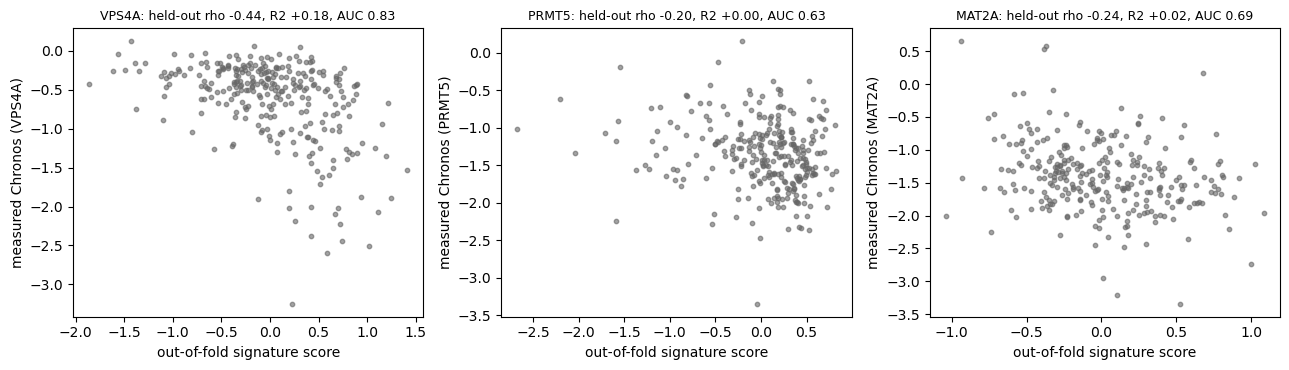

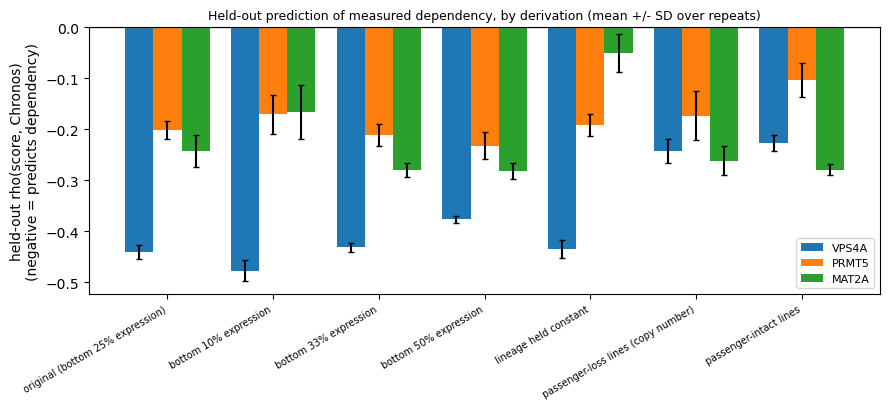

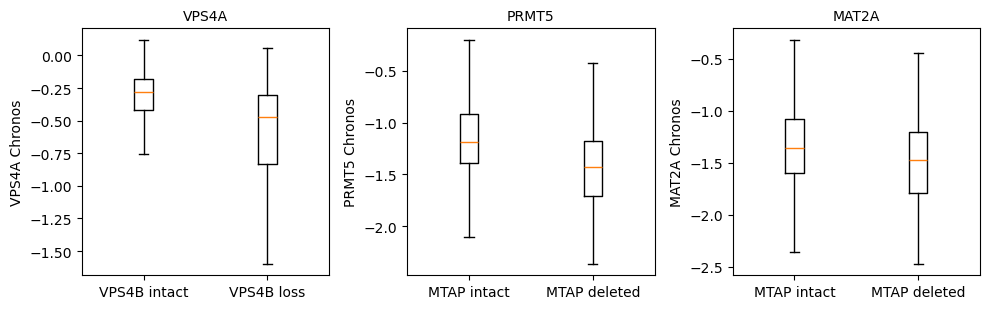

In [50]:
# ==========================================================================
# 26d · FIGURES -- held-out validation (diagnostic views of Fig. 2)
# Diagnostic views of the Fig. 2 data (the figure itself is drawn in section 44).
# (a) out-of-fold signature score vs measured Chronos, original derivation, per target
# (b) held-out rho for every derivation, per target
# (c) Chronos by passenger deletion status
# ==========================================================================

if FIGURES:
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
    for ax, t in zip(axes, TARGETS):
        if t not in OOF:                     # original derivation skipped (too few lines)
            ax.set_title("{}: not derived".format(t), fontsize=9); ax.axis("off")
            continue
        oof, ctx = OOF[t]
        y = dep.loc[oof.index, t]
        ax.scatter(oof, y, s=10, color="0.4", alpha=0.6)
        rr = DEPMAP_VAL[(DEPMAP_VAL["target"] == t) & DEPMAP_VAL["derivation"].str.startswith("original")].iloc[0]
        ax.set_title("{}: held-out rho {:+.2f}, R2 {:+.2f}, AUC {:.2f}".format(
            t, rr["rho_score_chronos"], rr["r2_oos"], rr["auc_quartiles"]), fontsize=9)
        ax.set_xlabel("out-of-fold signature score")
        ax.set_ylabel("measured Chronos ({})".format(t))
    plt.tight_layout()
    _show("depmap_heldout_scatter")

    fig, ax = plt.subplots(figsize=(9, 4.2))
    vnames = list(VARIANTS)
    w = 0.8 / len(TARGETS)
    for j, t in enumerate(TARGETS):
        _g = DEPMAP_VAL[DEPMAP_VAL["target"] == t].set_index("derivation").reindex(vnames)   # skipped = NaN bar
        vals, errs = _g["rho_score_chronos"].values, _g["rho_sd"].values
        ax.bar(np.arange(len(vnames)) + (j - 1) * w, vals, w, yerr=errs, label=t, capsize=2)
    ax.axhline(0, color="0.5", lw=1)
    ax.set_xticks(range(len(vnames)))
    ax.set_xticklabels(vnames, rotation=30, ha="right", fontsize=7)
    ax.set_ylabel("held-out rho(score, Chronos)\n(negative = predicts dependency)")
    ax.legend(fontsize=8)
    ax.set_title("Held-out prediction of measured dependency, by derivation (mean +/- SD over repeats)", fontsize=9)
    plt.tight_layout()
    _show("depmap_derivation_variants")

    if DELETED:
        fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
        for ax, t in zip(axes, TARGETS):
            pg = TARGET_CONTEXT[t]
            d = DELETED[pg].reindex(dep.index)
            ax.boxplot([dep.loc[d == False, t].dropna(), dep.loc[d == True, t].dropna()],
                       showfliers=False)
            ax.set_xticks([1, 2])
            ax.set_xticklabels(["{} intact".format(pg), "{} {}".format(pg, "loss" if pg == "VPS4B" else "deleted")])
            ax.set_ylabel("{} Chronos".format(t)); ax.set_title(t, fontsize=10)
        plt.tight_layout()
        _show("depmap_deletion_vs_intact")

In [51]:
# ==========================================================================
# 26e · WHAT THE SIGNATURES ARE MADE OF -- over-representation of ALL 100 genes   ·   Table S1c
# Enrichr libraries (cached in OUT_DIR) with the DepMap gene universe as background.
# gseapy is needed (pip install gseapy); without it the gene lists are written to CSV for
# manual g:Profiler / Enrichr analysis.
#
# WHY the DepMap gene universe as background: an enrichment test must compare against the genes that
# could have been selected, which are the genes in the DepMap expression matrix.
# ==========================================================================

def enrichr_libs(names=("GO_Biological_Process_2023", "Reactome_2022", "MSigDB_Hallmark_2020")):
    if os.path.exists(GENESET_JSON) and not RECOMPUTE:
        with open(GENESET_JSON) as fh:
            return json.load(fh)
    import gseapy
    try:
        libs = {n: gseapy.get_library(name=n, organism="Human") for n in names}
    except Exception as err:                 # offline / Enrichr down: a cached download will do
        if os.path.exists(GENESET_JSON):
            print("  Enrichr unreachable ({}) -> using the cached libraries".format(type(err).__name__))
            with open(GENESET_JSON) as fh:
                return json.load(fh)
        raise
    with open(GENESET_JSON, "w") as fh:
        json.dump(libs, fh)
    return libs


pd.DataFrame({t: pd.Series(signatures[t]) for t in TARGETS}).to_csv(out_path("signature_genes.csv"), index=False)
LIBS = None
try:
    import gseapy
    LIBS = enrichr_libs()
    _gs = {"{}: {}".format(lib.split("_20")[0], term): genes
           for lib, d in LIBS.items() for term, genes in d.items()}
    ORA = []
    for t in TARGETS:
        enr = gseapy.enrich(gene_list=signatures[t], gene_sets=_gs, background=list(expr.columns),
                            outdir=None, cutoff=1.0, no_plot=True)
        df = enr.results.sort_values("Adjusted P-value")
        df.insert(0, "target", t)
        ORA.append(df)
        top = df.head(8)
        print("\n{} signature -- top terms (BH-adjusted p):".format(t))
        for _, r in top.iterrows():
            print("  {:<70} {:>8}  q={:.3g}".format(str(r["Term"])[:70], r["Overlap"], r["Adjusted P-value"]))
        RESULTS.setdefault("ora_top", {})[t] = top[["Term", "Overlap", "Adjusted P-value"]].round(6).to_dict(orient="records")
    pd.concat(ORA).to_csv(out_path("TableS3c_signature_enrichment.csv"), index=False)
    print("\nwrote TableS3c_signature_enrichment.csv")
except ImportError:
    print("gseapy not installed -> signature_genes.csv written for manual enrichment analysis")
except Exception as err:                     # no internet and no cached libraries
    LIBS = None
    print("!! gene-set libraries unavailable ({}: {}) -> §26e skipped; §27 falls back to EPI_MARKERS. "
          "signature_genes.csv written for manual analysis.".format(type(err).__name__, str(err)[:80]))


VPS4A signature -- top terms (BH-adjusted p):
  GO_Biological_Process: Protein Transport (GO:0015031)                    11/308  q=0.000416
  Reactome: Membrane Trafficking R-HSA-199991                              15/594  q=0.000416
  Reactome: Vesicle-mediated Transport R-HSA-5653656                       15/632  q=0.000427
  GO_Biological_Process: Endosomal Transport (GO:0016197)                   8/176  q=0.00133
  GO_Biological_Process: Endoplasmic Reticulum To Golgi Vesicle-Mediated    6/113  q=0.00765
  Reactome: COPI-mediated Anterograde Transport R-HSA-6807878                5/80  q=0.00921
  GO_Biological_Process: Golgi Organization (GO:0007030)                    6/127  q=0.00921
  GO_Biological_Process: Regulation Of Autophagosome Assembly (GO:200078     4/39  q=0.00921

PRMT5 signature -- top terms (BH-adjusted p):
  MSigDB_Hallmark: E2F Targets                                             11/200  q=9.64e-06
  MSigDB_Hallmark: G2-M Checkpoint                               

## 27 · Independent programs and epithelial identity of the MAT2A association  ·  Supplementary Table S5, Fig. 4b

*Methods → Scoring of signatures; Controls. Results → Robustness of the MAT2A association with the classical state. Discussion.* The circularity test of section 18 rules out only shared genes. Here the *MAT2A* association is tested against **independently defined programs** that could produce a positive association with no dependency behind it:

| program | definition |
|---|---|
| epithelial differentiation | GO:0030855 (Enrichr GO Biological Process 2023) |
| secretory activity | GO:0045055, regulated exocytosis |
| methionine metabolism | curated methionine-cycle, salvage and S-adenosylmethionine-dependent polyamine genes (section 21) |
| published single-cell states | Raghavan et al. 2021 intermediate co-expressor, scBasal and scClassical (if the file is supplied) |

For each program: its own association with the classical score (27a, Supplementary Table S5a); the *MAT2A* association **adjusted** for it, with the program added to the QC covariates on both sides (27b, Supplementary Table S5b); and all non-classical programs together. Then the signature is taken apart (27c): each gene's own partial correlation with the classical score, split into **epithelial-identity** genes (annotated to GO epithelial differentiation, or |ρ| > 0.40 with an epithelial score across all DepMap lines) and the rest (Fig. 4b). Finally (27d), the signature is **rebuilt without epithelial-identity genes** in two ways, by dropping them or by excluding them before ranking so that the 100 places refill, and each rebuild is re-tested both for its single-cell association **and** for held-out prediction of measured dependency (section 26 machinery).

A methionine-metabolism *transcript* score is not a measure of metabolite concentration or flux; it is reported as transcriptional context only.

**Why these choices**

| choice | why |
|---|---|
| Programs defined outside this study | Gene Ontology terms, a curated methionine list and published single-cell signatures cannot have been tuned to the *MAT2A* result. |
| Programs added as covariates on both sides | The same partial-correlation logic as the QC covariates (section 4). |
| Epithelial identity = GO epithelial differentiation, or \|ρ\| > 0.40 with a DepMap epithelial score | Two independent definitions, one curated and one data-driven, fixed without any dependency information; 0.40 is a conventional threshold for a moderate correlation. |
| Two rebuilds (dropped; excluded before ranking) | Dropping tests the existing genes; excluding before ranking tests whether a signature built without them would still carry the association. |

In [52]:
# ==========================================================================
# 27a · INDEPENDENT PROGRAMS -- defined, scored in all three cohorts, tested   ·   Table S5a
#
# WHY these programs: each is defined outside this study (GO terms, a curated methionine list,
# published single-cell signatures), so none can have been tuned to the MAT2A result.
# ==========================================================================

def term_genes(lib, go_id):
    hits = [k for k in LIBS[lib] if go_id in k]
    if not hits:
        raise KeyError("{} not found in {}".format(go_id, lib))
    return hits[0], sorted(set(LIBS[lib][hits[0]]))


PROGRAMS = {}
if LIBS is not None:
    _n, _g = term_genes("GO_Biological_Process_2023", GO_EPITHELIAL)
    PROGRAMS["epithelial differentiation"] = _g
    print("epithelial differentiation <- '{}' ({} genes)".format(_n, len(_g)))
    try:
        _n, _g = term_genes("GO_Biological_Process_2023", GO_SECRETORY)
    except KeyError:
        _n, _g = term_genes("GO_Biological_Process_2023", "GO:0006887")   # exocytosis
    PROGRAMS["secretory (exocytosis)"] = _g
    print("secretory activity          <- '{}' ({} genes)".format(_n, len(_g)))
else:
    PROGRAMS["epithelial identity markers"] = EPI_MARKERS
    print("!! gseapy unavailable: epithelial program falls back to EPI_MARKERS; no secretory program")
PROGRAMS["methionine metabolism"] = METHIONINE
RAGH = {}
if os.path.exists(RAGHAVAN_SIGS):
    _r = pd.read_csv(RAGHAVAN_SIGS)
    for _s, _gg in _r.groupby("signature"):
        RAGH[str(_s)] = sorted(set(_gg["gene"].astype(str)))
    print("Raghavan et al. signatures: " + ", ".join("{} ({})".format(k, len(v)) for k, v in RAGH.items()))
else:
    print("!! raghavan2021_signatures.csv missing -> published single-cell subtype signatures skipped")

for name, genes in PROGRAMS.items():
    print("  {:<28} overlap with MAT2A signature: {:>2} | with Moffitt classical: {:>2}".format(
        name, len(set(genes) & set(signatures["MAT2A"])), len(set(genes) & set(MOFFITT_CLASSICAL))))

PRG_COL = {}
for name, genes in list(PROGRAMS.items()) + [("Raghavan " + k, v) for k, v in RAGH.items()]:
    col = "prg_" + "".join(ch if ch.isalnum() else "_" for ch in name.lower())[:28]
    PRG_COL[name] = col
    for ad in (mal, steele, werba):
        score(ad, genes, col)

print("\nEACH PROGRAM vs THE CLASSICAL SCORE (partial Spearman, QC-controlled)\n")
for _lab, _ad, _null in [("Peng", mal, null), ("Steele", steele, s_null), ("Werba", werba, w_null)]:
    show_rows([stat_row("{} {}".format(_lab, n), ps_vs(_ad.obs, c), _null) for n, c in PRG_COL.items()])
    print()

epithelial differentiation <- 'Epithelial Cell Differentiation (GO:0030855)' (132 genes)
secretory activity          <- 'Regulated Exocytosis (GO:0045055)' (51 genes)
Raghavan et al. signatures: IC (30), scBasal (30), scClassical (30)
  epithelial differentiation   overlap with MAT2A signature:  1 | with Moffitt classical:  1
  secretory (exocytosis)       overlap with MAT2A signature:  1 | with Moffitt classical:  0
  methionine metabolism        overlap with MAT2A signature:  0 | with Moffitt classical:  0

EACH PROGRAM vs THE CLASSICAL SCORE (partial Spearman, QC-controlled)

                                             n     neg      mean    95% CI (patients)         p      SD    emp p
  Peng epithelial differentiation           24    3/24   +0.1579   [+0.0957, +0.2220]    0.0001    +1.6   0.0969
  Peng secretory (exocytosis)               24   11/24   +0.0263   [-0.0211, +0.0750]    0.4389    +0.1   0.9301
  Peng methionine metabolism                24    6/24   +0.0682   [+0.0310

In [53]:
# ==========================================================================
# 27b · MAT2A ASSOCIATION ADJUSTED FOR EACH PROGRAM (covariates on BOTH sides)   ·   Table S5b
#
# WHY add each program on both sides: the same partial-correlation logic as the QC covariates.
# ==========================================================================

NONCLASS = [c for n, c in PRG_COL.items() if not n.lower().startswith("raghavan")]
RESULTS["program_adjusted"] = {}
print("MAT2A vs CLASSICAL, ADJUSTED FOR INDEPENDENT PROGRAMS\n")
for _lab, _ad, _null in [("Peng", mal, null), ("Steele", steele, s_null), ("Werba", werba, w_null)]:
    rows = [stat_row("{} MAT2A | QC only".format(_lab), ps_vs(_ad.obs, "MAT2A_sig"), _null)]
    for n, c in PRG_COL.items():
        r = ps_vs(_ad.obs, "MAT2A_sig", covars=QC_COVARS + [c])
        RESULTS["program_adjusted"]["{}|{}".format(_lab, n)] = r
        rows.append(stat_row("{} MAT2A | + {}".format(_lab, n), r, _null))
    r = ps_vs(_ad.obs, "MAT2A_sig", covars=QC_COVARS + NONCLASS)
    RESULTS["program_adjusted"]["{}|all non-classical programs".format(_lab)] = r
    rows.append(stat_row("{} MAT2A | + all non-classical programs".format(_lab), r, _null))
    show_rows(rows)
    print()

MAT2A vs CLASSICAL, ADJUSTED FOR INDEPENDENT PROGRAMS

                                             n     neg      mean    95% CI (patients)         p      SD    emp p
  Peng MAT2A | QC only                      24    2/24   +0.3094   [+0.2397, +0.3762]    0.0000    +3.4   0.0070
  Peng MAT2A | + epithelial differentiatio  24    2/24   +0.2795   [+0.2108, +0.3463]    0.0000    +3.1   0.0100
  Peng MAT2A | + secretory (exocytosis)     24    1/24   +0.3098   [+0.2437, +0.3739]    0.0000    +3.4   0.0070
  Peng MAT2A | + methionine metabolism      24    2/24   +0.3122   [+0.2436, +0.3776]    0.0000    +3.5   0.0070
  Peng MAT2A | + Raghavan IC                24    0/24   +0.3379   [+0.2781, +0.3966]    0.0000    +3.8   0.0040
  Peng MAT2A | + Raghavan scBasal           24    1/24   +0.3164   [+0.2508, +0.3805]    0.0000    +3.5   0.0060
  Peng MAT2A | + Raghavan scClassical       24   12/24   -0.0310   [-0.0818, +0.0192]    0.2292    -0.6   0.5485
  Peng MAT2A | + all non-classical progra

In [54]:
# ==========================================================================
# 27c · WHICH GENES CARRY THE ASSOCIATION -- per-gene partial Spearman   ·   data for Fig. 4b
# Epithelial-identity genes = GO epithelial differentiation (if available) OR |rho| > 0.4 with
# the DepMap epithelial score across ALL lines. Fixed without any dependency information.
#
# WHY per gene: shows which genes carry the association and whether they are epithelial-identity
# genes, i.e. what the signature is made of.
# ==========================================================================

EPI_CORR = corr_with(expr, EPI_LINE.values)
EPI_IDENTITY = set(EPI_CORR.index[EPI_CORR.abs() > EPI_CORR_MAX])
if "epithelial differentiation" in PROGRAMS:
    EPI_IDENTITY |= set(PROGRAMS["epithelial differentiation"])
_mat_epi = sorted(set(signatures["MAT2A"]) & EPI_IDENTITY)
print("epithelial-identity genes defined: {:,} | in the MAT2A signature: {} -> {}".format(
    len(EPI_IDENTITY), len(_mat_epi), ", ".join(_mat_epi)))


def per_gene_rho(ad, genes, min_det=0.01):
    names = pd.Index(ad.raw.var_names)
    out = {}
    for g in genes:
        if g not in names:
            continue
        v = ad.raw.X[:, names.get_loc(g)]
        v = np.asarray(v.todense()).ravel() if sparse.issparse(v) else np.asarray(v).ravel()
        if (v > 0).mean() < min_det:
            continue
        ad.obs["_g"] = v
        out[g] = mean_rho(ps_vs(ad.obs, "_g"))
    if "_g" in ad.obs:
        del ad.obs["_g"]
    return pd.Series(out, dtype=float)


RESULTS["per_gene"] = {}
for _lab, _ad in [("Peng", mal), ("Steele", steele), ("Werba", werba)]:
    pg_r = per_gene_rho(_ad, signatures["MAT2A"])
    is_epi = pg_r.index.isin(EPI_IDENTITY)
    a, b = pg_r[is_epi], pg_r[~is_epi]
    p = mannwhitneyu(a, b, alternative="two-sided")[1] if len(a) >= 3 and len(b) >= 3 else np.nan
    print("\n{}: per-gene partial rho with classical -- epithelial-identity genes mean {:+.3f} (n={}) "
          "vs other genes {:+.3f} (n={}), Mann-Whitney p = {:.3g}".format(
              _lab, a.mean(), len(a), b.mean(), len(b), p))
    top = pg_r.sort_values(ascending=False).head(15)
    print("  top 15: " + ", ".join("{}{} {:+.2f}".format(g, "*" if g in EPI_IDENTITY else "", v)
                                   for g, v in top.items()) + "   (* = epithelial identity)")
    RESULTS["per_gene"][_lab] = dict(epi_mean=float(a.mean()), n_epi=len(a), other_mean=float(b.mean()),
                                 n_other=len(b), p=float(p), top=top.round(3).to_dict())
    pg_r.rename("per_gene_partial_rho").to_csv(out_path("mat2a_per_gene_{}.csv".format(_lab.lower())))

epithelial-identity genes defined: 1,559 | in the MAT2A signature: 56 -> ARHGAP27, ARRDC1, BAIAP3, BARX2, BCL2L1, BTC, C19orf33, CAPN8, CD164L2, CHDH, CLDN23, COBL, CRYBB3, CTSV, CYP4F11, DOK7, EPB41L4A, EPHA10, FAM83H, GOLT1A, GREP1, HDHD3, HSBP1L1, HTATIP2, IQANK1, KLHDC9, LCN2, LMNTD2, LTBR, MPL, MYO5C, NOXA1, PPP1R26, PROSER2, PTER, RAB17, RASAL1, RHOF, RHPN1, RSPH1, SERPINB1, SLC16A5, SLC37A1, SPINT2, SYNGR2, TESMIN, TFCP2L1, TGFA, TMEM139, TMEM265, TMPRSS13, TNFSF13, TSTD1, TTC9, VAMP8, ZNF185

Peng: per-gene partial rho with classical -- epithelial-identity genes mean +0.052 (n=51) vs other genes +0.011 (n=37), Mann-Whitney p = 0.00395
  top 15: C19orf33* +0.32, CAPN8* +0.31, TPD52 +0.21, VAMP8* +0.19, HDHD3* +0.14, LCN2* +0.13, SPINT2* +0.13, TSTD1* +0.12, SERPINB1* +0.12, CLDN23* +0.12, SLC37A1* +0.11, ARRDC1* +0.09, HTATIP2* +0.09, MYO5C* +0.09, PRKCD +0.08   (* = epithelial identity)

Steele: per-gene partial rho with classical -- epithelial-identity genes mean +0.086 (n=48)

In [55]:
# ==========================================================================
# 27d · MAT2A SIGNATURE REBUILT WITHOUT EPITHELIAL-IDENTITY GENES   ·   Table 1
# 'dropped'  = the original 100 minus epithelial-identity genes
# 'refilled' = epithelial-identity genes excluded BEFORE ranking, so 100 slots refill
# Each: single-cell association in all three cohorts AND held-out DepMap prediction (§26 CV).
#
# WHY two rebuilds: dropping identity genes tests the existing signature; excluding them before
# ranking tests whether a signature built without them would exist at all. Both are also re-tested
# for held-out prediction of dependency.
# ==========================================================================

_ctx_mat = ctx_quantile(TARGET_CONTEXT["MAT2A"], LOW_Q)
EPI_VARIANTS = {
    "MAT2A original": lambda tt, L: derive(tt, L),
    "MAT2A epithelial genes dropped": lambda tt, L: [g for g in derive(tt, L) if g not in EPI_IDENTITY],
    "MAT2A epithelial genes excluded, refilled": lambda tt, L: derive(tt, L, exclude=EPI_IDENTITY),
}
RESULTS["epi_removed"] = {}
for vname, fn in EPI_VARIANTS.items():
    genes = fn("MAT2A", _ctx_mat)
    m, s, _, n = cv_eval("MAT2A", _ctx_mat, fn)
    rows = []
    for _lab, _ad, _null in [("Peng", mal, null), ("Steele", steele, s_null), ("Werba", werba, w_null)]:
        score(_ad, genes, "_epi")
        r = ps_vs(_ad.obs, "_epi")
        RESULTS["epi_removed"]["{}|{}".format(_lab, vname)] = r
        rows.append(stat_row("{} {} ({} genes)".format(_lab, vname, len(genes)), r, _null))
        del _ad.obs["_epi"]
    show_rows(rows)
    print("    held-out DepMap: rho(score, Chronos) {:+.3f}  R2 {:+.3f}  AUC {:.2f}  dR2 {:+.3f}\n".format(
        m["rho"], m["r2"], m["auc_quartile"], m["delta_r2"]))
    RESULTS["epi_removed"]["depmap|" + vname] = dict(rho=m["rho"], r2=m["r2"], auc=m["auc_quartile"],
                                                 delta_r2=m["delta_r2"], n_genes=len(genes))

                                             n     neg      mean    95% CI (patients)         p      SD    emp p
  Peng MAT2A original (100 genes)           24    2/24   +0.3094   [+0.2397, +0.3762]    0.0000    +3.4   0.0070
  Steele MAT2A original (100 genes)         14    0/14   +0.4290   [+0.3329, +0.5139]    0.0001    +4.4   0.0010
  Werba MAT2A original (100 genes)          11    0/11   +0.2978   [+0.2057, +0.3943]    0.0010    +4.1   0.0040
    held-out DepMap: rho(score, Chronos) -0.243  R2 +0.024  AUC 0.69  dR2 -0.027

                                             n     neg      mean    95% CI (patients)         p      SD    emp p
  Peng MAT2A epithelial genes dropped (44   24    2/24   +0.0965   [+0.0689, +0.1260]    0.0000    +0.9   0.3247
  Steele MAT2A epithelial genes dropped (4  14    4/14   +0.0639   [+0.0017, +0.1225]    0.0785    +0.7   0.4416
  Werba MAT2A epithelial genes dropped (44  11    3/11   +0.0599   [+0.0178, +0.1067]    0.0322    +1.0   0.2527
    held-out D

## 28 · Stricter nulls, confidence intervals, multiple testing and equivalence  ·  Supplementary Table S4a, Supplementary Fig. S5

*Methods → Statistical analysis; Controls. Results → Distribution of the dependency signatures across malignant states.* Three additions to section 15:

1. **Two more matched nulls for *MAT2A*** (28a; 1,000 sets each, all three cohorts): **variability/detection-matched** (each signature gene replaced by one in the same decile of mean and of variance, with detection frequency within ±0.05) and **covariance-matched** (random sets from the same expression range whose mean pairwise correlation is brought, by gene swaps, to within ±0.005 of the signature's own, so that "any coordinated program" is the null). With the random-gene and expression-matched nulls these are the four nulls of Table 1 and Fig. 4a.
2. **Effect sizes and testing** (28b): every coefficient with a 95% patient-bootstrap CI, the empirical null p ((k + 1)/(n + 1)), and Benjamini–Hochberg q across the three targets and the commonly essential control within each cohort. The two-SD criterion, fixed before the results were seen, is kept but reported as a convention alongside these. These rows are the classical-axis rows of Supplementary Table S2 and Supplementary Tables S4a and S9b.
3. **Equivalence** (28b): two one-sided tests for each signature against ±0.10. "No detected association" is the wording unless the 90% CI lies inside the margin (Supplementary Fig. S5).

**Why these choices**

| choice | why |
|---|---|
| Variability/detection-matched null (same decile of mean and of variance; detection within ±0.05) | Matches the properties the expression-matched null leaves free. |
| Covariance-matched null (mean intergene correlation within ±0.005 of the signature's) | Makes any coordinated program the null, which matters because a derived signature is a set of co-expressed genes. |
| Benjamini–Hochberg within each cohort over the three targets and the commonly essential control | Controls the false-discovery rate over the tests that make the claim on this axis; section 33 corrects over both axes. |
| 10,000 patient-bootstrap resamples | Stable 95% interval endpoints. |
| Equivalence margin ±0.10 | A correlation of 0.10 explains 1% of rank variance and is conventionally small; it is also under one-third of the *MAT2A* coefficient. The two one-sided tests use the 90% CI, as is standard (Lakens 2017). |

In [56]:
# ==========================================================================
# 28a · VARIABILITY/DETECTION-MATCHED AND COVARIANCE-MATCHED NULLS (MAT2A)   ·   Table 1, Fig. 4a
# Each null has its OWN seeded generator and draws from SORTED gene lists (the section-11
# determinism fixes). Cached per cohort.
#
# WHY these nulls: they control what the expression-matched null left free (variance, detection,
# gene-gene covariance), so 'any coordinated program' becomes the null.
# ==========================================================================

def gene_stats(ad):
    X = ad.raw.X
    if sparse.issparse(X):
        mean = np.asarray(X.mean(axis=0)).ravel()
        sq = np.asarray(X.multiply(X).mean(axis=0)).ravel()
        det = np.asarray((X > 0).mean(axis=0)).ravel()
    else:
        X = np.asarray(X)
        mean, sq, det = X.mean(axis=0), (X ** 2).mean(axis=0), (X > 0).mean(axis=0)
    return pd.DataFrame({"mean": mean, "var": sq - mean ** 2, "det": det},
                        index=[str(g) for g in ad.raw.var_names])


# Each harder null is built in two steps: draw the gene sets (the only random step, on its own
# seeded generator), then score them. Splitting them changes no number -- scoring never touched
# the generator -- but lets §31 score the same kind of null against other state axes.
# WHY deciles, and a widening tolerance: each replacement gene shares the template gene's mean decile
# and its variance decile within that, and its detection rate within DET_TOL. For rare genes no partner
# may exist at +/-0.05, so the tolerance doubles until >= 5 candidates exist (capped at 0.5): every
# template gene stays replaceable, and the matching never becomes looser than it has to.
def variability_matched_sets(ad, template, n=N_NULL, seed=SEED + 11):
    """n gene sets, each gene of the template swapped for one of similar mean, variance and
    detection rate (same mean decile, same variance decile within it, detection within DET_TOL)."""
    r = np.random.default_rng(seed)
    gs = gene_stats(ad)
    gs = gs[gs["det"] > 0].copy()
    gs["mb"] = pd.qcut(gs["mean"].rank(method="first"), 10, labels=False)
    gs["vb"] = gs.groupby("mb")["var"].transform(
        lambda v: pd.qcut(v.rank(method="first"), 10, labels=False))
    t = [g for g in template if g in gs.index]
    cand = {}
    for g in t:
        same = gs[(gs["mb"] == gs.at[g, "mb"]) & (gs["vb"] == gs.at[g, "vb"])]
        tol = DET_TOL
        while True:
            c = same.index[(np.abs(same["det"] - gs.at[g, "det"]) <= tol) & ~same.index.isin(t)]
            if len(c) >= 5 or tol > 0.5:
                break
            tol *= 2
        cand[g] = sorted(c)
    return [sorted({str(r.choice(cand[g])) for g in t if len(cand[g])}) for _ in range(n)]


def score_sets_vs_classical(ad, sets, name="_vm"):
    """Mean within-patient partial rho with the classical score for each gene set (ps_vs)."""
    out = []
    for picked in sets:
        sc.tl.score_genes(ad, picked, score_name=name, use_raw=True)
        out.append(mean_rho(ps_vs(ad.obs, name)))
    del ad.obs[name]
    return np.array(out)


def variability_matched_null(ad, template, n=N_NULL):
    return score_sets_vs_classical(ad, variability_matched_sets(ad, template, n), "_vm")


# WHY this construction: candidates come from the template's own 10th-90th percentile expression range;
# gene-gene correlations are computed on 3,000 cells and a pool of at most 3,000 genes (within laptop
# memory); genes are then swapped until the set's mean pairwise correlation is within COV_TOL of the
# signature's. The share of sets that reach the target is printed (100% in the reported run).
def covariance_matched_sets(ad, template, n=N_NULL, n_cells=3000, pool_max=3000, max_iter=4000,
                            seed=SEED + 12):
    """n random gene sets from the template's expression range whose mean gene-gene correlation
    (on n_cells cells) is swapped to within COV_TOL of the template's."""
    r = np.random.default_rng(seed)
    gs = gene_stats(ad)
    t = [g for g in template if g in gs.index]
    lo, hi = gs.loc[t, "mean"].quantile([0.1, 0.9])
    pool = sorted(set(gs.index[(gs["mean"] >= lo) & (gs["mean"] <= hi) & (gs["det"] > 0)]) - set(t))
    if len(pool) > pool_max:
        pool = sorted(r.choice(pool, pool_max, replace=False))
    genes = sorted(set(pool) | set(t))
    names = pd.Index([str(g) for g in ad.raw.var_names])
    cells = np.sort(r.choice(ad.n_obs, min(n_cells, ad.n_obs), replace=False))
    M = ad.raw.X[cells][:, names.get_indexer(genes)]
    M = M.toarray() if sparse.issparse(M) else np.asarray(M)
    with np.errstate(invalid="ignore", divide="ignore"):
        C = np.nan_to_num(np.corrcoef(M, rowvar=False))
    idx = {g: i for i, g in enumerate(genes)}
    ti = np.array([idx[g] for g in t])
    m = len(ti)
    target = (C[np.ix_(ti, ti)].sum() - m) / (m * (m - 1))
    pool_idx = np.array([idx[g] for g in pool])
    sets, gaps = [], []
    for _ in range(n):
        S = r.choice(pool_idx, m, replace=False)
        inS = set(S.tolist())
        sub = C[np.ix_(S, S)]
        rowsum = sub.sum(axis=1) - np.diag(sub)
        cur = rowsum.sum() / (m * (m - 1))
        for _it in range(max_iter):
            if abs(cur - target) <= COV_TOL:
                break
            a = int(r.integers(m))
            b = int(pool_idx[r.integers(len(pool_idx))])
            if b in inS:
                continue
            cb = C[b, S].sum() - C[b, S[a]]
            new = cur + 2 * (cb - rowsum[a]) / (m * (m - 1))
            if abs(new - target) < abs(cur - target):
                old = S[a]
                rowsum += C[S, b] - C[S, old]
                rowsum[a] = cb
                inS.discard(int(old)); inS.add(b)
                S[a] = b
                cur = new
        gaps.append(abs(cur - target))
        sets.append([genes[i] for i in sorted(S.tolist())])
    gaps = np.array(gaps)
    print("    covariance target {:+.4f}; null sets within +/-{} of it: {:.0%} (median gap {:.4f})".format(
        target, COV_TOL, np.mean(gaps <= COV_TOL), np.median(gaps)))
    return sets


def covariance_matched_null(ad, template, n=N_NULL, n_cells=3000, pool_max=3000, max_iter=4000):
    return score_sets_vs_classical(ad, covariance_matched_sets(ad, template, n, n_cells, pool_max, max_iter), "_cm")


HARD_NULLS = {}
for _lab, _ad, _sraw in [("Peng", mal, raw), ("Steele", steele, sraw), ("Werba", werba, wraw)]:
    cache = out_path("hard_nulls_{}.npz".format(_lab.lower()))
    tmpl = [g for g in signatures["MAT2A"] if g in _sraw]
    if need_compute(cache):
        print("{}: variability/detection-matched null ...".format(_lab))
        vm = variability_matched_null(_ad, tmpl)
        print("{}: covariance-matched null ...".format(_lab))
        cm = covariance_matched_null(_ad, tmpl)
        np.savez(cache, vm=vm, cm=cm)
    z = np.load(cache)
    HARD_NULLS[_lab] = {"variability/detection-matched": z["vm"], "covariance-matched": z["cm"]}
    obs_m = mean_rho({"Peng": res, "Steele": s_res, "Werba": w_res}[_lab]["MAT2A"])
    for k, nd in HARD_NULLS[_lab].items():
        print("  {} MAT2A {:+.4f} vs {} null: mean {:+.4f}, sd {:.4f} -> {:+.1f} SD, empirical p {:.4f}".format(
            _lab, obs_m, k, nd.mean(), nd.std(), sd_from(obs_m, nd), emp_p(obs_m, nd)))
        RESULTS.setdefault("hard_nulls", {})["{}|{}".format(_lab, k)] = dict(
            null_mean=float(nd.mean()), null_sd=float(nd.std()), sd=float(sd_from(obs_m, nd)),
            emp_p=emp_p(obs_m, nd))
    print(mem())

Peng: variability/detection-matched null ...
Peng: covariance-matched null ...
    covariance target +0.0133; null sets within +/-0.005 of it: 100% (median gap 0.0049)
  Peng MAT2A +0.3094 vs variability/detection-matched null: mean +0.0899, sd 0.0837 -> +2.6 SD, empirical p 0.0150
  Peng MAT2A +0.3094 vs covariance-matched null: mean -0.0278, sd 0.0554 -> +6.1 SD, empirical p 0.0010
RAM in use: 2.1 GB
Steele: variability/detection-matched null ...
Steele: covariance-matched null ...
    covariance target +0.0303; null sets within +/-0.005 of it: 100% (median gap 0.0048)
  Steele MAT2A +0.4290 vs variability/detection-matched null: mean +0.0996, sd 0.1056 -> +3.1 SD, empirical p 0.0010
  Steele MAT2A +0.4290 vs covariance-matched null: mean +0.0107, sd 0.0893 -> +4.7 SD, empirical p 0.0010
RAM in use: 2.1 GB
Werba: variability/detection-matched null ...
Werba: covariance-matched null ...
    covariance target +0.0187; null sets within +/-0.005 of it: 100% (median gap 0.0049)
  Werba MA

cohort        signature  n  mean_rho  ci95_lo  ci95_hi  wilcoxon_p  wilcoxon_q  sd_from_random  empirical_p  empirical_q  tost_p  ci90_lo  ci90_hi  equivalent_within_margin
  Peng            VPS4A 24   -0.0365  -0.0933   0.0229      0.1515      0.1515         -0.6483       0.4915       0.6553  0.0241  -0.0887   0.0157                      True
  Peng            PRMT5 24    0.0325  -0.0145   0.0772      0.0691      0.0921          0.1642       0.8741       0.8741  0.0055  -0.0093   0.0744                      True
  Peng            MAT2A 24    0.3094   0.2397   0.3762      0.0000      0.0000          3.4226       0.0070       0.0280  1.0000   0.2483   0.3705                     False
  Peng common_essential 24   -0.1650  -0.2407  -0.0869      0.0007      0.0015         -2.1612       0.0320       0.0639  0.9413  -0.2335  -0.0965                     False
Steele            VPS4A 14    0.1573   0.0212   0.2902      0.0494      0.0494          1.6527       0.1049       0.1399  0.7837   0.03

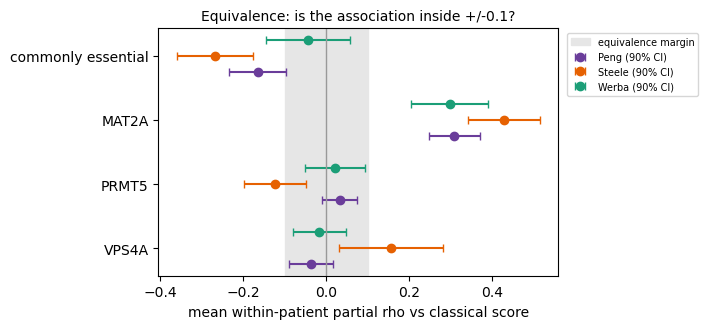

In [57]:
# ==========================================================================
# 28b · EFFECT SIZES ON THE CLASSICAL AXIS   ·   Supplementary Table S4a, Fig. S5
# mean, 95% CI, Wilcoxon p + BH q, SD from the random null, empirical p + BH q, TOST equivalence
# (+/- EQ_MARGIN) with the 90% CI; the classical-axis rows of Supplementary Table S2 and Supplementary Table S9b
#
# WHY BH within cohort over the three targets + commonly-essential control: those four tests make the
# claim on this axis. TOST uses the 90% CI against +/-0.10 (a correlation explaining 1% of variance).
# ==========================================================================

CLASSICAL_TAB = []
for _lab, _res, _null in [("Peng", res, null), ("Steele", s_res, s_null), ("Werba", w_res, w_null)]:
    keys = TARGETS + ["common_essential"]
    rows = [stat_row(k, _res[k], _null) for k in keys]
    qw = bh([r_["p"] for r_ in rows])
    qe = bh([r_["emp_p"] for r_ in rows])
    for r_, a, b in zip(rows, qw, qe):
        tt = tost(_res[r_["label"]])
        CLASSICAL_TAB.append(dict(cohort=_lab, signature=r_["label"], n=r_["n"], mean_rho=r_["mean"],
                       ci95_lo=r_["ci_lo"], ci95_hi=r_["ci_hi"], wilcoxon_p=r_["p"], wilcoxon_q=a,
                       sd_from_random=r_["sd_null"], empirical_p=r_["emp_p"], empirical_q=b,
                       tost_p=tt["p_tost"], ci90_lo=tt["ci90"][0], ci90_hi=tt["ci90"][1],
                       equivalent_within_margin=tt["equivalent"]))
CLASSICAL_TAB = pd.DataFrame(CLASSICAL_TAB)
CLASSICAL_TAB.to_csv(out_path("TableS4a_classical_axis.csv"), index=False)
RESULTS["classical_axis"] = CLASSICAL_TAB.round(5).to_dict(orient="records")
with pd.option_context("display.width", 200, "display.max_columns", 30):
    print(CLASSICAL_TAB.round(4).to_string(index=False))
print("\nequivalence margin +/-{}: 'equivalent_within_margin' True only if the 90% CI is inside it."
      "\nwrote TableS4a_classical_axis.csv".format(EQ_MARGIN))

if FIGURES:
    fig, ax = plt.subplots(figsize=(7.2, 3.4))
    for j, (_lab, col) in enumerate([("Peng", "#6A3D9A"), ("Steele", "#E66101"), ("Werba", "#1B9E77")]):
        g = CLASSICAL_TAB[CLASSICAL_TAB["cohort"] == _lab].reset_index(drop=True)
        y = np.arange(len(g)) + (j - 1) * 0.25
        ax.errorbar(g["mean_rho"], y, xerr=[g["mean_rho"] - g["ci90_lo"], g["ci90_hi"] - g["mean_rho"]],
                    fmt="o", color=col, capsize=3, label="{} (90% CI)".format(_lab))
    ax.axvspan(-EQ_MARGIN, EQ_MARGIN, color="0.9", zorder=0, label="equivalence margin")
    ax.axvline(0, color="0.6", lw=1)
    ax.set_yticks(range(len(TARGETS) + 1)); ax.set_yticklabels(TARGETS + ["commonly essential"])
    ax.set_xlabel("mean within-patient partial rho vs classical score")
    ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0))
    ax.set_title("Equivalence: is the association inside +/-{}?".format(EQ_MARGIN), fontsize=10)
    plt.tight_layout()
    _show("FigS5_equivalence")

## 29 · Dependency controls from the literature, and the positive controls on comparable scales  ·  Supplementary Note, Supplementary Fig. S4

*Methods → Controls; Supplementary Note → Dependency controls from the literature.* The gene-overlap positive controls of section 17 share genes with the programs they are tested against. Here two dependencies reported in the literature as subtype-associated are passed through the **same DepMap-to-single-cell transfer** as the targets (derivation, scoring, within-patient partial correlation):

| control | reported relationship | expected direction against the classical score |
|---|---|---|
| *KRAS* | classical PDAC lines more *KRAS*-dependent than quasi-mesenchymal lines (Collisson et al. 2011) | positive |
| *CDS2* | synthetic-lethal dependency of cells with epithelial-to-mesenchymal transition signatures (Guo et al. 2025) | negative (towards basal) |

*KRAS* has no passenger context, so its signature is derived across all lines and, separately, within PDAC lines; *CDS2* is derived in lines with low expression of its paralog *CDS1*, mirroring the targets. Before the single-cell test, DepMap is checked for the relationship each control relies on, and each control signature goes through the held-out validation of section 26. A control counts as **detected** only if that DepMap relationship holds **and** its single-cell association exceeds the random-gene null with a CI excluding zero in the expected direction. When a control's premise fails in DepMap, the control cannot demonstrate sensitivity whatever it does in single cells; sensitivity is then measured with controls chosen by DepMap (sections 35–38).

**Comparable scales (29b).** The program-restriction values of section 17 are differences in mean score in each score's own units, which scale with each score's spread, so they are not comparable with a partial correlation. They are re-expressed as a **standardised** difference (divided by the within-patient SD of the score) and as a **rank-based** partial correlation with the program score, both with patient-bootstrap CIs, for the gene-overlap controls, the two literature controls and the targets, in all three cohorts (Supplementary Fig. S4).

**Why the premise check comes first.** A positive control can demonstrate sensitivity only if the dependency it relies on actually holds in DepMap; printing the premise beside each control prevents a control whose premise fails from being read as a failure of the approach, or as a success.

In [58]:
# ==========================================================================
# 29a · LITERATURE POSITIVE CONTROLS (KRAS, CDS2) -- DepMap premise, held-out validation, single cells
#
# WHY the DepMap premise is printed beside each control: a control whose premise fails in DepMap
# cannot demonstrate sensitivity, whatever it does in single cells.
# ==========================================================================

CLASSICAL_LINE = line_score(MOFFITT_CLASSICAL)
POS = {}
if "KRAS" in dep.columns:
    POS["KRAS (all lines)"] = ("KRAS", expr.index, +1)
    if IS_PDAC.sum() >= 20:
        POS["KRAS (PDAC lines)"] = ("KRAS", expr.index[IS_PDAC.values], +1)
if "CDS2" in dep.columns and "CDS1" in expr.columns:
    POS["CDS2 (CDS1-low lines)"] = ("CDS2", ctx_quantile("CDS1", LOW_Q), -1)

print("DEPMAP CHECKS FOR THE RELATIONSHIPS THE CONTROLS RELY ON\n")
if "KRAS" in dep.columns and IS_PDAC.sum() >= 10:
    pdl = expr.index[IS_PDAC.values].intersection(dep.index[dep["KRAS"].notna()])
    rho_k, p_k = spearmanr(dep.loc[pdl, "KRAS"], CLASSICAL_LINE.reindex(pdl))
    print("  KRAS Chronos vs line classical score, PDAC lines (n={}): rho {:+.3f}, p = {:.3g}  "
          "(negative = classical lines more KRAS-dependent)".format(len(pdl), rho_k, p_k))
    RESULTS["kras_classical_depmap"] = dict(n=len(pdl), rho=float(rho_k), p=float(p_k))
if "CDS2" in dep.columns:
    al = dep.index[dep["CDS2"].notna()]
    rho_c = spearmanr(dep.loc[al, "CDS2"], EMT_LINE.reindex(al))[0]
    lowc = ctx_quantile("CDS1", LOW_Q).intersection(al)
    p_c = mannwhitneyu(dep.loc[lowc, "CDS2"], dep.loc[al.difference(lowc), "CDS2"])[1]
    print("  CDS2 Chronos vs line EMT score, all lines (n={}): rho {:+.3f}  "
          "(negative = mesenchymal lines more CDS2-dependent)".format(len(al), rho_c))
    print("  CDS2 Chronos, CDS1-low vs other lines: median {:+.3f} vs {:+.3f}, p = {:.2e}".format(
        dep.loc[lowc, "CDS2"].median(), dep.loc[al.difference(lowc), "CDS2"].median(), p_c))
    RESULTS["cds2_depmap"] = dict(rho_emt=float(rho_c), p_cds1low=float(p_c))

# does the relationship each control relies on actually hold in DepMap? (a control whose premise
# fails cannot show sensitivity, whatever it does in single cells)
PREMISE = {}
if "kras_classical_depmap" in RESULTS:
    PREMISE["KRAS"] = RESULTS["kras_classical_depmap"]["rho"] < 0 and RESULTS["kras_classical_depmap"]["p"] < 0.05
if "cds2_depmap" in RESULTS:
    PREMISE["CDS2"] = RESULTS["cds2_depmap"]["rho_emt"] < 0 and RESULTS["cds2_depmap"]["p_cds1low"] < 0.05

print("\nPOSITIVE-CONTROL SIGNATURES THROUGH THE SAME TRANSFER\n")
POS_SIGS, RESULTS["pos_ctrl"] = {}, {}
for name in list(POS):
    gene, lines, sign = POS[name][:3]          # [:3] so re-running this cell is safe
    genes = derive(gene, lines)
    POS_SIGS[name] = genes
    m, s, _, n = cv_eval(gene, lines, lambda tt, L: derive(tt, L))
    print("{} -- {} lines; held-out rho(score, Chronos) {:+.3f}, AUC {:.2f}".format(
        name, n, m["rho"], m["auc_quartile"]))
    col = "pc_" + "".join(ch for ch in name if ch.isalnum())[:16]
    rows = []
    for _lab, _ad, _null in [("Peng", mal, null), ("Steele", steele, s_null), ("Werba", werba, w_null)]:
        score(_ad, genes, col)
        rc = ps_vs(_ad.obs, col)
        rb = ps_vs(_ad.obs, col, state_col="basal_score")
        rows += [stat_row("{} {} vs classical".format(_lab, name), rc, _null),
                 stat_row("{} {} vs basal".format(_lab, name), rb)]
        # detected = the 95% CI excludes zero in the expected direction AND the effect clears
        # the random-gene null (empirical p < 0.05) -- the same bar the targets are held to
        ci_ok = np.sign(mean_rho(rc)) == sign and (rows[-2]["ci_hi"] < 0 if sign < 0 else rows[-2]["ci_lo"] > 0)
        null_ok = rows[-2].get("emp_p", 1.0) < 0.05
        RESULTS["pos_ctrl"]["{}|{}".format(_lab, name)] = dict(
            vs_classical=mean_rho(rc), vs_basal=mean_rho(rb), expected_sign=sign,
            ci_excludes_zero=bool(ci_ok), beyond_random_null=bool(null_ok),
            detected_in_expected_direction=bool(ci_ok and null_ok),
            premise_holds_in_depmap=PREMISE.get(gene), heldout_rho=float(m["rho"]))
    show_rows(rows)
    print("    expected direction vs classical: {} | DepMap premise holds: {}".format(
        "positive" if sign > 0 else "negative",
        {True: "yes", False: "NO", None: "not checked"}[PREMISE.get(gene)]))
    for l_ in ["Peng", "Steele", "Werba"]:
        r_ = RESULTS["pos_ctrl"]["{}|{}".format(l_, name)]
        print("    {:<7} CI excludes zero: {:<4} beyond random null: {:<4} -> detected: {}".format(
            l_, "yes" if r_["ci_excludes_zero"] else "no", "yes" if r_["beyond_random_null"] else "no",
            "YES" if r_["detected_in_expected_direction"] else "no"))
    print()
    POS[name] = (gene, lines, sign, col)

DEPMAP CHECKS FOR THE RELATIONSHIPS THE CONTROLS RELY ON

  KRAS Chronos vs line classical score, PDAC lines (n=44): rho +0.066, p = 0.669  (negative = classical lines more KRAS-dependent)
  CDS2 Chronos vs line EMT score, all lines (n=1140): rho -0.398  (negative = mesenchymal lines more CDS2-dependent)
  CDS2 Chronos, CDS1-low vs other lines: median -0.637 vs -0.174, p = 1.60e-81

POSITIVE-CONTROL SIGNATURES THROUGH THE SAME TRANSFER

KRAS (all lines) -- 1140 lines; held-out rho(score, Chronos) -0.277, AUC 0.72
                                             n     neg      mean    95% CI (patients)         p      SD    emp p
  Peng KRAS (all lines) vs classical        24    0/24   +0.7242   [+0.6821, +0.7634]    0.0000    +8.3   0.0010
  Peng KRAS (all lines) vs basal            24    8/24   +0.0669   [-0.0189, +0.1483]    0.0691                 
  Steele KRAS (all lines) vs classical      14    0/14   +0.7411   [+0.6852, +0.7882]    0.0001    +7.5   0.0010
  Steele KRAS (all lines) vs 

cohort                 score     program  raw_diff  std_diff  std_lo  std_hi  rank_rho  rank_lo  rank_hi  n
  Peng         proliferation 4_cellcycle    0.2108    0.9576  0.8296  1.0864    0.4941   0.4251   0.5581 24
  Peng       classical score 8_classical    0.3509    1.0716  0.9652  1.1798    0.6396   0.5882   0.6876 24
  Peng                 VPS4A 8_classical    0.0047    0.0859 -0.0284  0.1997    0.1038   0.0440   0.1630 24
  Peng                 PRMT5 8_classical   -0.0082   -0.1863 -0.2688 -0.1084   -0.0791  -0.1257  -0.0343 24
  Peng                 MAT2A 8_classical    0.0292    0.5264  0.4191  0.6420    0.3652   0.3130   0.4184 24
  Peng      KRAS (all lines) 8_classical    0.0940    0.8592  0.7468  0.9770    0.5448   0.4877   0.5986 24
  Peng     KRAS (PDAC lines) 8_classical    0.0067    0.2266  0.1365  0.3237    0.1493   0.0983   0.1996 24
  Peng CDS2 (CDS1-low lines)     7_basal   -0.0990   -0.8419 -0.9273 -0.7535   -0.5424  -0.5857  -0.4946 24
Steele         proliferation

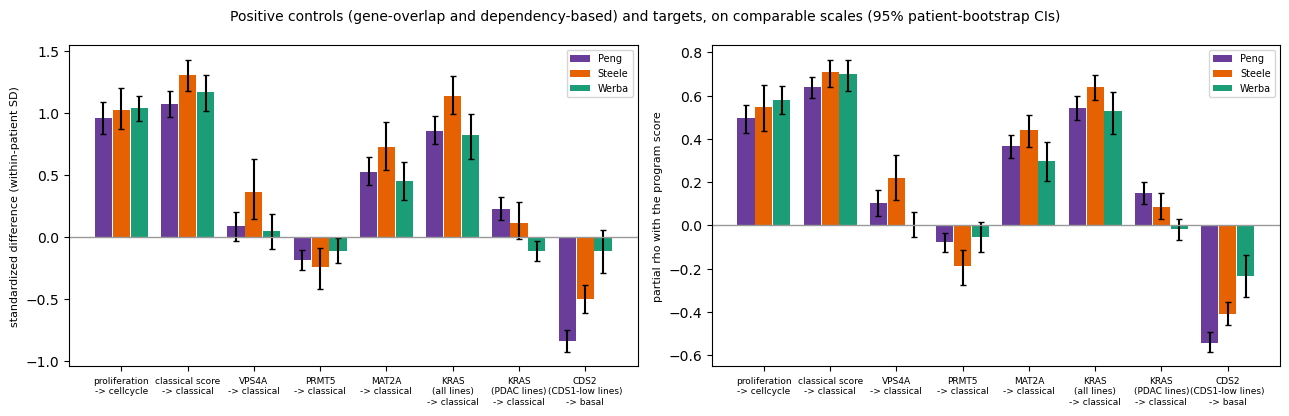

In [59]:
# ==========================================================================
# 29b · POSITIVE CONTROLS AND TARGETS ON COMPARABLE SCALES   ·   Supplementary Fig. S4
# raw (original units), standardized, and rank-based. Steele and Werba program scores are computed
# here (section 12 scored programs in Peng only).
#
# WHY re-express section 17's axis: raw score differences scale with each score's spread, so they are
# not comparable across signatures; standardised and rank versions are.
# ==========================================================================

for i, pname in enumerate(PROG_NAMES):
    top = [prog_genes[j] for j in np.argsort(programs[i])[::-1][:30] if prog_genes[j] in sraw]
    sc.tl.score_genes(steele, top, score_name="prog_" + pname, use_raw=True)
    top_w = [prog_genes[j] for j in np.argsort(programs[i])[::-1][:30] if prog_genes[j] in wraw]
    sc.tl.score_genes(werba, top_w, score_name="prog_" + pname, use_raw=True)


def program_restriction_std(obs, score_col, program, min_cells=MIN_CELLS):
    col = "prog_" + program
    raw_d, std_d = {}, {}
    for pat, g in obs.groupby("Patient", observed=True):
        if len(g) < min_cells:
            continue
        thr = g[col].quantile(0.66)
        hi, lo = g.loc[g[col] >= thr, score_col], g.loc[g[col] < thr, score_col]
        if len(hi) >= 10 and len(lo) >= 10:
            raw_d[pat] = hi.mean() - lo.mean()
            std_d[pat] = (hi.mean() - lo.mean()) / g[score_col].std()
    return raw_d, std_d


PC_SCALE_ROWS = [("proliferation", "prolif", "4_cellcycle"),
         ("classical score", "classical_score", CLASSICAL_PROG)]
PC_SCALE_ROWS += [(t, t + "_sig", CLASSICAL_PROG) for t in TARGETS]
for name, (gene, lines, sign, col) in POS.items():
    # each dependency control is tested against the program of the state it should mark
    PC_SCALE_ROWS.append((name, col, CLASSICAL_PROG if sign > 0 else "7_basal"))

PC_SCALES = []
for _lab, _ad in [("Peng", mal), ("Steele", steele), ("Werba", werba)]:
    for name, scol, prog in PC_SCALE_ROWS:
        rd, sd_ = program_restriction_std(_ad.obs, scol, prog)
        rk = ps_vs(_ad.obs, scol, state_col="prog_" + prog)
        a, b, c = stat_row("", rd), stat_row("", sd_), stat_row("", rk)
        PC_SCALES.append(dict(cohort=_lab, score=name, program=prog, raw_diff=a["mean"],
                       std_diff=b["mean"], std_lo=b["ci_lo"], std_hi=b["ci_hi"],
                       rank_rho=c["mean"], rank_lo=c["ci_lo"], rank_hi=c["ci_hi"], n=b["n"]))
PC_SCALES = pd.DataFrame(PC_SCALES)
PC_SCALES.to_csv(out_path("FigS4_positive_controls_scales.csv"), index=False)
RESULTS["positive_controls_scales"] = PC_SCALES.round(4).to_dict(orient="records")
print(PC_SCALES.round(4).to_string(index=False))

if FIGURES:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    for ax, (val, lo, hi, lab) in zip(axes, [("std_diff", "std_lo", "std_hi", "standardized difference (within-patient SD)"),
                                             ("rank_rho", "rank_lo", "rank_hi", "partial rho with the program score")]):
        g = PC_SCALES[PC_SCALES["cohort"] == "Peng"].reset_index(drop=True)
        gs_ = PC_SCALES[PC_SCALES["cohort"] == "Steele"].reset_index(drop=True)
        gw_ = PC_SCALES[PC_SCALES["cohort"] == "Werba"].reset_index(drop=True)
        x = np.arange(len(g))
        for off, gg, colr, cl in [(-0.27, g, "#6A3D9A", "Peng"), (0.0, gs_, "#E66101", "Steele"),
                                  (0.27, gw_, "#1B9E77", "Werba")]:
            ax.bar(x + off, gg[val], 0.26, color=colr, label=cl,
                   yerr=[gg[val] - gg[lo], gg[hi] - gg[val]], capsize=2)
        ax.axhline(0, color="0.6", lw=1)
        ax.set_xticks(x)
        ax.set_xticklabels(["{}\n-> {}".format(s_.replace(" (", "\n("), p_.split("_", 1)[-1])
                            for s_, p_ in zip(g["score"], g["program"])],
                           fontsize=6.5)
        ax.set_ylabel(lab, fontsize=8)
        ax.legend(fontsize=7)
    fig.suptitle("Positive controls (gene-overlap and dependency-based) and targets, "
                 "on comparable scales (95% patient-bootstrap CIs)", fontsize=10)
    plt.tight_layout()
    _show("FigS4_positive_controls_scales")

# Part VI · Both subtype axes and the robustness of the two associations

*Methods → Malignant compartment and subtype scoring; Analysis of the basal score; Robustness tests; Statistical analysis. Results → Association of the VPS4A signature with the basal state; Robustness of the MAT2A association with the classical state.* The classical and basal scores are computed from separate gene lists and are not a single axis in every cohort, so each signature is tested against both. The one association found on the basal axis is put through a battery of nulls and robustness tests, the *MAT2A* association is collected under every test, and multiple testing is corrected across both axes.

## 30 · Both subtype scores modelled explicitly  ·  Supplementary Table S2, Fig. 5a, Supplementary Fig. S6

*Methods → Malignant compartment and subtype scoring; Analysis of the basal score.* The classical and basal scores are computed independently per cell (sections 6–8) from separate gene lists. They are moderately anti-correlated in Peng et al. and nearly independent in Steele et al. and Werba et al., so a classical-high cell need not be basal-low. This section tests every signature against the **basal** score; the classical association **adjusted for the basal score** and the reverse; the classical-minus-basal difference as an axis; and, if supplied, the published single-cell scClassical and scBasal signatures of Raghavan et al. as the axis (30a). It then splits each patient's cells into four groups at that patient's medians of the two scores (classical-only, basal-only, dual-high, dual-low) and reports the cell and patient counts and the *MAT2A* signature score in each (30b, Supplementary Fig. S6).

Section 30a found an association the classical-axis analysis did not test for: the *VPS4A* signature rises with the basal score. Section 31 puts it through the full battery.

**Why split at each patient's own medians.** Every patient then contributes cells to every group, so group differences cannot come from differences between patients.

In [60]:
# ==========================================================================
# 30a · SIGNATURES vs BASAL, CLASSICAL | BASAL, CLASSICAL - BASAL, RAGHAVAN AXES
#
# WHY: the two scores are not one axis in Steele et al. (nearly independent), so every signature is tested
# against each score, with the other as a covariate, and against published single-cell signatures.
# ==========================================================================

for _ad in (mal, steele, werba):
    _ad.obs["cls_minus_bas"] = _ad.obs["classical_score"] - _ad.obs["basal_score"]

_rag_cls = next((PRG_COL["Raghavan " + k] for k in RAGH if "class" in k.lower()), None)
_rag_bas = next((PRG_COL["Raghavan " + k] for k in RAGH if "basal" in k.lower()), None)
RESULTS["axis"] = {}
for _lab, _ad, _null in [("Peng", mal, null), ("Steele", steele, s_null), ("Werba", werba, w_null)]:
    print("\n{} -- {} cells; classical vs basal rho {:+.3f}\n".format(
        _lab, _ad.n_obs, spearmanr(_ad.obs["classical_score"], _ad.obs["basal_score"])[0]))
    rows = []
    for col in SIG_COLS:
        tests = [("vs classical (original)", ps_vs(_ad.obs, col)),
                 ("vs classical | basal adjusted", ps_vs(_ad.obs, col, covars=QC_COVARS + ["basal_score"])),
                 ("vs basal", ps_vs(_ad.obs, col, state_col="basal_score")),
                 ("vs basal | classical adjusted", ps_vs(_ad.obs, col, state_col="basal_score",
                                                         covars=QC_COVARS + ["classical_score"])),
                 ("vs classical minus basal", ps_vs(_ad.obs, col, state_col="cls_minus_bas"))]
        if _rag_cls:
            tests.append(("vs Raghavan scClassical", ps_vs(_ad.obs, col, state_col=_rag_cls)))
        if _rag_bas:
            tests.append(("vs Raghavan scBasal", ps_vs(_ad.obs, col, state_col=_rag_bas)))
        for tname, r in tests:
            rows.append(stat_row("{} {}".format(col.replace("_sig", ""), tname), r,
                                _null if tname.startswith("vs classical (") else None))
            RESULTS["axis"]["{}|{}|{}".format(_lab, col, tname)] = r
    show_rows(rows)


Peng -- 11280 cells; classical vs basal rho -0.451

                                             n     neg      mean    95% CI (patients)         p      SD    emp p
  VPS4A vs classical (original)             24   15/24   -0.0365   [-0.0933, +0.0229]    0.1515    -0.6   0.4915
  VPS4A vs classical | basal adjusted       24   13/24   -0.0100   [-0.0660, +0.0442]    0.7898                 
  VPS4A vs basal                            24    0/24   +0.2944   [+0.2484, +0.3417]    0.0000                 
  VPS4A vs basal | classical adjusted       24    0/24   +0.2888   [+0.2436, +0.3357]    0.0000                 
  VPS4A vs classical minus basal            24   19/24   -0.1439   [-0.2057, -0.0814]    0.0005                 
  VPS4A vs Raghavan scClassical             24   14/24   -0.0190   [-0.0789, +0.0458]    0.2768                 
  VPS4A vs Raghavan scBasal                 24    0/24   +0.2769   [+0.2355, +0.3180]    0.0000                 
  PRMT5 vs classical (original)            


Peng -- dual-score groups (patients with >= 50 cells)

                cells  patients_with_>=10_cells  MAT2A_z_mean
subtype_group                                                
classical-only   3250                        24         0.120
basal-only       3250                        24        -0.040
dual-high        2376                        24         0.304
dual-low         2388                        24        -0.411
  dual-high minus basal-only MAT2A z (per patient): mean +0.482, 22/24 positive, p = 0.0000

Steele -- dual-score groups (patients with >= 50 cells)

                cells  patients_with_>=10_cells  MAT2A_z_mean
subtype_group                                                
classical-only   2136                        14         0.147
basal-only       2136                        14        -0.053
dual-high        2811                        14         0.515
dual-low         2819                        14        -0.585
  dual-high minus basal-only MAT2A z (per patient)

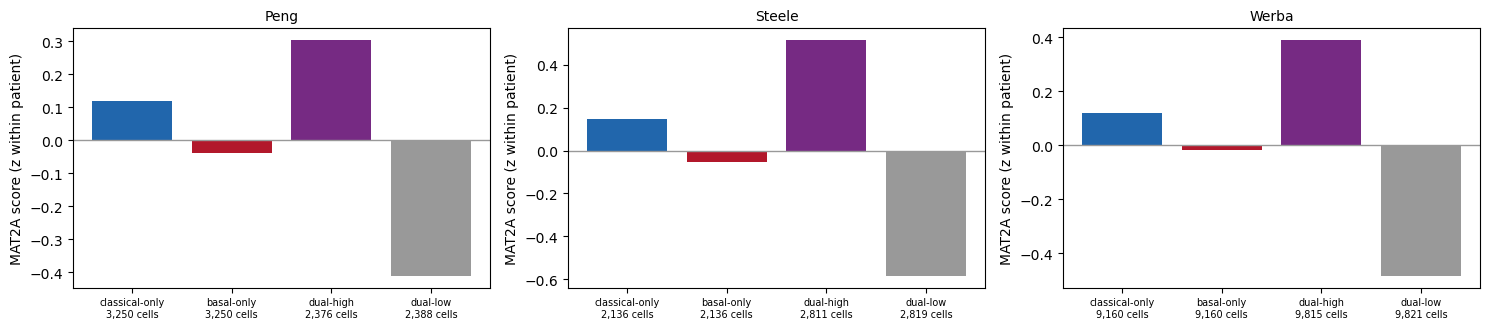

In [61]:
# ==========================================================================
# 30b · DUAL-SCORE GROUPS -- cells and patients per group, MAT2A score per group   ·   Fig. S6
# Split at each patient's median of each score; MAT2A as a within-patient z-score.
#
# WHY split at each patient's own medians: every patient contributes cells to every group, so group
# differences cannot come from differences between patients.
# ==========================================================================

GRP = ["classical-only", "basal-only", "dual-high", "dual-low"]
RESULTS["dual_groups"] = {}
if FIGURES:
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
for j, (_lab, _ad) in enumerate([("Peng", mal), ("Steele", steele), ("Werba", werba)]):
    o = _ad.obs
    ch = o.groupby("Patient", observed=True)["classical_score"].transform(lambda v: v > v.median())
    bh_ = o.groupby("Patient", observed=True)["basal_score"].transform(lambda v: v > v.median())
    grp = np.where(ch & ~bh_, "classical-only", np.where(~ch & bh_, "basal-only",
                   np.where(ch & bh_, "dual-high", "dual-low")))
    o["subtype_group"] = pd.Categorical(grp, categories=GRP)
    z = o.groupby("Patient", observed=True)["MAT2A_sig"].transform(lambda v: (v - v.mean()) / v.std())
    # cells per patient, as a plain number for every cell (Patient may be categorical)
    pats_ok = o.groupby("Patient", observed=True)["MAT2A_sig"].transform("size") >= MIN_CELLS
    tab = pd.DataFrame({
        "cells": o.loc[pats_ok, "subtype_group"].value_counts().reindex(GRP),
        "patients_with_>=10_cells": [int((o.loc[pats_ok & (o["subtype_group"] == g_)]
                                          .groupby("Patient", observed=True).size() >= 10).sum()) for g_ in GRP],
        "MAT2A_z_mean": [float(z[pats_ok & (o["subtype_group"] == g_)].mean()) for g_ in GRP]})
    # per-patient group means, so each patient counts once
    pm = pd.DataFrame({"z": z, "g": o["subtype_group"], "p": o["Patient"]})[pats_ok.values]
    pm = pm.groupby(["p", "g"], observed=True)["z"].mean().unstack()
    print("\n{} -- dual-score groups (patients with >= {} cells)\n".format(_lab, MIN_CELLS))
    print(tab.round(3).to_string())
    if {"dual-high", "basal-only"} <= set(pm.columns):
        d = (pm["dual-high"] - pm["basal-only"]).dropna()
        print("  dual-high minus basal-only MAT2A z (per patient): mean {:+.3f}, {}/{} positive, p = {:.4f}".format(
            d.mean(), int((d > 0).sum()), len(d), wilcoxon(d)[1] if len(d) >= 5 else np.nan))
    RESULTS["dual_groups"][_lab] = tab.round(4).to_dict(orient="index")
    if FIGURES:
        ax = axes[j]
        ax.bar(range(4), tab["MAT2A_z_mean"], color=["#2166AC", "#B2182B", "#762A83", "0.6"])
        ax.set_xticks(range(4))
        ax.set_xticklabels(["{}\n{:,} cells".format(g_, int(c_)) for g_, c_ in zip(GRP, tab["cells"].fillna(0))], fontsize=7)
        ax.axhline(0, color="0.6", lw=1)
        ax.set_ylabel("MAT2A score (z within patient)")
        ax.set_title(_lab, fontsize=10)
if FIGURES:
    plt.tight_layout()
    _show("FigS6_dual_score_groups")

## 31 · The VPS4A–basal association: nulls, robustness tests and supporting evidence  ·  Table 1, Fig. 5, Supplementary Tables S7–S8

*Methods → Analysis of the basal score; Robustness tests. Results → Association of the VPS4A signature with the basal state.* The *VPS4A* signature, which is not separated from the random-gene null on the classical axis, rises with the basal score (section 30a), and it is the only signature that predicts measured dependency well in held-out DepMap lines (section 26). An association found during the analysis needs at least the battery the *MAT2A* association went through. Because the *MAT2A* signature turned out to track epithelial identity (section 27), and several of the *VPS4A* signature's top genes suggest a mesenchymal component, this battery also tests mesenchymal identity directly.

**This association was not anticipated.** It was found in section 30a, and every test below was specified after it had been seen; the manuscript reports it accordingly. The decision rule is that of Supplementary Table S6: an effect **persists** when its 95% patient-bootstrap CI excludes zero with the same sign as the full model. For every covariate and gene-removal test the fraction of the full-model effect that is **retained** is printed, and those tests must retain at least one-third of it (`VB_MIN_KEPT = 0.33`; `None` applies the persistence rule alone).

| test | challenge | required to pass |
|---|---|---|
| **Random-gene null** | random sets of the signature's size on the basal axis | ≥ 2 SD above the null mean, empirical p < 0.05 |
| **Expression-matched null** | each signature gene swapped for one of similar mean expression | ≥ 2 SD, empirical p < 0.05 |
| **Variability/detection-matched null** | matched on mean, variance and detection rate | ≥ 2 SD, empirical p < 0.05 |
| **Covariance-matched null** | random sets with the signature's mean gene–gene correlation | ≥ 2 SD, empirical p < 0.05 |
| **Head-to-head** | *VPS4A* minus the commonly essential control, per patient | *VPS4A* higher, Wilcoxon p < 0.05 |
| **Classical adjustment** | classical score as a covariate | persists, retains at least one-third |
| **Circularity** | genes shared with the Moffitt et al. basal list or Raghavan et al. scBasal removed | persists, retains at least one-third |
| **Proliferation** | proliferation score as a covariate | persists, retains at least one-third |
| **Program adjustment** | mesenchymal (MSigDB Hallmark EMT), fibroblast, epithelial and secretory programs as covariates, singly and together | persists, retains at least one-third |
| **Mesenchymal-gene removal** | mesenchymal-identity genes dropped, and excluded before derivation (refilled) | both persist, retain at least one-third |
| **Single gene** | each gene dropped in turn | no gene shifts the mean by more than 30% |
| **Scoring method** | rank-based scoring | persists |
| **Published axis** | Raghavan et al. scBasal as the state score | persists |
| **Derivation** | lineage held constant; other cut-offs; *VPS4B* copy-loss lines | lineage-held persists; at least three-quarters of the others persist |
| **High-confidence malignant cells** | CNV-positive, not doublet-flagged cells only (section 23) | persists |
| **Doublet-flagged cells removed** | the flags of section 22 removed | persists |

*Supporting, not required (31c):* whether basal-like **cell lines** are more *VPS4A*-dependent in DepMap, with and without lineage and the epithelial–mesenchymal score held constant (Supplementary Table S8); how many of the signature's genes individually rise with the basal score (Fig. 5c); and whether the mesenchymal-free signatures still predict *VPS4A* dependency in held-out lines. The commonly essential control and the other targets on the basal axis are printed alongside for scale. Section 31c also draws a diagnostic view of the battery; the manuscript version is Fig. 5 (section 47).

**On the one-third retention bar.** It was set after the association was observed, as stated above and in the manuscript. The retained fraction is printed for every test, so a reader can apply any other bar.

In [62]:
# ==========================================================================
# 31a · VPS4A ON THE BASAL AXIS -- THE FOUR NULLS (cached per cohort)   ·   Supplementary Table S2, Fig. 5b
# One scoring pass per null gene set, evaluated on two axes at once: the basal score, and the
# basal score with the classical score as an extra covariate. FastPS gives exactly ps_vs's
# numbers (checked below) but ranks the state and builds the covariate projection once per
# patient, so each null set costs one scoring and one ranking. ~10-30 min per cohort at
# VB_N_NULL = 1000; cached, so a RECOMPUTE = False re-run reads it back.
#
# WHY four nulls rebuilt on the basal axis: the VPS4A association is held to the same nulls as MAT2A,
# recomputed on the axis it was found on. POST HOC: this battery was specified after the association
# was observed in §30a, and the manuscript says so.
# ==========================================================================

VB_N_NULL = N_NULL                        # null sets per null type (1,000, as on the classical axis)
VB_MIN_KEPT = 0.33                        # covariate / gene-removal tests must keep at least this
                                           # fraction of the full-model effect (None = Table 1's rule,
                                           # the effect persists, alone)
VB_TARGET = "VPS4A"
VB_AXES = {"basal": ("basal_score", QC_COVARS),
            "basal | classical adjusted": ("basal_score", QC_COVARS + ["classical_score"])}


class FastPS:
    """ps_vs for many score vectors against ONE state column and covariate set. Per patient
    the design [1, ranked covariates], its pseudo-inverse and the residualised state ranks are
    computed once; a new score then costs one ranking and one projection."""

    def __init__(self, obs, state_col, covars=None, min_cells=MIN_CELLS):
        covars = QC_COVARS if covars is None else covars
        self.parts = []
        for pat, g in obs.groupby("Patient", observed=True):
            if len(g) < min_cells:
                continue
            X = np.column_stack([np.ones(len(g))] + [rankdata(g[q].values) for q in covars])
            P = np.linalg.pinv(X)
            c = rankdata(g[state_col].values)
            rc = c - X @ (P @ c)
            if rc.std() < 1e-9:
                continue
            self.parts.append((pat, obs.index.get_indexer(g.index), X, P, rc))

    def __call__(self, values):
        out = {}
        for pat, idx, X, P, rc in self.parts:
            y = rankdata(values[idx])
            ry = y - X @ (P @ y)
            if ry.std() < 1e-9:
                continue
            out[pat] = float(np.corrcoef(ry, rc)[0, 1])
        return out


def random_sets(present, size, n, seed):
    """Random gene sets of the signature's size, from the sorted gene universe (section 15)."""
    r = np.random.default_rng(seed)
    pool = sorted(present)
    return [sorted(r.choice(pool, size=size, replace=False)) for _ in range(n)]


def expression_matched_sets(ad, template, n, seed):
    """Section 15's expression-matched null, as gene sets: each template gene is swapped for a
    random gene whose mean expression is within +/-20% of its own."""
    r = np.random.default_rng(seed)
    gm = pd.Series(np.asarray(ad.raw.X.mean(axis=0)).ravel(), index=[str(g) for g in ad.raw.var_names])
    cands = {g: gm[(gm > gm[g] * 0.8) & (gm < gm[g] * 1.2)].index for g in template if g in gm.index}
    out = []
    for _ in range(n):
        picked = [str(r.choice(c)) for g, c in cands.items() if len(c)]
        out.append(sorted(set(picked)))
    return out


def score_sets(ad, sets, fps, label=""):
    """Score every gene set once; the mean within-patient rho on every axis in fps."""
    out = {k: np.empty(len(sets)) for k in fps}
    t0 = time.time()
    for i, gs in enumerate(sets):
        sc.tl.score_genes(ad, gs, score_name="_n8", use_raw=True)
        v = ad.obs["_n8"].values
        for k, f in fps.items():
            out[k][i] = mean_rho(f(v))
        if (i + 1) % 250 == 0:
            print("      {} {}/{} ({:.0f} s)".format(label, i + 1, len(sets), time.time() - t0))
    del ad.obs["_n8"]
    return out


VB_NULL_KINDS = ["random", "expression-matched", "variability/detection-matched", "covariance-matched"]
VB = {"nulls": {}, "fps": {}}
for _lab, _ad, _present in [("Peng", mal, raw), ("Steele", steele, sraw), ("Werba", werba, wraw)]:
    fps = {k: FastPS(_ad.obs, s_, c_) for k, (s_, c_) in VB_AXES.items()}
    VB["fps"][_lab] = fps
    # guard: FastPS must reproduce ps_vs exactly
    _a = mean_rho(fps["basal"](_ad.obs[VB_TARGET + "_sig"].values))
    _b = mean_rho(ps_vs(_ad.obs, VB_TARGET + "_sig", state_col="basal_score"))
    assert abs(_a - _b) < 1e-9, "FastPS does not reproduce ps_vs ({} vs {})".format(_a, _b)
    tmpl = [g for g in signatures[VB_TARGET] if g in _present]
    cache = out_path("vps4a_basal_nulls_{}.npz".format(_lab.lower()))
    if need_compute(cache):
        print("{}: {} null sets of each kind, {} genes per set".format(_lab, VB_N_NULL, len(tmpl)))
        makers = {"random": lambda: random_sets(_present, len(tmpl), VB_N_NULL, SEED + 21),
                  "expression-matched": lambda: expression_matched_sets(_ad, tmpl, VB_N_NULL, SEED + 22),
                  "variability/detection-matched": lambda: variability_matched_sets(_ad, tmpl, VB_N_NULL, seed=SEED + 23),
                  "covariance-matched": lambda: covariance_matched_sets(_ad, tmpl, VB_N_NULL, seed=SEED + 24)}
        store = {}
        for kind in VB_NULL_KINDS:
            print("    {} ...".format(kind))
            res_k = score_sets(_ad, makers[kind](), fps, label=kind)
            for ax_, arr in res_k.items():
                store["{}__{}".format(kind, ax_)] = arr
        np.savez(cache, **store)
    z = np.load(cache)
    VB["nulls"][_lab] = {(k.split("__")[0], k.split("__")[1]): z[k] for k in z.files}

# observed values and distance from each null
VB["observed"] = {}
NULL_TAB = []
for _lab, _ad in [("Peng", mal), ("Steele", steele), ("Werba", werba)]:
    for ax_ in VB_AXES:
        obs_v = mean_rho(VB["fps"][_lab][ax_](_ad.obs[VB_TARGET + "_sig"].values))
        VB["observed"][(_lab, ax_)] = obs_v
        for kind in VB_NULL_KINDS:
            nd = VB["nulls"][_lab][(kind, ax_)]
            sd_ = sd_from(obs_v, nd)
            NULL_TAB.append(dict(cohort=_lab, axis=ax_, null=kind, observed=obs_v, null_mean=nd.mean(),
                                 null_sd=nd.std(), sd=sd_, emp_p=emp_p(obs_v, nd),
                                 passes=bool(sd_ >= 2 and emp_p(obs_v, nd) < 0.05)))
NULL_TAB = pd.DataFrame(NULL_TAB)
NULL_TAB.to_csv(out_path("vps4a_basal_nulls.csv"), index=False)

# every signature on the basal axis, against the same random null (the null is signature-size
# matched, not signature-specific, so it serves all four, as section 15's does on the classical axis)
print("\nEVERY SIGNATURE vs BASAL SCORE -- distance from the basal-axis random null (Supplementary Table S2, lower rows)\n")
BASAL_TAB = []
for _lab, _ad in [("Peng", mal), ("Steele", steele), ("Werba", werba)]:
    nd = VB["nulls"][_lab][("random", "basal")]
    for col in SIG_COLS:
        r_ = stat_row(col, ps_vs(_ad.obs, col, state_col="basal_score"), nd)
        BASAL_TAB.append(dict(cohort=_lab, signature=col.replace("_sig", ""), n=r_["n"], mean=r_["mean"],
                             ci_lo=r_["ci_lo"], ci_hi=r_["ci_hi"], p=r_["p"], sd_from_random=r_["sd_null"],
                             emp_p=r_["emp_p"]))
BASAL_TAB = pd.DataFrame(BASAL_TAB)
BASAL_TAB.to_csv(out_path("Table1_basal_axis_rows.csv"), index=False)
RESULTS["basal_axis"] = BASAL_TAB.round(4).to_dict(orient="records")
print(BASAL_TAB.round(4).to_string(index=False))
print("\nVPS4A SIGNATURE vs BASAL SCORE -- distance from each null (required: the 'basal' axis)\n")
with pd.option_context("display.width", 200):
    print(NULL_TAB.round(4).to_string(index=False))

Peng: 1000 null sets of each kind, 96 genes per set
    random ...
      random 250/1000 (106 s)
      random 500/1000 (211 s)
      random 750/1000 (317 s)
      random 1000/1000 (422 s)
    expression-matched ...
      expression-matched 250/1000 (113 s)
      expression-matched 500/1000 (222 s)
      expression-matched 750/1000 (331 s)
      expression-matched 1000/1000 (440 s)
    variability/detection-matched ...
      variability/detection-matched 250/1000 (109 s)
      variability/detection-matched 500/1000 (218 s)
      variability/detection-matched 750/1000 (327 s)
      variability/detection-matched 1000/1000 (437 s)
    covariance-matched ...
    covariance target +0.0187; null sets within +/-0.005 of it: 100% (median gap 0.0049)
      covariance-matched 250/1000 (106 s)
      covariance-matched 500/1000 (212 s)
      covariance-matched 750/1000 (318 s)
      covariance-matched 1000/1000 (424 s)
Steele: 1000 null sets of each kind, 96 genes per set
    random ...
      rando

In [63]:
# ==========================================================================
# 31b · VPS4A ON THE BASAL AXIS -- ROBUSTNESS TESTS   ·   Table 1, Supplementary Table S7
# Every test is named; each row: per-patient rhos -> mean, 95% patient-bootstrap CI, Wilcoxon p,
# and the fraction of the full-model effect kept. Pass rules are the ones fixed in the table.
#
# WHY these tests: each removes one alternative explanation (classical score, proliferation,
# mesenchymal/fibroblast/epithelial/secretory programs, shared genes, mesenchymal-identity genes,
# scoring method, published axis, derivation choices, non-malignant cells, doublets). The fraction
# of the effect retained is printed for every test so any bar can be applied.
# ==========================================================================

_sigcol = VB_TARGET + "_sig"
_ctx_v = ctx_quantile(TARGET_CONTEXT[VB_TARGET], LOW_Q)

# ---- gene sets the tests need, fixed without looking at the single-cell result -------------
BASAL_REF = set(MOFFITT_BASAL) | set(next((v for k, v in RAGH.items() if "basal" in k.lower()), []))
CLASS_REF = set(MOFFITT_CLASSICAL) | set(next((v for k, v in RAGH.items() if "class" in k.lower()), []))
_hall = []
if LIBS is not None:
    _hk = [k for k in LIBS.get("MSigDB_Hallmark_2020", {}) if "epithelial mesenchymal" in k.lower()]
    _hall = sorted(set(LIBS["MSigDB_Hallmark_2020"][_hk[0]])) if _hk else []
MESENCHYMAL_PROGRAM = _hall if _hall else EMT_MARKERS
# mesenchymal identity, defined the way §27c defines epithelial identity: |rho| > EPI_CORR_MAX
# with the DepMap EMT-marker score across all lines, plus the marker genes themselves
_emt_corr = corr_with(expr, EMT_LINE.values)
MES_IDENTITY = set(_emt_corr.index[_emt_corr.abs() > EPI_CORR_MAX]) | set(EMT_MARKERS) | set(_hall)
_vsig = signatures[VB_TARGET]
print("{} signature: {} genes | shared with basal references: {} | with classical references: {}".format(
    VB_TARGET, len(_vsig), sorted(set(_vsig) & BASAL_REF) or "none", sorted(set(_vsig) & CLASS_REF) or "none"))
print("mesenchymal program: {} ({} genes) | mesenchymal-identity genes: {:,}, of which in the signature: {} -> {}".format(
    "MSigDB Hallmark EMT" if _hall else "EMT_MARKERS", len(MESENCHYMAL_PROGRAM), len(MES_IDENTITY),
    len(set(_vsig) & MES_IDENTITY), ", ".join(sorted(set(_vsig) & MES_IDENTITY))))

# fibroblast program = section 9's 2_CAF program (top 30 genes), scored the same way in every cohort
_caf_i = PROG_NAMES.index("2_CAF")
_caf_top = [prog_genes[j] for j in np.argsort(programs[_caf_i])[::-1][:30]]
VB_PROG = {"mesenchymal": "r8c_mesenchymal", "fibroblast (2_CAF)": "r8c_fibroblast"}
for _ad in (mal, steele, werba):
    score(_ad, MESENCHYMAL_PROGRAM, "r8c_mesenchymal")
    score(_ad, _caf_top, "r8c_fibroblast")
for n_ in ("epithelial differentiation", "secretory (exocytosis)", "epithelial identity markers"):
    if n_ in PRG_COL:
        VB_PROG[n_] = PRG_COL[n_]

# alternative signatures (DepMap side; the same for every cohort)
_mes_dropped = [g for g in _vsig if g not in MES_IDENTITY]
_mes_refilled = derive(VB_TARGET, _ctx_v, exclude=MES_IDENTITY)
_circ_free = [g for g in _vsig if g not in BASAL_REF]
_lin_held = derive(VB_TARGET, _ctx_v, lineage_held=True)
_other_deriv = {}
for _vname, (_fn, _kw) in VARIANTS.items():
    if _vname.startswith("original") or "lineage" in _vname or "intact" in _vname:
        continue                                  # intact lines are the opposite context, not a derivation of it
    _ctx = _fn(TARGET_CONTEXT[VB_TARGET])
    if _n_ctx(VB_TARGET, _ctx) >= MIN_CTX_LINES:
        _other_deriv[_vname] = derive(VB_TARGET, _ctx, **_kw)


def _rescored(ad, genes, covars=None, state="basal_score", cells=None):
    """Score a gene list, test it against the basal axis, clean up."""
    score(ad, genes, "_r8")
    o = ad.obs if cells is None else ad.obs[cells]
    r = ps_vs(o, "_r8", state_col=state, covars=covars)
    del ad.obs["_r8"]
    return r


def _summ(r, full_mean=None):
    v = _vals(r)
    if len(v) < 3:
        return dict(n=len(v), mean=np.nan, lo=np.nan, hi=np.nan, p=np.nan, kept=np.nan)
    lo, hi = boot_ci(v)
    return dict(n=len(v), mean=float(v.mean()), lo=lo, hi=hi, p=float(wilcoxon(v)[1]),
                kept=float(v.mean() / full_mean) if full_mean else np.nan)


def _persists(s):
    return bool(np.isfinite(s["mean"]) and s["lo"] > 0 and s["p"] < 0.05)


def _retains(s):
    """Persists, plus the optional kept-fraction bar VB_MIN_KEPT (None = Table 1's rule only)."""
    return _persists(s) and (VB_MIN_KEPT is None or s["kept"] >= VB_MIN_KEPT)


VB_ROWS = []          # one row per (cohort, test, variant)
for _lab, _ad, _null in [("Peng", mal, null), ("Steele", steele, s_null), ("Werba", werba, w_null)]:
    o = _ad.obs
    full = ps_vs(o, _sigcol, state_col="basal_score")
    fm = mean_rho(full)

    def add(test, variant, r, rule, required=True, note="", show_kept=True):
        s = _summ(r, fm if show_kept else None) if r is not None else \
            dict(n=0, mean=np.nan, lo=np.nan, hi=np.nan, p=np.nan, kept=np.nan)
        if r is None:
            status = "not run"
        elif len(r) < 3:                          # too few patients with enough cells to test
            status, note = "not run", (note + "; " if note else "") + "fewer than 3 patients with >= {} cells".format(MIN_CELLS)
        elif rule == "retains":
            status = "pass" if _retains(s) else "fail"
        elif rule == "persists":
            status = "pass" if _persists(s) else "fail"
        else:
            status = rule                         # decided by the caller
        VB_ROWS.append(dict(cohort=_lab, test=test, variant=variant, required=required, rule=rule,
                             status=status, note=note, **s))

    add("Full model", "VPS4A vs basal, QC covariates", full, "persists", required=False)
    # head-to-head and the other signatures, for scale
    ce = ps_vs(o, "CE_sig", state_col="basal_score")
    hh = paired_vs(full, ce)
    add("Commonly-essential head-to-head", "VPS4A minus commonly-essential (per patient)",
        {p: full[p] - ce[p] for p in set(full) & set(ce)},
        "pass" if (hh["mean_diff"] > 0 and hh["p"] < 0.05) else "fail",
        note="{} of {} patients VPS4A higher, p = {:.2g}".format(hh["n"] - hh["n_more_neg"], hh["n"], hh["p"]),
        show_kept=False)
    for t_ in [t for t in TARGETS if t != VB_TARGET] + ["CE"]:
        add("For scale", "{} vs basal".format(t_), ps_vs(o, t_ + "_sig", state_col="basal_score"),
            "persists", required=False, show_kept=False)
    # covariates
    add("Classical adjustment", "+ classical score", ps_vs(o, _sigcol, "basal_score", QC_COVARS + ["classical_score"]), "retains")
    add("Proliferation", "+ proliferation score", ps_vs(o, _sigcol, "basal_score", QC_COVARS + ["prolif"]), "retains")
    for n_, c_ in VB_PROG.items():
        add("Program adjustment", "+ " + n_, ps_vs(o, _sigcol, "basal_score", QC_COVARS + [c_]), "retains", required=False)
    add("Program adjustment", "+ all programs together",
        ps_vs(o, _sigcol, "basal_score", QC_COVARS + list(VB_PROG.values())), "retains")
    # gene removal
    _ov = sorted(set(_vsig) & BASAL_REF)
    if _ov:
        add("Circularity", "{} shared gene(s) removed".format(len(_ov)), _rescored(_ad, _circ_free), "retains",
            note=", ".join(_ov))
    else:
        add("Circularity", "no gene shared with the basal references", full, "pass", note="nothing to remove")
    add("Mesenchymal-gene removal", "dropped ({} genes left)".format(len(_mes_dropped)),
        _rescored(_ad, _mes_dropped) if len(_mes_dropped) >= 20 else None, "retains",
        note="" if len(_mes_dropped) >= 20 else "fewer than 20 genes left -- the signature is mostly mesenchymal-identity genes")
    add("Mesenchymal-gene removal", "excluded before derivation, refilled", _rescored(_ad, _mes_refilled), "retains")
    # single-gene (leave-one-out), with FastPS
    fb = VB["fps"][_lab]["basal"]
    genes_p = [g for g in _vsig if g in set(_ad.raw.var_names)]
    loo = []
    for g in genes_p:
        sc.tl.score_genes(_ad, [x for x in genes_p if x != g], score_name="_lo8", use_raw=True)
        loo.append((g, mean_rho(fb(_ad.obs["_lo8"].values)) - fm))
    del _ad.obs["_lo8"]
    loo.sort(key=lambda x: abs(x[1]), reverse=True)
    worst = abs(loo[0][1]) / abs(fm)
    add("Single-gene", "worst single-gene drop: {}".format(loo[0][0]), full,
        "pass" if worst <= 0.30 else "fail",
        note="{:.0f}% of the effect; next: {}".format(100 * worst, ", ".join(
            "{} {:.0f}%".format(g, 100 * abs(d) / abs(fm)) for g, d in loo[1:4])), show_kept=False)
    # scoring method, published axis
    _ad.obs["_auc8"] = manual_aucell(_ad, genes_p)
    add("Scoring method", "AUCell-style rank score", ps_vs(o, "_auc8", state_col="basal_score"), "persists")
    del _ad.obs["_auc8"]
    add("Published axis", "Raghavan scBasal as the state score",
        ps_vs(o, _sigcol, state_col=_rag_bas) if _rag_bas else None, "persists")
    # derivation
    add("Derivation", "lineage held constant", _rescored(_ad, _lin_held), "persists")
    for vn, gl in _other_deriv.items():
        add("Derivation", vn, _rescored(_ad, gl), "persists", required=False)
    # cell subsets (need the full single-cell files: §22, §23)
    hc = o["hc_malignant"].astype(bool).values if "hc_malignant" in o else None
    add("High-confidence malignant cells", "CNV-positive, doublet-filtered",
        ps_vs(o[hc], _sigcol, state_col="basal_score") if hc is not None else None, "persists")
    df_ = o["doublet_flag"].astype(bool).values if "doublet_flag" in o else None
    add("Doublet-flagged cells removed", "§22 flags removed",
        ps_vs(o[~df_], _sigcol, state_col="basal_score") if df_ is not None else None, "persists")

VB_TAB = pd.DataFrame(VB_ROWS)

# the derivation rule: lineage-held is required (above); >= 3/4 of the other derivations must persist
for _lab in ("Peng", "Steele", "Werba"):
    oth = VB_TAB[(VB_TAB["cohort"] == _lab) & (VB_TAB["test"] == "Derivation") & ~VB_TAB["required"]]
    k, n = int((oth["status"] == "pass").sum()), len(oth)
    VB_ROWS.append(dict(cohort=_lab, test="Derivation", variant="other derivations: {}/{} persist".format(k, n),
                         required=True, rule="3/4", status=("pass" if n and k >= np.ceil(0.75 * n) else
                                                             "not run" if not n else "fail"),
                         note="", n=n, mean=np.nan, lo=np.nan, hi=np.nan, p=np.nan, kept=np.nan))
# the four nulls (basal axis) and their pass/fail, from §31a
for _, r_ in NULL_TAB[NULL_TAB["axis"] == "basal"].iterrows():
    VB_ROWS.append(dict(cohort=r_["cohort"], test=r_["null"].capitalize() + " null", variant="basal axis",
                         required=True, rule="2 SD", status="pass" if r_["passes"] else "fail",
                         note="{:+.1f} SD, empirical p {:.4f}".format(r_["sd"], r_["emp_p"]),
                         n=np.nan, mean=r_["observed"], lo=np.nan, hi=np.nan, p=np.nan, kept=np.nan))
VB_TAB = pd.DataFrame(VB_ROWS)
VB_TAB.to_csv(out_path("vps4a_basal_battery.csv"), index=False)

for _lab in ("Peng", "Steele", "Werba"):
    g = VB_TAB[VB_TAB["cohort"] == _lab]
    print("\n{} -- VPS4A SIGNATURE vs BASAL SCORE\n".format(_lab))
    print("  {:<37}{:<46}{:>4}{:>9}{:>21}{:>9}{:>7}  {:<8} {}".format(
        "test", "variant", "n", "mean", "95% CI (patients)", "p", "kept", "status", "note"))
    for _, r_ in g.iterrows():
        ci = "[{:+.3f}, {:+.3f}]".format(r_["lo"], r_["hi"]) if np.isfinite(r_["lo"]) else ""
        print("  {:<37}{:<46}{:>4}{:>9}{:>21}{:>9}{:>7}  {:<8} {}".format(
            r_["test"][:36], str(r_["variant"])[:45],
            "" if not np.isfinite(r_["n"]) else int(r_["n"]),
            "" if not np.isfinite(r_["mean"]) else "{:+.3f}".format(r_["mean"]), ci,
            "" if not np.isfinite(r_["p"]) else "{:.4f}".format(r_["p"]),
            "" if not np.isfinite(r_["kept"]) else "{:.0%}".format(r_["kept"]),
            (r_["status"].upper() if r_["required"] else r_["status"]), r_["note"]))
print("\n(UPPER-CASE status = a required test; lower-case = reported for context)")

VPS4A signature: 100 genes | shared with basal references: ['EMP1'] | with classical references: none
mesenchymal program: MSigDB Hallmark EMT (200 genes) | mesenchymal-identity genes: 1,663, of which in the signature: 26 -> ARF4, BDNF, CD59, CYBRD1, EVI5, FAM114A1, FSTL1, GNG12, GPC1, LAMA4, LAYN, PARVA, PRNP, PTPN14, QSOX1, RTN4, SDC4, SDCBP, SNX7, SOCS5, SPOCD1, TIMP2, TMEM43, UBE2E3, VAMP3, YIPF5

Peng -- VPS4A SIGNATURE vs BASAL SCORE

  test                                 variant                                          n     mean    95% CI (patients)        p   kept  status   note
  Full model                           VPS4A vs basal, QC covariates                   24   +0.294     [+0.248, +0.342]   0.0000   100%  pass     
  Commonly-essential head-to-head      VPS4A minus commonly-essential (per patient)    24   +0.503     [+0.391, +0.609]   0.0000         PASS     23 of 24 patients VPS4A higher, p = 3.6e-07
  For scale                            PRMT5 vs basal              

DEPMAP -- line basal score vs VPS4A Chronos (prediction: rho < 0)

  lines                                           n             rho (p)        lineage held (p)    lineage + EMT held (p)
  VPS4B-low lines (the signature's context)     285      -0.195 (0.00095)        -0.084 (0.18)          -0.136 (0.029)
  all lines                                    1140      -0.144 (1.1e-06)        -0.054 (0.07)          -0.071 (0.018)
  VPS4B copy-loss lines                         362      +0.100 (0.057)        +0.115 (0.034)          +0.071 (0.19)
  PDAC lines                                     44      -0.171 (0.27)           n/a           -0.301 (0.05)

  -> DepMap premise (does NOT support): basal-like lines are not shown to be more VPS4A-dependent within lineages in the VPS4B-low context

PER-GENE breadth: each signature gene's own expression vs the basal score

  Peng: 74 of 95 detected genes rise with the basal score (78%); top 10: CD59* +0.19, EMP1 +0.18, MYOF +0.16, YWHAZ +0.15, RND3 +0.

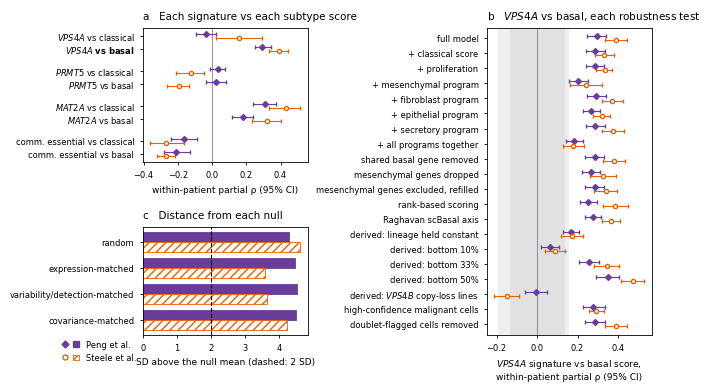

In [64]:
# ==========================================================================
# 31c · VPS4A ON THE BASAL AXIS -- SUPPORTING EVIDENCE AND VERDICT   ·   Supplementary Table S8
# (a) DepMap: are basal-like lines more VPS4A-dependent? Lower Chronos = more dependent, so the
#     single-cell result predicts a NEGATIVE rho between a line's basal score and its VPS4A Chronos.
#     Moffitt basal genes mark squamous lineages across DepMap, so the lineage-held value is the
#     one that bears on the question; PDAC lines alone are few.
# (b) per-gene breadth on the basal axis; (c) held-out DepMap prediction of the mesenchymal-free
#     signatures (§26's CV). None of these is required for the verdict.
#
# WHY the DepMap check: if basal-like lines were not more VPS4A-dependent in DepMap, the single-cell
# association would rest on transcription alone; the result is printed whichever way it falls.
# ==========================================================================

def _partial_rank(x, y, Z=None):
    """Spearman of x and y, optionally with both rank vectors residualised on Z (columns =
    covariates, already numeric). p from the t distribution on n - k - 2 df."""
    ok = x.notna() & y.notna()
    x, y = x[ok], y[ok]
    rx, ry = rankdata(x).astype(float), rankdata(y).astype(float)
    k = 0
    if Z is not None:
        Zx = Z.loc[x.index].astype(float)
        Z = np.column_stack([np.ones(len(x)), Zx.fillna(Zx.mean()).values])
        Pz = Z @ np.linalg.pinv(Z)
        rx, ry = rx - Pz @ rx, ry - Pz @ ry
        k = np.linalg.matrix_rank(Z) - 1
    r = float(np.corrcoef(rx, ry)[0, 1])
    df = len(x) - k - 2
    p = float(2 * tdist.sf(abs(r) * np.sqrt(df / max(1e-12, 1 - r ** 2)), df)) if df > 0 else np.nan
    return r, p, len(x)


BAS_LINE, CLS_LINE = line_score(MOFFITT_BASAL), line_score(MOFFITT_CLASSICAL)
_ylin = dep[VB_TARGET]
_sets = {"VPS4B-low lines (the signature's context)": _ctx_v, "all lines": expr.index}
if DELETED and "VPS4B" in DELETED:
    _sets["VPS4B copy-loss lines"] = ctx_deleted("VPS4B")
_sets["PDAC lines"] = expr.index[IS_PDAC.values]
DEPMAP_BASAL = []
print("DEPMAP -- line basal score vs VPS4A Chronos (prediction: rho < 0)\n")
print("  {:<44}{:>5}{:>20}{:>24}{:>26}".format("lines", "n", "rho (p)", "lineage held (p)", "lineage + EMT held (p)"))
for nm, L in _sets.items():
    L = pd.Index(L).intersection(_ylin.dropna().index)
    if len(L) < 10:
        print("  {:<44}{:>5}  too few".format(nm, len(L)))
        continue
    x, y = BAS_LINE.reindex(L), _ylin.reindex(L)
    r0 = _partial_rank(x, y)
    lin = pd.get_dummies(LINEAGE.reindex(L).astype(str), drop_first=True).astype(float)
    r1 = _partial_rank(x, y, lin) if lin.shape[1] and nm != "PDAC lines" else (np.nan, np.nan, len(L))
    Z2 = pd.concat([lin, EMT_LINE.reindex(L).rename("emt")], axis=1) if nm != "PDAC lines" else EMT_LINE.reindex(L).to_frame()
    r2_ = _partial_rank(x, y, Z2)
    DEPMAP_BASAL.append(dict(lines=nm, n=len(L), rho=r0[0], p=r0[1], rho_lineage=r1[0], p_lineage=r1[1],
                             rho_lineage_emt=r2_[0], p_lineage_emt=r2_[1]))
    print("  {:<44}{:>5}{:>+12.3f} ({:.2g}){:>14} {}{:>16} {}".format(
        nm, len(L), r0[0], r0[1],
        "{:+.3f}".format(r1[0]) if np.isfinite(r1[0]) else "n/a", "({:.2g})".format(r1[1]) if np.isfinite(r1[1]) else "",
        "{:+.3f}".format(r2_[0]), "({:.2g})".format(r2_[1])))
DEPMAP_BASAL = pd.DataFrame(DEPMAP_BASAL)
_main = DEPMAP_BASAL[DEPMAP_BASAL["lines"].str.startswith("VPS4B-low")]
_supports = bool(len(_main) and _main["rho_lineage"].iloc[0] < 0 and _main["p_lineage"].iloc[0] < 0.05)
print("\n  -> DepMap premise ({}): basal-like lines {} more VPS4A-dependent within lineages in the VPS4B-low context".format(
    "SUPPORTS" if _supports else "does NOT support", "ARE" if _supports else "are not shown to be"))

# (b) per-gene breadth
print("\nPER-GENE breadth: each signature gene's own expression vs the basal score\n")
BREADTH = {}
for _lab, _ad in [("Peng", mal), ("Steele", steele), ("Werba", werba)]:
    names = pd.Index(_ad.raw.var_names)
    fb = VB["fps"][_lab]["basal"]
    pg_ = {}
    for g in _vsig:
        if g not in names:
            continue
        v = _ad.raw.X[:, names.get_loc(g)]
        v = np.asarray(v.todense()).ravel() if sparse.issparse(v) else np.asarray(v).ravel()
        if (v > 0).mean() < 0.01:
            continue
        pg_[g] = mean_rho(fb(v))
    pg_ = pd.Series(pg_).sort_values(ascending=False)
    BREADTH[_lab] = pg_
    print("  {}: {} of {} detected genes rise with the basal score ({:.0%}); top 10: {}".format(
        _lab, int((pg_ > 0).sum()), len(pg_), (pg_ > 0).mean(),
        ", ".join("{}{} {:+.2f}".format(g, "*" if g in MES_IDENTITY else "", v) for g, v in pg_.head(10).items())))
print("  (* = mesenchymal-identity gene)")
_both = BREADTH["Peng"].to_frame("Peng").join(BREADTH["Steele"].to_frame("Steele"), how="inner")
print("  the same genes carry it in both cohorts? per-gene rho, Peng vs Steele: Spearman {:+.2f} (n = {})".format(
    spearmanr(_both["Peng"], _both["Steele"])[0], len(_both)))

# (c) do the mesenchymal-free signatures still predict VPS4A dependency in held-out lines?
print("\nHELD-OUT DEPMAP PREDICTION of VPS4A dependency (§26 CV, VPS4B-low context)\n")
VB_CV = {}
for vname, fn in {"original": lambda tt, L: derive(tt, L),
                  "mesenchymal genes dropped": lambda tt, L: [g for g in derive(tt, L) if g not in MES_IDENTITY],
                  "mesenchymal genes excluded, refilled": lambda tt, L: derive(tt, L, exclude=MES_IDENTITY)}.items():
    m, s, _, n = cv_eval(VB_TARGET, _ctx_v, fn)
    VB_CV[vname] = dict(rho=m["rho"], r2=m["r2"], auc=m["auc_quartile"], delta_r2=m["delta_r2"])
    print("  {:<40} rho {:+.3f}  R2 {:+.3f}  AUC {:.2f}  dR2 {:+.3f}".format(vname, m["rho"], m["r2"], m["auc_quartile"], m["delta_r2"]))

# ---- verdict ---------------------------------------------------------------------------------
req = VB_TAB[VB_TAB["required"]]
failed = req[req["status"] == "fail"]
notrun = req[req["status"] == "not run"]


def _which(df):
    """'test (cohorts)' for each test in df, tests in table order."""
    return "; ".join("{} ({})".format(t, ", ".join(sorted(set(df.loc[df["test"] == t, "cohort"]))))
                     for t in dict.fromkeys(df["test"]))


if len(failed):
    verdict = "NOT A FINDING -- failed: " + _which(failed)
    if len(notrun):
        verdict += " | not run: " + _which(notrun)
elif len(notrun):
    verdict = "INCOMPLETE -- every test that ran passed; not run: " + _which(notrun)
else:
    verdict = "PASSES every required test in every cohort (rule: {})".format(
        "Table 1 -- the effect persists" if VB_MIN_KEPT is None
        else "persists and keeps >= {:.0%} of the effect".format(VB_MIN_KEPT))
print("\n" + "=" * 100)
print("VPS4A-BASAL VERDICT: " + verdict)
print("DepMap premise: " + ("supports" if _supports else "does not support") + " the single-cell result (supporting only)")
print("=" * 100)

RESULTS["vps4a_basal"] = dict(
    verdict=verdict, depmap_premise_supports=_supports,
    nulls=NULL_TAB.round(5).to_dict(orient="records"),
    battery=VB_TAB.round(5).to_dict(orient="records"),
    depmap_basal=DEPMAP_BASAL.round(5).to_dict(orient="records"),
    breadth={k: dict(n_pos=int((v > 0).sum()), n=len(v), top=v.head(10).round(3).to_dict()) for k, v in BREADTH.items()},
    heldout_cv=VB_CV)

# ---- diagnostic figure (the manuscript version is Fig. 5, drawn in section 47) ------------------
# (a) every signature against the classical AND the basal score (§30a numbers, 95% CIs);
# (b) the VPS4A-basal association under each robustness test, both cohorts, against each
#     cohort's basal-axis random null (+/- 2 SD band); (c) distance from the four basal-axis nulls.
# Drawn at its printed size (6.5 x 3.8 in) so the font sizes are the sizes on the page, and
# written at 300 dpi to OUT_DIR/vps4a_basal_battery.png.
VB_FIG_SKIP = ["For scale", "Commonly-essential head-to-head", "Single-gene", "Full model"]
COH = [("Peng", "D", "#6A3D9A", "#6A3D9A"), ("Steele", "o", "#E66101", "white")]   # marker, colour, fill
VB_FIG_RC = {"font.size": 6.5, "axes.titlesize": 7.5, "axes.labelsize": 6.5, "xtick.labelsize": 6,
           "ytick.labelsize": 6, "legend.fontsize": 6, "axes.linewidth": 0.6, "xtick.major.width": 0.6,
           "ytick.major.width": 0.6, "xtick.major.size": 2.5, "ytick.major.size": 2.5}


def _vb_label(test, variant):
    """Short row label for panel (b). The battery's own names are written for the printed table
    (VB_TAB keeps them); a figure row needs a few words. Unknown names fall back to the full one."""
    v = str(variant)
    fixed = {"Full model": "full model", "Classical adjustment": "+ classical score",
             "Proliferation": "+ proliferation", "Circularity": "shared basal gene removed",
             "Scoring method": "rank-based scoring", "Published axis": "Raghavan scBasal axis",
             "High-confidence malignant cells": "high-confidence malignant cells",
             "Doublet-flagged cells removed": "doublet-flagged cells removed"}
    if test in fixed:
        return fixed[test]
    if test == "Program adjustment":
        v = v.replace(" (2_CAF)", "").replace(" (exocytosis)", "").replace("epithelial differentiation", "epithelial")
        return v if "together" in v else v + " program"
    if test == "Mesenchymal-gene removal":
        return "mesenchymal genes dropped" if v.startswith("dropped") else "mesenchymal genes excluded, refilled"
    if test == "Derivation":
        return "derived: " + v.replace(" expression", "").replace("passenger-loss lines (copy number)",
                                                                    "VPS4B copy-loss lines")
    return "{}: {}".format(test, v)


if FIGURES:
    with plt.rc_context(VB_FIG_RC):
        # constrained layout; one legend for all three panels, below panel (c)'s labels;
        # panel (c) is drawn as horizontal bars so its long category labels fill the left
        # column the way panel (a)'s labels do (no empty margin); checked box by box (§21)
        fig = ms_figure((6.5, 3.8))
        gsp = fig.add_gridspec(2, 2, width_ratios=[1.0, 1.0], height_ratios=[1.0, 0.8])

        # (a) signature x axis
        ax = fig.add_subplot(gsp[0, 0])
        sigs = [("VPS4A_sig", "VPS4A"), ("PRMT5_sig", "PRMT5"), ("MAT2A_sig", "MAT2A"), ("CE_sig", "comm. essential")]
        axes_ = [("vs classical (original)", "classical"), ("vs basal", "basal")]
        ylab, yv = [], []
        k = 0
        for col, nm in sigs:
            for key, axname in axes_:
                ylab.append("{} vs {}".format(nm, axname)); yv.append(k); k += 1
            k += 0.6                                            # gap between signatures
        yv = np.array(yv)[::-1].astype(float)
        ax.axvline(0, color="0.6", lw=0.8)
        for off, (lab, mk, colr, fill) in zip((0.14, -0.14), COH):
            means, los, his = [], [], []
            for col, nm in sigs:
                for key, axname in axes_:
                    r_ = stat_row("", RESULTS["axis"]["{}|{}|{}".format(lab, col, key)])
                    means.append(r_["mean"]); los.append(r_["ci_lo"]); his.append(r_["ci_hi"])
            means, los, his = map(np.array, (means, los, his))
            ax.errorbar(means, yv + off, xerr=[means - los, his - means], fmt=mk, color=colr, mfc=fill,
                        ms=3, capsize=1.2, elinewidth=0.8)
        ax.set_yticks(yv); ax.set_yticklabels([gi(l_) for l_ in ylab])
        for t_, l_ in zip(ax.get_yticklabels(), ylab):
            if l_.startswith("VPS4A vs basal"):            # the result the figure is about
                t_.set_fontweight("bold")
        ax.set_xlabel("within-patient partial ρ (95% CI)")
        ax.set_title("a   Each signature vs each subtype score", loc="left")

        # (c) distance from the four nulls, horizontal bars (filled = Peng, hatched = Steele)
        ax = fig.add_subplot(gsp[1, 0])
        nb_ = NULL_TAB[NULL_TAB["axis"] == "basal"]
        yb = np.arange(len(VB_NULL_KINDS))[::-1].astype(float)
        for j, (lab, mk, colr, fill) in enumerate(COH):
            v = nb_[nb_["cohort"] == lab].set_index("null").reindex(VB_NULL_KINDS)["sd"]
            ax.barh(yb + (0.5 - j) * 0.38, v, 0.38, color=colr if fill != "white" else "white", lw=0.6,
                    edgecolor=colr, hatch=None if fill != "white" else "////")
        ax.axvline(2, color="k", ls="--", lw=0.8)
        ax.set_yticks(yb)
        ax.set_yticklabels(["random", "expression-matched", "variability/detection-matched", "covariance-matched"])
        ax.set_xlabel("SD above the null mean (dashed: 2 SD)")
        ax.set_title("c   Distance from each null", loc="left")

        # (b) robustness forest
        ax = fig.add_subplot(gsp[:, 1])
        rows_ = VB_TAB[np.isfinite(VB_TAB["lo"].astype(float)) & ~VB_TAB["test"].isin(VB_FIG_SKIP)].copy()
        full_ = VB_TAB[VB_TAB["test"] == "Full model"].copy()
        rows_ = pd.concat([full_, rows_])
        rows_["label"] = [_vb_label(t_, v_) for t_, v_ in zip(rows_["test"], rows_["variant"])]
        labels = list(dict.fromkeys(rows_["label"]))
        y = np.arange(len(labels))[::-1].astype(float)
        for lab, mk, colr, fill in COH:
            nd = VB["nulls"][lab][("random", "basal")]
            ax.axvspan(nd.mean() - 2 * nd.std(), nd.mean() + 2 * nd.std(), color="0.5", alpha=0.12, lw=0, zorder=0)
        ax.axvline(0, color="0.6", lw=0.8)
        for off, (lab, mk, colr, fill) in zip((0.14, -0.14), COH):
            g = rows_[rows_["cohort"] == lab]
            yy = [y[labels.index(l_)] + off for l_ in g["label"]]
            ax.errorbar(g["mean"], yy, xerr=[g["mean"] - g["lo"], g["hi"] - g["mean"]], fmt=mk, color=colr,
                        mfc=fill, ms=3, capsize=1.2, elinewidth=0.8)
        ax.set_yticks(y); ax.set_yticklabels([gi(l_) for l_ in labels])
        ax.set_ylim(y.min() - 0.7, y.max() + 0.7)
        ax.set_xlabel(gi("VPS4A signature vs basal score,\nwithin-patient partial ρ (95% CI)"))
        ax.set_title(gi("b   VPS4A vs basal, each robustness test"), loc="left")

        # one legend -- each cohort's symbol (a, b) and bar style (c) -- in the corner below
        # panel (c)'s category labels, beside its axis label
        ms_legend_under_labels(fig.axes[1],
                               [(Line2D([], [], ls="", marker="D", ms=3.5, color=COH[0][2]), Patch(color=COH[0][2])),
                                (Line2D([], [], ls="", marker="o", ms=3.5, color=COH[1][2], mfc="white"),
                                 Patch(facecolor="white", edgecolor=COH[1][2], hatch="////", lw=0.6))],
                               ["Peng et al.", "Steele et al."], handler_map={tuple: HandlerTuple(ndivide=None, pad=0.5)})
        LAYOUT["VPS4A-basal battery"] = fig_layout_check(fig, "VPS4A-basal battery")
        plt.savefig(out_path("vps4a_basal_battery.png"), dpi=300, bbox_inches="tight")
        _show("vps4a_basal_battery")

### 31d · The *VPS4A*–basal association inside tumours with 18q loss  ·  Supplementary Table S13b, Table 1

§24b tests every target against the classical score; the *VPS4A* association is with the basal score, so it is tested here on that axis, per cohort and pooled across the three cohorts, in tumours with evidence of 18q loss and, as a sensitivity set, in tumours with any 18q copy-number loss.

In [65]:
# ==========================================================================
# 31d · THE VPS4A-BASAL ASSOCIATION INSIDE TUMOURS WITH 18q LOSS   ·   Supplementary Table S13b, Table 1
# §24b tested every target on the CLASSICAL axis; the VPS4A association is with the BASAL score, so
# it is tested here on that axis, against §31a's basal-axis random null.
#   (i)  evidence of 18q loss            -- the three §24a calls that count as evidence (LOSS_EVIDENCE)
#   (ii) evidence or copy-number loss    -- (i) plus 'cn_loss_only'
# WHY (ii): the expression criterion compares malignant with immune and stromal cells, whose baseline
# VPS4B expression differs, so a single-copy 18q loss can show copy-number loss without a ratio below
# 0.75; (ii) is the sensitivity set, (i) stays primary.
# POOLED: every tumour of the three cohorts in one set (each patient still one coefficient). With
# <= 5 tumours a Wilcoxon p cannot reach 0.05, so the per-cohort rows are read from their CIs.
# Also: cells individually called with 18q loss, inside the tumours of set (i) (30-cell floor, as §24b).
# ==========================================================================

_LOC18 = TARGET_LOCUS["VPS4A"]
_SETS18 = {"evidence of 18q loss": set(LOSS_EVIDENCE),
           "evidence or 18q copy-number loss": set(LOSS_EVIDENCE) | {"cn_loss_only"}}
RESULTS["vps4a_basal_18q"] = {}
for _set_name, _calls in _SETS18.items():
    print("\nVPS4A SIGNATURE vs BASAL SCORE -- tumours with {}\n".format(_set_name))
    rows, pooled = [], {}
    for _lab, _ad in [("Peng", mal), ("Steele", steele), ("Werba", werba)]:
        g = CALLS[(CALLS["cohort"] == _lab) & (CALLS["locus"] == _LOC18)]
        ev = set(g.loc[g["call"].isin(_calls), "patient"].astype(str))
        pats = _ad.obs["Patient"].astype(str)
        r = ps_vs(_ad.obs[pats.isin(ev).values], "VPS4A_sig", state_col="basal_score")   # MIN_CELLS floor
        RESULTS["vps4a_basal_18q"]["{}|{}".format(_lab, _set_name)] = r
        pooled.update({"{}|{}".format(_lab, p): v for p, v in r.items()})
        _bn = np.asarray(VB["nulls"][_lab][("random", "basal")])
        if len(r) >= 3:
            rows.append(stat_row("{} ({} tumours)".format(_lab, len(r)), r, _bn))
        else:
            print("  {:<8} only {} tumour(s) -- not tested".format(_lab, len(r)))
        if _set_name == "evidence of 18q loss":                    # cells called with the loss
            cl = CELL_LOSS[_lab]
            csel = np.array([(pats.iloc[k] in ev) and cl.get((cid, _LOC18), False)
                             for k, cid in enumerate(_ad.obs_names)])
            rc = ps_vs(_ad.obs[csel], "VPS4A_sig", state_col="basal_score", min_cells=30)
            RESULTS["vps4a_basal_18q"]["{}|cells with 18q loss".format(_lab)] = rc
            if len(rc) >= 3:
                rows.append(stat_row("{} cells with 18q loss".format(_lab), rc, _bn))
            else:
                print("  {:<8} cells with 18q loss: only {} tumour(s) -- not tested".format(_lab, len(rc)))
    RESULTS["vps4a_basal_18q"]["pooled|{}".format(_set_name)] = pooled
    if len(pooled) >= 3:
        rows.append(stat_row("pooled, three cohorts ({} tumours)".format(len(pooled)), pooled))
    show_rows(rows)
    if len(pooled) >= 3:
        pr = stat_row("", pooled)
        print("  pooled: mean {:+.3f}, 95% CI [{:+.3f}, {:+.3f}], Wilcoxon p {:.2g}, {}/{} tumours positive".format(
            pr["mean"], pr["ci_lo"], pr["ci_hi"], pr["p"], pr["n"] - pr["neg"], pr["n"]))



VPS4A SIGNATURE vs BASAL SCORE -- tumours with evidence of 18q loss

  Peng     cells with 18q loss: only 2 tumour(s) -- not tested
  Steele   cells with 18q loss: only 2 tumour(s) -- not tested
                                             n     neg      mean    95% CI (patients)         p      SD    emp p
  Peng (3 tumours)                           3     0/3   +0.2525   [+0.1445, +0.4333]    0.2500    +3.7   0.0010
  Steele (3 tumours)                         3     0/3   +0.3954   [+0.2924, +0.5324]    0.2500    +4.7   0.0010
  Werba (3 tumours)                          3     0/3   +0.2540   [+0.2003, +0.3101]    0.2500    +4.3   0.0010
  Werba cells with 18q loss                  3     0/3   +0.3171   [+0.2176, +0.3910]    0.2500    +5.3   0.0010
  pooled, three cohorts (9 tumours)          9     0/9   +0.3006   [+0.2274, +0.3808]    0.0039                 
  pooled: mean +0.301, 95% CI [+0.227, +0.381], Wilcoxon p 0.0039, 9/9 tumours positive

VPS4A SIGNATURE vs BASAL SCORE -- tum

## 32 · The MAT2A association under every robustness test, discovery cohorts  ·  Table 1, Fig. 4c

*Methods → Robustness tests; Results → Robustness of the MAT2A association with the classical state.* Every test of Table 1's *MAT2A* column is collected here for both discovery cohorts, each coefficient with a 95% patient-bootstrap CI: the technical tests of sections 18 and 22–24, the adjustments for independent programs and for the basal score (sections 27, 30), the removal of epithelial-identity genes and the alternative derivations (sections 26–27). Rows that need an input that was missing are left out and listed. The table `FOREST` feeds Fig. 4c, whose cell (section 46) checks itself against it and adds the Werba et al. rows (Supplementary Table S9c). The cell also draws a diagnostic forest of the same rows.

MAT2A robustness forest layout: 29 boxes, 0 intersecting pair(s); largest empty area 0.75 x 0.50 in (2.3% of the figure) -> OK


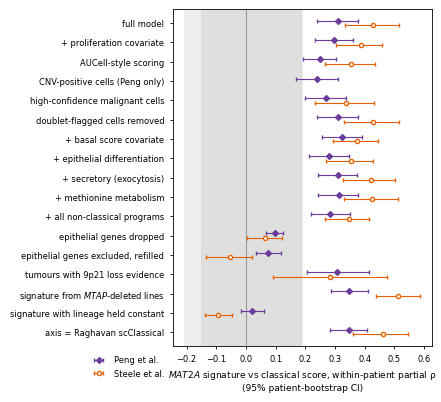

In [66]:
# ==========================================================================
# 32 · MAT2A UNDER EVERY ROBUSTNESS TEST, DISCOVERY COHORTS, 95% CIs   ·   Table 1, data for Fig. 4c
# Every test in Table 1's MAT2A column, Peng et al. and Steele et al., each coefficient with a 95%
# patient-bootstrap CI. Only cheap deterministic recomputation here; everything else is read from
# RESULTS. FOREST feeds Fig. 4c (section 46, which checks itself against it).
# ==========================================================================

def _alt_sig(kind):
    if kind == "deletion" and DELETED:
        return derive("MAT2A", ctx_deleted("MTAP"))
    if kind == "lineage":
        return derive("MAT2A", ctx_quantile("MTAP", LOW_Q), lineage_held=True)
    return None


def _sig_rho(ad, genes):
    if genes is None:
        return None
    score(ad, genes, "_f5")
    r = ps_vs(ad.obs, "_f5")
    del ad.obs["_f5"]
    return r


_alt = {k: _alt_sig(k) for k in ["deletion", "lineage"]}
FOREST = []
for _lab, _ad, _res in [("Peng", mal, res), ("Steele", steele, s_res)]:
    o = _ad.obs
    # rows needing section 10's CNV object or §22–24 stay empty when those were skipped
    ent = [
        ("full model", _res["MAT2A"]),
        ("+ proliferation covariate", ps_vs(o, "MAT2A_sig", covars=QC_COVARS + ["prolif"])),
        ("AUCell-style scoring", ps_vs(o, "MAT2A_auc")),
    ]
    if _lab == "Peng":                           # the original aneuploidy test (section 18) is Peng-only
        ent.append(("CNV-positive cells (Peng only)",
                    ps_vs(sub, "MAT2A_sig", min_cells=30) if globals().get("sub") is not None else None))
    ent += [
        ("high-confidence malignant cells", RESULTS.get("hc_rhos", {}).get("{}|MAT2A_sig".format(_lab))),
        ("doublet-flagged cells removed", ps_vs(o[~o["doublet_flag"].astype(bool).values], "MAT2A_sig")
         if "doublet_flag" in o else None),
        ("+ basal score covariate", ps_vs(o, "MAT2A_sig", covars=QC_COVARS + ["basal_score"])),
    ]
    for n in PRG_COL:
        if not n.lower().startswith("raghavan"):
            ent.append(("+ " + n, RESULTS["program_adjusted"].get("{}|{}".format(_lab, n))))
    ent += [("+ all non-classical programs", RESULTS["program_adjusted"].get("{}|all non-classical programs".format(_lab))),
            ("epithelial genes dropped", RESULTS["epi_removed"].get("{}|MAT2A epithelial genes dropped".format(_lab))),
            ("epithelial genes excluded, refilled", RESULTS["epi_removed"].get("{}|MAT2A epithelial genes excluded, refilled".format(_lab))),
            ("tumours with 9p21 loss evidence", RESULTS.get("loss_strat", {}).get("{}|MAT2A|tumours with 9p21 loss evidence".format(_lab))),
            ("signature from MTAP-deleted lines", _sig_rho(_ad, _alt["deletion"])),
            ("signature with lineage held constant", _sig_rho(_ad, _alt["lineage"]))]
    if _rag_cls:
        ent.append(("axis = Raghavan scClassical", RESULTS["axis"].get("{}|MAT2A_sig|vs Raghavan scClassical".format(_lab))))
    for name, r in ent:
        if r is None or len(r) < 3:                  # a CI needs at least 3 patients
            FOREST.append(dict(cohort=_lab, test=name, n=0 if r is None else len(r), mean=np.nan))
            continue
        rr = stat_row(name, r)
        FOREST.append(dict(cohort=_lab, test=name, n=rr["n"], mean=rr["mean"], lo=rr["ci_lo"],
                           hi=rr["ci_hi"], p=rr["p"], neg=rr["neg"]))
FOREST = pd.DataFrame(FOREST)
FOREST.to_csv(out_path("Fig4c_mat2a_robustness.csv"), index=False)
RESULTS["mat2a_robustness"] = FOREST.round(4).to_dict(orient="records")
_missing = FOREST[FOREST["mean"].isna()]
if len(_missing):
    print("rows without an estimate (input missing, or fewer than 3 patients with enough cells):")
    print("  " + "\n  ".join("{} - {} (patients: {})".format(c, t, n_) for c, t, n_ in
                             zip(_missing["cohort"], _missing["test"], _missing["n"])))

if FIGURES:
    with plt.rc_context(MS_RC):
        # drawn at its printed size (4.3 in wide), so the font sizes are the sizes on the page;
        # constrained layout, legend in the corner below the row labels, checked box by box (§21)
        tests = list(dict.fromkeys(FOREST["test"]))
        fig = ms_figure((4.3, 0.18 * len(tests) + 0.85))
        ax = fig.subplots()
        y = np.arange(len(tests))[::-1]
        for nd in (null, s_null):                       # overlap of the two bands reads darker
            ax.axvspan(nd.mean() - 2 * nd.std(), nd.mean() + 2 * nd.std(), color="0.5", alpha=0.13, lw=0, zorder=0)
        ax.axvline(0, color="0.6", lw=0.8)
        for off, _lab, mk, colr in [(0.12, "Peng", "D", "#6A3D9A"), (-0.12, "Steele", "o", "#E66101")]:
            g = FOREST[(FOREST["cohort"] == _lab) & FOREST["mean"].notna()].set_index("test")
            yy = [y[tests.index(t_)] + off for t_ in g.index]
            ax.errorbar(g["mean"], yy, xerr=[g["mean"] - g["lo"], g["hi"] - g["mean"]], fmt=mk, color=colr,
                        ms=3, capsize=1.2, elinewidth=0.8, label=_lab + " et al.", mfc=colr if _lab == "Peng" else "white")
        ax.set_yticks(y); ax.set_yticklabels([gi(t_) for t_ in tests])
        ax.set_ylim(y.min() - 0.7, y.max() + 0.7)
        ax.set_xlabel(gi("MAT2A signature vs classical score, within-patient partial ρ\n(95% patient-bootstrap CI)"))
        ms_legend_under_labels(ax, *ax.get_legend_handles_labels())   # below the tick labels, beside the x label
        LAYOUT["MAT2A robustness forest"] = fig_layout_check(fig, "MAT2A robustness forest")
        plt.savefig(out_path("mat2a_robustness_forest.png"), dpi=300, bbox_inches="tight")   # diagnostic view of Fig. 4c
        _show("mat2a_robustness_forest")

## 33 · Multiple testing across both subtype axes  ·  Supplementary Table S4b

*Methods → Statistical analysis.* Section 28b applies Benjamini–Hochberg correction over the four tests that make the claim on the classical axis (three targets and the commonly essential control) within each cohort. Modelling the basal score adds four more tests per cohort, so this section corrects over all eight, separately for the Wilcoxon p and the empirical null p. It reads the two tables sections 28b and 31a saved and computes nothing except the correction, so it can also be run on its own in a fresh kernel.

In [67]:
# ==========================================================================
# 33 · BENJAMINI-HOCHBERG ACROSS BOTH AXES   ·   Supplementary Table S4b
# The classical-axis q values (§28b) correct over four tests per cohort: three targets plus
# the commonly essential control. Once the basal score is modelled too (§30a / §31), each
# cohort carries eight tests: four signatures x two axes. This cell corrects over all eight,
# separately for the Wilcoxon p and the empirical null p, so no basal-axis result is
# reported without correction. It computes nothing new except the correction itself.
# Stand-alone: it uses CLASSICAL_TAB (§28b) and BASAL_TAB (§31a) if they are in memory, and otherwise
# reads the CSVs those cells saved, so it can run in a fresh kernel.
# ==========================================================================
import os
import numpy as np
import pandas as pd
from statsmodels.stats.multitest import multipletests

_outd = os.path.join(os.path.expanduser("~/Downloads"), "pdac_results")      # where §21 saves outputs
_cls = CLASSICAL_TAB if "CLASSICAL_TAB" in globals() else pd.read_csv(os.path.join(_outd, "TableS4a_classical_axis.csv"))
_bas = BASAL_TAB if "BASAL_TAB" in globals() else pd.read_csv(os.path.join(_outd, "Table1_basal_axis_rows.csv"))

# one label for the control, which §28b and §31a spell differently
_label = {"common_essential": "commonly essential", "CE": "commonly essential"}

# stack the classical rows (§28b column names) and the basal rows (§31a column names)
rows8 = []
for _, r_ in _cls.iterrows():
    rows8.append(dict(cohort=r_["cohort"], axis="classical",
                      signature=_label.get(r_["signature"], r_["signature"]),
                      mean_rho=r_["mean_rho"], wilcoxon_p=r_["wilcoxon_p"], empirical_p=r_["empirical_p"]))
for _, r_ in _bas.iterrows():
    rows8.append(dict(cohort=r_["cohort"], axis="basal",
                      signature=_label.get(r_["signature"], r_["signature"]),
                      mean_rho=r_["mean"], wilcoxon_p=r_["p"], empirical_p=r_["emp_p"]))
BH8 = pd.DataFrame(rows8)

# BH within each cohort over its eight tests, for each kind of p value
for kind in ("wilcoxon", "empirical"):
    BH8[kind + "_q8"] = np.nan
    for _coh, _idx in BH8.groupby("cohort").groups.items():
        BH8.loc[_idx, kind + "_q8"] = multipletests(BH8.loc[_idx, kind + "_p"].values,
                                                     method="fdr_bh")[1]

# sanity check: eight tests per cohort, or the correction family is wrong
assert BH8.groupby("cohort").size().eq(8).all(), BH8.groupby("cohort").size()

BH8.to_csv(os.path.join(_outd, "TableS4b_BH_both_axes.csv"), index=False)
if "RESULTS" in globals():
    RESULTS["bh_both_axes"] = BH8.round(5).to_dict(orient="records")         # for §51's results register
print("BENJAMINI-HOCHBERG OVER BOTH AXES (8 tests per cohort)\n")
print(BH8.round(4).to_string(index=False))

BENJAMINI-HOCHBERG OVER BOTH AXES (8 tests per cohort)

cohort      axis          signature  mean_rho  wilcoxon_p  empirical_p  wilcoxon_q8  empirical_q8
  Peng classical              VPS4A   -0.0365      0.1515       0.4915       0.1731        0.6553
  Peng classical              PRMT5    0.0325      0.0691       0.8741       0.0921        0.8741
  Peng classical              MAT2A    0.3094      0.0000       0.0070       0.0000        0.0160
  Peng classical commonly essential   -0.1650      0.0007       0.0320       0.0012        0.0511
Steele classical              VPS4A    0.1573      0.0494       0.1049       0.0494        0.1199
Steele classical              PRMT5   -0.1242      0.0134       0.2398       0.0153        0.2398
Steele classical              MAT2A    0.4290      0.0001       0.0010       0.0002        0.0027
Steele classical commonly essential   -0.2687      0.0009       0.0090       0.0011        0.0144
 Werba classical              VPS4A   -0.0167      0.8311     

# Part VII · Replication, sensitivity and specificity

*Methods → Replication criteria; Positive and negative control dependencies; Comparison to signatures in the same cell lines. Results → Replication in an independent cohort; Sensitivity and specificity of the approach.* The three associations are judged in the replication cohort by the criteria fixed in advance (section 34). The approach is then calibrated with dependencies that DepMap itself links, or does not link, to a subtype score (sections 35–38), and each target is compared with signatures built exactly as its own was for dependencies without a subtype link (section 39).

## 34 · Replication in Werba et al. by the pre-specified criteria  ·  Fig. 6, Supplementary Table S9a

*Methods → Replication criteria; Results → Replication in an independent cohort.* The criteria were fixed before any Werba et al. expression data were analysed (sections 8, 20) and are applied here exactly as written, to the values sections 28b (classical axis) and 31a (basal axis) computed for Werba et al. with the same code as for the discovery cohorts:

| claim | replicates if |
|---|---|
| the *VPS4A* signature rises with the basal score | mean > 0, 95% patient-bootstrap CI excludes zero, and empirical p < 0.05 against the basal-axis random-gene null |
| the *MAT2A* signature rises with the classical score | mean > 0, 95% CI excludes zero, and empirical p < 0.05 against the classical-axis random-gene null |
| the *PRMT5* signature shows no association with the classical score | equivalent to zero within ±0.10 (two one-sided tests, section 28b); *not replicated* if the 95% CI excludes zero; otherwise *inconclusive* |

**Why these and only these.** They are the study's three claims; the replication tests the claims, not a new selection of them. Every other Werba et al. result (sections 20–33, Supplementary Tables S7 and S9c) is reported alongside, and none of them was chosen after these verdicts were seen. The cell also draws a diagnostic view of the verdicts; the manuscript version is Fig. 6 (section 48).

THIRD-COHORT REPLICATION (Werba et al., criteria fixed before its data was opened)

  claim                                 cohort     n     mean    95% CI (patients)      SD    emp p
  VPS4A vs basal                        Peng      24   +0.294   [+0.248, +0.342]    +4.3    0.001
  VPS4A vs basal                        Steele    14   +0.389   [+0.334, +0.442]    +4.6    0.001
  VPS4A vs basal                        Werba     11   +0.304   [+0.233, +0.382]    +5.1    0.001
  MAT2A vs classical                    Peng      24   +0.309   [+0.240, +0.376]    +3.4    0.007
  MAT2A vs classical                    Steele    14   +0.429   [+0.333, +0.514]    +4.4    0.001
  MAT2A vs classical                    Werba     11   +0.298   [+0.206, +0.394]    +4.1    0.004
  PRMT5 vs classical (no association)   Peng      24   +0.033   [-0.015, +0.077]    +0.2    0.874
  PRMT5 vs classical (no association)   Steele    14   -0.124   [-0.209, -0.048]    -1.2    0.240
  PRMT5 vs classical (no associa

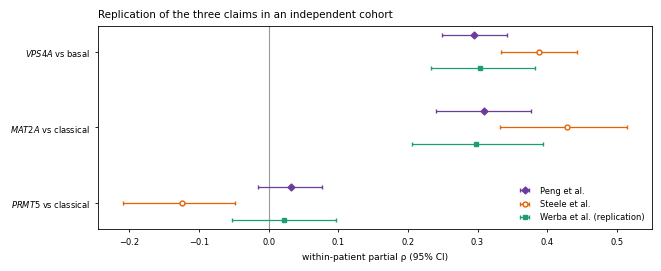

In [68]:
# ==========================================================================
# 34 · REPLICATION COHORT -- verdicts by the pre-specified criteria   ·   Supplementary Table S9a
# Reads CLASSICAL_TAB (§28b: classical axis, random null, TOST) and BASAL_TAB (§31a: basal axis, random null)
# and applies the criteria in the markdown above, unchanged. Computes nothing new.
# Diagnostic figure: each claim in each cohort (mean within-patient partial rho, 95% patient-bootstrap
# CI), written at 300 dpi to OUT_DIR/werba_replication_verdicts.png. The manuscript version is Fig. 6,
# drawn in section 48.
# ==========================================================================

def _t3(coh, sig):
    return CLASSICAL_TAB[(CLASSICAL_TAB["cohort"] == coh) & (CLASSICAL_TAB["signature"] == sig)].iloc[0]


def _bt3(coh, sig):
    return BASAL_TAB[(BASAL_TAB["cohort"] == coh) & (BASAL_TAB["signature"] == sig)].iloc[0]


_v = _bt3("Werba", "VPS4A")
_m = _t3("Werba", "MAT2A")
_p = _t3("Werba", "PRMT5")
WERBA_VERDICT = {
    "VPS4A vs basal": "replicates" if (_v["mean"] > 0 and _v["ci_lo"] > 0 and _v["emp_p"] < 0.05) else "does not replicate",
    "MAT2A vs classical": "replicates" if (_m["mean_rho"] > 0 and _m["ci95_lo"] > 0 and _m["empirical_p"] < 0.05)
    else "does not replicate",
    "PRMT5 vs classical (no association)": ("replicates (equivalent to zero within +/-{})".format(EQ_MARGIN)
                                            if _p["equivalent_within_margin"] else
                                            "does not replicate (95% CI excludes zero)" if (_p["ci95_lo"] > 0 or _p["ci95_hi"] < 0)
                                            else "inconclusive")}

REPL = []
for claim, (axis, sig) in {"VPS4A vs basal": ("basal", "VPS4A"), "MAT2A vs classical": ("classical", "MAT2A"),
                           "PRMT5 vs classical (no association)": ("classical", "PRMT5")}.items():
    for coh in ("Peng", "Steele", "Werba"):
        if axis == "basal":
            r_ = _bt3(coh, sig)
            REPL.append(dict(claim=claim, cohort=coh, n=int(r_["n"]), mean=r_["mean"], ci_lo=r_["ci_lo"], ci_hi=r_["ci_hi"],
                             sd_from_random=r_["sd_from_random"], empirical_p=r_["emp_p"]))
        else:
            r_ = _t3(coh, sig)
            REPL.append(dict(claim=claim, cohort=coh, n=int(r_["n"]), mean=r_["mean_rho"], ci_lo=r_["ci95_lo"],
                             ci_hi=r_["ci95_hi"], sd_from_random=r_["sd_from_random"], empirical_p=r_["empirical_p"]))
REPL = pd.DataFrame(REPL)
REPL.to_csv(out_path("TableS9_werba_replication.csv"), index=False)

print("THIRD-COHORT REPLICATION (Werba et al., criteria fixed before its data was opened)\n")
print("  {:<38}{:<8}{:>4}{:>9}{:>21}{:>8}{:>9}".format("claim", "cohort", "n", "mean", "95% CI (patients)", "SD", "emp p"))
for _, r_ in REPL.iterrows():
    print("  {:<38}{:<8}{:>4}{:>+9.3f}   [{:+.3f}, {:+.3f}]{:>+8.1f}{:>9.3f}".format(
        r_["claim"], r_["cohort"], r_["n"], r_["mean"], r_["ci_lo"], r_["ci_hi"], r_["sd_from_random"], r_["empirical_p"]))
print()
for k_, v_ in WERBA_VERDICT.items():
    print("  {:<38} {}".format(k_, v_.upper()))
RESULTS["werba_replication"] = dict(verdicts=WERBA_VERDICT, table=REPL.round(5).to_dict(orient="records"))

# ---- diagnostic figure ------------------------------------------------------------------------
if FIGURES:
    _COHW = [("Peng", "D", "#6A3D9A", "#6A3D9A"), ("Steele", "o", "#E66101", "white"), ("Werba", "s", "#1B9E77", "#1B9E77")]
    with plt.rc_context(MS_RC):
        fig = ms_figure((6.5, 2.6))
        ax = fig.add_subplot(1, 1, 1)
        claims = list(REPL["claim"].unique())
        y0 = np.arange(len(claims))[::-1].astype(float)
        ax.axvline(0, color="0.6", lw=0.8)
        for off, (lab, mk, colr, fill) in zip((0.22, 0.0, -0.22), _COHW):
            g = REPL[REPL["cohort"] == lab].set_index("claim").reindex(claims)
            ax.errorbar(g["mean"], y0 + off, xerr=[g["mean"] - g["ci_lo"], g["ci_hi"] - g["mean"]], fmt=mk,
                        color=colr, mfc=fill, ms=3.5, capsize=1.5, elinewidth=0.9,
                        label=lab + " et al." + (" (replication)" if lab == "Werba" else ""))
        ax.set_yticks(y0)
        ax.set_yticklabels([gi(c.replace(" (no association)", "")) for c in claims])
        ax.set_xlabel("within-patient partial ρ (95% CI)")
        ax.legend(loc="lower right", fontsize=6, frameon=False)
        ax.set_title("Replication of the three claims in an independent cohort", loc="left")
        plt.savefig(out_path("werba_replication_verdicts.png"), dpi=300, bbox_inches="tight")
        _show("werba_replication_verdicts")

## 35 · Sensitivity: positive-control dependencies chosen in DepMap by a fixed rule

*Methods → Positive and negative control dependencies; Results → Sensitivity and specificity of the approach.* The two literature controls of section 29 cannot measure sensitivity, because in DepMap neither is a dependency that tracks the classical or basal score. Here DepMap chooses the controls, by a rule fixed before any single-cell result was seen:

1. **Scan.** Every gene's Chronos score is correlated with line-level classical and basal scores across all lines with lineage held constant (partial Spearman). A negative ρ means that lines high in the score are *more* dependent.
2. **Select.** Candidates exclude the three targets, commonly essential genes (mean Chronos < −0.5), genes without expression data, and genes on which fewer than 5% of lines are dependent (Chronos ≤ −0.5). On each axis the most negative candidates with Benjamini–Hochberg q < 0.05 are the controls.
3. **Transfer.** Each control's signature is derived by the targets' rule (the 100 genes whose expression best tracks the dependency), across all lines with lineage held constant, with the classical and basal genes of Moffitt et al. and Raghavan et al. removed **before** derivation, so a signature cannot pass by sharing genes with the score it is tested against.
4. **Test.** Within-patient partial correlation with the axis on which the control was selected, in both discovery cohorts, against that axis's random-gene null (section 15's for the classical axis, recomputed exactly; section 31a's for the basal axis). **Recovered** = 95% CI above zero and empirical p < 0.05 in **both** discovery cohorts.
5. **Strict variant** (reported, not the primary count): epithelial- and mesenchymal-identity genes also removed before derivation.

This section uses five controls per axis and also re-checks the two literature controls on the subtype axes; section 37 enlarges the panel to 20 per axis, which is the panel the manuscript reports (Fig. 7a,b, Supplementary Table S10). The replication cohort is deliberately not added: the recovery rule was fixed on the two discovery cohorts.

The section can also run on its own in a fresh kernel: it then reads the inputs and the cached basal-axis null and re-creates only what it needs, with code copied unchanged from the sections named beside each piece.

**Why these choices**

| choice | why |
|---|---|
| Lineage held constant in the scan and the derivation | Across all lines the Moffitt et al. scores largely separate tissues of origin, so a dependency that only marks a tissue would pass through lineage. |
| State-reference genes removed before derivation | This is the circularity test the targets were held to (Table 1). |
| BH q < 0.05 within each axis | Every control is a strong DepMap association, fixed before the single-cell test. |
| Recovery required in both discovery cohorts | The same bar as the targets' associations. |

In [69]:
# ==========================================================================
# 35 · SENSITIVITY -- positive-control dependencies chosen in DepMap by a fixed rule
# Peng et al. and Steele et al. only: the recovery rules below were fixed on these two cohorts before
# the panel was run, so the replication cohort (section 8) is not added to them afterwards.
# STAND-ALONE, like §33: it also runs in a fresh kernel. It reads the input files and §31a's cached
# basal-axis null, and re-creates only what it needs, with code copied unchanged from the cells
# named beside each piece. Nothing else in the notebook has to run first. ~25-35 min on the
# first run (most of it the classical-axis random null and the cross-validation); both are
# cached in OUT_DIR, so a re-run takes ~5 min.
#
# Extends §29. §29's two controls were picked from the literature, and in DepMap neither is a
# dependency that tracks the classical or basal score: KRAS dependency does not follow the
# classical score among PDAC lines (§29a), and CDS2 dependency follows an EMT score, which is not
# the PDAC basal state. So neither could measure whether the DepMap-to-single-cell transfer
# detects a subtype-selective dependency. Here DepMap picks the controls, by a rule fixed before
# any single-cell result is seen:
#   1. SCAN. Every gene's Chronos effect is correlated with the line-level classical and basal
#      scores across all lines, lineage held constant (corr_within_lineage, the partial Spearman
#      §26 uses for lineage-held signatures). Negative rho = lines high in that score are MORE
#      dependent (Chronos: lower = more dependent).
#   2. SELECT. Candidates exclude the three targets, commonly essential genes (mean Chronos
#      < -0.5, section 12's criterion), genes without DepMap expression, and genes with too few
#      dependent lines (< CAL_MIN_DEP_FRAC of lines at Chronos <= STRONG_DEP_ABS). The CAL_N most
#      negative per axis with BH q < CAL_Q are the controls: dependencies DepMap itself says are
#      subtype-selective.
#   3. TRANSFER. Each control's signature is derived with derive(), the targets' rule (the 100
#      genes whose expression best tracks the dependency), across all lines with lineage held
#      constant, and with the Moffitt and Raghavan classical and basal genes removed BEFORE
#      derivation, so a signature cannot pass by sharing genes with the score it is tested
#      against. §26's cross-validation measures how well it predicts its own held-out dependency.
#   4. TEST. Within-patient partial Spearman against the axis it was selected on (QC covariates),
#      both cohorts, against that axis's random null (section 15's for classical, recomputed
#      exactly; §31a's for basal, read from its cache). Expected sign: positive.
#      RECOVERED = 95% CI above zero AND empirical p < 0.05 against the random null (§29a's bar),
#      in BOTH cohorts.
#   5. STRICT VARIANT (reported, not the primary count): epithelial- and mesenchymal-identity
#      genes (§27c, §31b) also removed before derivation, the removal VPS4A survived in §31.
#   6. §29's premises, re-checked on the axes that matter: KRAS and CDS2 rows of the same scan.
# The result is reported whichever way it falls. Many recoveries show the transfer can detect a
# subtype-selective dependency; few recoveries measure its limited sensitivity, which bounds what
# the PRMT5 null can mean. The targets' results are not touched here.
#
# WHY lineage is held constant in the scan AND the derivation: across all lines the Moffitt scores
# largely separate tissues of origin (squamous vs glandular), and a dependency that only marks a
# tissue would "pass" through lineage, which is what the all-lines KRAS signature did in §29a
# (+0.72 with the classical score while KRAS dependency does not track it among PDAC lines).
# WHY the primary count removes only the state-reference genes: that is the circularity test the
# targets were held to (Table 1, §31); the strict variant shows whether a recovery also survives
# the identity-gene removal VPS4A survived.
# WHY 5 per axis and q < 0.05: enough controls to estimate a recovery rate per axis, few enough
# that every one is a strong DepMap association; fixed here, before the single-cell test.
# WHY 3 cross-validation repeats instead of §26's 10: held-out prediction only decides the
# secondary count; repeats only re-shuffle the folds, and 3 keeps the panel under ~35 min.
# ==========================================================================

import os, json, time, gc
import numpy as np
import pandas as pd
import scanpy as sc
from scipy.stats import spearmanr, wilcoxon, rankdata, t as tdist
from statsmodels.stats.multitest import multipletests
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

_T0 = time.time()
def _el():
    """Elapsed time since the cell started, for the progress lines."""
    return "{:.1f} min".format((time.time() - _T0) / 60)

# ---- settings: the same values as section 1 and §21 -----------------------------------------
DOWNLOADS = os.path.expanduser("~/Downloads")
_OUTD = os.path.join(DOWNLOADS, "pdac_results")                # §21's OUT_DIR
os.makedirs(_OUTD, exist_ok=True)
SEED, MIN_CELLS, SIG_SIZE, N_NULL = 0, 50, 96, 1000
QC_COVARS = ["log_counts", "n_genes_by_counts", "pct_counts_mt"]
N_BOOT_CI = 10000
STRONG_DEP_ABS = -0.5
CV_FOLDS, CV_REPEATS = 5, 10
EPI_CORR_MAX = 0.40
TARGETS = ["VPS4A", "PRMT5", "MAT2A"]
MOFFITT_CLASSICAL = ["BTNL8", "FAM3D", "ATAD4", "AGR3", "CTSE", "LOC400573", "LYZ", "TFF2", "TFF1",
                     "ANXA10", "LGALS4", "PLA2G10", "CEACAM6", "VSIG2", "TSPAN8", "ST6GALNAC1",
                     "AGR2", "TFF3", "CYP3A7", "MYO1A", "CLRN3", "KRT20", "CDH17", "SPINK4", "REG4"]
MOFFITT_BASAL = ["VGLL1", "UCA1", "S100A2", "LY6D", "SPRR3", "SPRR1B", "LEMD1", "KRT15", "CTSV",
                 "DHRS9", "AREG", "CST6", "SERPINB3", "KRT6C", "KRT6A", "SERPINB4", "FAM83A",
                 "SCEL", "FGFBP1", "KRT7", "KRT17", "GPR87", "TNS4", "SLC2A1", "ANXA8L2"]
PROLIF = ["MCM5", "PCNA", "TYMS", "MKI67", "RRM2", "CDK1", "TOP2A", "UBE2C", "BIRC5", "CENPF", "CCNB2"]
EPI_MARKERS = ["EPCAM", "CDH1", "KRT8", "KRT18", "KRT19", "CLDN4", "CLDN7", "ESRP1", "GRHL2", "SPINT1", "ELF3"]
EMT_MARKERS = ["VIM", "CDH2", "ZEB1", "ZEB2", "SNAI2", "TWIST1", "FN1"]

# ---- calibration settings (fixed before the single-cell test) ------------------------------
CAL_N = 5                      # controls per axis
CAL_Q = 0.05                   # BH q required in the DepMap scan (within each axis)
CAL_MIN_DEP_FRAC = 0.05        # >= 5% of lines strongly dependent (Chronos <= STRONG_DEP_ABS)
CAL_MIN_AUC = 0.70             # secondary count: controls whose signature predicts held-out dependency
CAL_CV = True                  # held-out validation of each control signature
CAL_CV_REPEATS = 3             # 5 folds x 3 repeats (see WHY above)
CAL_FORCE = False              # True = ignore this cell's caches (classical null, CV) and recompute


def _find(names):
    """First file with one of these names in ~/Downloads or one folder below (the input-search
    cell's rule, so a copy left in an unzipped DepMap folder is found too)."""
    want = {n.lower() for n in names}
    for root in [DOWNLOADS] + [os.path.join(DOWNLOADS, d) for d in sorted(os.listdir(DOWNLOADS))
                               if os.path.isdir(os.path.join(DOWNLOADS, d))]:
        for f in sorted(os.listdir(root)):
            if f.lower() in want:
                return os.path.join(root, f)
    raise FileNotFoundError("none of {} found in {} or one folder below".format(names, DOWNLOADS))


# ---- DepMap (section 11's loader contract; §26a's lineage and PDAC flags) ---------------------
# reused if this kernel already ran section 11, otherwise read from the CSVs (~2 min)
if not ("dep" in globals() and "expr" in globals()):
    dep = pd.read_csv(_find(["CRISPRGeneEffect.csv"]), index_col=0)
    dep.columns = [c.split(" (")[0].strip() for c in dep.columns]
    dep = dep.loc[:, ~dep.columns.duplicated()]
    expr = pd.read_csv(_find(["OmicsExpressionTPMLogp1HumanProteinCodingGenes.csv"]))
    if "ModelID" in expr.columns:
        if "IsDefaultEntryForModel" in expr.columns:
            _c = expr["IsDefaultEntryForModel"]
            expr = expr[_c.astype(str).str.lower().isin(["true", "yes", "1"]) | (_c == True)]
        expr = expr.set_index("ModelID")
    else:
        expr = expr.set_index(expr.columns[0])
    _META = {"ProfileID", "SequencingID", "IsDefaultEntryForModel", "IsDefaultEntryForMC", "ProfileType",
             "ModelConditionID", "StrippedCellLineName", "CellLineName", "DepmapModelType",
             "OncotreeLineage", "OncotreePrimaryDisease", "Unnamed: 0"}
    expr = expr.drop(columns=[c for c in expr.columns if c.split(" (")[0].strip() in _META])
    expr.columns = [c.split(" (")[0].strip() for c in expr.columns]
    expr = expr.loc[:, ~expr.columns.duplicated()].select_dtypes(include=[np.number])
    _lines = dep.index.intersection(expr.index)
    dep, expr = dep.loc[_lines], expr.loc[_lines]
print("DepMap: {} lines x {} dependency genes | {} expression genes ({})".format(
    len(dep), dep.shape[1], expr.shape[1], _el()))
assert len(dep) > 100 and "VPS4A" in dep.columns, "DepMap did not load as section 11 loads it"

_model = pd.read_csv(_find(["Model.csv", "Models.csv"])).set_index("ModelID")
LINEAGE = _model["OncotreeLineage"].reindex(expr.index).fillna("Unknown").astype(str)
IS_PDAC = (_model["OncotreePrimaryDisease"].reindex(expr.index).fillna("")
           .str.contains("Pancreatic Adenocarcinoma", case=False))


# ---- §26a / §26b helpers, copied unchanged ----------------------------------------------------
def line_score(genes):
    g = [x for x in genes if x in expr.columns]
    z = (expr[g] - expr[g].mean()) / expr[g].std().replace(0, np.nan)
    return z.mean(axis=1)


PROLIF_LINE, EPI_LINE, EMT_LINE = line_score(PROLIF), line_score(EPI_MARKERS), line_score(EMT_MARKERS)


# corr_with: Pearson correlation of average ranks IS the Spearman correlation, for every gene at once
def corr_with(E, y):
    """Spearman of every column of E with y, ranks taken within these lines."""
    R = E.rank(axis=0).values
    r = rankdata(y)
    R = R - R.mean(axis=0)
    r = r - r.mean()
    with np.errstate(invalid="ignore", divide="ignore"):
        c = (R.T @ r) / (np.sqrt((R ** 2).sum(axis=0)) * np.sqrt((r ** 2).sum()))
    return pd.Series(c, index=E.columns)


# corr_within_lineage: lineage indicators projected out of both rank vectors = partial Spearman
# with lineage held constant
def corr_within_lineage(E, y, lin):
    """Lineage held constant: ranks of every gene and of y are residualised on lineage
    indicators before correlating, so a gene that only separates lineages scores ~0."""
    R = E.rank(axis=0).values
    r = rankdata(y).astype(float)
    D = pd.get_dummies(lin.astype(str)).values.astype(float)
    P = D @ np.linalg.pinv(D)
    R = R - P @ R
    r = r - P @ r
    with np.errstate(invalid="ignore", divide="ignore"):
        c = (R.T @ r) / (np.sqrt((R ** 2).sum(axis=0)) * np.sqrt((r ** 2).sum()))
    return pd.Series(c, index=E.columns)


# derive: section 11's derivation as a function; `exclude` removes genes BEFORE ranking
def derive(target, lines, n=100, lineage_held=False, exclude=None):
    lines = pd.Index(lines).intersection(dep.index[dep[target].notna()])
    e = expr.loc[lines]
    e = e.loc[:, e.std() > 0]
    if exclude:
        e = e.drop(columns=[g for g in exclude if g in e.columns])
    y = dep.loc[lines, target].values
    c = corr_within_lineage(e, y, LINEAGE.reindex(lines)) if lineage_held else corr_with(e, y)
    return c.dropna().sort_values().head(n).index.tolist()


# sig_score: genes z-scored with TRAINING-line means and SDs (leak-free held-out scoring)
def sig_score(train, test, genes):
    g = [x for x in genes if x in expr.columns]
    mu = expr.loc[train, g].mean()
    sd = expr.loc[train, g].std().replace(0, np.nan)
    return ((expr.loc[test, g] - mu) / sd).mean(axis=1)


def _design(lines, levels, extra=None):
    lin = LINEAGE.reindex(lines).where(LINEAGE.reindex(lines).isin(levels), "other")
    D = pd.get_dummies(pd.Categorical(lin, categories=list(levels) + ["other"])).values[:, 1:]
    cols = [D.astype(float)]
    if extra is not None:
        cols = [np.asarray(e, float).reshape(len(lines), -1) for e in extra] + cols
    return np.column_stack(cols)


def ols_predict(Xtr, ytr, Xte):
    A = np.column_stack([np.ones(len(Xtr)), Xtr])
    beta = np.linalg.lstsq(A, ytr, rcond=None)[0]
    return np.column_stack([np.ones(len(Xte)), Xte]) @ beta


def r2(y, yhat):
    y, yhat = np.asarray(y, float), np.asarray(yhat, float)
    return float(1 - np.sum((y - yhat) ** 2) / np.sum((y - y.mean()) ** 2))


def auc_quartiles(y, s):
    lo, hi = np.quantile(y, 0.25), np.quantile(y, 0.75)
    sel = (y <= lo) | (y >= hi)
    return float(roc_auc_score((y[sel] <= lo).astype(int), s[sel]))


def auc_abs(y, s):
    lab = (y <= STRONG_DEP_ABS).astype(int)
    if lab.sum() < 10 or (1 - lab).sum() < 10:
        return np.nan
    return float(roc_auc_score(lab, s))


def cv_eval(target, lines, derive_fn, n_rep=CV_REPEATS):
    """Repeated stratified 5-fold CV. Returns (mean metrics, sd metrics, out-of-fold score
    averaged over repeats)."""
    lines = pd.Index(lines).intersection(dep.index[dep[target].notna()])
    y = dep.loc[lines, target]
    strat = LINEAGE.reindex(lines).fillna("Unknown")
    vc = strat.value_counts()
    strat = strat.where(strat.map(vc) >= CV_FOLDS, "other")
    mets, oof = [], []
    for rep in range(n_rep):
        skf = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED + rep)
        s_pred, y_hat, yb, yf = (pd.Series(np.nan, index=lines) for _ in range(4))
        for tr, te in skf.split(np.zeros(len(lines)), strat.values):
            Ltr, Lte = lines[tr], lines[te]
            genes = derive_fn(target, Ltr)
            s_tr, s_te = sig_score(Ltr, Ltr, genes), sig_score(Ltr, Lte, genes)
            s_pred[Lte] = s_te.values
            b = np.polyfit(s_tr.values, y[Ltr].values, 1)
            y_hat[Lte] = np.polyval(b, s_te.values)
            levels = [l for l, c in LINEAGE.reindex(Ltr).value_counts().items() if c >= 5]
            base_tr = _design(Ltr, levels, [expr.loc[Ltr, target], PROLIF_LINE.reindex(Ltr)])
            base_te = _design(Lte, levels, [expr.loc[Lte, target], PROLIF_LINE.reindex(Lte)])
            yb[Lte] = ols_predict(base_tr, y[Ltr].values, base_te)
            yf[Lte] = ols_predict(np.column_stack([base_tr, s_tr.values]), y[Ltr].values,
                                  np.column_stack([base_te, s_te.values]))
        yy, ss = y.values, s_pred.values
        mets.append(dict(rho=spearmanr(ss, yy)[0], r2=r2(yy, y_hat.values),
                         auc_quartile=auc_quartiles(yy, ss), auc_abs=auc_abs(yy, ss),
                         r2_base=r2(yy, yb.values), r2_full=r2(yy, yf.values)))
        oof.append(s_pred)
    df = pd.DataFrame(mets)
    df["delta_r2"] = df["r2_full"] - df["r2_base"]
    return df.mean(), df.std(), pd.concat(oof, axis=1).mean(axis=1), len(lines)


# ---- single-cell helpers: section 4 (add_qc, score), §21 (boot_ci, emp_p), §31a (FastPS) ----
def add_qc(ad):
    """Guarantee QC_COVARS exist. Computes them if the object arrived without."""
    need = {"total_counts", "n_genes_by_counts", "pct_counts_mt"} - set(ad.obs.columns)
    if need:
        ad.var["mt"] = ad.var_names.str.startswith("MT-")
        sc.pp.calculate_qc_metrics(ad, qc_vars=["mt"], inplace=True, percent_top=None)
    ad.obs["log_counts"] = np.log1p(ad.obs["total_counts"])
    return ad


def score(ad, genes, name):
    present = [g for g in genes if g in set(ad.raw.var_names)]
    sc.tl.score_genes(ad, present, score_name=name, use_raw=True)
    return present


def boot_ci(v, n_boot=N_BOOT_CI, seed=SEED):
    """95% CI of the across-patient mean, resampling PATIENTS (the unit of replication)."""
    v = np.asarray(list(v.values()) if isinstance(v, dict) else v, float)   # accepts {patient: rho}, as §21's does
    if len(v) < 3:
        return (np.nan, np.nan)
    r = np.random.default_rng(seed)
    m = v[r.integers(0, len(v), size=(n_boot, len(v)))].mean(axis=1)
    return float(np.quantile(m, 0.025)), float(np.quantile(m, 0.975))


def emp_p(value, nulldist):
    """Two-sided empirical p: (k + 1) / (n + 1), k = null draws at least as far from the
    null mean as the observed value."""
    nd = np.asarray(nulldist, float)
    k = int(np.sum(np.abs(nd - nd.mean()) >= abs(value - nd.mean())))
    return (k + 1) / (len(nd) + 1)


class FastPS:
    """ps_vs for many score vectors against ONE state column and covariate set (§31a; it
    reproduces ps_vs, and so partial_spearman, exactly). Per patient the design [1, ranked
    covariates], its pseudo-inverse and the residualised state ranks are computed once."""

    def __init__(self, obs, state_col, covars=None, min_cells=MIN_CELLS):
        covars = QC_COVARS if covars is None else covars
        self.parts = []
        for pat, g in obs.groupby("Patient", observed=True):
            if len(g) < min_cells:
                continue
            X = np.column_stack([np.ones(len(g))] + [rankdata(g[q].values) for q in covars])
            P = np.linalg.pinv(X)
            c = rankdata(g[state_col].values)
            rc = c - X @ (P @ c)
            if rc.std() < 1e-9:
                continue
            self.parts.append((pat, obs.index.get_indexer(g.index), X, P, rc))

    def __call__(self, values):
        out = {}
        for pat, idx, X, P, rc in self.parts:
            y = rankdata(values[idx])
            ry = y - X @ (P @ y)
            if ry.std() < 1e-9:
                continue
            out[pat] = float(np.corrcoef(ry, rc)[0, 1])
        return out


def _summary(rhos, nulldist):
    """§21's stat_row: n, mean, 95% patient-bootstrap CI, Wilcoxon p, SD from the null, empirical p."""
    v = np.asarray(list(rhos.values()), float)
    if len(v) < 3:
        return dict(n=len(v), mean=np.nan, ci_lo=np.nan, ci_hi=np.nan, p=np.nan, sd_null=np.nan, emp_p=np.nan)
    lo, hi = boot_ci(v)
    m = float(v.mean())
    nd = np.asarray(nulldist, float)
    return dict(n=len(v), mean=m, ci_lo=lo, ci_hi=hi, p=float(wilcoxon(v)[1]),
                sd_null=float((m - nd.mean()) / nd.std()), emp_p=emp_p(m, nd))


# ---- the two discovery cohorts (section 12's files; classical and basal scores were saved by sections 6 / 7) ---
if not ("mal" in globals() and "steele" in globals()):
    mal = add_qc(sc.read_h5ad(_find(["peng_malignant_aim2.h5ad"])))
    steele = add_qc(sc.read_h5ad(_find(["steele_malignant_scored.h5ad"])))
COHORTS = [("Peng", mal), ("Steele", steele)]
for _lab, _ad in COHORTS:
    _miss = [c for c in ["Patient", "classical_score", "basal_score"] + QC_COVARS if c not in _ad.obs]
    assert not _miss, "{} is missing {}".format(_lab, _miss)
    print("{}: {:,} malignant cells, {} patients ({})".format(_lab, _ad.n_obs, _ad.obs["Patient"].nunique(), _el()))

# ---- identity gene sets: §31b (state references, mesenchymal) and §27c (epithelial) ---------
RAGH = {}
try:
    _r = pd.read_csv(_find(["raghavan2021_signatures.csv"]))
    RAGH = {str(s): sorted(set(g["gene"].astype(str))) for s, g in _r.groupby("signature")}
except FileNotFoundError:
    print("!! raghavan2021_signatures.csv missing -> state references are the Moffitt lists only")
BASAL_REF = set(MOFFITT_BASAL) | set(next((v for k, v in RAGH.items() if "basal" in k.lower()), []))
CLASS_REF = set(MOFFITT_CLASSICAL) | set(next((v for k, v in RAGH.items() if "class" in k.lower()), []))
_LIBS = None
_gj = os.path.join(_OUTD, "enrichr_genesets.json")            # §26e's cache of the Enrichr libraries
if os.path.exists(_gj):
    with open(_gj) as fh:
        _LIBS = json.load(fh)
_hall, _go_epi = [], []
if _LIBS:
    _hk = [k for k in _LIBS.get("MSigDB_Hallmark_2020", {}) if "epithelial mesenchymal" in k.lower()]
    _hall = sorted(set(_LIBS["MSigDB_Hallmark_2020"][_hk[0]])) if _hk else []
    _gk = [k for k in _LIBS.get("GO_Biological_Process_2023", {}) if "GO:0030855" in k]
    _go_epi = sorted(set(_LIBS["GO_Biological_Process_2023"][_gk[0]])) if _gk else []
else:
    print("!! enrichr_genesets.json missing -> identity sets use the marker genes only (as §27 / §31 fall back)")
_emt_corr = corr_with(expr, EMT_LINE.values)
MES_IDENTITY = set(_emt_corr.index[_emt_corr.abs() > EPI_CORR_MAX]) | set(EMT_MARKERS) | set(_hall)
_epi_corr = corr_with(expr, EPI_LINE.values)
EPI_IDENTITY = set(_epi_corr.index[_epi_corr.abs() > EPI_CORR_MAX]) | set(_go_epi)
print("state-reference genes {} | mesenchymal-identity {:,} (must equal §31b's count) | epithelial-identity {:,}".format(
    len(BASAL_REF | CLASS_REF), len(MES_IDENTITY), len(EPI_IDENTITY)))

# ---- 1. DepMap scan: every gene's dependency vs each line-level subtype score, lineage held ----
CAL_AXES = {"classical": ("classical_score", MOFFITT_CLASSICAL),
            "basal": ("basal_score", MOFFITT_BASAL)}
CAL_OTHER = {"classical": "basal", "basal": "classical"}
_L = expr.index.intersection(dep.index)
_LINE = {ax: line_score(genes).reindex(_L) for ax, (_, genes) in CAL_AXES.items()}
_L = _L[np.logical_and.reduce([v.notna().values for v in _LINE.values()])]
_LINE = {ax: v.reindex(_L) for ax, v in _LINE.items()}
_D = dep.loc[_L]
_D = _D.loc[:, _D.notna().all() & (_D.std() > 0)]          # genes with a Chronos score in every line
_lin = LINEAGE.reindex(_L).fillna("Unknown").astype(str)
_df = len(_L) - _lin.nunique() - 1                         # df of a partial correlation, lineage dummies held


def _t_p(r, df):
    """Two-sided p of a (partial) correlation from the t distribution on df degrees of freedom."""
    r = np.clip(np.asarray(r, float), -0.999999, 0.999999)
    return 2 * tdist.sf(np.abs(r) * np.sqrt(df / (1 - r ** 2)), df)


SCAN = pd.DataFrame(index=_D.columns)
for ax in CAL_AXES:
    _r = corr_within_lineage(_D, _LINE[ax].values, _lin)
    SCAN["rho_" + ax] = _r
    SCAN["p_" + ax] = _t_p(_r.values, _df)
SCAN["mean_chronos"] = _D.mean()
SCAN["frac_dependent"] = (_D <= STRONG_DEP_ABS).mean()
print("\nDepMap scan: {:,} lines, {} lineages, {:,} genes with Chronos in every line ({})".format(
    len(_L), _lin.nunique(), _D.shape[1], _el()))
del _D                                                    # ~150 MB; `del` + gc returns it (section 1)
gc.collect()

# ---- 2. selection, by the rule in the header -----------------------------------------------
_cand = SCAN[(SCAN["mean_chronos"] >= -0.5) & (SCAN["frac_dependent"] >= CAL_MIN_DEP_FRAC)
             & ~SCAN.index.isin(TARGETS) & SCAN.index.isin(expr.columns)].copy()
print("candidates after the essentiality / dependency / expression filters: {:,}\n".format(len(_cand)))
CAL = []
for ax in CAL_AXES:
    _cand["q_" + ax] = multipletests(_cand["p_" + ax].values, method="fdr_bh")[1]
    _ranked = _cand[_cand["rho_" + ax] < 0].sort_values("rho_" + ax)
    _top = _ranked[_ranked["q_" + ax] < CAL_Q].head(CAL_N)
    print("{} axis -- most {}-selective dependencies (lineage held; * = selected as a control)".format(ax, ax))
    for g, r_ in _ranked.head(CAL_N + 5).iterrows():
        print("   {}{:<10} rho {:+.3f}  q {:.2e}  dependent in {:.0%} of lines  mean Chronos {:+.2f}".format(
            "*" if g in _top.index else " ", g, r_["rho_" + ax], r_["q_" + ax], r_["frac_dependent"], r_["mean_chronos"]))
    if len(_top) < CAL_N:
        print("   only {} gene(s) reach q < {} on this axis".format(len(_top), CAL_Q))
    for g, r_ in _top.iterrows():
        CAL.append(dict(axis=ax, gene=g, depmap_rho=float(r_["rho_" + ax]), depmap_q=float(r_["q_" + ax]),
                        frac_dependent=float(r_["frac_dependent"]), mean_chronos=float(r_["mean_chronos"])))
    print()

# ---- 6. §29's literature controls, re-checked on the subtype axes ---------------------------
# (printed before the transfer, so the premise of each is on screen first)
_pdl = _L[IS_PDAC.reindex(_L).fillna(False).astype(bool).values]
PREMISE_AXES = {}
print("§29's literature controls on the subtype axes (negative rho = high-score lines more dependent)")
print("  {:<6}{:>30}{:>30}{:>26}{:>26}".format("", "classical, lineage held (p)", "basal, lineage held (p)",
                                               "classical, PDAC (p)", "basal, PDAC (p)"))
for g in ["KRAS", "CDS2"]:
    if g not in SCAN.index:
        print("  {:<6} not in the scan (Chronos missing in some lines)".format(g))
        continue
    pd_ = {ax: spearmanr(dep.loc[_pdl, g], _LINE[ax].reindex(_pdl)) for ax in CAL_AXES} if len(_pdl) >= 10 else {}
    PREMISE_AXES[g] = {ax: dict(rho_lineage=float(SCAN.loc[g, "rho_" + ax]), p_lineage=float(SCAN.loc[g, "p_" + ax]),
                                rho_pdac=float(pd_[ax][0]) if pd_ else np.nan, p_pdac=float(pd_[ax][1]) if pd_ else np.nan)
                       for ax in CAL_AXES}
    print("  {:<6}".format(g) + "".join("{:>22} ({:.2g})".format("{:+.3f}".format(PREMISE_AXES[g][ax]["rho_lineage"]),
                                                                 PREMISE_AXES[g][ax]["p_lineage"]) for ax in CAL_AXES)
          + "".join("{:>18} ({:.2g})".format("{:+.3f}".format(PREMISE_AXES[g][ax]["rho_pdac"]),
                                             PREMISE_AXES[g][ax]["p_pdac"]) for ax in CAL_AXES))
print("  (§29a expected KRAS toward classical and CDS2 toward basal: each premise holds only if that rho is"
      " negative and significant)\n")

# ---- random nulls, one per axis and cohort --------------------------------------------------
# classical: section 15's random_null, reproduced exactly (same generator, same sorted gene
#   universe, same draw order) and scored with FastPS, which gives partial_spearman's numbers;
#   cached here because section 15 keeps it in memory only.
# basal: §31a's random null, read from its cache (recomputed the same way if the cache is missing).
FPS = {lab: {ax: FastPS(ad.obs, col) for ax, (col, _) in CAL_AXES.items()} for lab, ad in COHORTS}


def _score_sets(ad, sets, fps, label):
    """Score every gene set once (in its given order, as the original nulls did) -> mean rho."""
    out = np.empty(len(sets))
    t0 = time.time()
    for i, gs in enumerate(sets):
        sc.tl.score_genes(ad, gs, score_name="_n8e", use_raw=True)
        out[i] = np.mean(list(fps(ad.obs["_n8e"].values).values()))
        if (i + 1) % 250 == 0:
            print("      {} {}/{} ({:.0f} s)".format(label, i + 1, len(sets), time.time() - t0))
    del ad.obs["_n8e"]
    return out


_NULLS = {}
for _lab, _ad in COHORTS:
    _pool = sorted(set(_ad.raw.var_names))
    _cp = os.path.join(_OUTD, "classical_random_null_{}.npy".format(_lab.lower()))
    if os.path.exists(_cp) and not CAL_FORCE:
        _NULLS[(_lab, "classical")] = np.load(_cp)
    else:
        print("{}: section 15's classical-axis random null, {} sets ({})".format(_lab, N_NULL, _el()))
        _rng = np.random.default_rng(SEED)
        _sets = [list(_rng.choice(_pool, size=SIG_SIZE, replace=False)) for _ in range(N_NULL)]
        _NULLS[(_lab, "classical")] = _score_sets(_ad, _sets, FPS[_lab]["classical"], "classical null")
        np.save(_cp, _NULLS[(_lab, "classical")])
    _bp = os.path.join(_OUTD, "vps4a_basal_nulls_{}.npz".format(_lab.lower()))
    if os.path.exists(_bp):
        _NULLS[(_lab, "basal")] = np.load(_bp)["random__basal"]
    else:
        print("{}: §31a cache missing -> its basal-axis random null, recomputed ({})".format(_lab, _el()))
        _rng = np.random.default_rng(SEED + 21)
        _sets = [sorted(_rng.choice(_pool, size=SIG_SIZE, replace=False)) for _ in range(N_NULL)]
        _NULLS[(_lab, "basal")] = _score_sets(_ad, _sets, FPS[_lab]["basal"], "basal null")
for (_lab, ax), nd in sorted(_NULLS.items()):
    print("  {:<7}{:<10} random null: mean {:+.4f} | sd {:.4f}".format(_lab, ax, nd.mean(), nd.std()))
print("  (each must equal the random-null mean and SD printed for that cohort and axis in sections 15, 19 and 31a)\n")

# ---- 3-4. transfer and single-cell test ------------------------------------------------------
_state_ref = BASAL_REF | CLASS_REF
_strict = _state_ref | MES_IDENTITY | EPI_IDENTITY


def _cal_test(genes, ax):
    """Score a control signature in both cohorts; test it against its own axis (with that axis's
    random null) and, for context, against the other axis."""
    out = {}
    for _lab, _ad in COHORTS:
        present = score(_ad, genes, "_cal")
        v = _ad.obs["_cal"].values
        r_main, r_other = FPS[_lab][ax](v), FPS[_lab][CAL_OTHER[ax]](v)
        del _ad.obs["_cal"]
        row = _summary(r_main, _NULLS[(_lab, ax)])
        ok = len(present) >= 20 and row["n"] >= 3 and np.isfinite(row["ci_lo"])
        out[_lab] = dict(n_genes=len(present), mean=row["mean"], ci_lo=row["ci_lo"], ci_hi=row["ci_hi"],
                         p=row["p"], sd_null=row["sd_null"], emp_p=row["emp_p"],
                         other_axis=float(np.mean(list(r_other.values()))) if r_other else np.nan,
                         recovered=bool(ok and row["ci_lo"] > 0 and row["emp_p"] < 0.05))
    return out


_cv_cache = os.path.join(_OUTD, "calibration_cv.json")
_cv_store = {}
if CAL_CV and os.path.exists(_cv_cache) and not CAL_FORCE:
    with open(_cv_cache) as f:
        _cv_store = json.load(f)

ROWS = []
for c in CAL:
    g, ax = c["gene"], c["axis"]
    sig = derive(g, _L, lineage_held=True, exclude=_state_ref)
    sig_strict = derive(g, _L, lineage_held=True, exclude=_strict)
    key = "{}|{}|{}x{}".format(ax, g, CV_FOLDS, CAL_CV_REPEATS)
    if CAL_CV and key not in _cv_store:
        m, _, _, n_ = cv_eval(g, _L, lambda tt, Ltr: derive(tt, Ltr, lineage_held=True, exclude=_state_ref),
                              n_rep=CAL_CV_REPEATS)
        _cv_store[key] = dict(rho=float(m["rho"]), auc=float(m["auc_quartile"]), n=int(n_))
        with open(_cv_cache, "w") as f:                    # saved after every control, so an
            json.dump(_cv_store, f, indent=1)              # interrupted run keeps what it finished
    cvr = _cv_store.get(key, dict(rho=np.nan, auc=np.nan, n=0))
    prim, strict = _cal_test(sig, ax), _cal_test(sig_strict, ax)
    row = dict(c, heldout_rho=cvr["rho"], heldout_auc=cvr["auc"])
    for lab in ("Peng", "Steele"):
        for k, v in prim[lab].items():
            row["{}_{}".format(lab, k)] = v
        row["{}_strict_mean".format(lab)] = strict[lab]["mean"]
        row["{}_strict_recovered".format(lab)] = strict[lab]["recovered"]
    row["recovered"] = bool(prim["Peng"]["recovered"] and prim["Steele"]["recovered"])
    row["strict_recovered"] = bool(strict["Peng"]["recovered"] and strict["Steele"]["recovered"])
    ROWS.append(row)
    print("  {:<9} {:<10} done ({})".format(ax, g, _el()))

CALT = pd.DataFrame(ROWS)
CALT.to_csv(os.path.join(_OUTD, "calibration_panel_top5.csv"), index=False)

# ---- report ---------------------------------------------------------------------------------
print("\nCALIBRATION PANEL -- each control vs the axis it was selected on (expected: positive)\n")
print("  {:<10}{:<9}{:>17}{:>19}   {:<40}{:<40}{:>7}{:>8}".format(
    "axis", "gene", "DepMap rho (q)", "held-out rho/AUC", "Peng mean [95% CI] SD emp p",
    "Steele mean [95% CI] SD emp p", "RECOV", "strict"))
for _, r_ in CALT.iterrows():
    cells = []
    for lab in ("Peng", "Steele"):
        cells.append("{:+.3f} [{:+.3f}, {:+.3f}] {:+.1f} {:.3f}".format(
            r_[lab + "_mean"], r_[lab + "_ci_lo"], r_[lab + "_ci_hi"], r_[lab + "_sd_null"], r_[lab + "_emp_p"]))
    print("  {:<10}{:<9}{:>17}{:>19}   {:<40}{:<40}{:>7}{:>8}".format(
        r_["axis"], r_["gene"], "{:+.3f} ({:.0e})".format(r_["depmap_rho"], r_["depmap_q"]),
        "{:+.2f} / {:.2f}".format(r_["heldout_rho"], r_["heldout_auc"]) if np.isfinite(r_["heldout_rho"]) else "not run",
        cells[0], cells[1], "YES" if r_["recovered"] else "no", "yes" if r_["strict_recovered"] else "no"))
print("\n  other axis, for context (mean partial rho):")
for _, r_ in CALT.iterrows():
    print("    {:<10}{:<9} vs {:<9} Peng {:+.3f}  Steele {:+.3f}".format(
        r_["axis"], r_["gene"], CAL_OTHER[r_["axis"]], r_["Peng_other_axis"], r_["Steele_other_axis"]))

n_all = len(CALT)
n_rec = int(CALT["recovered"].sum()) if n_all else 0
_per_ax = {ax: (int(CALT.loc[CALT["axis"] == ax, "recovered"].sum()), int((CALT["axis"] == ax).sum()))
           for ax in CAL_AXES} if n_all else {}
_eval = CALT[CALT["heldout_auc"] >= CAL_MIN_AUC] if (CAL_CV and n_all) else CALT.iloc[0:0]
SUMMARY = ("{} of {} recovered in both cohorts ({}); among controls whose signature predicts held-out "
           "dependency (AUC >= {:.2f}): {} of {}; strict variant (identity genes also removed): {} of {}").format(
    n_rec, n_all, ", ".join("{} {}/{}".format(ax, *v) for ax, v in _per_ax.items()), CAL_MIN_AUC,
    int(_eval["recovered"].sum()) if len(_eval) else 0, len(_eval),
    int(CALT["strict_recovered"].sum()) if n_all else 0, n_all)
print("\n" + "=" * 100)
print("CALIBRATION: " + SUMMARY)
print("=" * 100)
print("total time: {}".format(_el()))

CAL_RESULT = dict(
    rule=dict(n_per_axis=CAL_N, q=CAL_Q, min_dep_frac=CAL_MIN_DEP_FRAC, min_auc=CAL_MIN_AUC,
              cv="{} folds x {} repeats".format(CV_FOLDS, CAL_CV_REPEATS),
              derivation="all lines, lineage held, state-reference genes excluded",
              recovered="95% CI > 0 and empirical p < 0.05 vs the axis's random null, both cohorts"),
    table=CALT.round(5).to_dict(orient="records"), premises_on_subtype_axes=PREMISE_AXES, summary=SUMMARY)
with open(os.path.join(_OUTD, "calibration_panel.json"), "w") as fh:
    json.dump(CAL_RESULT, fh, indent=1, default=float)
if "RESULTS" in globals():
    RESULTS["calibration_panel"] = CAL_RESULT                  # for §51's results register, when run in order

DepMap: 1140 lines x 18531 dependency genes | 19215 expression genes (0.0 min)
Peng: 11,280 malignant cells, 29 patients (0.0 min)
Steele: 9,954 malignant cells, 16 patients (0.0 min)
state-reference genes 86 | mesenchymal-identity 1,663 (must equal §31b's count) | epithelial-identity 1,559

DepMap scan: 1,140 lines, 29 lineages, 17,087 genes with Chronos in every line (0.2 min)
candidates after the essentiality / dependency / expression filters: 1,593

classical axis -- most classical-selective dependencies (lineage held; * = selected as a control)
   *KLF5       rho -0.236  q 1.21e-12  dependent in 27% of lines  mean Chronos -0.40
   *WASF2      rho -0.194  q 1.63e-08  dependent in 8% of lines  mean Chronos -0.23
   *STX4       rho -0.184  q 1.33e-07  dependent in 31% of lines  mean Chronos -0.40
   *VPS4B      rho -0.172  q 1.47e-06  dependent in 12% of lines  mean Chronos -0.20
   *STXBP3     rho -0.166  q 4.73e-06  dependent in 26% of lines  mean Chronos -0.36
    GRK2       rho -

## 36 · Specificity: dependencies without a subtype association in DepMap

*Methods → Positive and negative control dependencies; Results → Sensitivity and specificity of the approach.* Recoveries alone cannot show that the transfer responds to the DepMap relationship: any signature derived this way might rise with the subtype scores whatever its dependency does. The test uses dependencies that DepMap says are **not** subtype-associated (|ρ| < 0.03 and p > 0.5 with both line-level scores, after the candidate filters of section 35), derived and tested exactly as the positive controls, on both axes. **Associated** = 95% CI excluding zero and empirical p < 0.05 in both discovery cohorts, with the same sign. This section tests a random draw of ten from the pool (seed `SEED + 31`); section 37 tests the whole pool. It also prints the targets' own rows of the DepMap scan, and the relationship between the DepMap association and the single-cell association across every control and no-association signature on both axes (Fig. 7c).

**Why |ρ| < 0.03 and p > 0.5 on both axes.** About a tenth of the strongest control association, so these dependencies carry no subtype information in DepMap; requiring both axes keeps out dependencies that track either score.

In [70]:
# ==========================================================================
# 36 · SPECIFICITY -- dependencies with NO subtype association in DepMap
# §35 recovered all ten controls, but nine of the ten signatures rose with BOTH subtype scores,
# and KLF5 and STX4 were selected on both axes. §35 cannot answer one question: does ANY
# signature derived this way (all lines, lineage held, state-reference genes removed) rise with
# the subtype scores, whatever its dependency does? If so, the recoveries reflect the derivation,
# not the DepMap relationship, and §35 shows nothing. The test: dependencies that DepMap says are
# NOT subtype-associated, derived and tested exactly as §35's controls. Expected: no association.
#   Rule, fixed before the run: §35's candidate filters; |rho| < NEG_MAXR with BOTH line scores
#   and p > NEG_MINP on both; NEG_N of them drawn at random (seed SEED + 31) from the sorted pool.
#   Each is tested on both axes against the same random nulls, with §35's bar applied two-sided:
#   ASSOCIATED = 95% CI excludes zero AND empirical p < 0.05, in both cohorts, same sign.
# Also printed: (a) DepMap's own rows for the three targets on the same scan, so the targets can
# be read against the calibration; (b) across every control and negative signature on both axes,
# whether the DepMap association predicts the single-cell one (Spearman): the dose-response of
# the transfer.
# Needs §35's variables in memory (run §35 first; with its caches a re-run of §35 takes ~5 min).
# This cell takes ~2-3 min.
#
# WHY |rho| < 0.03 and p > 0.5 on both axes: about a tenth of the strongest control association
# (|rho| 0.17-0.32), so these dependencies carry no subtype information in DepMap; requiring both
# axes keeps out dependencies that track either score.
# WHY random, not the closest to zero: the pool is then sampled without choosing genes, the same
# logic as the random-gene null; the seed fixes the draw.
# ==========================================================================

for _nm in ["SCAN", "_cand", "CALT", "_L", "_state_ref", "FPS", "_NULLS", "COHORTS", "_summary", "derive"]:
    assert _nm in globals(), "run §35 first ({} is missing)".format(_nm)

NEG_N, NEG_MAXR, NEG_MINP = 10, 0.03, 0.5
_pool = sorted(_cand.index[(_cand["rho_classical"].abs() < NEG_MAXR) & (_cand["rho_basal"].abs() < NEG_MAXR)
                           & (_cand["p_classical"] > NEG_MINP) & (_cand["p_basal"] > NEG_MINP)])
NEG = sorted(np.random.default_rng(SEED + 31).choice(_pool, size=min(NEG_N, len(_pool)), replace=False))
print("no-association pool: {:,} dependencies | drawn: {}\n".format(len(_pool), ", ".join(NEG)))


def _both_axes(genes):
    """Score once per cohort; §21's stat_row numbers on BOTH axes against each axis's random null."""
    out = {}
    for _lab, _ad in COHORTS:
        present = score(_ad, genes, "_neg")
        v = _ad.obs["_neg"].values
        del _ad.obs["_neg"]
        for ax in CAL_AXES:
            out[(_lab, ax)] = dict(_summary(FPS[_lab][ax](v), _NULLS[(_lab, ax)]), n_genes=len(present))
    return out


def _assoc(s):
    """§35's bar, two-sided: CI excludes zero and empirical p < 0.05 -> +1 / -1, else 0."""
    if s["n_genes"] < 20 or not np.isfinite(s["ci_lo"]) or s["emp_p"] >= 0.05:
        return 0
    return 1 if s["ci_lo"] > 0 else (-1 if s["ci_hi"] < 0 else 0)


NEG_ROWS = []
for g in NEG:
    _ba = _both_axes(derive(g, _L, lineage_held=True, exclude=_state_ref))   # not `res`: section 15's object
    row = dict(gene=g, depmap_rho_classical=float(SCAN.loc[g, "rho_classical"]),
               depmap_rho_basal=float(SCAN.loc[g, "rho_basal"]))
    for ax in CAL_AXES:
        a_ = [_assoc(_ba[(lab, ax)]) for lab in ("Peng", "Steele")]
        for lab in ("Peng", "Steele"):
            row["{}_{}_mean".format(lab, ax)] = _ba[(lab, ax)]["mean"]
            row["{}_{}_sd".format(lab, ax)] = _ba[(lab, ax)]["sd_null"]
        row["associated_" + ax] = bool(a_[0] != 0 and a_[0] == a_[1])
    NEG_ROWS.append(row)
NEGT = pd.DataFrame(NEG_ROWS)
NEGT.to_csv(os.path.join(_OUTD, "calibration_negatives_drawn10.csv"), index=False)

print("NO-ASSOCIATION DEPENDENCIES -- single-cell mean partial rho (SD from the random null); expected ~0\n")
print("  {:<10}{:>16}   {:<30}{:<30}{:>8}".format("gene", "DepMap rho c/b", "classical: Peng | Steele",
                                                "basal: Peng | Steele", "assoc?"))
for _, r_ in NEGT.iterrows():
    print("  {:<10}{:>16}   {:<30}{:<30}{:>8}".format(
        r_["gene"], "{:+.3f}/{:+.3f}".format(r_["depmap_rho_classical"], r_["depmap_rho_basal"]),
        "{:+.3f} ({:+.1f}) | {:+.3f} ({:+.1f})".format(r_["Peng_classical_mean"], r_["Peng_classical_sd"],
                                                     r_["Steele_classical_mean"], r_["Steele_classical_sd"]),
        "{:+.3f} ({:+.1f}) | {:+.3f} ({:+.1f})".format(r_["Peng_basal_mean"], r_["Peng_basal_sd"],
                                                     r_["Steele_basal_mean"], r_["Steele_basal_sd"]),
        ", ".join(a for a in CAL_AXES if r_["associated_" + a]) or "none"))
n_flag = int((NEGT["associated_classical"] | NEGT["associated_basal"]).sum())

# ---- (a) the targets on the same scan --------------------------------------------------------
print("\nTHE TARGETS on the same DepMap scan (all lines, lineage held; negative = high-score lines more dependent;")
print("not the passenger-low context the signatures were derived in)")
for t in TARGETS:
    if t in SCAN.index:
        print("  {:<6} classical {:+.3f} (p {:.2g})   basal {:+.3f} (p {:.2g})".format(
            t, SCAN.loc[t, "rho_classical"], SCAN.loc[t, "p_classical"], SCAN.loc[t, "rho_basal"], SCAN.loc[t, "p_basal"]))

# ---- (b) dose-response: DepMap association vs single-cell association, every signature x axis ----
_pts = {}
for _, r_ in CALT.iterrows():
    own, oth = r_["axis"], CAL_OTHER[r_["axis"]]
    _pts[(r_["gene"], own)] = (SCAN.loc[r_["gene"], "rho_" + own], np.mean([r_["Peng_mean"], r_["Steele_mean"]]))
    _pts.setdefault((r_["gene"], oth), (SCAN.loc[r_["gene"], "rho_" + oth],
                                        np.mean([r_["Peng_other_axis"], r_["Steele_other_axis"]])))
for _, r_ in NEGT.iterrows():
    for ax in CAL_AXES:
        _pts[(r_["gene"], ax)] = (r_["depmap_rho_" + ax], np.mean([r_["Peng_{}_mean".format(ax)], r_["Steele_{}_mean".format(ax)]]))
_x = np.array([-v[0] for v in _pts.values()])            # sign flipped: higher = more dependent in high-score lines
_y = np.array([v[1] for v in _pts.values()])
_dr = spearmanr(_x, _y)
print("\nDOSE-RESPONSE: DepMap association (sign flipped) vs single-cell association, {} signature x axis pairs:"
      " Spearman {:+.2f} (p {:.2g})".format(len(_x), _dr[0], _dr[1]))

SPEC = ("{} of {} no-association dependencies were associated with either subtype score in both cohorts"
        " (expected 0); dose-response Spearman {:+.2f} over {} pairs").format(n_flag, len(NEGT), _dr[0], len(_x))
print("\n" + "=" * 100)
print("SPECIFICITY: " + SPEC)
print("=" * 100)

CAL_SPEC = dict(rule=dict(n=NEG_N, max_abs_rho=NEG_MAXR, min_p=NEG_MINP, seed="SEED + 31", pool=len(_pool)),
                table=NEGT.round(5).to_dict(orient="records"),
                targets={t: dict(rho_classical=float(SCAN.loc[t, "rho_classical"]), p_classical=float(SCAN.loc[t, "p_classical"]),
                                 rho_basal=float(SCAN.loc[t, "rho_basal"]), p_basal=float(SCAN.loc[t, "p_basal"]))
                         for t in TARGETS if t in SCAN.index},
                dose_response=dict(n=len(_x), rho=float(_dr[0]), p=float(_dr[1])), summary=SPEC)
with open(os.path.join(_OUTD, "calibration_specificity.json"), "w") as fh:
    json.dump(CAL_SPEC, fh, indent=1, default=float)
if "RESULTS" in globals():
    RESULTS["calibration_specificity"] = CAL_SPEC

no-association pool: 122 dependencies | drawn: ANP32E, API5, HAMP, MYG1, NFKBIE, NUDT16L1, PTTG1, RBM12, SUDS3, WDR88

NO-ASSOCIATION DEPENDENCIES -- single-cell mean partial rho (SD from the random null); expected ~0

  gene        DepMap rho c/b   classical: Peng | Steele      basal: Peng | Steele            assoc?
  ANP32E       +0.018/-0.019   +0.070 (+0.6) | -0.021 (-0.1) +0.113 (+1.6) | +0.090 (+1.2)     none
  API5         -0.015/-0.001   +0.054 (+0.4) | -0.008 (-0.0) -0.036 (-0.6) | +0.006 (+0.3)     none
  HAMP         -0.018/-0.014   +0.056 (+0.4) | +0.062 (+0.7) -0.023 (-0.4) | -0.047 (-0.3)     none
  MYG1         +0.004/+0.004   +0.035 (+0.2) | -0.030 (-0.2) -0.121 (-1.8) | -0.032 (-0.2)     none
  NFKBIE       -0.012/-0.016   -0.095 (-1.3) | -0.066 (-0.6) +0.043 (+0.6) | +0.048 (+0.7)     none
  NUDT16L1     -0.000/-0.010   -0.000 (-0.2) | +0.104 (+1.1) +0.250 (+3.6) | +0.338 (+4.0)    basal
  PTTG1        +0.008/+0.011   +0.163 (+1.7) | +0.221 (+2.3) -0.005 (-0.1) | +0.2

## 37 · Calibration at full size: 20 controls per axis and every no-association dependency  ·  Fig. 7a–c, Supplementary Tables S10–S11

*Results → Sensitivity and specificity of the approach.* The panel the manuscript reports. **Controls** = the 20 strongest candidates per axis by section 35's rule (BH q < 0.05), each tested on its own axis; recovery by DepMap rank shows how sensitivity changes as the DepMap link weakens (Supplementary Table S10). **Negatives** = every dependency in section 36's no-association pool, with no random draw, tested on both axes (Supplementary Table S11). Derivation and testing are those of sections 35 and 36, unchanged. Rates are given with exact (Clopper–Pearson) 95% CIs.

**Decided before the run:** every gene is reported and counted, and the genes of sections 35 and 36 are part of these totals, not replaced by them.

**Why the whole pool rather than a larger random draw.** A draw would leave a choice of size and seed; the whole pool has neither and gives the most precise estimate the rule allows. The basal-axis false-positive rate is reported separately because the *VPS4A* association is on that axis.

In [71]:
# ==========================================================================
# 37 · CALIBRATION, FULL SIZE -- every no-association dependency, 20 controls per axis   ·   Tables S10, S11
# §35 / §36 used 10 controls and 10 no-association dependencies. Sensitivity (10/10) is already
# well estimated; the false-positive rate (1/10, exact 95% CI ~0.3% to 45%) is not. Here:
#   NEGATIVES = EVERY dependency in §36's no-association pool (no random draw), tested exactly as
#     in §36: ASSOCIATED = 95% CI excludes zero AND empirical p < 0.05, both cohorts, same sign.
#   CONTROLS = the top 20 per axis by §35's rule (BH q < CAL_Q; §35's 5 are ranks 1-5), each tested
#     on its own axis: RECOVERED = positive association by the same bar. Ranks 6-20 reach weaker
#     DepMap associations, so recovery by rank shows how sensitivity falls as the DepMap link weakens.
# Decided before the run: every gene is reported and counted; §35's and §36's genes are part of
# these totals (they are the first members of each set), not replaced by them. Derivation and
# testing are §35's and §36's, unchanged (no cross-validation here; it only decided §35's
# secondary count).
# Needs §35 and §36 in memory. ~8-12 min (about 3 s per signature).
#
# WHY all of the pool rather than a larger random draw: a draw would leave a choice of size and
# seed; the whole pool has neither, and is the most precise estimate the rule allows.
# WHY a separate basal-axis false-positive rate: VPS4A's association is on the basal axis, so that
# rate is the one that bears on it.
# ==========================================================================
from scipy.stats import binomtest

for _nm in ["SCAN", "_cand", "_pool", "_L", "_state_ref", "_both_axes", "_assoc", "CAL_AXES"]:
    assert _nm in globals(), "run §35 and §36 first ({} is missing)".format(_nm)

CAL_N_BIG = 20
_t1 = time.time()
_res_cache = {}                                   # one derivation + scoring per gene, reused across axes


def _res(g):
    if g not in _res_cache:
        _res_cache[g] = _both_axes(derive(g, _L, lineage_held=True, exclude=_state_ref))
    return _res_cache[g]


# ---- controls: top 20 per axis --------------------------------------------------------------
POS_BIG = []
for ax in CAL_AXES:
    _ranked = _cand[(_cand["rho_" + ax] < 0) & (_cand["q_" + ax] < CAL_Q)].sort_values("rho_" + ax).head(CAL_N_BIG)
    for rank, g in enumerate(_ranked.index, start=1):
        r = _res(g)
        a_ = [_assoc(r[(lab, ax)]) for lab in ("Peng", "Steele")]
        POS_BIG.append(dict(axis=ax, rank=rank, gene=g, depmap_rho=float(SCAN.loc[g, "rho_" + ax]),
                            Peng_mean=r[("Peng", ax)]["mean"], Steele_mean=r[("Steele", ax)]["mean"],
                            Peng_sd=r[("Peng", ax)]["sd_null"], Steele_sd=r[("Steele", ax)]["sd_null"],
                            recovered=bool(a_[0] == 1 and a_[1] == 1)))
    print("  controls, {} axis: {} tested ({:.0f} s)".format(ax, len(_ranked), time.time() - _t1))
POSB = pd.DataFrame(POS_BIG)

# ---- negatives: the whole no-association pool ----------------------------------------------
NEG_BIG = []
for i, g in enumerate(_pool, start=1):
    r = _res(g)
    row = dict(gene=g, depmap_rho_classical=float(SCAN.loc[g, "rho_classical"]),
               depmap_rho_basal=float(SCAN.loc[g, "rho_basal"]))
    for ax in CAL_AXES:
        a_ = [_assoc(r[(lab, ax)]) for lab in ("Peng", "Steele")]
        row["{}_assoc".format(ax)] = int(a_[0]) if (a_[0] != 0 and a_[0] == a_[1]) else 0
        for lab in ("Peng", "Steele"):
            row["{}_{}_mean".format(lab, ax)] = r[(lab, ax)]["mean"]
            row["{}_{}_sd".format(lab, ax)] = r[(lab, ax)]["sd_null"]
    NEG_BIG.append(row)
    if i % 25 == 0:
        print("  negatives: {}/{} ({:.0f} s)".format(i, len(_pool), time.time() - _t1))
NEGB = pd.DataFrame(NEG_BIG)
POSB.to_csv(os.path.join(_OUTD, "TableS10_positive_control_dependencies.csv"), index=False)
NEGB.to_csv(os.path.join(_OUTD, "TableS11_negative_control_dependencies.csv"), index=False)

# ---- report ---------------------------------------------------------------------------------
def _rate(k, n):
    """k of n, with the exact (Clopper-Pearson) 95% CI."""
    if n == 0:
        return "0 of 0"
    ci = binomtest(k, n).proportion_ci(method="exact")
    return "{} of {} ({:.0%}, 95% CI {:.0%} to {:.0%})".format(k, n, k / n, ci.low, ci.high)


print("\nCONTROLS -- recovery by DepMap rank (ranks 1-5 are §35's)\n")
for ax in CAL_AXES:
    g_ = POSB[POSB["axis"] == ax]
    for lo, hi in [(1, 5), (6, 10), (11, 20)]:
        s_ = g_[(g_["rank"] >= lo) & (g_["rank"] <= hi)]
        if len(s_):
            print("  {:<10} ranks {:>2}-{:<2}  DepMap rho {:+.3f} to {:+.3f}   recovered {}".format(
                ax, lo, hi, s_["depmap_rho"].min(), s_["depmap_rho"].max(), _rate(int(s_["recovered"].sum()), len(s_))))
_miss = POSB[~POSB["recovered"]]
print("  not recovered: " + (", ".join("{} ({} #{}: {:+.3f} / {:+.3f})".format(
    r_["gene"], r_["axis"], r_["rank"], r_["Peng_mean"], r_["Steele_mean"]) for _, r_ in _miss.iterrows()) or "none"))

_any = (NEGB["classical_assoc"] != 0) | (NEGB["basal_assoc"] != 0)
print("\nNEGATIVES -- every no-association dependency ({}), associated with a subtype score in both cohorts\n".format(len(NEGB)))
print("  either axis : " + _rate(int(_any.sum()), len(NEGB)))
for ax in CAL_AXES:
    k_pos, k_neg = int((NEGB[ax + "_assoc"] == 1).sum()), int((NEGB[ax + "_assoc"] == -1).sum())
    print("  {:<10}  : {}  [{} positive, {} negative]".format(ax, _rate(k_pos + k_neg, len(NEGB)), k_pos, k_neg))
_hits = NEGB[_any]
for _, r_ in _hits.iterrows():
    for ax in CAL_AXES:
        if r_[ax + "_assoc"] != 0:
            print("    {:<10} {:<10} Peng {:+.3f} ({:+.1f} SD) | Steele {:+.3f} ({:+.1f} SD)".format(
                r_["gene"], ax, r_["Peng_{}_mean".format(ax)], r_["Peng_{}_sd".format(ax)],
                r_["Steele_{}_mean".format(ax)], r_["Steele_{}_sd".format(ax)]))
_bp = NEGB[NEGB["basal_assoc"] == 1]
# VPS4A's own basal-axis coefficients (§31a), so no threshold is typed in by hand
_v4 = {lab: float(BASAL_TAB[(BASAL_TAB["cohort"] == lab) & (BASAL_TAB["signature"] == "VPS4A")]["mean"].iloc[0])
       for lab in ("Peng", "Steele")}
_ge = (_bp["Peng_basal_mean"] >= _v4["Peng"]) | (_bp["Steele_basal_mean"] >= _v4["Steele"])
# gap to VPS4A in the cohort where the signature comes closest to it
_gap = pd.concat([_v4["Peng"] - _bp["Peng_basal_mean"], _v4["Steele"] - _bp["Steele_basal_mean"]],
                 axis=1).max(axis=1)
print("  positive basal false positives at least as strong as VPS4A (Peng {:+.3f}, Steele {:+.3f}) "
      "in either cohort: {}".format(_v4["Peng"], _v4["Steele"], int(_ge.sum())))
if len(_bp):
    _cl = _bp.loc[_gap.idxmin()]
    print("  closest: {} (Peng {:+.3f}, Steele {:+.3f}; within {:.3f} of VPS4A in both cohorts)".format(
        _cl["gene"], _cl["Peng_basal_mean"], _cl["Steele_basal_mean"], _gap.min()))
RESULTS["negb_vs_vps4a"] = dict(n_as_strong=int(_ge.sum()), closest_gap=float(_gap.min()) if len(_bp) else None)

# ---- dose-response over everything --------------------------------------------------------------
_pts = {}
for g, r in _res_cache.items():
    for ax in CAL_AXES:
        _pts[(g, ax)] = (-float(SCAN.loc[g, "rho_" + ax]), np.mean([r[("Peng", ax)]["mean"], r[("Steele", ax)]["mean"]]))
_x, _y = np.array([v[0] for v in _pts.values()]), np.array([v[1] for v in _pts.values()])
_dr = spearmanr(_x, _y)
print("\nDOSE-RESPONSE over {} signature x axis pairs: Spearman {:+.2f} (p {:.2g})".format(len(_x), _dr[0], _dr[1]))

SUMMARY_BIG = ("controls recovered {}; no-association dependencies associated {} (basal axis {}); "
               "dose-response Spearman {:+.2f} over {} pairs").format(
    _rate(int(POSB["recovered"].sum()), len(POSB)), _rate(int(_any.sum()), len(NEGB)),
    _rate(int((NEGB["basal_assoc"] != 0).sum()), len(NEGB)), _dr[0], len(_x))
print("\n" + "=" * 100)
print("ENLARGED CALIBRATION: " + SUMMARY_BIG)
print("=" * 100)
print("total {:.1f} min".format((time.time() - _t1) / 60))

with open(os.path.join(_OUTD, "calibration_enlarged.json"), "w") as fh:
    json.dump(dict(controls=POSB.round(5).to_dict(orient="records"), negatives=NEGB.round(5).to_dict(orient="records"),
                   dose_response=dict(n=len(_x), rho=float(_dr[0]), p=float(_dr[1])), summary=SUMMARY_BIG),
              fh, indent=1, default=float)
if "RESULTS" in globals():
    RESULTS["calibration_enlarged"] = SUMMARY_BIG

  controls, classical axis: 20 tested (80 s)
  controls, basal axis: 20 tested (135 s)
  negatives: 25/122 (233 s)
  negatives: 50/122 (330 s)
  negatives: 75/122 (428 s)
  negatives: 100/122 (526 s)

CONTROLS -- recovery by DepMap rank (ranks 1-5 are §35's)

  classical  ranks  1-5   DepMap rho -0.236 to -0.166   recovered 5 of 5 (100%, 95% CI 48% to 100%)
  classical  ranks  6-10  DepMap rho -0.165 to -0.137   recovered 5 of 5 (100%, 95% CI 48% to 100%)
  classical  ranks 11-20  DepMap rho -0.131 to -0.115   recovered 8 of 10 (80%, 95% CI 44% to 97%)
  basal      ranks  1-5   DepMap rho -0.323 to -0.253   recovered 5 of 5 (100%, 95% CI 48% to 100%)
  basal      ranks  6-10  DepMap rho -0.242 to -0.194   recovered 5 of 5 (100%, 95% CI 48% to 100%)
  basal      ranks 11-20  DepMap rho -0.192 to -0.173   recovered 10 of 10 (100%, 95% CI 69% to 100%)
  not recovered: MAEA (classical #15: +0.166 / +0.358), KPNA6 (classical #16: +0.175 / +0.358)

NEGATIVES -- every no-association dependenc

## 38 · Positive controls: summary with the specificity measured alongside

Reads the tables of section 37 (from memory, or from the files it saved) and the basal-axis null table of section 31a, and computes nothing new: every control with its DepMap rank and association, then its single-cell association in each discovery cohort with its distance from the random-gene null; the recovery rate overall and per axis; and, beside it, the false-positive rate of the no-association dependencies and the *VPS4A* association's distance from the covariance-matched null, because a sensitivity figure is read with its false-positive rate.

In [72]:
# ==========================================================================
# 38 · POSITIVE CONTROLS -- the transfer detects subtype restriction where DepMap shows one
# Reads §37's tables (memory, or the CSVs it saved) and §31a's null table; computes nothing new.
# Every control, with its numbers: DepMap rank and association (lineage held), then the single-cell
# within-patient partial rho in each cohort with its distance from the random-gene null. Recovered =
# 95% CI above zero and empirical p < 0.05 in both cohorts (§35's rule). The specificity measured
# alongside (§37) is printed with it, because a sensitivity figure is read with its false-positive rate.
# ==========================================================================
import os
import numpy as np
import pandas as pd
from scipy.stats import binomtest

_outd = os.path.join(os.path.expanduser("~/Downloads"), "pdac_results")
_P = POSB.copy() if "POSB" in globals() else pd.read_csv(os.path.join(_outd, "TableS10_positive_control_dependencies.csv"))
_Q = NEGB.copy() if "NEGB" in globals() else pd.read_csv(os.path.join(_outd, "TableS11_negative_control_dependencies.csv"))
_V = pd.read_csv(os.path.join(_outd, "vps4a_basal_nulls.csv"))          # §31a


def _rate(k, n):
    ci = binomtest(k, n).proportion_ci(method="exact")
    return "{} of {} ({:.0%}; 95% CI {:.0%} to {:.0%})".format(k, n, k / n, ci.low, ci.high)


print("POSITIVE CONTROLS: dependencies DepMap links to each subtype score, through the same transfer\n")
print("  {:<10}{:>5}  {:<10}{:>12}{:>22}{:>22}{:>11}".format(
    "axis", "rank", "gene", "DepMap rho", "Peng rho (SD)", "Steele rho (SD)", "recovered"))
for _, r_ in _P.sort_values(["axis", "rank"], ascending=[False, True]).iterrows():
    print("  {:<10}{:>5}  {:<10}{:>+12.3f}{:>22}{:>22}{:>11}".format(
        r_["axis"], int(r_["rank"]), r_["gene"], r_["depmap_rho"],
        "{:+.3f} ({:+.1f})".format(r_["Peng_mean"], r_["Peng_sd"]),
        "{:+.3f} ({:+.1f})".format(r_["Steele_mean"], r_["Steele_sd"]), "yes" if r_["recovered"] else "no"))
print("\n  recovered in both cohorts: " + _rate(int(_P["recovered"].sum()), len(_P)))
for ax in ("classical", "basal"):
    g = _P[_P["axis"] == ax]
    print("    {:<10} {}".format(ax, _rate(int(g["recovered"].sum()), len(g))))

_any = (_Q["classical_assoc"] != 0) | (_Q["basal_assoc"] != 0)
_cov = _V[(_V["axis"] == "basal") & (_V["null"] == "covariance-matched")].set_index("cohort")["sd"]
print("\n  measured alongside (§37): dependencies DepMap does NOT link to a subtype cleared the random-gene null")
print("  {} ({} on the basal axis), so for derived signatures the comparison with signatures built in the same lines (§39) is the bar;".format(
    _rate(int(_any.sum()), len(_Q)), _rate(int((_Q["basal_assoc"] != 0).sum()), len(_Q))))
print("  for reference, VPS4A vs the covariance-matched null (no stricter than the random null): {:+.1f} SD (Peng) and {:+.1f} SD (Steele).".format(
    _cov.get("Peng", np.nan), _cov.get("Steele", np.nan)))

POSITIVE CONTROLS: dependencies DepMap links to each subtype score, through the same transfer

  axis       rank  gene        DepMap rho         Peng rho (SD)       Steele rho (SD)  recovered
  classical     1  KLF5            -0.236         +0.356 (+4.0)         +0.508 (+5.2)        yes
  classical     2  WASF2           -0.194         +0.324 (+3.6)         +0.479 (+4.9)        yes
  classical     3  STX4            -0.184         +0.326 (+3.6)         +0.487 (+5.0)        yes
  classical     4  VPS4B           -0.172         +0.296 (+3.3)         +0.463 (+4.7)        yes
  classical     5  STXBP3          -0.166         +0.325 (+3.6)         +0.505 (+5.1)        yes
  classical     6  GRK2            -0.165         +0.329 (+3.6)         +0.479 (+4.9)        yes
  classical     7  RAB10           -0.146         +0.411 (+4.6)         +0.520 (+5.3)        yes
  classical     8  GRHL2           -0.141         +0.260 (+2.8)         +0.466 (+4.7)        yes
  classical     9  UBE2H        

## 39 · Comparison with signatures derived in the same cell lines  ·  Fig. 7d, Supplementary Table S12

*Methods → Comparison to signatures in the same cell lines; Results → Sensitivity and specificity of the approach.* The control signatures of sections 35–37 were derived across all lines. The comparison that matches each target exactly uses the no-association dependencies of section 36, each derived **by the targets' rule in the targets' own passenger-low lines** (*VPS4B*-low for *VPS4A*; *MTAP*-low for *PRMT5* and *MAT2A*), with lineage not held constant and no genes removed, and scored in all three cohorts. Whatever subtype association these signatures show comes from the derivation (context, rule, co-expression), not from a dependency, because DepMap links these dependencies to neither score.

**39a, the pre-specified reading.** Per target, axis and cohort: the target's mean within-patient partial correlation against the distribution of the comparison signatures, with the empirical two-sided p = (k + 1)/(n + 1), where k is the number of the n comparison signatures at least as far from their mean as the target. **Specific** = p < 0.05 in at least two of the three cohorts, with the target on the same side of the comparison mean in all three. This rule was fixed before the comparison was run.

**39b, a combined reading added afterwards.** In each cohort the target and every comparison signature are expressed in SD units of the comparison set, the three cohort values are averaged with equal weight, and the target's average is ranked against those of the comparison signatures; one-sided in the predicted direction for the *VPS4A*–basal and *MAT2A*–classical associations, two-sided otherwise, with the target required to be on that side in at least two cohorts. It reuses section 39a's comparison signatures from memory and is reported beside the pre-specified verdicts, stating that it was added after them.

**Why at least two of three.** Each cohort is a noisy estimate with 11–24 patients and the smallest attainable p is 1/123; requiring all three would make a true but moderate effect fail by chance, while two of three with agreeing sides is the usual bar for replication across three cohorts.

In [73]:
# ==========================================================================
# 39a · CONTEXT-MATCHED NULL, ALL THREE COHORTS -- each target against dependencies with no
#        subtype link, whose signatures are made EXACTLY as the targets' were
# §37 showed that, for a DERIVED signature, the random-gene null is too lenient: a share of the
# no-association dependency signatures cleared it (§37 prints the rates). A derived signature is
# a co-expressed gene program, and co-expressed programs follow cell state more than random genes
# do. The fair comparison for a target is other dependencies' signatures made the SAME way:
# section 11's rule (the 100 genes most negatively correlated with Chronos), in the SAME
# passenger-low lines (VPS4B-low for VPS4A; MTAP-low for PRMT5 and MAT2A), lineage not held,
# nothing excluded. The comparison dependencies are §36's whole no-association pool (fixed before
# this test). Whatever subtype association they show comes from the derivation (context, rule,
# co-expression), not from a dependency, because DepMap says these dependencies track neither score.
#   Per target, axis and cohort: the target's mean within-patient partial rho against the
#   distribution of the pool; SD from its mean; empirical two-sided p = (k + 1) / (n + 1), §21's rule.
# READING, FIXED BEFORE THE RUN (three cohorts):
#   DISTINGUISHED from the derivation  = p < 0.05 in at least 2 of the 3 cohorts, with the target
#     on the same side of the null mean in all 3. Reported as "in all three" when p < 0.05 in all 3.
#   NOT DISTINGUISHED                  = p < 0.05 in fewer than 2 cohorts, or the sides disagree.
#   For VPS4A-basal and MAT2A-classical: distinguished -> the association can be attributed to the
#   target's dependency beyond what the derivation produces; not distinguished -> it cannot, and the
#   manuscript reports it as a transcriptional association shared by signatures made in that context.
#   For PRMT5-classical (the null claim): not distinguished is the expected, consistent result.
# Needs §35 and §36 (derive, score, FastPS, emp_p, CAL_AXES, _pool) and the three cohorts.
# ~10-15 min (244 signatures; Werba's ~38,000 cells make its scoring the slowest).
#
# WHY at least 2 of 3: each cohort is a noisy estimate (11-24 patients), and the pool's smallest
# possible p is 1/123; requiring all three would make a true but moderate effect fail by chance,
# while 2 of 3 with agreeing sides is the usual bar for replication across three cohorts.
# WHY not lineage held and nothing excluded: the point is to copy the targets' derivation exactly.
# ==========================================================================
import os, json, time
import numpy as np
import pandas as pd
import scanpy as sc

for _nm in ["_pool", "FastPS", "derive", "score", "emp_p", "CAL_AXES", "mal", "steele", "expr"]:
    assert _nm in globals(), "run §35 and §36 first ({} is missing)".format(_nm)
if "werba" not in globals():                                       # third cohort (section 8)
    werba = sc.read_h5ad(os.path.join(os.path.expanduser("~/Downloads"), "werba_malignant_scored.h5ad"))
_OUTD = os.path.join(os.path.expanduser("~/Downloads"), "pdac_results")
COHORTS3 = [("Peng", mal), ("Steele", steele), ("Werba", werba)]
FPS3 = {lab: {ax: FastPS(ad.obs, col) for ax, (col, _) in CAL_AXES.items()} for lab, ad in COHORTS3}
CTX = {pg: expr.index[expr[pg] <= expr[pg].quantile(0.25)] for pg in ("VPS4B", "MTAP")}   # section 11's contexts
TARGET_CTX = {"VPS4A": "VPS4B", "PRMT5": "MTAP", "MAT2A": "MTAP"}
# the values reported in Supplementary Table S2 and Supplementary Table S9b, (Peng, Steele, Werba), printed beside the
# recomputed ones as a consistency check (the target signatures are re-derived here by the same rule)
PAPER = {("VPS4A", "basal"): (0.2944, 0.3885, 0.3040), ("MAT2A", "classical"): (0.3094, 0.4290, 0.2978),
         ("PRMT5", "classical"): (0.0325, -0.1242, 0.0216), ("VPS4A", "classical"): (-0.0365, 0.1573, -0.0167)}
CLAIMS = {("VPS4A", "basal"): "positive claim", ("MAT2A", "classical"): "positive claim",
          ("PRMT5", "classical"): "null claim"}


def _sc3(genes):
    """Score once per cohort; mean within-patient partial rho on both axes (FastPS = ps_vs)."""
    out = {}
    for lab, ad in COHORTS3:
        score(ad, genes, "_ctx3")
        v = ad.obs["_ctx3"].values
        del ad.obs["_ctx3"]
        for ax in CAL_AXES:
            out[(lab, ax)] = float(np.mean(list(FPS3[lab][ax](v).values())))
    return out


_t2 = time.time()
CTXNULL3 = {}
for pg, lines in CTX.items():
    vals = []
    for i, g in enumerate(_pool, start=1):
        vals.append(_sc3(derive(g, lines)))
        if i % 40 == 0:
            print("  {}-low context: {}/{} ({:.0f} s)".format(pg, i, len(_pool), time.time() - _t2))
    CTXNULL3[pg] = vals

ROWS3, VERD3 = [], {}
print("\nTARGETS vs {} no-association dependencies derived the same way (same context, same rule)\n".format(len(_pool)))
print("  {:<7}{:<11}{:<8}{:>9}{:>17}{:>8}{:>9}{:>6}   {}".format(
    "target", "axis", "cohort", "target", "null mean (sd)", "SD", "emp p", "k", "(reported)"))
for t in TARGETS:
    obs = _sc3(derive(t, CTX[TARGET_CTX[t]]))
    for ax in CAL_AXES:
        ps_ = []
        for j, (lab, _) in enumerate(COHORTS3):
            nd = np.array([v[(lab, ax)] for v in CTXNULL3[TARGET_CTX[t]]])
            o = obs[(lab, ax)]
            p_ = emp_p(o, nd)
            ps_.append((p_, np.sign(o - nd.mean())))
            ROWS3.append(dict(target=t, axis=ax, cohort=lab, observed=o, null_mean=float(nd.mean()),
                              null_sd=float(nd.std()), sd=float((o - nd.mean()) / nd.std()), emp_p=p_,
                              k=int(np.sum(np.abs(nd - nd.mean()) >= abs(o - nd.mean()))), n=len(nd),
                              reported=PAPER.get((t, ax), (np.nan,) * 3)[j]))
            r_ = ROWS3[-1]
            print("  {:<7}{:<11}{:<8}{:>+9.3f}{:>17}{:>+8.1f}{:>9.3f}{:>6}   {}".format(
                t, ax, lab, o, "{:+.3f} ({:.3f})".format(r_["null_mean"], r_["null_sd"]), r_["sd"], p_, r_["k"],
                "" if not np.isfinite(r_["reported"]) else "({:+.3f})".format(r_["reported"])))
        n_sig = sum(p_ < 0.05 for p_, _ in ps_)
        same_side = len({s for _, s in ps_}) == 1
        verdict = ("DISTINGUISHED in all three cohorts" if (n_sig == 3 and same_side) else
                   "DISTINGUISHED (p < 0.05 in {} of 3, same side in all 3)".format(n_sig) if (n_sig >= 2 and same_side) else
                   "not distinguished ({} of 3 cohorts at p < 0.05{})".format(n_sig, "" if same_side else ", sides disagree"))
        VERD3[(t, ax)] = verdict
        print("  {:<7}{:<11}-> {}\n".format(t, ax, verdict))

CTXT3 = pd.DataFrame(ROWS3)
CTXT3.to_csv(os.path.join(_OUTD, "TableS_context_matched_null.csv"), index=False)

print("=" * 100)
print("THE THREE CLAIMS AGAINST THE CONTEXT-MATCHED NULL (reading fixed before the run)")
print("=" * 100)
for (t, ax), kind in CLAIMS.items():
    v = VERD3[(t, ax)]
    if kind == "positive claim":
        meaning = ("more subtype association than signatures derived the same way (not by itself evidence of {} dependency)".format(t) if v.startswith("DISTINGUISHED")
                   else "no more subtype association than signatures derived the same way")
    else:
        meaning = ("consistent with the null claim" if v.startswith("not") else
                   "PRMT5 stands out from the derivation -- check direction and size before changing the null claim")
    print("  {:<6} vs {:<10} {:<52} -> {}".format(t, ax, v, meaning))
print("=" * 100)
print("(reported = Supplementary Table S2 / Supplementary Table S9b. The re-derived target signatures should reproduce "
      "them closely)  total {:.1f} min".format((time.time() - _t2) / 60))

with open(os.path.join(_OUTD, "context_matched_null.json"), "w") as fh:
    json.dump(dict(pool=len(_pool), rule="p < 0.05 in >= 2 of 3 cohorts, same side in all 3",
                   verdicts={"{}|{}".format(*k): v for k, v in VERD3.items()},
                   rows=CTXT3.round(5).to_dict(orient="records")), fh, indent=1, default=float)
if "RESULTS" in globals():
    RESULTS["context_matched_null"] = {"{}|{}".format(*k): v for k, v in VERD3.items()}

  VPS4B-low context: 40/122 (126 s)
  VPS4B-low context: 80/122 (249 s)
  VPS4B-low context: 120/122 (372 s)
  MTAP-low context: 40/122 (503 s)
  MTAP-low context: 80/122 (626 s)
  MTAP-low context: 120/122 (750 s)

TARGETS vs 122 no-association dependencies derived the same way (same context, same rule)

  target axis       cohort     target   null mean (sd)      SD    emp p     k   (reported)
  VPS4A  classical  Peng       -0.036   +0.009 (0.112)    -0.4    0.675    82   (-0.036)
  VPS4A  classical  Steele     +0.157   +0.010 (0.161)    +0.9    0.431    52   (+0.157)
  VPS4A  classical  Werba      -0.017   +0.010 (0.114)    -0.2    0.862   105   (-0.017)
  VPS4A  classical  -> not distinguished (0 of 3 cohorts at p < 0.05, sides disagree)

  VPS4A  basal      Peng       +0.294   +0.026 (0.142)    +1.9    0.049     5   (+0.294)
  VPS4A  basal      Steele     +0.389   +0.030 (0.188)    +1.9    0.041     4   (+0.389)
  VPS4A  basal      Werba      +0.304   +0.022 (0.133)    +2.1    0.04

In [74]:
# ==========================================================================
# 39b · CONTEXT-MATCHED NULL, THE THREE COHORTS COMBINED -- a second reading of section 39a,
#          AFTER §39a had run once with its pre-specified rule
# Same comparison as section 39a (each target against §36's 122 no-association dependencies, whose
# signatures are made exactly as the targets' were: section 11's rule, the same passenger-low lines),
# read a second way. Placed after §39a; reuses §39a's 244 comparison signatures from memory when they
# are there (seconds), otherwise rebuilds them the same way (~13 min).
#
# WHAT IS PRIMARY: §39a's verdicts. §39a's rule was fixed before §39a was run: two-sided p < 0.05
#   separately in at least 2 of the 3 cohorts, same side in all 3. Section 39a was run with that rule
#   before this reading existed. The manuscript reports §39a's verdicts as the pre-specified result and
#   this cell's beside them, stating that this reading was added after §39a had run.
# THIS CELL'S READING (added after §39a): ONE test that uses all three cohorts. In each cohort the
#   target and every comparison signature are put in SD units of the comparison set,
#   z = (value - mean) / SD, and the three z values are averaged with equal weight per cohort. The
#   target's average is ranked against the comparison signatures' averages: p = (k + 1) / (n + 1).
#   VPS4A-basal and MAT2A-classical: ONE-SIDED, in the predicted positive direction. Every other row
#   (PRMT5-classical, the basal rows of MAT2A and PRMT5, VPS4A-classical): two-sided.
#   DISTINGUISHED = combined p < 0.05 AND the target on that side of the comparison mean in at least
#   2 of the 3 cohorts, so no single cohort can carry the result alone.
#   What either verdict means: distinguished -> the signature carries more subtype association than
#   signatures made the same way for dependencies with no subtype link; not distinguished -> it does
#   not, and the manuscript reports it as an association shared by signatures made in that context.
#   For PRMT5-classical (the null claim): not distinguished is CONSISTENT with the null claim but is
#   not evidence of no association; that claim rests on the equivalence tests (§28).
# Needs §35 and §36 (derive, score, FastPS, emp_p, CAL_AXES, _pool) and the three cohorts.
#
# WHY one combined test, not 2-of-3 votes: voting asks two cohorts to clear p < 0.05 SEPARATELY,
#   which ignores the third cohort's evidence and is underpowered with 11-24 patients per cohort.
#   The combined statistic uses all three. It stays calibrated: the pool signatures are scored in the
#   same three cohorts, so their averages carry the same between-cohort correlation as the target's,
#   and a target no different from the pool clears p < 0.05 about 5% of the time (6 of 123 ranks).
# WHY equal weight per cohort: each cohort is one independent sample of tumours; weighting by cells
#   would hand the result to Werba (~38,000 cells, 11 patients).
# WHY one-sided for the two positive claims: the question is whether the target's signature is MORE
#   basal (VPS4A) or MORE classical (MAT2A) than signatures made the same way, not whether it differs
#   in either direction. The direction was set before this test (§30a, §31, §34). The rows that make
#   no directional claim stay two-sided.
# WHY at least 2 of 3 on the predicted side (not all 3): Steele's subtype axis is compressed
#   (classical vs basal +0.10), so one cohort falling just short of the pool mean should not by
#   itself overturn a combined result; a result carried by one cohort still fails.
# WHY not lineage held and nothing excluded: the point is to copy the targets' derivation exactly.
# ==========================================================================
import os, json, time
import numpy as np
import pandas as pd
import scanpy as sc

for _nm in ["_pool", "FastPS", "derive", "score", "emp_p", "CAL_AXES", "mal", "steele", "expr"]:
    assert _nm in globals(), "run §35 and §36 first ({} is missing)".format(_nm)
if "werba" not in globals():                                       # third cohort (section 8)
    werba = sc.read_h5ad(os.path.join(os.path.expanduser("~/Downloads"), "werba_malignant_scored.h5ad"))
_OUTD = os.path.join(os.path.expanduser("~/Downloads"), "pdac_results")
COHORTS3 = [("Peng", mal), ("Steele", steele), ("Werba", werba)]
FPS3 = {lab: {ax: FastPS(ad.obs, col) for ax, (col, _) in CAL_AXES.items()} for lab, ad in COHORTS3}
CTX = {pg: expr.index[expr[pg] <= expr[pg].quantile(0.25)] for pg in ("VPS4B", "MTAP")}   # section 11's contexts
TARGET_CTX = {"VPS4A": "VPS4B", "PRMT5": "MTAP", "MAT2A": "MTAP"}
# the values reported in Supplementary Table S2 and Supplementary Table S9b, (Peng, Steele, Werba), printed beside the
# recomputed ones as a consistency check (the target signatures are re-derived here by the same rule)
PAPER = {("VPS4A", "basal"): (0.2944, 0.3885, 0.3040), ("MAT2A", "classical"): (0.3094, 0.4290, 0.2978),
         ("PRMT5", "classical"): (0.0325, -0.1242, 0.0216), ("VPS4A", "classical"): (-0.0365, 0.1573, -0.0167)}
CLAIMS = {("VPS4A", "basal"): "positive claim", ("MAT2A", "classical"): "positive claim",
          ("PRMT5", "classical"): "null claim"}
SIDE = {("VPS4A", "basal"): +1, ("MAT2A", "classical"): +1}      # predicted direction; absent = two-sided
ALPHA, MIN_SIDE = 0.05, 2                                         # combined p bar; cohorts on the predicted side


def _sc3(genes):
    """Score once per cohort; mean within-patient partial rho on both axes (FastPS = ps_vs)."""
    out = {}
    for lab, ad in COHORTS3:
        score(ad, genes, "_ctx3")
        v = ad.obs["_ctx3"].values
        del ad.obs["_ctx3"]
        for ax in CAL_AXES:
            out[(lab, ax)] = float(np.mean(list(FPS3[lab][ax](v).values())))
    return out


def _rank_p(obs_v, null_v, side):
    """Empirical p = (k + 1) / (n + 1). side = +1 / -1: one-sided, k = null values at least as far in
    that direction. side = 0: two-sided, §21's emp_p (k = null values at least as far from the null mean)."""
    null_v = np.asarray(null_v, float)
    if side == 0:
        return emp_p(obs_v, null_v)
    return (int(np.sum(side * null_v >= side * obs_v)) + 1) / (len(null_v) + 1)


_t2 = time.time()
# §39a's 244 comparison signatures, if §39a ran in this kernel (same pool, same contexts, same scoring)
_reuse = ("CTXNULL3" in globals() and isinstance(CTXNULL3, dict) and set(CTXNULL3) == set(CTX)
          and all(len(v) == len(_pool) for v in CTXNULL3.values()))
if _reuse:
    print("reusing §39a's {} comparison signatures from memory".format(sum(len(v) for v in CTXNULL3.values())))
else:
    print("§39a's comparison signatures are not in memory -> rebuilt exactly as §39a builds them (~13 min)")
    CTXNULL3 = {}
    for pg, lines in CTX.items():
        vals = []
        for i, g in enumerate(_pool, start=1):
            vals.append(_sc3(derive(g, lines)))
            if i % 40 == 0:
                print("  {}-low context: {}/{} ({:.0f} s)".format(pg, i, len(_pool), time.time() - _t2))
        CTXNULL3[pg] = vals

ROWS3, VROWS3, VERD3B, VERD3_PRE = [], [], {}, {}
print("\nTARGETS vs {} no-association dependencies derived the same way (same context, same rule)\n".format(len(_pool)))
print("  {:<7}{:<11}{:<10}{:>9}{:>17}{:>8}{:>10}{:>10}   {}".format(
    "target", "axis", "cohort", "target", "null mean (sd)", "z", "p 2-sid", "p 1-sid", "(reported)"))
for t in TARGETS:
    obs = _sc3(derive(t, CTX[TARGET_CTX[t]]))
    pool = CTXNULL3[TARGET_CTX[t]]
    for ax in CAL_AXES:
        side = SIDE.get((t, ax), 0)
        z_t, z_pool, p2s = [], [], []
        for j, (lab, _) in enumerate(COHORTS3):
            nd = np.array([v[(lab, ax)] for v in pool])
            o = obs[(lab, ax)]
            mu, sd_ = float(nd.mean()), float(nd.std())
            z_t.append((o - mu) / sd_)
            z_pool.append((nd - mu) / sd_)                 # each pool signature in the same SD units
            p2 = emp_p(o, nd)                              # two-sided, §39a's per-cohort reading
            p1 = _rank_p(o, nd, side) if side else np.nan  # one-sided, only where a direction is predicted
            p2s.append(p2)
            ROWS3.append(dict(target=t, axis=ax, cohort=lab, observed=o, null_mean=mu, null_sd=sd_,
                              sd=z_t[-1], emp_p=p2, emp_p_one_sided=p1,
                              k=int(np.sum(np.abs(nd - mu) >= abs(o - mu))), n=len(nd),
                              reported=PAPER.get((t, ax), (np.nan,) * 3)[j]))
            r_ = ROWS3[-1]
            print("  {:<7}{:<11}{:<10}{:>+9.3f}{:>17}{:>+8.2f}{:>10.3f}{:>10}   {}".format(
                t, ax, lab, o, "{:+.3f} ({:.3f})".format(mu, sd_), z_t[-1], p2,
                "--" if np.isnan(p1) else "{:.3f}".format(p1),
                "" if not np.isfinite(r_["reported"]) else "({:+.3f})".format(r_["reported"])))

        # ---- this cell's reading: the three cohorts combined, equal weight -----------------------
        Z_t = float(np.mean(z_t))
        Z_pool = np.mean(np.vstack(z_pool), axis=0)        # the same statistic for every pool signature
        p_comb = _rank_p(Z_t, Z_pool, side)
        want = side if side else (1 if Z_t >= 0 else -1)   # the side the result is on (or predicted)
        n_side = int(sum(np.sign(z) == want for z in z_t))
        combined = ("DISTINGUISHED (combined p = {:.3f}{}, {} of 3 cohorts on the {} side)".format(
                       p_comb, ", one-sided" if side else "", n_side, "predicted" if side else "same")
                   if (p_comb < ALPHA and n_side >= MIN_SIDE) else
                   "not distinguished (combined p = {:.3f}{}, {} of 3 cohorts on the {} side)".format(
                       p_comb, ", one-sided" if side else "", n_side, "predicted" if side else "same"))
        # ---- §39a's pre-specified reading (the primary verdict), recomputed here to print beside it --
        n_sig = sum(p < ALPHA for p in p2s)
        same_side = len({np.sign(z) for z in z_t}) == 1
        old = ("distinguished" if (n_sig >= 2 and same_side) else "not distinguished") + \
              " ({} of 3 cohorts at two-sided p < 0.05{})".format(n_sig, "" if same_side else ", sides disagree")
        VERD3B[(t, ax)], VERD3_PRE[(t, ax)] = combined, old
        VROWS3.append(dict(target=t, axis=ax, test="one-sided (positive)" if side else "two-sided",
                           combined_z=Z_t, combined_p=p_comb, cohorts_on_side=n_side, n_pool=len(Z_pool),
                           prespecified_verdict=old.split(" (")[0], combined_verdict=combined.split(" (")[0],
                           cohorts_p2_below_05=n_sig))
        print("  {:<7}{:<11}-> pre-specified (§39a): {}".format(t, ax, old))
        print("  {:<7}{:<11}   combined (added):    z {:+.2f} | {}\n".format("", "", Z_t, combined))

CTXT3 = pd.DataFrame(ROWS3)
CTXV3 = pd.DataFrame(VROWS3)
CTXT3.to_csv(os.path.join(_OUTD, "TableS_context_matched_null.csv"), index=False)
CTXV3.to_csv(os.path.join(_OUTD, "TableS_context_matched_null_verdicts.csv"), index=False)

print("=" * 100)
print("THE THREE CLAIMS AGAINST THE CONTEXT-MATCHED NULL -- §39a's pre-specified verdict, then this cell's")
print("=" * 100)
for (t, ax), kind in CLAIMS.items():
    pre, comb = VERD3_PRE[(t, ax)], VERD3B[(t, ax)]
    if kind == "positive claim":
        meaning = ("more subtype association than signatures made the same way" if pre.startswith("distinguished")
                   else "no more than signatures made the same way: an association shared by that derivation")
    else:
        meaning = ("consistent with the null claim (not evidence of no association; see §28)" if pre.startswith("not") else
                   "PRMT5 stands out from the derivation -- check direction and size before changing the null claim")
    agree = (pre.startswith("distinguished") == comb.startswith("DISTINGUISHED"))
    print("  {:<6} vs {:<10} pre-specified (§39a): {}\n  {:<20} combined (added):    {}\n  {:<20} -> {}{}".format(
        t, ax, pre, "", comb, "", meaning, "" if agree else "   ** THE TWO READINGS DISAGREE: report both **"))
print("(reported = Supplementary Table S2 / Supplementary Table S9b. The re-derived target signatures should reproduce "
      "them closely)  total {:.1f} min".format((time.time() - _t2) / 60))

with open(os.path.join(_OUTD, "context_matched_null_combined.json"), "w") as fh:
    json.dump(dict(pool=len(_pool),
                   prespecified_rule="two-sided p < 0.05 in >= 2 of 3 cohorts, same side in all 3 (fixed before section 39a ran)",
                   combined_rule_added=("added after section 39a had run: equal-weight mean of per-cohort z, ranked against the "
                                        "comparison signatures' means; one-sided (positive) for VPS4A-basal and "
                                        "MAT2A-classical, two-sided otherwise; distinguished = p < 0.05 and >= 2 of 3 "
                                        "cohorts on that side"),
                   prespecified_verdicts={"{}|{}".format(*k): v for k, v in VERD3_PRE.items()},
                   combined_verdicts={"{}|{}".format(*k): v for k, v in VERD3B.items()},
                   combined=CTXV3.round(5).to_dict(orient="records"),
                   rows=CTXT3.round(5).to_dict(orient="records")), fh, indent=1, default=float)
if "RESULTS" in globals():
    RESULTS["context_matched_null"] = {"prespecified": {"{}|{}".format(*k): v for k, v in VERD3_PRE.items()},
                                            "combined": {"{}|{}".format(*k): v for k, v in VERD3B.items()}}

reusing §39a's 244 comparison signatures from memory

TARGETS vs 122 no-association dependencies derived the same way (same context, same rule)

  target axis       cohort       target   null mean (sd)       z   p 2-sid   p 1-sid   (reported)
  VPS4A  classical  Peng         -0.036   +0.009 (0.112)   -0.41     0.675        --   (-0.036)
  VPS4A  classical  Steele       +0.157   +0.010 (0.161)   +0.92     0.431        --   (+0.157)
  VPS4A  classical  Werba        -0.017   +0.010 (0.114)   -0.23     0.862        --   (-0.017)
  VPS4A  classical  -> pre-specified (§39a): not distinguished (0 of 3 cohorts at two-sided p < 0.05, sides disagree)
                       combined (added):    z +0.09 | not distinguished (combined p = 0.911, 1 of 3 cohorts on the same side)

  VPS4A  basal      Peng         +0.294   +0.026 (0.142)   +1.89     0.049     0.049   (+0.294)
  VPS4A  basal      Steele       +0.389   +0.030 (0.188)   +1.91     0.041     0.041   (+0.389)
  VPS4A  basal      Werba       

# Part VIII · Summary and reproduction check

The four signatures on both subtype axes in all three cohorts, in one table and one figure (section 40), and the values of Supplementary Table S2 and Supplementary Table S9b as computed in this run, compared with the values reported in the manuscript (section 41).

## 40 · Summary of the four signatures on both subtype axes

*Results; Discussion.* Each signature's mean within-patient partial correlation with the classical and the basal score, its distance from that cohort's random-gene null on the same axis (in null SDs), and its Wilcoxon p, in Peng et al., Steele et al. and Werba et al. The values are read from the tables of sections 28b (classical axis) and 31a (basal axis), so they are the values every later section and figure uses. The figure places all four signatures on the null-distance axis for both subtype scores and the three cohorts at a glance. The interpretation printed below the table states each conclusion and the sections that support it.

In [75]:
# ==========================================================================
# 40a · SUMMARY TABLE -- the four signatures on both subtype axes, three cohorts
# Mean within-patient partial rho, SD from that cohort's random-gene null on the same axis, and
# the Wilcoxon p, read from CLASSICAL_TAB (section 28b) and BASAL_TAB (section 31a): the tables
# every later section and figure uses, so nothing is recomputed here.
# Written to OUT_DIR/summary_signatures_both_axes.csv.
# ==========================================================================

for _nm in ["CLASSICAL_TAB", "BASAL_TAB"]:
    assert _nm in globals(), "run sections 28b and 31a first ({} is missing)".format(_nm)

# (label, name in CLASSICAL_TAB, name in BASAL_TAB): the two tables spell the control differently
SUM_SIGS = [("VPS4A", "VPS4A", "VPS4A"), ("PRMT5", "PRMT5", "PRMT5"), ("MAT2A", "MAT2A", "MAT2A"),
            ("Commonly essential", "common_essential", "CE")]
# (axis, table, which name column of SUM_SIGS, mean column, p column)
SUM_AXES = [("classical", CLASSICAL_TAB, 1, "mean_rho", "wilcoxon_p"),
            ("basal", BASAL_TAB, 2, "mean", "p")]
SUM_COHORTS = ["Peng", "Steele", "Werba"]

_rows = []
for _axis, _tab, _ni, _mcol, _pcol in SUM_AXES:
    for _sig in SUM_SIGS:
        _row = {"axis": _axis, "signature": _sig[0]}
        for _coh in SUM_COHORTS:
            _g = _tab[(_tab["cohort"] == _coh) & (_tab["signature"] == _sig[_ni])]
            if _g.empty:                                   # cohort missing from the table: left blank
                _row.update({_coh + " n": np.nan, _coh + " rho": np.nan, _coh + " SD": np.nan, _coh + " p": np.nan})
                continue
            _g = _g.iloc[0]
            _row.update({_coh + " n": int(_g["n"]), _coh + " rho": float(_g[_mcol]),
                        _coh + " SD": float(_g["sd_from_random"]), _coh + " p": float(_g[_pcol])})
        _rows.append(_row)
SIG_SUMMARY = pd.DataFrame(_rows)
SIG_SUMMARY.to_csv(out_path("summary_signatures_both_axes.csv"), index=False)

print("WITHIN-PATIENT PARTIAL SPEARMAN rho WITH EACH SUBTYPE SCORE (SD from the random-gene null; Wilcoxon p)\n")
print("  {:<10}{:<20}".format("axis", "signature") +
      "".join("{:>30}".format("{} et al. (n = {})".format(_c, int(SIG_SUMMARY[_c + " n"].max())))
              for _c in SUM_COHORTS))
for _, r_ in SIG_SUMMARY.iterrows():
    print("  {:<10}{:<20}".format(r_["axis"], r_["signature"]) +
          "".join("{:>30}".format("{:+.4f} ({:+.1f}; p {:.2g})".format(r_[_c + " rho"], r_[_c + " SD"], r_[_c + " p"])
                                  if np.isfinite(r_[_c + " rho"]) else "--") for _c in SUM_COHORTS))

print("\nWHAT THE TABLE SHOWS, AND WHERE EACH CONCLUSION IS TESTED")
print("  VPS4A : rises with the BASAL score; not separated from the random-gene null on the classical axis.")
print("          Nulls and robustness: section 31. Held-out DepMap prediction: section 26. Replication:")
print("          section 34. Against signatures built in the same VPS4B-low lines: section 39.")
print("  MAT2A : rises with the CLASSICAL score, above the commonly essential control (section 16). The")
print("          association is carried by epithelial-identity genes and lost with lineage held constant")
print("          (sections 26-27, 32): a transcriptional link to the epithelial state, not a state-specific")
print("          dependency. Replication: section 34.")
print("  PRMT5 : no detected association; equivalence to zero is tested in sections 28b and 34, and the")
print("          signature predicts dependency only weakly (section 26), so the null says little about")
print("          PRMT5 dependency itself.")
print("  Commonly essential: falls with the classical score, the direction generic essentiality takes.")
print("  Sensitivity and specificity of the approach: sections 35-38.")
print("\n  saved:", out_path("summary_signatures_both_axes.csv"))

WITHIN-PATIENT PARTIAL SPEARMAN rho WITH EACH SUBTYPE SCORE (SD from the random-gene null; Wilcoxon p)

  axis      signature                     Peng et al. (n = 24)        Steele et al. (n = 14)         Werba et al. (n = 11)
  classical VPS4A                       -0.0365 (-0.6; p 0.15)       +0.1573 (+1.7; p 0.049)        -0.0167 (+0.1; p 0.83)
  classical PRMT5                      +0.0325 (+0.2; p 0.069)       -0.1242 (-1.2; p 0.013)        +0.0216 (+0.6; p 0.76)
  classical MAT2A                      +0.3094 (+3.4; p 6e-07)     +0.4290 (+4.4; p 0.00012)     +0.2978 (+4.1; p 0.00098)
  classical Commonly essential       -0.1650 (-2.2; p 0.00074)     -0.2687 (-2.6; p 0.00085)        -0.0442 (-0.3; p 0.41)
  basal     VPS4A                    +0.2944 (+4.3; p 1.2e-07)     +0.3885 (+4.6; p 0.00012)     +0.3040 (+5.1; p 0.00098)
  basal     PRMT5                       +0.0223 (+0.3; p 0.25)     -0.1924 (-2.0; p 0.00012)        +0.0043 (+0.4; p 0.64)
  basal     MAT2A                  

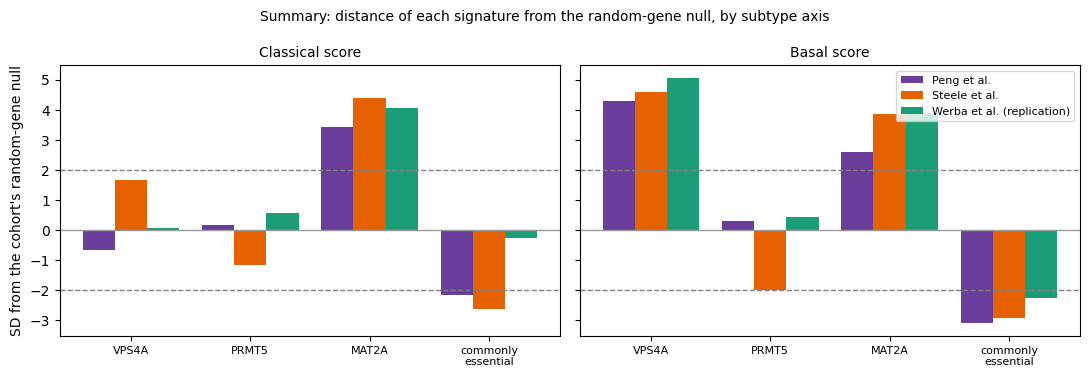

In [76]:
# ===========================================================================
# 40b · FIGURE - SUMMARY: distance from each cohort's random-gene null, both subtype axes
# ===========================================================================
# Pure consumer of SIG_SUMMARY (section 40a). One panel per subtype axis; in each, the four
# signatures in the three cohorts on the null-distance axis, with the +/-2 SD reference lines.
if FIGURES:
    _fig, _axs = plt.subplots(1, 2, figsize=(11.0, 3.8), sharey=True)
    _cols = [("Peng", "#6A3D9A", "Peng et al."), ("Steele", "#E66101", "Steele et al."),
             ("Werba", "#1B9E77", "Werba et al. (replication)")]
    _w = 0.27
    for _ax, _axis in zip(_axs, ["classical", "basal"]):
        _g = SIG_SUMMARY[SIG_SUMMARY["axis"] == _axis].reset_index(drop=True)
        _x = np.arange(len(_g))
        for j, (_c, colr, lab) in enumerate(_cols):
            _ax.bar(_x + (j - 1) * _w, _g[_c + " SD"], _w, color=colr, label=lab)
        for _yv in (-2, 2):
            _ax.axhline(_yv, color="0.5", ls="--", lw=1)
        _ax.axhline(0, color="0.6", lw=1)
        _ax.set_xticks(_x)
        _ax.set_xticklabels([s.replace("Commonly essential", "commonly\nessential") for s in _g["signature"]],
                            fontsize=8)
        _ax.set_title("{} score".format(_axis.capitalize()), fontsize=10)
    _axs[0].set_ylabel("SD from the cohort's random-gene null")
    _axs[1].legend(fontsize=8, loc="upper right")
    _fig.suptitle("Summary: distance of each signature from the random-gene null, by subtype axis", fontsize=10)
    plt.tight_layout()
    _show("summary_sd_from_null_both_axes")

## 41 · Reproduction check: Supplementary Table S2 and Supplementary Table S9b

Supplementary Table S2 and Supplementary Table S9b are regenerated here from the values of this run, in the layout of the manuscript, and compared value by value with the numbers printed in the manuscript (typed into the cell as `REPORTED`, the only place the notebook holds reported values). A coefficient matches if it agrees to the four decimals reported, a distance from the null if it agrees to the one decimal reported, and a p value if it rounds to the reported value at the reported precision (or lies below the reported bound, for "< 0.0001"). Any mismatch is listed, so a difference between the run and the manuscript cannot go unnoticed. The regenerated tables are written to `Table1_regenerated.csv` and `TableS9b_regenerated.csv`.

In [77]:
# ==========================================================================
# 41 · REPRODUCTION CHECK -- Supplementary Table S2 and Supplementary Table S9b, this run against the manuscript
# The rows are regenerated from SIG_SUMMARY (section 40a) in the manuscript's layout and compared with
# REPORTED, the values printed in the manuscript (Supplementary Table S2: Peng et al. and Steele et al.;
# Supplementary Table S9b: Werba et al.). REPORTED is the only place this notebook holds reported
# values; nothing else reads it.
#   rho  matches if it agrees to the 4 decimals reported
#   SD   matches if it agrees to the 1 decimal reported
#   P    matches if it rounds to the reported value at the reported precision, or, for "<0.0001",
#        if it lies below that bound
# Writes OUT_DIR/Table1_regenerated.csv and OUT_DIR/TableS9b_regenerated.csv.
# ==========================================================================

# (axis, signature, cohort): (rho, SD, P as printed)
REPORTED = {
    ("classical", "VPS4A", "Peng"): (-0.0365, -0.6, "0.152"), ("classical", "VPS4A", "Steele"): (+0.1573, +1.7, "0.049"),
    ("classical", "PRMT5", "Peng"): (+0.0325, +0.2, "0.069"), ("classical", "PRMT5", "Steele"): (-0.1242, -1.2, "0.013"),
    ("classical", "MAT2A", "Peng"): (+0.3094, +3.4, "<0.0001"), ("classical", "MAT2A", "Steele"): (+0.4290, +4.4, "0.0001"),
    ("classical", "Commonly essential", "Peng"): (-0.1650, -2.2, "0.0007"),
    ("classical", "Commonly essential", "Steele"): (-0.2687, -2.6, "0.0009"),
    ("basal", "VPS4A", "Peng"): (+0.2944, +4.3, "<0.0001"), ("basal", "VPS4A", "Steele"): (+0.3885, +4.6, "0.0001"),
    ("basal", "PRMT5", "Peng"): (+0.0223, +0.3, "0.252"), ("basal", "PRMT5", "Steele"): (-0.1924, -2.0, "0.0001"),
    ("basal", "MAT2A", "Peng"): (+0.1793, +2.6, "0.0001"), ("basal", "MAT2A", "Steele"): (+0.3234, +3.9, "0.0001"),
    ("basal", "Commonly essential", "Peng"): (-0.2084, -3.1, "0.0001"),
    ("basal", "Commonly essential", "Steele"): (-0.2724, -2.9, "0.0001"),
    ("classical", "VPS4A", "Werba"): (-0.0167, +0.1, "0.831"), ("classical", "PRMT5", "Werba"): (+0.0216, +0.6, "0.765"),
    ("classical", "MAT2A", "Werba"): (+0.2978, +4.1, "0.001"),
    ("classical", "Commonly essential", "Werba"): (-0.0442, -0.3, "0.413"),
    ("basal", "VPS4A", "Werba"): (+0.3040, +5.1, "0.001"), ("basal", "PRMT5", "Werba"): (+0.0043, +0.4, "0.638"),
    ("basal", "MAT2A", "Werba"): (+0.2287, +3.9, "0.001"),
    ("basal", "Commonly essential", "Werba"): (-0.1700, -2.2, "0.0068"),
}


def _p_matches(p, rep):
    """A computed p against the printed one: below the bound for '<x', else equal at the printed precision."""
    if not np.isfinite(p):
        return False
    if rep.startswith("<"):
        return p < float(rep[1:])
    dec = len(rep.split(".")[1]) if "." in rep else 0
    return round(p, dec) == round(float(rep), dec)


REPRO_CHECK = []
for (axis, sig, coh), (r_rep, sd_rep, p_rep) in REPORTED.items():
    _g = SIG_SUMMARY[(SIG_SUMMARY["axis"] == axis) & (SIG_SUMMARY["signature"] == sig)]
    rho, sd_, p_ = (float(_g[coh + " rho"].iloc[0]), float(_g[coh + " SD"].iloc[0]), float(_g[coh + " p"].iloc[0])) \
        if len(_g) else (np.nan, np.nan, np.nan)
    REPRO_CHECK.append(dict(axis=axis, signature=sig, cohort=coh,
                      rho=rho, rho_reported=r_rep, rho_ok=bool(np.isfinite(rho) and round(rho, 4) == round(r_rep, 4)),
                      sd=sd_, sd_reported=sd_rep, sd_ok=bool(np.isfinite(sd_) and round(sd_, 1) == round(sd_rep, 1)),
                      p=p_, p_reported=p_rep, p_ok=_p_matches(p_, p_rep)))
REPRO_CHECK = pd.DataFrame(REPRO_CHECK)
REPRO_CHECK["all_ok"] = REPRO_CHECK[["rho_ok", "sd_ok", "p_ok"]].all(axis=1)


def _fmt_p(p):
    """As the manuscript prints P: '<0.0001' when it rounds to zero at four decimals, four
    significant decimals below 0.01 (trailing zero dropped), three decimals otherwise."""
    if p < 5e-5:
        return "<0.0001"
    return "{:.4f}".format(p).rstrip("0") if p < 0.01 else "{:.3f}".format(p)


# the two tables in the manuscript's layout: one _row per axis x signature, cohorts side by side
for _name, _cohs, _fn in [("SUPPLEMENTARY TABLE S2 (discovery cohorts)", ["Peng", "Steele"], "Table1_regenerated.csv"),
                          ("SUPPLEMENTARY TABLE S9b (replication cohort)", ["Werba"], "TableS9b_regenerated.csv")]:
    _tab = SIG_SUMMARY[["axis", "signature"]].copy()
    for c in _cohs:
        _tab[c + " rho"] = SIG_SUMMARY[c + " rho"].map(lambda v: "{:+.4f}".format(v))
        _tab[c + " SD"] = SIG_SUMMARY[c + " SD"].map(lambda v: "{:+.1f}".format(v))
        _tab[c + " P"] = SIG_SUMMARY[c + " p"].map(_fmt_p)
    _tab.to_csv(out_path(_fn), index=False)
    print("{} -- regenerated from this run\n".format(_name))
    print(_tab.to_string(index=False))
    print()

_bad = REPRO_CHECK[~REPRO_CHECK["all_ok"]]
print("REPRODUCTION CHECK: {} of {} rows match the manuscript on rho, SD and P.".format(
    int(REPRO_CHECK["all_ok"].sum()), len(REPRO_CHECK)))
if len(_bad):
    print("\nrows that differ (this run | reported):")
    for _, r_ in _bad.iterrows():
        print("  {:<10}{:<20}{:<8} rho {:+.4f} | {:+.4f}{}   SD {:+.1f} | {:+.1f}{}   P {} | {}{}".format(
            r_["axis"], r_["signature"], r_["cohort"],
            r_["rho"], r_["rho_reported"], "" if r_["rho_ok"] else " *",
            r_["sd"], r_["sd_reported"], "" if r_["sd_ok"] else " *",
            _fmt_p(r_["p"]) if np.isfinite(r_["p"]) else "n/a", r_["p_reported"], "" if r_["p_ok"] else " *"))
    print("\n  * = differs. A difference means the manuscript and this run disagree; one of them must be updated.")
RESULTS["reproduction_check"] = REPRO_CHECK.round(5).to_dict(orient="records")

SUPPLEMENTARY TABLE S2 (discovery cohorts) -- regenerated from this run

     axis          signature Peng rho Peng SD  Peng P Steele rho Steele SD Steele P
classical              VPS4A  -0.0365    -0.6   0.152    +0.1573      +1.7    0.049
classical              PRMT5  +0.0325    +0.2   0.069    -0.1242      -1.2    0.013
classical              MAT2A  +0.3094    +3.4 <0.0001    +0.4290      +4.4   0.0001
classical Commonly essential  -0.1650    -2.2  0.0007    -0.2687      -2.6   0.0009
    basal              VPS4A  +0.2944    +4.3 <0.0001    +0.3885      +4.6   0.0001
    basal              PRMT5  +0.0223    +0.3   0.252    -0.1924      -2.0   0.0001
    basal              MAT2A  +0.1793    +2.6  0.0001    +0.3234      +3.9   0.0001
    basal Commonly essential  -0.2084    -3.1  0.0001    -0.2724      -2.9   0.0001

SUPPLEMENTARY TABLE S9b (replication cohort) -- regenerated from this run

     axis          signature Werba rho Werba SD Werba P
classical              VPS4A   -0.0167 

# Part IX · Manuscript figures

*Figure legends.* Figs. 1–7 are drawn in sections 43–49, one section per figure, and Supplementary Fig. S3 in section 50. The other Supplementary Figures are drawn by the analysis sections that compute them: S1 in section 23c, S2 in section 22b, S4 in section 29b, S5 in section 28b, S6 in section 30b, S7 in section 24a and S8 in section 25b.

**How the figures are generated.**

- **Only computed objects are drawn.** Every panel reads a table or object an analysis section built (for example `CLASSICAL_TAB`, `BASAL_TAB`, `VB_TAB`, `NULL_TAB`, `FOREST`, `DEPMAP_VAL`, `POSB`, `NEGB`, `CTXT3`, `RESULTS`) or recomputes a coefficient with the same deterministic helper (`ps_vs`). No figure cell changes a number in the manuscript, and none uses a random number except display jitter.
- **Each figure checks itself against the analysis.** Section 42b rebuilds the per-patient coefficients of all four signatures on both axes in all three cohorts and stops if their means differ from the analysis tables by more than 10⁻⁶; Fig. 4 stops if its rows differ from section 32's; each figure cell asserts at its top that the analysis objects it needs exist and names the section to run if one is missing.
- **Layout is verified, not eyeballed.** Each figure is drawn at its printed size (7.0 in wide, the 180 mm double column) with 6–7.5 pt text. Every panel is a single box (plotting area with its tick labels, axis labels, title and legend); `fbox_check` and `fig_layout_check` confirm on every run that no two boxes intersect, that panels side by side share their top and bottom edges, and that no large area is left empty, and print one verdict line per figure.
- **Consistent encoding.** Peng et al. purple filled diamonds, Steele et al. orange open circles, Werba et al. green filled squares; marker shape is a second encoding, so no comparison relies on colour alone. Gene symbols are set in italics, including their digits.
- **Outputs.** Each figure is written as a 300-dpi PNG and a vector PDF to `OUT_DIR/manuscript_figures/`, together with the table behind any panel that is not already a saved analysis table.

## 42 · Figure settings and set-up

**42a** defines the print settings and helpers that Supplementary Fig. S3 (section 50) uses, and `_umap_xy`, the uncorrected UMAP of an inferCNV subsample that Fig. 1a–c displays (cached; it enters no statistic). **42b** sets up Figs. 1–7: the cohort encoding, the fonts that set whole gene symbols in italics, the per-patient coefficients `RHO` with their check against the analysis tables, the random-gene nulls on each axis, and the panel, legend, layout-check and save helpers.

In [78]:
# ==========================================================================
# 42a · FIGURE SETTINGS SHARED BY SECTIONS 43-50, AND THE DISPLAY UMAP
# Print settings and helpers for the figures drawn at printed size:
#   FIG_DPI, FIG_SIZE, FIG_RC   resolution, printed size of Supplementary Fig. S3, font settings
#                               (MS_RC, section 21: 6-7 pt text, 7.5 pt panel titles)
#   _panel, _despine            panel letters and titles, and spines, as in the manuscript figures
#   _umap_xy                    the uncorrected UMAP of an inferCNV subsample, shown in Fig. 1a-c
# Each figure uses constrained layout (ms_figure), keeps every legend and label outside the
# plotting areas, and is checked box by box before it is saved (fig_layout_check, section 21).
# MS_RC is applied with plt.rc_context, so figures outside sections 43-50 are untouched. No
# statistic is computed here.
# ==========================================================================

FIG_DPI = 300                                       # every figure drawn for print is written at 300 dpi
FIG_SIZE = {"S3": (6.5, 3.0)}                       # printed size (inches): Supplementary Fig. S3
FIG_RC = MS_RC


def _panel(ax, letter, title):
    """Panel letter and title, left-aligned above the axes."""
    ax.set_title("{}   {}".format(letter, title), loc="left", fontsize=7.5)


def _despine(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


def _lognorm_x(a):
    """The expression matrix as log-normalised values. The inferCNV files carry the matrix
    section 10 read (log-normalised in every cohort); if a file ever arrives with raw counts
    (values far above what log1p of 10,000-count data can reach), normalise it the same way
    Steele et al. was normalised in Methods, so the UMAP is built on comparable values."""
    b = sc.AnnData(X=a.X.copy(), obs=pd.DataFrame(index=a.obs_names), var=pd.DataFrame(index=a.var_names))
    if float(b.X.max()) > 50:                       # .max() works on dense and sparse matrices
        sc.pp.normalize_total(b, target_sum=1e4)
        sc.pp.log1p(b)
    return b


def _umap_xy(a, cohort):
    """Uncorrected UMAP of one inferCNV subsample: 2,000 highly variable genes, scaled, 30
    principal components, 15-neighbour graph, UMAP. Display only -- no statistic uses it.
    Cached to OUT_DIR so a re-run redraws instantly; random_state fixes the layout without
    touching any other analysis's random stream."""
    cache = out_path("fig1_umap_{}.csv".format(cohort))
    if os.path.exists(cache) and not RECOMPUTE:
        xy = pd.read_csv(cache, index_col=0)
        if list(xy.index.astype(str)) == list(a.obs_names.astype(str)):
            return xy.values
    b = _lognorm_x(a)
    sc.pp.highly_variable_genes(b, n_top_genes=min(2000, b.n_vars - 1))
    b = b[:, b.var["highly_variable"].values].copy()
    sc.pp.scale(b, max_value=10)
    sc.tl.pca(b, n_comps=min(30, b.n_vars - 1, b.n_obs - 1), random_state=SEED)
    sc.pp.neighbors(b, n_neighbors=15, random_state=SEED)
    sc.tl.umap(b, random_state=SEED)
    xy = pd.DataFrame(b.obsm["X_umap"], index=a.obs_names, columns=["UMAP1", "UMAP2"])
    xy.to_csv(cache)
    return xy.values


print("figure settings defined | figures ->", out_path("manuscript_figures"))

figure settings defined | figures -> C:\Users\The_R/Downloads\pdac_results\manuscript_figures


In [79]:
# ==========================================================================
# 42b · FIGURE SET-UP FOR FIGS. 1-7   (run once, after the last analysis cell; sections 43-49 need it)
#
# Seven manuscript figures, each drawn ONLY from objects the notebook has already computed,
# with all three cohorts wherever a panel is about the single-cell data (Fig. 2 is DepMap-only).
# Nothing in these cells changes a number in the manuscript: every coefficient is either read from
# a table the analysis cells built (CLASSICAL_TAB, BASAL_TAB, VB_TAB, NULL_TAB, POSB, NEGB, CTXT3, DEPMAP_VAL, PD,
# CNVT, RESULTS) or recomputed with the same deterministic helper (ps_vs) and checked against it.
#
# LAYOUT RULES (every figure obeys them, and fbox_check below verifies them on every run):
#   1. Every panel is ONE BOX: its plotting area plus everything that belongs to it -- tick labels,
#      axis labels, title, legend and any text beside it. No two boxes may touch or intersect,
#      and the figure-wide cohort legend is a box of its own.
#   2. Panels side by side in a row are PARALLEL: their plotting areas have exactly the same
#      height and the same top and bottom edges. A stacked column beside a tall panel is split
#      into equal heights; the only panel allowed to break a row is one that takes up the whole
#      right-hand side of its figure (Figs. 4 and 5).
#   3. Each row (or the stacked column, or the tall right panel) is a matplotlib SUBFIGURE, so the
#      layout engine places its contents inside its own region and cannot push them into another.
#
# WHY the per-patient coefficients are rebuilt here: the panels need all four signatures on BOTH
# subtype axes for ALL three cohorts in one structure (RHO below). They are rebuilt with the same
# deterministic helper, and the cell stops if the rebuilt means differ from CLASSICAL_TAB /
# BASAL_TAB by more than 1e-6 or from the objects of sections 19 and 20 by more than 1e-9.
#
# WHY a custom maths font: gene symbols are italic (gi, §21), drawn with matplotlib's \mathit.
# In the default maths font \mathit leaves DIGITS upright (PRMT5 would show an upright 5, MAT2A an upright 2);
# the 'custom' fontset maps \mathit to the italic face of the text font, so every character of
# a symbol is italic.
#
# Style: the manuscript's conventions -- Peng et al. purple filled diamonds, Steele et al. orange open
# circles, Werba et al. green filled squares (validated as a 3-colour categorical set, all pairs,
# incl. colour-vision deficiency; marker shape is the second encoding). Drawn at printed size,
# 7.0 in wide (Scientific Reports' 180 mm double column), 6-7.5 pt text, written at 300 dpi as
# PNG plus a vector PDF.
# ==========================================================================

import os, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from matplotlib.ticker import MaxNLocator          # Fig. 2h: fewer x ticks in a narrow panel

# ---- everything the seven figures read must already exist (run the notebook top to bottom) ----
_FIG_NEED = ["mal", "steele", "werba", "s_res", "w_res", "null", "s_null", "w_null", "CLASSICAL_TAB", "BASAL_TAB",
             "VB", "VB_TAB", "NULL_TAB", "RESULTS", "ps_vs", "stat_row", "boot_ci", "emp_p", "sd_from",
             "mean_rho", "ms_figure", "ms_legend", "fig_layout_check", "LAYOUT", "MS_RC", "gi", "out_path",
             "_show", "SEED", "TARGETS"]
_missing = [n for n in _FIG_NEED if n not in globals()]
assert not _missing, "run the analysis cells first -- missing: {}".format(", ".join(_missing))

FIG_DIR3 = out_path("manuscript_figures")                 # every figure lands here, PNG + PDF
os.makedirs(FIG_DIR3, exist_ok=True)
FIG_W = 7.0                                            # printed width (in) -- 180 mm double column
FIG_DPI3 = 300

# ---- cohort encoding: (label, marker, colour, marker face) -- shape AND colour, never colour alone
COH3 = [("Peng", "D", "#6A3D9A", "#6A3D9A"),           # filled diamond
        ("Steele", "o", "#E66101", "white"),           # open circle
        ("Werba", "s", "#1B9E77", "#1B9E77")]          # filled square
COH3_N = {"Peng": "Peng et al.", "Steele": "Steele et al.", "Werba": "Werba et al."}
FIG_COHORTS = [("Peng", mal), ("Steele", steele), ("Werba", werba)]
OTHER_GREY = "0.62"                                    # 'the rest' in per-gene panels (Figs. 4, 5)

# ---- the four signatures every single-cell panel shows, and the two subtype axes ----------------
FIG_SIGS = [("VPS4A", "VPS4A_sig"), ("PRMT5", "PRMT5_sig"), ("MAT2A", "MAT2A_sig"),
            ("commonly essential", "CE_sig")]
FIG_AXES = {"classical": "classical_score", "basal": "basal_score"}

# ---- RHO[(cohort, axis)][signature] = {patient: within-patient partial rho} -----------------------
# Same helper (ps_vs) and same QC covariates as every reported test; deterministic.
RHO = {}
for _lab, _ad in FIG_COHORTS:
    for _ax, _scol in FIG_AXES.items():
        RHO[(_lab, _ax)] = {nm: ps_vs(_ad.obs, col, state_col=_scol) for nm, col in FIG_SIGS}

# guard: the rebuilt means must equal the tables the reported numbers come from
_CLS_NAME = {"commonly essential": "common_essential"}            # §28b's spelling
_BAS_NAME = {"commonly essential": "CE"}                          # §31a's spelling
for _lab, _ in FIG_COHORTS:
    for nm, _ in FIG_SIGS:
        _c = CLASSICAL_TAB[(CLASSICAL_TAB["cohort"] == _lab) & (CLASSICAL_TAB["signature"] == _CLS_NAME.get(nm, nm))]["mean_rho"].iloc[0]
        _b = BASAL_TAB[(BASAL_TAB["cohort"] == _lab) & (BASAL_TAB["signature"] == _BAS_NAME.get(nm, nm))]["mean"].iloc[0]
        assert abs(mean_rho(RHO[(_lab, "classical")][nm]) - _c) < 1e-6, "classical mismatch: {} {}".format(_lab, nm)
        assert abs(mean_rho(RHO[(_lab, "basal")][nm]) - _b) < 1e-6, "basal mismatch: {} {}".format(_lab, nm)
# and the Steele / Werba classical dicts must equal the objects of sections 19 and 20
for _lab, _old in [("Steele", s_res), ("Werba", w_res)]:
    for nm, key in [("VPS4A", "VPS4A"), ("PRMT5", "PRMT5"), ("MAT2A", "MAT2A"), ("commonly essential", "common_essential")]:
        assert abs(mean_rho(RHO[(_lab, "classical")][nm]) - mean_rho(_old[key])) < 1e-9

# ---- the random-gene nulls on each axis (sections 15 / 19 / 20 on the classical axis; §31a basal) --
FIG_NULL = {("Peng", "classical"): np.asarray(null), ("Steele", "classical"): np.asarray(s_null),
            ("Werba", "classical"): np.asarray(w_null)}
for _lab, _ in FIG_COHORTS:
    FIG_NULL[(_lab, "basal")] = np.asarray(VB["nulls"][_lab][("random", "basal")])

# ---- fonts: §21's manuscript sizes (6-7.5 pt) + maths fonts that italicise the WHOLE gene symbol ----
# gi() writes gene symbols as $\mathit{PRMT5}$. In matplotlib <= 3.10, \mathit italicises letters
# only: any non-letter (the 5 of PRMT5, the 2 of MAT2A, the 4 of VPS4A) is drawn from the
# 'mathtext.rm' font instead (_mathtext.UnicodeFonts._get_glyph, "Only characters in the 'Letter'
# class should be italicized"), so the digits came out upright. Pointing 'rm' at the italic face
# as well makes the digits italic in 3.9, 3.10 and 3.11 alike (checked on all three). Safe here
# because the only maths in these figures is gi()'s \mathit and fpanel()'s \bf (panel letters,
# bold face, unaffected); tick labels are plain text, not maths, so numbers stay upright.
FIG_RC3 = dict(MS_RC)
FIG_RC3.update({"axes.titlepad": 3.0, "legend.handletextpad": 0.3, "legend.columnspacing": 1.0,
                "mathtext.fontset": "custom", "mathtext.rm": "sans:italic", "mathtext.it": "sans:italic",
                "mathtext.bf": "sans:bold", "hatch.linewidth": 0.4})
# NB everything is drawn inside `with plt.rc_context(FIG_RC3)`, including the save and the inline
# display; a figure re-drawn after the cell ends (e.g. re-saved by hand) would lose these fonts.


# ---- small helpers -------------------------------------------------------------------------------
def fsumm(rhos):
    """n, mean, 95% patient-bootstrap CI and Wilcoxon p of a {patient: rho} dict (§21's stat_row)."""
    r_ = stat_row("", rhos)
    return dict(n=r_["n"], mean=r_["mean"], lo=r_["ci_lo"], hi=r_["ci_hi"], p=r_["p"])


def fpanel(ax, letter, title):
    """Bold panel letter, then a SHORT title, left-aligned above the axes. The letter is stored on
    the axes so fbox_check can name the panel. Keep titles shorter than the panel is wide: a title
    is part of its panel's box, and an overlong one would cross into the neighbour's."""
    ax.set_title(r"$\bf{" + letter + "}$   " + title, loc="left")
    ax._fig_letter = letter


def fdespine(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


def fmark(ax, x, y, lab, xerr=None, yerr=None, ms=3.4, **kw):
    """One cohort's mean (and CI bar) in that cohort's marker; errorbar keeps marker and bar together."""
    _, mk, colr, fill = next(c for c in COH3 if c[0] == lab)
    return ax.errorbar(x, y, xerr=xerr, yerr=yerr, fmt=mk, color=colr, mfc=fill, mec=colr, ms=ms,
                       capsize=1.2, elinewidth=0.8, mew=0.8, zorder=4, **kw)


def fcohort_handles(cohorts=("Peng", "Steele", "Werba"), null_label=None, null_alpha=0.15):
    """Legend handles + labels for the cohorts drawn (marker and colour). With `null_label`, one
    more entry for fnull_band's grey band (same colour; alpha a little above a single band's so the
    swatch is visible at 6 pt), so the shaded nulls are explained in the figure, not only in the
    legend text: unexplained marks read as noise (the Fig. 6 hatch did)."""
    hs = [Line2D([], [], ls="", marker=mk, color=colr, mfc=fill, mec=colr, ms=4)
          for lab, mk, colr, fill in COH3 if lab in cohorts]
    ls = [COH3_N[c] for c in cohorts]
    if null_label:
        hs.append(Rectangle((0, 0), 1, 1, color="0.4", alpha=null_alpha, lw=0))
        ls.append(null_label)
    return hs, ls


# ---- numbers in panel text: true minus signs, and P in m x 10^-k form ----------------------------
# Python formats negatives with a hyphen ("-0.44"), but the tick labels use the true minus sign
# ("−0.44"), so panel text and axes disagreed; and "1.0e-34" is code notation, not a journal's.
# The exponent uses Unicode superscripts (plain text), NOT mathtext: mathtext.rm is italic in
# FIG_RC3, so $10^{-34}$ would come out italic.
_SUP = str.maketrans("-0123456789", "⁻⁰¹²³⁴⁵⁶⁷⁸⁹")


def fnum(x, spec="{:+.2f}"):
    """Format a number with a true minus sign (U+2212) instead of a hyphen."""
    return spec.format(x).replace("-", "−")


def fP(p, small=1e-3):
    """P for display: three decimals down to 0.001, below that 'm × 10⁻ᵏ' (one decimal in m)."""
    if p is None or not np.isfinite(p):
        return "n/a"
    if p >= small:
        return "{:.3f}".format(p)
    m, e = "{:.1e}".format(p).split("e")
    return "{} × 10{}".format(m, str(int(e)).translate(_SUP))


def fnull_band(ax, nd, orient="v", y0=None, y1=None, alpha=0.10):
    """Random-null mean +/- 2 SD as a grey band; across the whole axis, or only over [y0, y1]."""
    lo, hi = nd.mean() - 2 * nd.std(), nd.mean() + 2 * nd.std()
    if y0 is None:
        (ax.axvspan if orient == "v" else ax.axhspan)(lo, hi, color="0.4", alpha=alpha, lw=0, zorder=0)
    elif orient == "v":
        ax.add_patch(Rectangle((lo, y0), hi - lo, y1 - y0, color="0.4", alpha=alpha, lw=0, zorder=0))
    else:
        ax.add_patch(Rectangle((y0, lo), y1 - y0, hi - lo, color="0.4", alpha=alpha, lw=0, zorder=0))
    return lo, hi


def fitalic_ticks(ax, axis="x"):
    """Italicise every tick label of one axis (gene symbols that gi() does not know, e.g. KLF5)."""
    for tl in (ax.get_xticklabels() if axis == "x" else ax.get_yticklabels()):
        tl.set_fontstyle("italic")


def flegend_below(fig, ax, handles, labels, gap_pt=3.0, **kw):
    """A legend hung directly below a panel's x-axis label (or tick labels), inside that panel's box.
    The label's height depends on the layout, so the position is measured on the drawn figure and
    re-set until it settles (constrained layout re-runs on every draw). Every legend hung this way in
    the figure is re-settled together, so a later one cannot leave an earlier one stale."""
    lg = ax.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, -0.3), frameon=False,
                   borderaxespad=0.0, **kw)
    if not hasattr(fig, "_below_legends"):
        fig._below_legends = []
    fig._below_legends.append((ax, lg))
    for _ in range(4):
        fig.canvas.draw()
        rnd = fig.canvas.get_renderer()
        for a_, l_ in fig._below_legends:
            parts = [t.get_window_extent(rnd) for t in [a_.xaxis.label] + a_.get_xticklabels()
                     if t.get_visible() and str(t.get_text()).strip()]
            y0 = min(b.y0 for b in parts) if parts else a_.get_window_extent(rnd).y0
            y_ax = a_.transAxes.inverted().transform((0, y0 - gap_pt * fig.dpi / 72.0))[1]
            l_.set_bbox_to_anchor((0.5, y_ax), transform=a_.transAxes)
    return lg


def fbox_check(fig, name, rows=(), cols=()):
    """LAYOUT RULES 1-2, measured on the drawn figure.
    Rule 1: each panel's box = its axes' tight bounding box (plotting area, tick labels, axis labels,
            title, its own legend, its texts); each figure-level legend is a box too. No two boxes may
            overlap by more than one point in both directions.
    Rule 2: `rows` lists groups of panel letters side by side, which must be parallel: same
            plotting-area height AND the same top edge, to within half a point. `cols` lists stacked
            groups (the column beside a tall panel), which must have the same plotting-area height.
    Prints one verdict and the offending pairs; returns True if both rules hold."""
    fig.canvas.draw()
    rnd = fig.canvas.get_renderer()

    def walk(f):
        yield f
        for sf in getattr(f, "subfigs", []):
            yield from walk(sf)
    figs = list(walk(fig))
    axes = list({id(a): a for f in figs for a in f.axes}.values())
    boxes = [("panel " + getattr(a, "_fig_letter", "?"), a.get_tightbbox(rnd)) for a in axes if a.get_visible()]
    boxes += [("figure legend", lg.get_window_extent(rnd)) for f in figs for lg in f.legends]
    tol = fig.dpi / 72.0
    hits = []
    for i in range(len(boxes)):
        for j in range(i + 1, len(boxes)):
            (na, a), (nb, b) = boxes[i], boxes[j]
            if min(a.x1, b.x1) - max(a.x0, b.x0) > tol and min(a.y1, b.y1) - max(a.y0, b.y0) > tol:
                hits.append("{} x {}".format(na, nb))
    bad_rows = []
    by_letter = {getattr(a, "_fig_letter", None): a for a in axes}
    for grp, same_top in [(g, True) for g in rows] + [(g, False) for g in cols]:
        ext = [by_letter[l].get_window_extent(rnd) for l in grp if l in by_letter]
        if ext and (max(e.height for e in ext) - min(e.height for e in ext) > tol / 2 or
                    (same_top and max(e.y1 for e in ext) - min(e.y1 for e in ext) > tol / 2)):
            bad_rows.append("".join(grp))
    ok = not hits and not bad_rows
    print("{} panel boxes: {} boxes | overlapping pairs: {} | groups not parallel / not equal: {} -> {}".format(
        name, len(boxes), "; ".join(hits) or "none", ", ".join(bad_rows) or "none", "OK" if ok else "CHECK"))
    return ok


# ---- lettering: first letter of each label capitalised (Scientific Reports figure guidelines) ----
# Applied by fsave to every Text artist and to FixedFormatter tick labels before the layout checks.
# Left alone: maths at the start ($...$: gene symbols, bold panel letters), labels whose first letter
# is not a-z (Greek, digits, signs) and one-letter words (panel references such as "c only"). A
# leading panel letter ("a   title", as _panel writes it) is kept and the title after it is checked.
import re as _re
from matplotlib.text import Text as _Text
from matplotlib.axes import Axes as _Axes
from matplotlib.ticker import FixedFormatter as _FixedF

_FIG_WORDS = [("tumours", "tumors"), ("tumour", "tumor")]          # the manuscript's US spelling
_PANEL_PREFIX = _re.compile(r"^(\$\\bf\{[a-z]\}\$|[a-z])(\s{2,})(.*)$", _re.S)


def _sentence(s):
    s = str(s)
    for a_, b_ in _FIG_WORDS:
        s = s.replace(a_, b_)
    m_ = _PANEL_PREFIX.match(s)
    if m_:
        return m_.group(1) + m_.group(2) + _sentence(m_.group(3))
    t_ = s.lstrip()
    lead = len(s) - len(t_)
    k_ = 0
    while k_ < len(t_) and t_[k_] in "+( ":
        k_ += 1
    if k_ >= len(t_) or not ("a" <= t_[k_] <= "z"):
        return s
    j_ = k_
    while j_ < len(t_) and t_[j_].isalpha():
        j_ += 1
    if j_ - k_ == 1:
        return s
    i_ = lead + k_
    return s[:i_] + s[i_].upper() + s[i_ + 1:]


def fsentence(fig):
    """Capitalise the first letter of every label of a figure (in place)."""
    for txt in fig.findobj(_Text):
        old = txt.get_text()
        new = _sentence(old)
        if new != old:
            txt.set_text(new)
    for ax in fig.findobj(_Axes):
        for axis in (ax.xaxis, ax.yaxis):
            fmt = axis.get_major_formatter()
            if isinstance(fmt, _FixedF):
                fmt.seq = [_sentence(x) for x in fmt.seq]


def fsave(fig, stem, label, rows=(), cols=()):
    """Both layout checks (§21's fig_layout_check, and fbox_check's panel boxes), then PNG + PDF."""
    fsentence(fig)                                  # lettering first, so the checks see the final text
    LAYOUT[label] = fig_layout_check(fig, label)
    LAYOUT[label]["boxes_ok"] = fbox_check(fig, label, rows, cols)
    for ext in ("png", "pdf"):
        fig.savefig(os.path.join(FIG_DIR3, "{}.{}".format(stem, ext)), dpi=FIG_DPI3, bbox_inches="tight")
    _show(stem)
    print("wrote {}.png / .pdf to {}".format(stem, FIG_DIR3))


print("figure setup done | output folder:", FIG_DIR3)
for _lab, _ in FIG_COHORTS:
    print("  {:<7} classical: ".format(_lab) +
          " | ".join("{} {:+.3f}".format(nm, mean_rho(RHO[(_lab, 'classical')][nm])) for nm, _ in FIG_SIGS))
    print("  {:<7} basal:     ".format("") +
          " | ".join("{} {:+.3f}".format(nm, mean_rho(RHO[(_lab, 'basal')][nm])) for nm, _ in FIG_SIGS))

figure setup done | output folder: C:\Users\The_R/Downloads\pdac_results\manuscript_figures
  Peng    classical: VPS4A -0.036 | PRMT5 +0.033 | MAT2A +0.309 | commonly essential -0.165
          basal:     VPS4A +0.294 | PRMT5 +0.022 | MAT2A +0.179 | commonly essential -0.208
  Steele  classical: VPS4A +0.157 | PRMT5 -0.124 | MAT2A +0.429 | commonly essential -0.269
          basal:     VPS4A +0.389 | PRMT5 -0.192 | MAT2A +0.323 | commonly essential -0.272
  Werba   classical: VPS4A -0.017 | PRMT5 +0.022 | MAT2A +0.298 | commonly essential -0.044
          basal:     VPS4A +0.304 | PRMT5 +0.004 | MAT2A +0.229 | commonly essential -0.170


## 43 · Fig. 1: most malignant-compartment cells are aneuploid in all three cohorts

(a–c) Uncorrected UMAP of each cohort's 8,000-cell inferCNV subsample, coloured by compartment. (d–f) Inferred copy-number score by compartment, divided by the 95th percentile of the cohort's diploid immune and stromal reference, so the dashed line at 1 is the aneuploidy threshold; panel titles give the ratio of mean malignant to mean reference score and the percentage of malignant cells above the threshold. (g) Per patient, the fraction of malignant-compartment cells that are copy-number positive against that patient's own immune, stromal and normal epithelial reference. Reads the files section 10 wrote and the per-patient calls of section 23. `CNV_PER_CELL = False` draws section 10's score and reproduces the reported values; the cell header explains the alternative.

Peng    8,000 cells | cluster score (section 10, manuscript): 2.70x, 84.2% above | per-cell score: 3.31x, 72.9% above
Steele  8,000 cells | cluster score (section 10, manuscript): 2.51x, 64.3% above | per-cell score: 3.10x, 57.7% above
Werba   8,000 cells | cluster score (section 10, manuscript): 1.56x, 57.4% above | per-cell score: 1.76x, 46.3% above
Fig. 1 layout: 64 boxes, 0 intersecting pair(s); largest empty area 4.31 x 0.25 in (2.8% of the figure) -> OK
Fig. 1 panel boxes: 8 boxes | overlapping pairs: none | groups not parallel / not equal: none -> OK


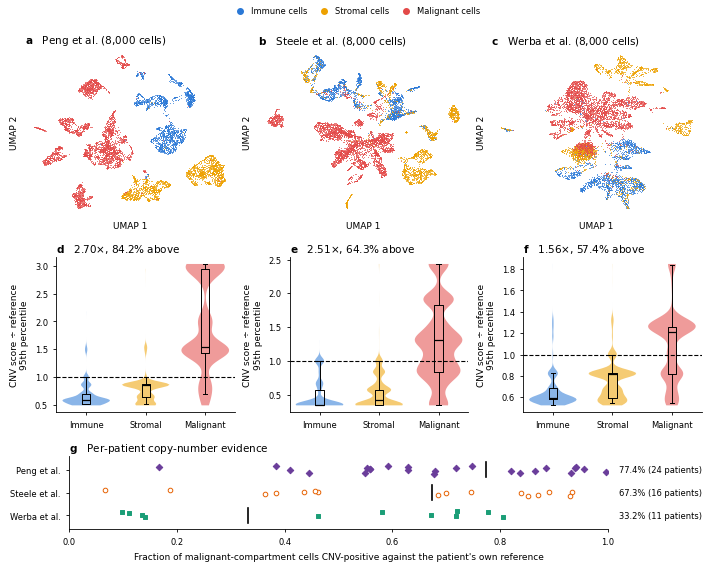

wrote Fig1_malignant_identity.png / .pdf to C:\Users\The_R/Downloads\pdac_results\manuscript_figures


In [80]:
# ==========================================================================
# 43 · FIG. 1 -- the malignant compartment is aneuploid in all three cohorts
# Layout: three rows, each its own subfigure; every panel in a row has the same height.
# (a-c) uncorrected UMAP of each cohort's 8,000-cell inferCNV subsample (section 10: 4,000
#       malignant, 2,000 immune, 2,000 stromal cells), coloured by compartment
# (d-f) inferred copy-number score by compartment, divided by the 95th percentile of that cohort's
#       diploid (immune + stromal) reference, so the dashed line at 1 is the aneuploidy threshold;
#       the panel title gives mean malignant / mean reference score and the % of malignant cells
#       above the reference 95th percentile
# (g)   per patient, the fraction of malignant-compartment cells that are CNV-positive against that
#       patient's OWN reference (immune + stromal + normal epithelium; §23, a PER-CELL score), one
#       point per patient; the vertical bar and the number are each cohort's pooled fraction
#
# IMPORTANT -- what section 10's score is. infercnvpy's tl.cnv_score() is a CLUSTER score: every cell
# is given the mean |CNV| of its cnv_leiden cluster ("Assign each cnv cluster a CNV score"). That is
# why the violins in (d-f) are lumpy and flat-topped, and it means the manuscript's 2.70x / 84.2%,
# 2.51x / 64.3% and 1.56x / 57.4% are fractions of malignant cells IN CLUSTERS above the threshold,
# not of cells. This cell prints both versions every run:
#   CNV_PER_CELL = False -> panels use section 10's cluster score (reproduces the manuscript's numbers)
#   CNV_PER_CELL = True  -> panels use each cell's own mean |CNV| (from the stored X_cnv matrix), the
#                           same per-cell definition §23 uses; Methods and the Fig. 1 numbers must then
#                           be updated to the printed per-cell values
# The only new computation is the display UMAP (section 42a's _umap_xy, cached in OUT_DIR).
# ==========================================================================

assert "RHO" in globals(), "run section 42b first"
assert "_umap_xy" in globals(), "run section 42a first (it defines _umap_xy, the display UMAP)"

CNV_PER_CELL = False                                   # see the header: False = section 10's cluster score

COMP3 = [("Immune cells", "Immune", "#2a78d6"),        # (label in the file, short name, colour)
         ("Stromal cells", "Stromal", "#eda100"),      # validated 3-colour set (all pairs, CVD);
         ("Malignant cells", "Malignant", "#e34948")]  # names are also on the violin axis
FIG1_FILES = [("Peng", PENG_CNV, MAL_COL), ("Steele", STEELE_CNV, "ref_label"),
              ("Werba", WERBA_CNV, "ref_label")]


def _ratio_above(score, labs):
    """Section 10's two numbers: mean malignant / mean reference score, and the fraction of malignant
    cells above the reference's 95th percentile (np.quantile == pandas .quantile, linear)."""
    ref = score[np.isin(labs, ["Immune cells", "Stromal cells"])]
    malv = score[labs == "Malignant cells"]
    r95 = float(np.quantile(ref, 0.95))
    return float(malv.mean() / ref.mean()), float((malv > r95).mean()), r95


F1 = {}
for _lab, _path, _lcol in FIG1_FILES:
    if not os.path.exists(_path):
        print("{}: {} missing -- section 10 writes it; panel left empty".format(_lab, os.path.basename(_path)))
        continue
    _a = sc.read_h5ad(_path)
    _labs = _a.obs[_lcol].astype(str).values
    _clu = _a.obs["cnv_score"].astype(float).values                     # section 10: cluster score
    _rc, _ac, _r95c = _ratio_above(_clu, _labs)
    _cell = None
    if "X_cnv" in _a.obsm:                                               # per-cell mean |CNV|
        _X = _a.obsm["X_cnv"]
        _cell = np.asarray(abs(_X).mean(axis=1)).ravel()
        _rp, _ap, _r95p = _ratio_above(_cell, _labs)
    print("{:<7} {:,} cells | cluster score (section 10, manuscript): {:.2f}x, {:.1%} above | per-cell score: {}".format(
        _lab, _a.n_obs, _rc, _ac, "{:.2f}x, {:.1%} above".format(_rp, _ap) if _cell is not None else "X_cnv not stored"))
    use_cell = CNV_PER_CELL and _cell is not None
    _sco, _r, _ab, _r95 = (_cell, _rp, _ap, _r95p) if use_cell else (_clu, _rc, _ac, _r95c)
    F1[_lab] = dict(xy=_umap_xy(_a, _lab), lab=_labs, norm=_sco / _r95, n=_a.n_obs, ratio=_r, above=_ab,
                    ratio_cluster=_rc, above_cluster=_ac,
                    ratio_cell=_rp if _cell is not None else np.nan, above_cell=_ap if _cell is not None else np.nan)
    del _a
    gc.collect()

# per-patient CNV-positive fraction against each patient's own reference (§23b / §23c)
F1G = {}
for _lab, _ in FIG_COHORTS:
    if "CNVT" in globals() and _lab in CNVT:
        _m = CNVT[_lab][CNVT[_lab]["role"] == "malignant"]
        F1G[_lab] = dict(per=_m.groupby("Patient")["cnv_pos"].mean(), pooled=float(_m["cnv_pos"].mean()))

with plt.rc_context(FIG_RC3):
    fig = ms_figure((FIG_W, 5.6))
    _r1, _r2, _r3 = fig.subfigures(3, 1, height_ratios=[1.0, 0.95, 0.62])
    ax_u = _r1.subplots(1, 3)                                            # row 1: a-c
    ax_v = _r2.subplots(1, 3)                                            # row 2: d-f
    ax_g = _r3.subplots(1, 1)                                            # row 3: g

    for j, (_lab, _, _) in enumerate(FIG1_FILES):
        # (a-c) UMAP: reference compartments first, malignant last, so malignant cells are not hidden
        ax = ax_u[j]
        if _lab in F1:
            d = F1[_lab]
            for key, _short, colr in COMP3:
                m = d["lab"] == key
                ax.scatter(d["xy"][m, 0], d["xy"][m, 1], s=0.5, color=colr, alpha=0.6, lw=0, rasterized=True)
        ax.set_xticks([]); ax.set_yticks([])
        for s_ in ax.spines.values():
            s_.set_visible(False)
        ax.set_xlabel("UMAP 1"); ax.set_ylabel("UMAP 2")
        fpanel(ax, "abc"[j], "{} ({:,} cells)".format(COH3_N[_lab], F1[_lab]["n"] if _lab in F1 else 0))

        # (d-f) normalised CNV score per compartment: violin = distribution, box = median and IQR
        ax = ax_v[j]
        if _lab in F1:
            d = F1[_lab]
            data = [d["norm"][d["lab"] == key] for key, _, _ in COMP3]
            vp = ax.violinplot(data, positions=range(3), widths=0.8, showextrema=False)
            for body, (_, _, colr) in zip(vp["bodies"], COMP3):
                body.set_facecolor(colr); body.set_edgecolor("none"); body.set_alpha(0.55)
            ax.boxplot(data, positions=range(3), widths=0.14, whis=(5, 95), showfliers=False,
                       medianprops=dict(color="k", lw=0.9), boxprops=dict(lw=0.7),
                       whiskerprops=dict(lw=0.7), capprops=dict(lw=0.7))
            fpanel(ax, "def"[j], "{:.2f}×, {:.1%} above".format(d["ratio"], d["above"]))
        ax.axhline(1.0, color="k", ls="--", lw=0.8)
        ax.set_xticks(range(3)); ax.set_xticklabels([s_ for _, s_, _ in COMP3])
        ax.set_ylabel("CNV score ÷ reference\n95th percentile")
        fdespine(ax)

    # (g) per-patient CNV-positive fraction, own-patient reference (pooled fraction written at right)
    ax = ax_g
    _jit = np.random.default_rng(SEED + 901)          # display jitter only, own stream
    for k, (_lab, mk, colr, fill) in enumerate(COH3):
        if _lab not in F1G:
            continue
        yk = 2 - k
        v = F1G[_lab]["per"].values
        ax.scatter(v, yk + _jit.uniform(-0.18, 0.18, len(v)), marker=mk, s=11, color=colr,
                   facecolors=fill, edgecolors=colr, linewidths=0.7, zorder=3)
        ax.plot([F1G[_lab]["pooled"]] * 2, [yk - 0.32, yk + 0.32], color="k", lw=1.2, zorder=4)
        ax.text(1.02, yk, "{:.1%} ({} patients)".format(F1G[_lab]["pooled"], len(v)),
                va="center", ha="left", fontsize=6, transform=ax.get_yaxis_transform())
    ax.set_yticks([2, 1, 0]); ax.set_yticklabels([COH3_N[c] for c, *_ in COH3])
    ax.set_xlim(0, 1); ax.set_ylim(-0.6, 2.6)
    ax.set_xlabel("fraction of malignant-compartment cells CNV-positive against the patient's own reference")
    fdespine(ax)
    fpanel(ax, "g", "Per-patient copy-number evidence")

    ms_legend(fig, [Line2D([], [], ls="", marker="o", ms=4, color=c) for _, _, c in COMP3],
              ["{} cells".format(s_) for _, s_, c in COMP3], "upper")
    fsave(fig, "Fig1_malignant_identity", "Fig. 1", rows=[list("abc"), list("def")])

RESULTS["fig1_numbers"] = {k: dict(score="per-cell" if CNV_PER_CELL else "cluster (section 10)",
                               ratio_cluster=v["ratio_cluster"], pct_above_cluster=100 * v["above_cluster"],
                               ratio_cell=v["ratio_cell"], pct_above_cell=100 * v["above_cell"], n_cells=v["n"])
                       for k, v in F1.items()}

## 44 · Fig. 2: only the VPS4A signature is a reasonable proxy for measured dependency

(a–c) Chronos scores of each target in DepMap lines with and without loss of its passenger gene, with Mann–Whitney P. (d–f) Out-of-fold signature score against measured Chronos in the passenger-low lines from which each signature is built (fivefold cross-validation repeated ten times). (g) Held-out Spearman correlation for each derivation of each signature. (h) Held-out correlation in PDAC lines excluded from derivation. Reads the objects of section 26 (`DELETED`, `dep`, `OOF`, `DEPMAP_VAL`, `PD`).

Fig. 2 (DepMap) layout: 102 boxes, 0 intersecting pair(s); largest empty area 1.85 x 0.55 in (2.5% of the figure) -> OK
Fig. 2 (DepMap) panel boxes: 8 boxes | overlapping pairs: none | groups not parallel / not equal: none -> OK


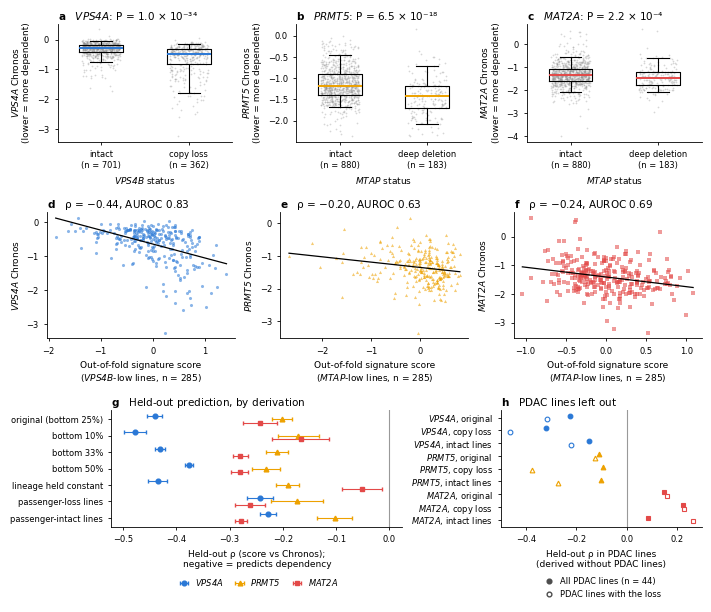

wrote Fig2_depmap_validation.png / .pdf to C:\Users\The_R/Downloads\pdac_results\manuscript_figures


In [81]:
# ==========================================================================
# 44 · FIG. 2 -- only the VPS4A signature is a reasonable proxy for measured dependency (DepMap; no cohorts)
# Layout: three rows, each its own subfigure; panels in a row have the same height.
# (a-c) the collateral-lethal interactions in DepMap: each target's Chronos score in lines with
#       vs without passenger loss (VPS4B copy loss for VPS4A; MTAP deep deletion for PRMT5/MAT2A);
#       box = median and IQR, whiskers 5th-95th percentile, points = lines; Mann-Whitney P (§26a)
# (d-f) held-out prediction in the passenger-low lines the signature is built from: each line's
#       out-of-fold signature score (5-fold CV x 10 repeats, §26b-c) against its measured Chronos.
#       A good proxy gives a NEGATIVE correlation (higher score, more negative Chronos)
# (g)   held-out rho for every derivation of every signature (mean +/- SD over CV repeats, DEPMAP_VAL)
# (h)   held-out rho in PDAC lines left out of derivation (PD): all PDAC lines (filled) and those
#       with the passenger loss (open)
# Pure consumer of DELETED, dep, OOF, DEPMAP_VAL, PD and RESULTS (§26); no random numbers except display jitter.
# ==========================================================================

assert "RHO" in globals(), "run section 42b first"
for _nm in ["OOF", "DEPMAP_VAL", "PD", "dep", "TARGET_CONTEXT"]:
    assert _nm in globals(), "run §26 first ({} is missing)".format(_nm)

TGT_STYLE = {"VPS4A": ("o", "#2a78d6"), "PRMT5": ("^", "#eda100"), "MAT2A": ("s", "#e34948")}  # validated set
_PASS_WORD = {"VPS4B": ("intact", "copy loss"), "MTAP": ("intact", "deep deletion")}
_dvi = RESULTS.get("del_vs_intact_chronos", {})
_DSHORT = {"original (bottom 25% expression)": "original (bottom 25%)", "bottom 10% expression": "bottom 10%",
           "bottom 33% expression": "bottom 33%", "bottom 50% expression": "bottom 50%",
           "lineage held constant": "lineage held constant",
           "passenger-loss lines (copy number)": "passenger-loss lines", "passenger-intact lines": "passenger-intact lines"}

with plt.rc_context(FIG_RC3):
    fig = ms_figure((FIG_W, 6.0))
    _r1, _r2, _r3 = fig.subfigures(3, 1, height_ratios=[0.95, 1.0, 1.1])
    ax_a = _r1.subplots(1, 3)
    ax_d = _r2.subplots(1, 3)
    ax_g = _r3.subplots(1, 2, gridspec_kw={"width_ratios": [1.45, 1.0]})
    _jit = np.random.default_rng(SEED + 902)          # display jitter only, own stream

    for j, t in enumerate(TARGETS):
        pg = TARGET_CONTEXT[t]
        mk, colr = TGT_STYLE[t]
        # (a-c) Chronos by passenger status
        ax = ax_a[j]
        if "DELETED" in globals() and DELETED and pg in DELETED:
            d = DELETED[pg].reindex(dep.index)
            groups = [dep.loc[d == False, t].dropna().values, dep.loc[d == True, t].dropna().values]
            for k, v in enumerate(groups):
                ax.scatter(k + _jit.uniform(-0.22, 0.22, len(v)), v, s=1.5, color="0.55", alpha=0.35,
                           lw=0, rasterized=True, zorder=1)
            ax.boxplot(groups, positions=[0, 1], widths=0.5, whis=(5, 95), showfliers=False,
                       medianprops=dict(color=colr, lw=1.4), boxprops=dict(lw=0.8),
                       whiskerprops=dict(lw=0.8), capprops=dict(lw=0.8), zorder=2)
            ax.set_xticks([0, 1])
            ax.set_xticklabels(["{}\n(n = {:,})".format(w, len(v)) for w, v in zip(_PASS_WORD[pg], groups)])
            p_ = _dvi.get(t, {}).get("p", np.nan)
            fpanel(ax, "abc"[j], gi(t) + (": P = {}".format(fP(p_)) if np.isfinite(p_) else ""))   # 1.0 × 10⁻³⁴
        else:
            fpanel(ax, "abc"[j], gi(t) + ": no copy number")
        ax.set_xlabel(gi("{} status".format(pg)))
        ax.set_ylabel(gi("{} Chronos".format(t)) + "\n(lower = more dependent)")
        fdespine(ax)

        # (d-f) out-of-fold score vs measured Chronos, passenger-low lines
        ax = ax_d[j]
        if t in OOF:
            oof, _ctx = OOF[t]
            y = dep.loc[oof.index, t]
            ax.scatter(oof, y, s=5, marker=mk, color=colr, alpha=0.55, lw=0, rasterized=True)
            b_ = np.polyfit(oof.values.astype(float), y.values.astype(float), 1)
            xs = np.linspace(float(oof.min()), float(oof.max()), 50)
            ax.plot(xs, np.polyval(b_, xs), color="k", lw=0.9)
            rr = DEPMAP_VAL[(DEPMAP_VAL["target"] == t) & DEPMAP_VAL["derivation"].str.startswith("original")].iloc[0]
            fpanel(ax, "def"[j], "ρ = {}, AUROC {:.2f}".format(fnum(rr["rho_score_chronos"]), rr["auc_quartiles"]))  # true minus
            ax.set_xlabel(gi("out-of-fold signature score\n({}-low lines, n = {})".format(pg, len(oof))))
        ax.set_ylabel(gi("{} Chronos".format(t)))
        fdespine(ax)

    # (g) held-out rho by derivation, all three signatures
    ax = ax_g[0]
    _vn = list(dict.fromkeys(DEPMAP_VAL["derivation"]))
    yv = np.arange(len(_vn))[::-1].astype(float)
    ax.axvline(0, color="0.6", lw=0.8)
    for k, t in enumerate(TARGETS):
        mk, colr = TGT_STYLE[t]
        g = DEPMAP_VAL[DEPMAP_VAL["target"] == t].set_index("derivation").reindex(_vn)
        ok = g["rho_score_chronos"].notna().values
        ax.errorbar(g["rho_score_chronos"].values[ok], yv[ok] + (1 - k) * 0.22,
                    xerr=g["rho_sd"].values[ok], fmt=mk, color=colr, mfc=colr, ms=3.4, capsize=1.2,
                    elinewidth=0.8, label=gi(t))
    ax.set_yticks(yv); ax.set_yticklabels([_DSHORT.get(v, v) for v in _vn])
    ax.set_xlabel("held-out ρ (score vs Chronos);\nnegative = predicts dependency")
    _g_ax = ax                                          # its legend is hung below the x label after layout
    fdespine(ax)
    fpanel(ax, "g", "Held-out prediction, by derivation")

    # (h) PDAC lines held out of derivation
    ax = ax_g[1]
    if len(PD):
        _rows = list(dict.fromkeys(zip(PD["target"], PD["derivation"])))
        yh = np.arange(len(_rows))[::-1].astype(float)
        ax.axvline(0, color="0.6", lw=0.8)
        for i, (t, dv) in enumerate(_rows):
            mk, colr = TGT_STYLE[t]
            g = PD[(PD["target"] == t) & (PD["derivation"] == dv)]
            for _, r_ in g.iterrows():
                allp = r_["test_set"].startswith("PDAC lines (all)")
                ax.plot(r_["rho"], yh[i] + (0.14 if allp else -0.14), ls="", marker=mk, ms=3.4, color=colr,
                        mfc=colr if allp else "white", mew=0.8)
        _dshort = {"original (bottom 25% expression)": "original", "passenger-loss lines (copy number)": "copy loss",
                   "passenger-intact lines": "intact lines"}
        ax.set_yticks(yh); ax.set_yticklabels([gi("{}, {}".format(t, _dshort.get(dv, dv))) for t, dv in _rows])
        _h_leg = ([Line2D([], [], ls="", marker="o", ms=3.4, color="0.3"),
                   Line2D([], [], ls="", marker="o", ms=3.4, color="0.3", mfc="white")],
                  ["all PDAC lines (n = {})".format(int(PD["n"].max())), "PDAC lines with the loss"])
    ax.set_xlabel("held-out ρ in PDAC lines\n(derived without PDAC lines)")
    # at most 5 ticks on 'nice' steps (0.1/0.2/0.25/0.5): on the real data the default gave one tick
    # every 0.1 from -0.5 to 0.2, and the labels ran into each other in this narrow panel
    ax.xaxis.set_major_locator(MaxNLocator(nbins=4, steps=[1, 2, 2.5, 5, 10]))
    fdespine(ax)
    fpanel(ax, "h", "PDAC lines left out")

    flegend_below(fig, _g_ax, *_g_ax.get_legend_handles_labels(), ncol=3)
    if len(PD):
        flegend_below(fig, ax, *_h_leg, ncol=1)
    fsave(fig, "Fig2_depmap_validation", "Fig. 2 (DepMap)", rows=[list("abc"), list("def"), list("gh")])

## 45 · Fig. 3: the MAT2A signature is the only target signature that separates from the null on the classical axis

(a–c) Within-patient partial Spearman correlation between each signature and the classical score in each cohort; points are patients, symbols the mean with its 95% patient-bootstrap CI, and the shaded band the mean ± 2 SD of that cohort's random-gene null. (d) Distance of each mean from the random-gene null, in null SDs. (e) Within-patient difference between each target signature's coefficient and that of the commonly essential control. Reads `RHO` and the nulls of sections 15, 19 and 20.

Fig. 3 layout: 61 boxes, 0 intersecting pair(s); largest empty area 4.21 x 0.25 in (3.4% of the figure) -> OK
Fig. 3 panel boxes: 6 boxes | overlapping pairs: none | groups not parallel / not equal: none -> OK


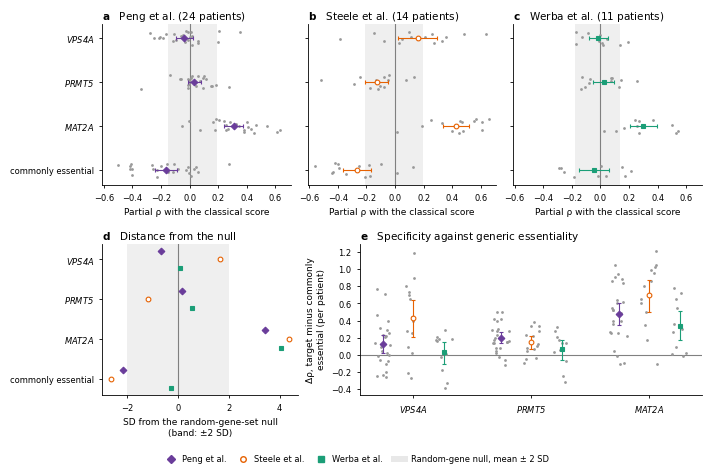

wrote Fig3_classical_axis.png / .pdf to C:\Users\The_R/Downloads\pdac_results\manuscript_figures
Peng   VPS4A -0.036 (-0.6 SD) | PRMT5 +0.033 (+0.2 SD) | MAT2A +0.309 (+3.4 SD) | commonly essential -0.165 (-2.2 SD)
Steele VPS4A +0.157 (+1.7 SD) | PRMT5 -0.124 (-1.2 SD) | MAT2A +0.429 (+4.4 SD) | commonly essential -0.269 (-2.6 SD)
Werba  VPS4A -0.017 (+0.1 SD) | PRMT5 +0.022 (+0.6 SD) | MAT2A +0.298 (+4.1 SD) | commonly essential -0.044 (-0.3 SD)


In [82]:
# ==========================================================================
# 45 · FIG. 3 -- the signatures on the classical axis, three cohorts
# Layout: two rows, each its own subfigure; panels in a row have the same height.
# (a-c) within-patient partial Spearman correlation of each signature with the classical score:
#       grey points = patients; cohort symbol = mean across patients with its 95% patient-bootstrap
#       CI; grey band = that cohort's random-gene-set null, mean +/- 2 SD (sections 15 / 19 / 20)
# (d)   distance of each mean from the random null, in null SDs (CLASSICAL_TAB); band = +/- 2 SD
# (e)   specificity against generic essentiality: each target minus the commonly essential
#       control, per patient (grey points), mean and 95% CI per cohort (paired, within patient)
# Pure consumer of RHO (setup cell, checked against CLASSICAL_TAB) and FIG_NULL. Display jitter has its own
# random stream, so drawing this figure cannot shift any null.
# ==========================================================================

assert "RHO" in globals(), "run section 42b first"

_sig_names = [nm for nm, _ in FIG_SIGS]
_vals3 = [v for lab, _ in FIG_COHORTS for d in RHO[(lab, "classical")].values() for v in d.values()]
_lim = (min(_vals3) - 0.05, max(_vals3) + 0.05)

with plt.rc_context(FIG_RC3):
    fig = ms_figure((FIG_W, 4.6))
    _top, _bot = fig.subfigures(2, 1, height_ratios=[1.0, 1.0])
    ax_t = _top.subplots(1, 3, sharey=True)
    ax_b = _bot.subplots(1, 2, gridspec_kw={"width_ratios": [1.0, 1.75]})
    _jit = np.random.default_rng(SEED + 903)

    # (a-c) per-patient forests
    for j, (lab, mk, colr, fill) in enumerate(COH3):
        ax = ax_t[j]
        fnull_band(ax, FIG_NULL[(lab, "classical")])
        ax.axvline(0, color="0.5", lw=0.8)
        for i, nm in enumerate(_sig_names):
            yy = len(_sig_names) - 1 - i
            v = np.array(list(RHO[(lab, "classical")][nm].values()))
            ax.scatter(v, yy + _jit.uniform(-0.17, 0.17, len(v)), s=4, color="0.6", lw=0, zorder=2)
            s_ = fsumm(RHO[(lab, "classical")][nm])
            fmark(ax, s_["mean"], yy, lab, xerr=[[s_["mean"] - s_["lo"]], [s_["hi"] - s_["mean"]]])
        ax.set_yticks(range(len(_sig_names)))
        ax.set_yticklabels([gi(n) for n in _sig_names][::-1])
        ax.tick_params(axis="y", labelleft=(j == 0))
        ax.set_xlim(*_lim)
        ax.set_xlabel("partial ρ with the classical score")
        fdespine(ax)
        fpanel(ax, "abc"[j], "{} ({} patients)".format(COH3_N[lab], len(RHO[(lab, "classical")]["MAT2A"])))

    # (d) SD from the random null, each signature x cohort
    ax = ax_b[0]
    ax.axvspan(-2, 2, color="0.4", alpha=0.10, lw=0)
    ax.axvline(0, color="0.5", lw=0.8)
    for k, (lab, mk, colr, fill) in enumerate(COH3):
        for i, nm in enumerate(_sig_names):
            yy = len(_sig_names) - 1 - i + (1 - k) * 0.22
            fmark(ax, sd_from(mean_rho(RHO[(lab, "classical")][nm]), FIG_NULL[(lab, "classical")]), yy, lab)
    ax.set_yticks(range(len(_sig_names))); ax.set_yticklabels([gi(n) for n in _sig_names][::-1])
    ax.set_xlabel("SD from the random-gene-set null\n(band: ±2 SD)")
    fdespine(ax)
    fpanel(ax, "d", "Distance from the null")

    # (e) head-to-head against the commonly essential control
    ax = ax_b[1]
    ax.axhline(0, color="0.5", lw=0.8)
    for i, t in enumerate(TARGETS):
        for k, (lab, mk, colr, fill) in enumerate(COH3):
            a_, ce = RHO[(lab, "classical")][t], RHO[(lab, "classical")]["commonly essential"]
            d = {p: a_[p] - ce[p] for p in sorted(set(a_) & set(ce))}
            x0 = i + (k - 1) * 0.26
            v = np.array(list(d.values()))
            ax.scatter(x0 + _jit.uniform(-0.07, 0.07, len(v)), v, s=4, color="0.6", lw=0, zorder=2)
            s_ = fsumm(d)
            fmark(ax, x0, s_["mean"], lab, yerr=[[s_["mean"] - s_["lo"]], [s_["hi"] - s_["mean"]]])
    ax.set_xticks(range(len(TARGETS))); ax.set_xticklabels([gi(t) for t in TARGETS])
    ax.set_ylabel("Δρ, target minus commonly\nessential (per patient)")
    fdespine(ax)
    fpanel(ax, "e", "Specificity against generic essentiality")

    ms_legend(fig, *fcohort_handles(null_label="random-gene null, mean ± 2 SD"), "lower")
    fsave(fig, "Fig3_classical_axis", "Fig. 3", rows=[list("abc"), list("de")])

for lab, *_ in COH3:
    print("{:<7}".format(lab) + " | ".join("{} {:+.3f} ({:+.1f} SD)".format(
        nm, mean_rho(RHO[(lab, "classical")][nm]),
        sd_from(mean_rho(RHO[(lab, "classical")][nm]), FIG_NULL[(lab, "classical")])) for nm in _sig_names))

## 46 · Fig. 4: robustness and content of the association between the MAT2A signature and the classical score

(a) Distance of the full-model coefficient from the four classical-axis nulls (sections 15, 18–20, 28a). (b) Each signature gene's own partial correlation with the classical score, epithelial-identity genes against the rest, with Mann–Whitney P (section 27c). (c) The association under each test, with 95% patient-bootstrap CIs, grouped into technical tests, adjustment for independently defined programs and the content of the signature; the Peng et al. and Steele et al. rows are checked against section 32's `FOREST`, and the Werba et al. rows (Supplementary Table S9c) are computed here with the same helpers.

Fig. 4 layout: 56 boxes, 0 intersecting pair(s); largest empty area 0.70 x 2.11 in (4.4% of the figure) -> CHECK
Fig. 4 panel boxes: 4 boxes | overlapping pairs: none | groups not parallel / not equal: none -> OK


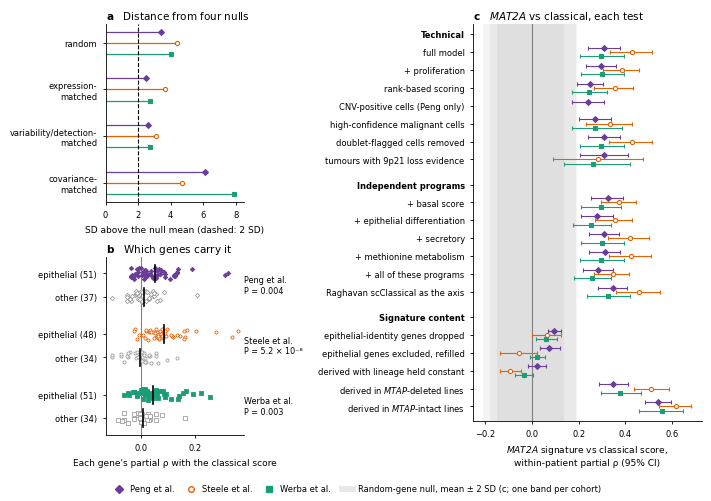

wrote Fig4_mat2a.png / .pdf to C:\Users\The_R/Downloads\pdac_results\manuscript_figures
cohort                                 Peng  Steele  Werba
test                                                      
+ all non-classical programs          0.284   0.346  0.257
+ basal score covariate               0.324   0.375  0.295
+ epithelial differentiation          0.280   0.354  0.254
+ methionine metabolism               0.312   0.426  0.297
+ proliferation covariate             0.297   0.386  0.300
+ secretory (exocytosis)              0.310   0.421  0.300
AUCell-style scoring                  0.248   0.355  0.243
CNV-positive cells (Peng only)        0.240     NaN    NaN
axis = Raghavan scClassical           0.346   0.460  0.326
doublet-flagged cells removed         0.309   0.429  0.297
epithelial genes dropped              0.096   0.064  0.060
epithelial genes excluded, refilled   0.075  -0.054  0.021
full model                            0.309   0.429  0.298
high-confidence malignant c

In [83]:
# ==========================================================================
# 46 · FIG. 4 -- the MAT2A association with the classical score: robust to every technical test,
#           carried by epithelial-identity genes and lineage, three cohorts
# Layout: a stacked left column (a, b: equal heights) and one tall panel taking up the whole right
# side (c); the column and the tall panel are separate subfigures, so neither can enter the other.
# (c) the MAT2A signature vs the classical score under each test (Table 1 + Supplementary Table S6),
#     mean within-patient partial rho with its 95% patient-bootstrap CI; grey bands = each cohort's
#     random-gene-set null +/- 2 SD. Rows are grouped: technical tests, adjustment for independent
#     programs, and the content of the signature. ROW ADDED HERE (not in section 32): the signature built from lines that
#     RETAIN MTAP (the manuscript quotes +0.541 / +0.618 / +0.558 from DEPMAP_VAL; drawn here with CIs)
# (a) distance of the full-model mean from each of the four classical-axis nulls (random, sections
#     15/19/20; expression-matched, sections 18/19/20; variability/detection- and
#     covariance-matched, §28a); dashed = 2 SD
# (b) which genes carry it: each signature gene's own partial rho with the classical score (§27c);
#     epithelial-identity genes in the cohort's colour, the rest in grey; points = genes, bar = mean,
#     Mann-Whitney P (§27c)
# Recomputes only deterministic ps_vs rows (Werba's rows and the new MTAP-intact row); Peng and
# Steele rows are checked against §32's FOREST so the figure cannot drift from section 32's numbers.
# ==========================================================================

assert "RHO" in globals(), "run section 42b first"
for _nm in ["FOREST", "PRG_COL", "HARD_NULLS", "mnull", "s_mnull", "w_mnull", "derive", "ctx_quantile",
            "score", "QC_COVARS", "LOW_Q", "EPI_IDENTITY"]:
    assert _nm in globals(), "missing {} -- run the analysis cells first".format(_nm)


def _f4_sig(ad, genes):
    """Score a gene list in one cohort and return its per-patient partial rho with the classical score."""
    if genes is None:
        return None
    score(ad, genes, "_f4")
    r = ps_vs(ad.obs, "_f4")
    del ad.obs["_f4"]
    return r


# alternative MAT2A signatures, DepMap side (§26 / §32 definitions; the intact-lines one is §26's
# 'passenger-intact lines' variant: no MTAP deletion AND MTAP expression at or above the median)
_have_cn = "DELETED" in globals() and bool(DELETED) and "MTAP" in DELETED
F4_ALT = {"signature from MTAP-deleted lines": derive("MAT2A", ctx_deleted("MTAP")) if _have_cn else None,
          "signature from MTAP-intact lines": derive("MAT2A", ctx_intact("MTAP")) if _have_cn else None,
          "signature with lineage held constant": derive("MAT2A", ctx_quantile("MTAP", LOW_Q), lineage_held=True)}
_progs = [n for n in PRG_COL if not n.lower().startswith("raghavan")]
_rag_c = next((PRG_COL[n] for n in PRG_COL if n.lower().startswith("raghavan") and "class" in n.lower()), None)

# (group heading, [(row key = §32's test name where one exists, label on the figure)])
F4_GROUPS = [
    ("Technical", [("full model", "full model"),
                   ("+ proliferation covariate", "+ proliferation"),
                   ("AUCell-style scoring", "rank-based scoring"),
                   ("CNV-positive cells (Peng only)", "CNV-positive cells (Peng only)"),
                   ("high-confidence malignant cells", "high-confidence malignant cells"),
                   ("doublet-flagged cells removed", "doublet-flagged cells removed"),
                   ("tumours with 9p21 loss evidence", "tumours with 9p21 loss evidence")]),
    ("Independent programs", [("+ basal score covariate", "+ basal score")]
     + [("+ " + n, "+ " + n.replace(" (exocytosis)", "")) for n in _progs]
     + [("+ all non-classical programs", "+ all of these programs"),
        ("axis = Raghavan scClassical", "Raghavan scClassical as the axis")]),
    ("Signature content", [("epithelial genes dropped", "epithelial-identity genes dropped"),
                           ("epithelial genes excluded, refilled", "epithelial genes excluded, refilled"),
                           ("signature with lineage held constant", "derived with lineage held constant"),
                           ("signature from MTAP-deleted lines", gi("derived in MTAP-deleted lines")),
                           ("signature from MTAP-intact lines", gi("derived in MTAP-intact lines"))]),
]

F4ROWS = []
for lab, ad in FIG_COHORTS:
    o = ad.obs
    rr = {"full model": RHO[(lab, "classical")]["MAT2A"],
          "+ proliferation covariate": ps_vs(o, "MAT2A_sig", covars=QC_COVARS + ["prolif"]),
          "AUCell-style scoring": ps_vs(o, "MAT2A_auc") if "MAT2A_auc" in o else None,
          "CNV-positive cells (Peng only)": (ps_vs(globals()["sub"], "MAT2A_sig", min_cells=30)
                                             if lab == "Peng" and globals().get("sub") is not None else None),
          "high-confidence malignant cells": RESULTS.get("hc_rhos", {}).get("{}|MAT2A_sig".format(lab)),
          "doublet-flagged cells removed": (ps_vs(o[~o["doublet_flag"].astype(bool).values], "MAT2A_sig")
                                            if "doublet_flag" in o else None),
          "tumours with 9p21 loss evidence": RESULTS.get("loss_strat", {}).get(
              "{}|MAT2A|tumours with 9p21 loss evidence".format(lab)),
          "+ basal score covariate": ps_vs(o, "MAT2A_sig", covars=QC_COVARS + ["basal_score"]),
          "+ all non-classical programs": RESULTS["program_adjusted"].get("{}|all non-classical programs".format(lab)),
          "axis = Raghavan scClassical": RESULTS["axis"].get("{}|MAT2A_sig|vs Raghavan scClassical".format(lab)),
          "epithelial genes dropped": RESULTS["epi_removed"].get("{}|MAT2A epithelial genes dropped".format(lab)),
          "epithelial genes excluded, refilled": RESULTS["epi_removed"].get(
              "{}|MAT2A epithelial genes excluded, refilled".format(lab))}
    for n in _progs:
        rr["+ " + n] = RESULTS["program_adjusted"].get("{}|{}".format(lab, n))
    for k_, genes in F4_ALT.items():
        rr[k_] = _f4_sig(ad, genes)
    for k_, r in rr.items():
        if r is None or len(r) < 3:                       # a CI needs at least 3 patients
            continue
        s_ = fsumm(r)
        F4ROWS.append(dict(cohort=lab, test=k_, **s_))
F4T = pd.DataFrame(F4ROWS)
F4T.to_csv(os.path.join(FIG_DIR3, "Fig4c_mat2a_tests.csv"), index=False)

# guard: Peng and Steele must reproduce §32's FOREST wherever both have the row
_chk = F4T.merge(FOREST.dropna(subset=["mean"]), on=["cohort", "test"], suffixes=("", "_f"))
assert len(_chk) and np.allclose(_chk["mean"], _chk["mean_f"], atol=1e-9), "Fig. 4 rows differ from §32's FOREST"

# (b) the four classical-axis nulls for the full-model mean
_MNULL = {"Peng": mnull, "Steele": s_mnull, "Werba": w_mnull}
F4NULL = []
for lab, _ in FIG_COHORTS:
    m_ = mean_rho(RHO[(lab, "classical")]["MAT2A"])
    nulls = {"random": FIG_NULL[(lab, "classical")], "expression-matched": np.asarray(_MNULL[lab])}
    nulls.update({k: np.asarray(v) for k, v in HARD_NULLS[lab].items()})
    for kind, nd in nulls.items():
        F4NULL.append(dict(cohort=lab, null=kind, sd=sd_from(m_, nd), emp_p=emp_p(m_, nd)))
F4NULL = pd.DataFrame(F4NULL)

with plt.rc_context(FIG_RC3):
    fig = ms_figure((FIG_W, 4.9))
    _left, _right = fig.subfigures(1, 2, width_ratios=[1.0, 1.3])
    ax_a, ax_b = _left.subplots(2, 1)                  # stacked column: equal heights
    ax_c = _right.subplots(1, 1)                       # the tall panel, whole right side

    # (a) distance from the four nulls (lollipops: stem from 0, cohort symbol at the value)
    ax = ax_a
    _kinds = ["random", "expression-matched", "variability/detection-matched", "covariance-matched"]
    _kshort = ["random", "expression-\nmatched", "variability/detection-\nmatched", "covariance-\nmatched"]
    yb = np.arange(len(_kinds))[::-1].astype(float)
    for k, (lab, mk, colr, fill) in enumerate(COH3):
        v = F4NULL[F4NULL["cohort"] == lab].set_index("null").reindex(_kinds)["sd"].values
        yy = yb + (1 - k) * 0.24
        ax.hlines(yy, 0, v, color=colr, lw=0.9)
        for vv, y_ in zip(v, yy):
            fmark(ax, vv, y_, lab, ms=3.0)
    ax.axvline(2, color="k", ls="--", lw=0.8)
    ax.set_yticks(yb); ax.set_yticklabels(_kshort)
    ax.set_xlim(0, max(F4NULL["sd"].max() * 1.08, 2.5))
    ax.set_xlabel("SD above the null mean (dashed: 2 SD)")
    fdespine(ax)
    fpanel(ax, "a", "Distance from four nulls")

    # (b) per-gene contributions: epithelial-identity genes (cohort colour) vs the rest (grey)
    ax = ax_b
    _jit = np.random.default_rng(SEED + 904)
    ax.axvline(0, color="0.5", lw=0.8)
    yl, yt = [], []
    for k, (lab, mk, colr, fill) in enumerate(COH3):
        pth = out_path("mat2a_per_gene_{}.csv".format(lab.lower()))
        if not os.path.exists(pth):
            continue
        pg_ = pd.read_csv(pth, index_col=0).iloc[:, 0]
        is_epi = pg_.index.isin(EPI_IDENTITY)
        for j_, (sel, name, c_) in enumerate([(is_epi, "epithelial", colr), (~is_epi, "other", OTHER_GREY)]):
            yy = (2 - k) * 2.6 + (1 - j_) * 1.0
            v = pg_[sel].values
            ax.scatter(v, yy + _jit.uniform(-0.25, 0.25, len(v)), s=5, marker=mk, facecolors=fill if j_ == 0 else "white",
                       edgecolors=c_, linewidths=0.6, zorder=2)
            ax.plot([v.mean()] * 2, [yy - 0.38, yy + 0.38], color="k", lw=1.2, zorder=3)
            yl.append(yy); yt.append("{} ({})".format(name, len(v)))
        p_ = RESULTS.get("per_gene", {}).get(lab, {}).get("p", np.nan)
        ax.text(1.0, (2 - k) * 2.6 + 0.5, "{}\nP = {}".format(COH3_N[lab], fP(p_)), fontsize=5.8, va="center",
                ha="left", transform=ax.get_yaxis_transform())
    ax.set_yticks(yl); ax.set_yticklabels(yt)
    ax.set_xlabel("each gene's partial ρ with the classical score")
    fdespine(ax)
    fpanel(ax, "b", "Which genes carry it")

    # (c) the forest, whole right side
    ax = ax_c
    labels, heads, y = [], [], 0.0
    for head_, rows in F4_GROUPS:
        heads.append((y, head_)); y -= 1.0
        for key, lab_txt in rows:
            if key in set(F4T["test"]):
                labels.append((key, lab_txt, y)); y -= 1.0
        y -= 0.4
    for lab, _ in FIG_COHORTS:
        fnull_band(ax, FIG_NULL[(lab, "classical")], alpha=0.07)
    ax.axvline(0, color="0.5", lw=0.8)
    for k, (lab, mk, colr, fill) in enumerate(COH3):
        g = F4T[F4T["cohort"] == lab].set_index("test")
        for key, _, yy in labels:
            if key in g.index:
                r_ = g.loc[key]
                fmark(ax, r_["mean"], yy + (1 - k) * 0.24, lab,
                      xerr=[[r_["mean"] - r_["lo"]], [r_["hi"] - r_["mean"]]], ms=3.0)
    ax.set_yticks([yy for _, _, yy in labels] + [yy for yy, _ in heads])
    ax.set_yticklabels([t_ for _, t_, _ in labels] + [h for _, h in heads])
    for tl in ax.get_yticklabels()[len(labels):]:
        tl.set_fontweight("bold")
    ax.set_ylim(y + 0.6, 0.6)
    ax.set_xlabel(gi("MAT2A signature vs classical score,\nwithin-patient partial ρ (95% CI)"))
    fdespine(ax)
    fpanel(ax, "c", gi("MAT2A vs classical, each test"))

    ms_legend(fig, *fcohort_handles(null_label="random-gene null, mean ± 2 SD (c; one band per cohort)"), "lower")
    fsave(fig, "Fig4_mat2a", "Fig. 4", cols=[list("ab")])

print(F4T.pivot(index="test", columns="cohort", values="mean").round(3).to_string())
print()
print(F4NULL.round(3).to_string(index=False))

## 47 · Fig. 5: the VPS4A signature rises with the basal score

(a) Mean within-patient partial correlation of each signature with the classical and the basal score, with 95% CIs. (b) Distance of the *VPS4A*–basal coefficient from the four basal-axis nulls (section 31a). (c) Each signature gene's own partial correlation with the basal score, mesenchymal-identity genes against the rest, with the percentage of genes with a positive correlation (section 31c). (d) The association under each robustness test of section 31b; † marks a test the association did not pass.

Fig. 5 layout: 70 boxes, 0 intersecting pair(s); largest empty area 0.65 x 2.06 in (3.5% of the figure) -> CHECK
Fig. 5 panel boxes: 5 boxes | overlapping pairs: none | groups not parallel / not equal: abc -> CHECK


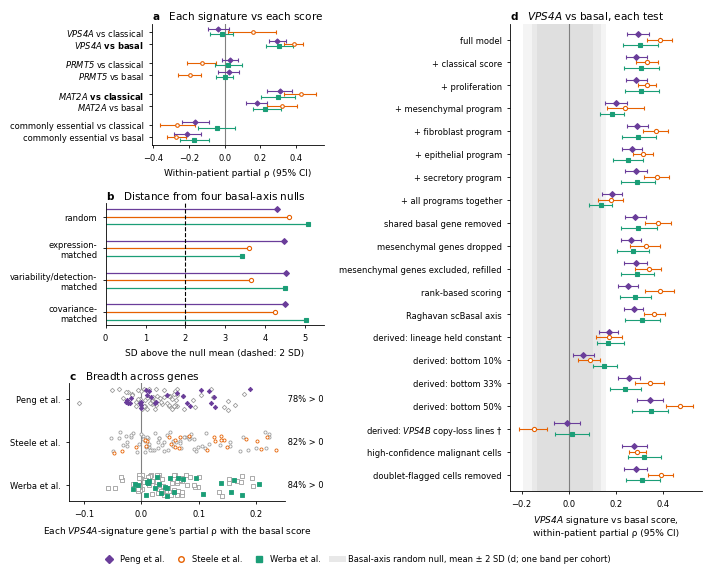

wrote Fig5_vps4a_basal.png / .pdf to C:\Users\The_R/Downloads\pdac_results\manuscript_figures
rows marked † (status 'fail' in §31b): derived: VPS4B copy-loss lines (Peng); derived: VPS4B copy-loss lines (Steele); derived: VPS4B copy-loss lines (Werba)


In [84]:
# ==========================================================================
# 47 · FIG. 5 -- the VPS4A signature rises with the basal score, three cohorts
# Layout: a stacked left column (a, b, c: equal heights) and one tall panel taking up the whole
# right side (d); the column and the tall panel are separate subfigures.
# (a) every signature against the classical AND the basal score: mean within-patient partial rho
#     with 95% patient-bootstrap CI (RHO, checked against CLASSICAL_TAB / BASAL_TAB in the setup cell)
# (b) distance from the four basal-axis nulls (§31a's NULL_TAB); dashed = 2 SD
# (c) breadth: each signature gene's own partial rho with the basal score (§31c's BREADTH);
#     mesenchymal-identity genes in the cohort's colour, the rest in grey (legend text says so); the % of
#     genes that rise with the basal score
# (d) the VPS4A-basal association under each robustness test (§31b's battery, VB_TAB); grey
#     bands = each cohort's basal-axis random null +/- 2 SD (§31a). A test that failed in any
#     cohort carries a dagger (as in Table 1), and the failures are named in the printout
# Pure consumer of RHO, VB_TAB, NULL_TAB, BREADTH and MES_IDENTITY.
# ==========================================================================

assert "RHO" in globals(), "run section 42b first"
for _nm in ["VB_TAB", "NULL_TAB", "BREADTH"]:
    assert _nm in globals(), "run §31 first ({} is missing)".format(_nm)

F5_SKIP = ["For scale", "Commonly-essential head-to-head", "Single-gene"]     # not coefficients on this axis
_lab5 = _vb_label if "_vb_label" in globals() else (lambda t, v: "{}: {}".format(t, v))
_mes = MES_IDENTITY if "MES_IDENTITY" in globals() else set()

# rows of panel (d): the battery's coefficient rows, full model first
rb = VB_TAB[np.isfinite(VB_TAB["lo"].astype(float)) & ~VB_TAB["test"].isin(F5_SKIP)].copy()
rb["label"] = [_lab5(t_, v_) for t_, v_ in zip(rb["test"], rb["variant"])]
_full_lab = list(dict.fromkeys(rb.loc[rb["test"] == "Full model", "label"]))
_order = _full_lab + [l_ for l_ in dict.fromkeys(rb["label"]) if l_ not in set(_full_lab)]
_failed = rb[rb["status"] == "fail"]
_fail_lab = set(_failed["label"])

with plt.rc_context(FIG_RC3):
    fig = ms_figure((FIG_W, 5.6))
    _left, _right = fig.subfigures(1, 2, width_ratios=[1.0, 1.15])
    # Each stacked panel gets its OWN subfigure. In one shared grid, constrained layout lines up the
    # left spines of a, b and c behind the widest tick labels (a's "comm. essential vs classical"),
    # which left an empty strip ~0.6 in wide beside b's and c's shorter labels. In separate
    # subfigures every panel's box starts at the column's left edge and its plot widens into the
    # freed space; the three subfigures are equal in height, and with one-line titles and x labels
    # in all three the plotting areas stay equal too (fbox_check's `cols` test below checks this).
    ax_a, ax_b, ax_c = [sf_.subplots(1, 1) for sf_ in _left.subfigures(3, 1)]
    ax_d = _right.subplots(1, 1)                       # the tall panel, whole right side

    # (a) each signature x each axis
    ax = ax_a
    rows_a = [(nm, axn) for nm, _ in FIG_SIGS for axn in ("classical", "basal")]
    ya, yy = [], 0.0
    for nm, axn in rows_a:
        ya.append(yy)
        yy -= 1.0 if axn == "classical" else 1.6                    # gap between signatures
    ax.axvline(0, color="0.5", lw=0.8)
    for k, (lab, mk, colr, fill) in enumerate(COH3):
        for (nm, axn), y_ in zip(rows_a, ya):
            s_ = fsumm(RHO[(lab, axn)][nm])
            fmark(ax, s_["mean"], y_ + (1 - k) * 0.22, lab, xerr=[[s_["mean"] - s_["lo"]], [s_["hi"] - s_["mean"]]],
                  ms=2.6)
    _short = {}
    ax.set_yticks(ya); ax.set_yticklabels([gi("{} vs {}".format(_short.get(nm, nm), axn)) for nm, axn in rows_a])
    for tl, (nm, axn) in zip(ax.get_yticklabels(), rows_a):
        if (nm, axn) in (("VPS4A", "basal"), ("MAT2A", "classical")):
            tl.set_fontweight("bold")                                # the two claims
    ax.set_xlabel("within-patient partial ρ (95% CI)")
    fdespine(ax)
    fpanel(ax, "a", "Each signature vs each score")

    # (b) four basal-axis nulls, lollipops
    ax = ax_b
    _kinds = ["random", "expression-matched", "variability/detection-matched", "covariance-matched"]
    _kshort = ["random", "expression-\nmatched", "variability/detection-\nmatched", "covariance-\nmatched"]
    nb = NULL_TAB[NULL_TAB["axis"] == "basal"]
    yc = np.arange(len(_kinds))[::-1].astype(float)
    for k, (lab, mk, colr, fill) in enumerate(COH3):
        v = nb[nb["cohort"] == lab].set_index("null").reindex(_kinds)["sd"].values
        y_ = yc + (1 - k) * 0.24
        ax.hlines(y_, 0, v, color=colr, lw=0.9)
        for vv, yy_ in zip(v, y_):
            fmark(ax, vv, yy_, lab, ms=3.0)
    ax.axvline(2, color="k", ls="--", lw=0.8)
    ax.set_yticks(yc); ax.set_yticklabels(_kshort)
    ax.set_xlim(0, max(nb["sd"].max() * 1.08, 2.5))
    ax.set_xlabel("SD above the null mean (dashed: 2 SD)")
    fdespine(ax)
    fpanel(ax, "b", "Distance from four basal-axis nulls")

    # (c) per-gene breadth: mesenchymal-identity genes (cohort colour) vs the rest (grey)
    ax = ax_c
    _jit = np.random.default_rng(SEED + 905)
    ax.axvline(0, color="0.5", lw=0.8)
    for k, (lab, mk, colr, fill) in enumerate(COH3):
        if lab not in BREADTH:
            continue
        s_ = BREADTH[lab]
        is_m = s_.index.isin(_mes)
        yk = 2 - k
        yj = yk + _jit.uniform(-0.25, 0.25, len(s_))
        ax.scatter(s_.values[~is_m], yj[~is_m], s=5, marker=mk, facecolors="white", edgecolors=OTHER_GREY,
                   linewidths=0.6, zorder=2)
        ax.scatter(s_.values[is_m], yj[is_m], s=5, marker=mk, facecolors=fill, edgecolors=colr, linewidths=0.6,
                   zorder=3)
        ax.text(1.0, yk, " {:.0%} > 0".format((s_ > 0).mean()), transform=ax.get_yaxis_transform(),
                fontsize=6, va="center", ha="left")
    ax.set_yticks([2, 1, 0]); ax.set_yticklabels([COH3_N[c] for c, *_ in COH3])
    ax.set_xlabel(gi("each VPS4A-signature gene's partial ρ with the basal score"))   # one line, like a and b
    # 0.1 steps, not 0.05: on the real data eight labels (-0.10 ... 0.25) ran into each other
    ax.xaxis.set_major_locator(MaxNLocator(nbins=4, steps=[1, 2, 2.5, 5, 10]))
    fdespine(ax)
    fpanel(ax, "c", "Breadth across genes")

    # (d) robustness forest, whole right side
    ax = ax_d
    yb = np.arange(len(_order))[::-1].astype(float)
    for lab, _ in FIG_COHORTS:
        fnull_band(ax, FIG_NULL[(lab, "basal")], alpha=0.07)
    ax.axvline(0, color="0.5", lw=0.8)
    for k, (lab, mk, colr, fill) in enumerate(COH3):
        for _, r_ in rb[rb["cohort"] == lab].iterrows():
            y_ = yb[_order.index(r_["label"])] + (1 - k) * 0.24
            fmark(ax, r_["mean"], y_, lab, xerr=[[r_["mean"] - r_["lo"]], [r_["hi"] - r_["mean"]]], ms=3.0)
    ax.set_yticks(yb); ax.set_yticklabels([gi(l_) + (" †" if l_ in _fail_lab else "") for l_ in _order])
    ax.set_ylim(yb.min() - 0.7, yb.max() + 0.7)
    ax.set_xlabel(gi("VPS4A signature vs basal score,\nwithin-patient partial ρ (95% CI)"))
    fdespine(ax)
    fpanel(ax, "d", gi("VPS4A vs basal, each test"))

    ms_legend(fig, *fcohort_handles(null_label="basal-axis random null, mean ± 2 SD (d; one band per cohort)"), "lower")
    fsave(fig, "Fig5_vps4a_basal", "Fig. 5", cols=[list("abc")])

print("rows marked † (status 'fail' in §31b): " + ("; ".join(
    "{} ({})".format(l_, c_) for l_, c_ in zip(_failed["label"], _failed["cohort"])) or "none"))

## 48 · Fig. 6: the three associations replicate in an independent cohort under criteria fixed before its data were analysed

(a) *VPS4A* signature against the basal score; (b) *MAT2A* signature against the classical score; (c) *PRMT5* signature against the classical score, judged by equivalence (vertical lines at ±0.10, thick bars the 90% CIs of the two one-sided tests). The verdict in each panel title is section 34's, applied unchanged.

Fig. 6 layout: 32 boxes, 0 intersecting pair(s); largest empty area 0.75 x 0.55 in (2.4% of the figure) -> OK
Fig. 6 panel boxes: 4 boxes | overlapping pairs: none | groups not parallel / not equal: none -> OK


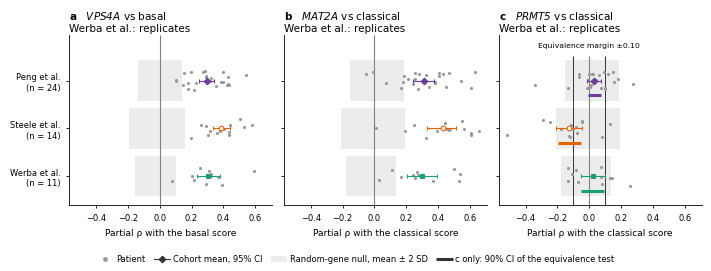

wrote Fig6_replication.png / .pdf to C:\Users\The_R/Downloads\pdac_results\manuscript_figures
  VPS4A vs basal                           replicates
  MAT2A vs classical                       replicates
  PRMT5 vs classical (no association)      replicates (equivalent to zero within +/-0.1)


In [85]:
# ==========================================================================
# 48 · FIG. 6 -- the three claims, judged in the replication cohort by criteria fixed in advance
# Layout: one row of three parallel panels (same height, same top edge), one per claim; within
# each, one row per cohort: grey points = patients, cohort symbol = mean with its 95%
# patient-bootstrap CI, grey box = that cohort's random-gene-set null +/- 2 SD on the claim's own
# axis (classical: sections 15/19/20; basal: §31a).
# (a) VPS4A vs basal and (b) MAT2A vs classical replicate if mean > 0, CI excludes zero and
#     empirical p < 0.05 against the random null on that axis
# (c) PRMT5 vs classical replicates if equivalent to zero within +/-0.10 (TOST, §28b). Only this
#     panel is judged by equivalence, so only it carries the margin (two solid vertical lines,
#     labelled in the panel; formerly a /// hatch, which read as stray dashed lines) and each
#     cohort's 90% CI (thick bar under the mean). A key under the row explains every mark.
# The verdict in each panel title is §34's (WERBA_VERDICT), applied unchanged.
# Pure consumer of RHO, FIG_NULL, CLASSICAL_TAB and WERBA_VERDICT.
# ==========================================================================

assert "RHO" in globals(), "run section 42b first"
assert "WERBA_VERDICT" in globals(), "run §34 first"

F6_CLAIMS = [("VPS4A", "basal", "VPS4A vs basal"), ("MAT2A", "classical", "MAT2A vs classical"),
             ("PRMT5", "classical", "PRMT5 vs classical (no association)")]
_eq = EQ_MARGIN if "EQ_MARGIN" in globals() else 0.10
_all = [v for lab, _ in FIG_COHORTS for t, axn, _ in F6_CLAIMS for v in RHO[(lab, axn)][t].values()]
_xl = (min(_all + [-_eq]) - 0.05, max(_all) + 0.05)

with plt.rc_context(FIG_RC3):
    fig = ms_figure((FIG_W, 2.6))
    axes = fig.subplots(1, 3, sharex=True, sharey=True)
    _jit = np.random.default_rng(SEED + 906)
    for j, (t, axn, key) in enumerate(F6_CLAIMS):
        ax = axes[j]
        # zero line; in c it stops below the margin label (a full-height line left a stub above it)
        ax.vlines(0, -0.6, 2.52 if t == "PRMT5" else 2.95, color="0.5", lw=0.8)
        if t == "PRMT5":   # equivalence margin: two solid edges stopping below their in-panel label
            ax.vlines([-_eq, _eq], -0.6, 2.52, color="0.2", lw=0.7, zorder=1)
            ax.text(0, 2.74, "equivalence margin ±{:.2f}".format(_eq), ha="center", va="center", fontsize=5.5,
                    zorder=4)
        for k, (lab, mk, colr, fill) in enumerate(COH3):
            yk = 2 - k
            fnull_band(ax, FIG_NULL[(lab, axn)], y0=yk - 0.42, y1=yk + 0.42, alpha=0.12)
            v = np.array(list(RHO[(lab, axn)][t].values()))
            ax.scatter(v, yk + _jit.uniform(-0.2, 0.2, len(v)), s=5, color="0.6", lw=0, zorder=2)
            s_ = fsumm(RHO[(lab, axn)][t])
            if t == "PRMT5":                                   # TOST's 90% CI, the equivalence test
                r3 = CLASSICAL_TAB[(CLASSICAL_TAB["cohort"] == lab) & (CLASSICAL_TAB["signature"] == "PRMT5")].iloc[0]
                ax.plot([r3["ci90_lo"], r3["ci90_hi"]], [yk - 0.3] * 2, color=colr, lw=2.2,
                        solid_capstyle="butt", zorder=3)
            fmark(ax, s_["mean"], yk, lab, xerr=[[s_["mean"] - s_["lo"]], [s_["hi"] - s_["mean"]]])
        ax.set_yticks([2, 1, 0])
        ax.set_yticklabels(["{}\n(n = {})".format(COH3_N[c], len(RHO[(c, axn)][t])) for c, *_ in COH3])
        ax.tick_params(axis="y", labelleft=(j == 0))
        ax.set_ylim(-0.6, 2.95); ax.set_xlim(*_xl)       # headroom above Peng for panel c's margin label
        ax.set_xlabel("partial ρ with the {} score".format(axn))
        fdespine(ax)
        _verd = WERBA_VERDICT.get(key, "")
        fpanel(ax, "abc"[j], gi("{} vs {}".format(t, axn)) + "\nWerba et al.: " + _verd.split(" (")[0])
    # key to every mark, in its own strip under the row (cohorts are named on the y axis); the
    # null-box handle uses fnull_band's own colour and this figure's alpha
    _key = ([Line2D([], [], ls="", marker="o", ms=2.5, color="0.6"),
             Line2D([], [], color="0.2", marker="D", ms=3.2, lw=0.8),
             Rectangle((0, 0), 1, 1, color="0.4", alpha=0.12, lw=0),
             Line2D([], [], color="0.2", lw=2.2, solid_capstyle="butt")],
            ["patient", "cohort mean, 95% CI", "random-gene null, mean ± 2 SD",
             "c only: 90% CI of the equivalence test"])
    ms_legend(fig, *_key, "lower", ncol=4)
    fsave(fig, "Fig6_replication", "Fig. 6", rows=[list("abc")])

for k_, v_ in WERBA_VERDICT.items():
    print("  {:<40} {}".format(k_, v_))

## 49 · Fig. 7: sensitivity and specificity of the approach

(a, b) Single-cell association, on the axis on which each was selected, of the signatures of the 20 dependencies DepMap links most strongly to the classical (a) or basal (b) score, in the two discovery cohorts; † marks controls not recovered (section 37). (c) DepMap association against single-cell association for every control and no-association signature on both axes (sections 36–37). (d) Each target against the signatures of the no-association dependencies built in the same passenger-low lines by the same rule, with two-sided empirical P (section 39a).

Fig. 7 layout: 89 boxes, 0 intersecting pair(s); largest empty area 5.21 x 0.45 in (6.7% of the figure) -> CHECK
Fig. 7 panel boxes: 5 boxes | overlapping pairs: none | groups not parallel / not equal: none -> OK


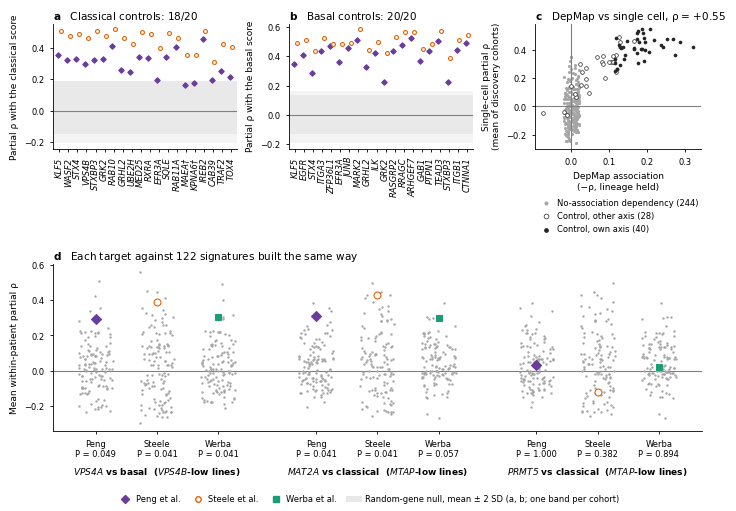

wrote Fig7_calibration.png / .pdf to C:\Users\The_R/Downloads\pdac_results\manuscript_figures
controls recovered: 38 of 40 | no-association signatures associated: 21 of 122 (basal axis 16) | dose-response Spearman +0.55 (p 8.9e-26) over 312 pairs


In [86]:
# ==========================================================================
# 49 · FIG. 7 -- sensitivity and specificity of the DepMap-to-single-cell transfer
# Layout: two rows, each its own subfigure; a, b and c are parallel (same height, same top edge).
# (a, b) positive controls: the 20 dependencies DepMap links most strongly to each subtype score
#        (lineage held; §37), each signature tested on the axis it was selected on, in the two
#        discovery cohorts (the rule was fixed on these two; Werba was not added afterwards).
#        Grey bands = each cohort's random null +/- 2 SD on that axis; dagger = not recovered
#        (recovered = 95% CI above zero AND empirical p < 0.05 in both cohorts)
# (c)    dose-response: DepMap association (sign flipped, so positive = lines high in the score
#        are more dependent) against the single-cell association (mean of Peng and Steele), for
#        every control and no-association signature on both axes (§37's 312 pairs)
# (d)    the strictest comparison (§39a, all three cohorts): each target against the 122
#        no-association dependencies whose signatures were built exactly as the target's was
#        (same passenger-low lines, same rule). Grey points = those 122 signatures; cohort symbol =
#        the target; P = two-sided empirical (k + 1) / (n + 1), §21's emp_p
# Pure consumer of POSB, NEGB, SCAN / _res_cache (§37), CTXNULL3 and CTXT3 (§39a).
# ==========================================================================

assert "RHO" in globals(), "run section 42b first"
for _nm in ["POSB", "NEGB", "CTXNULL3", "CTXT3"]:
    assert _nm in globals(), "run §37 and §39a first ({} is missing)".format(_nm)

_COH2 = [c for c in COH3 if c[0] in ("Peng", "Steele")]

# ---- (c) the dose-response points, exactly as §37 built them ---------------------------------------
_ctrl_axis = set(zip(POSB["gene"], POSB["axis"]))
_ctrl_genes = set(POSB["gene"])
if "_res_cache" in globals() and "SCAN" in globals() and len(_res_cache):
    _dr = [(g, ax_, -float(SCAN.loc[g, "rho_" + ax_]),
            float(np.mean([r[("Peng", ax_)]["mean"], r[("Steele", ax_)]["mean"]])))
           for g, r in _res_cache.items() for ax_ in ("classical", "basal")]
else:                                    # fresh kernel: rebuild from the saved tables (own-axis controls only)
    _dr = [(r_["gene"], r_["axis"], -r_["depmap_rho"], (r_["Peng_mean"] + r_["Steele_mean"]) / 2)
           for _, r_ in POSB.iterrows()]
    _dr += [(r_["gene"], ax_, -r_["depmap_rho_" + ax_], (r_["Peng_{}_mean".format(ax_)] + r_["Steele_{}_mean".format(ax_)]) / 2)
            for _, r_ in NEGB.iterrows() for ax_ in ("classical", "basal")]
DR = pd.DataFrame(_dr, columns=["gene", "axis", "depmap", "single_cell"])
DR["group"] = np.where([(g, a) in _ctrl_axis for g, a in zip(DR["gene"], DR["axis"])], "control, own axis",
                       np.where(DR["gene"].isin(_ctrl_genes), "control, other axis", "no-association dependency"))
_drho = spearmanr(DR["depmap"], DR["single_cell"])

# ---- (d) target vs context-matched pool, per claim and cohort ------------------------------------------
F7D_CLAIMS = [("VPS4A", "basal", "VPS4B"), ("MAT2A", "classical", "MTAP"), ("PRMT5", "classical", "MTAP")]

with plt.rc_context(FIG_RC3):
    fig = ms_figure((FIG_W, 5.0))
    _top, _bot = fig.subfigures(2, 1, height_ratios=[1.0, 1.0])
    ax_t = _top.subplots(1, 3, gridspec_kw={"width_ratios": [1.0, 1.0, 0.9]})
    ax_d = _bot.subplots(1, 1)
    _jit = np.random.default_rng(SEED + 907)

    # (a, b) positive controls by DepMap rank; every gene symbol italic, dagger = not recovered
    for j, ax_ in enumerate(["classical", "basal"]):
        ax = ax_t[j]
        g = POSB[POSB["axis"] == ax_].sort_values("rank")
        x = np.arange(len(g))
        for lab, *_ in _COH2:
            fnull_band(ax, FIG_NULL[(lab, ax_)], orient="h", alpha=0.07)
        ax.axhline(0, color="0.5", lw=0.8)
        for k, (lab, mk, colr, fill) in enumerate(_COH2):
            for xx, yy in zip(x + (k - 0.5) * 0.3, g["{}_mean".format(lab)]):
                fmark(ax, xx, yy, lab, ms=2.8)
        ax.set_xticks(x)
        ax.set_xticklabels([gg + ("†" if not rc else "") for gg, rc in zip(g["gene"], g["recovered"])], rotation=90)
        fitalic_ticks(ax, "x")
        ax.set_xlim(-0.7, len(g) - 0.3)
        ax.set_ylabel("partial ρ with the {} score".format(ax_))
        fdespine(ax)
        fpanel(ax, "ab"[j], "{} controls: {}/{}".format(ax_.capitalize(), int(g["recovered"].sum()), len(g)))

    # (c) dose-response
    ax = ax_t[2]
    _sty = {"no-association dependency": dict(color="0.65", s=5, marker="o", lw=0),
            "control, other axis": dict(facecolors="white", edgecolors="0.15", s=7, marker="o", linewidths=0.5),
            "control, own axis": dict(color="0.15", s=7, marker="o", lw=0)}
    for grp, kw in _sty.items():
        d = DR[DR["group"] == grp]
        ax.scatter(d["depmap"], d["single_cell"], zorder=3 if grp.startswith("control") else 2,
                   label="{} ({})".format(grp, len(d)), **kw)
    ax.axhline(0, color="0.5", lw=0.8); ax.axvline(0, color="0.5", lw=0.8)
    ax.set_xlabel("DepMap association\n(−ρ, lineage held)")
    ax.set_ylabel("single-cell partial ρ\n(mean of discovery cohorts)")
    fdespine(ax)
    fpanel(ax, "c", "DepMap vs single cell, ρ = {}".format(fnum(_drho[0])))   # true minus sign if negative

    # (d) context-matched pool, three claims x three cohorts; P in the tick labels
    ax = ax_d
    ax.axhline(0, color="0.5", lw=0.8)
    _xt, _xl_ = [], []
    for i, (t, ax_, ctx) in enumerate(F7D_CLAIMS):
        for k, (lab, mk, colr, fill) in enumerate(COH3):
            x0 = i * 3.6 + k * 1.0
            pool = np.array([v[(lab, ax_)] for v in CTXNULL3[ctx]])
            ax.scatter(x0 + _jit.uniform(-0.28, 0.28, len(pool)), pool, s=3, color="0.65", lw=0, zorder=2)
            obs_ = CTXT3[(CTXT3["target"] == t) & (CTXT3["axis"] == ax_) & (CTXT3["cohort"] == lab)]["observed"].iloc[0]
            fmark(ax, x0, obs_, lab, ms=5.0)
            p_ = emp_p(obs_, pool)                     # §21's two-sided (k + 1) / (n + 1)
            _xt.append(x0); _xl_.append("{}\nP = {}".format(COH3_N[lab].replace(" et al.", ""), fP(p_)))
        ax.text(i * 3.6 + 1.0, -0.2, gi("{} vs {}  ({}-low lines)".format(t, ax_, ctx)), ha="center", va="top",
                fontsize=6.5, fontweight="bold", transform=ax.get_xaxis_transform())
    ax.set_xticks(_xt); ax.set_xticklabels(_xl_)
    ax.set_xlim(-0.7, (len(F7D_CLAIMS) - 1) * 3.6 + 2.7)
    ax.set_ylabel("mean within-patient partial ρ")
    fdespine(ax)
    fpanel(ax, "d", "Each target against {} signatures built the same way".format(len(CTXNULL3["MTAP"])))

    ms_legend(fig, *fcohort_handles(null_label="random-gene null, mean ± 2 SD (a, b; one band per cohort)"), "lower")
    flegend_below(fig, ax_t[2], *ax_t[2].get_legend_handles_labels(), ncol=1, markerscale=1.3)
    fsave(fig, "Fig7_calibration", "Fig. 7", rows=[list("abc")])

_neg_any = int(((NEGB["classical_assoc"] != 0) | (NEGB["basal_assoc"] != 0)).sum())
print("controls recovered: {} of {} | no-association signatures associated: {} of {} (basal axis {}) | "
      "dose-response Spearman {:+.2f} (p {:.2g}) over {} pairs".format(
          int(POSB["recovered"].sum()), len(POSB), _neg_any, len(NEGB), int((NEGB["basal_assoc"] != 0).sum()),
          _drho[0], _drho[1], len(DR)))

## 50 · Supplementary Fig. S3: dependence of the scores on technical covariates, and its removal

(a, d) Spearman correlation, across all malignant cells, of each score with sequencing depth, the number of detected genes and the mitochondrial fraction, in Peng et al. and Steele et al. (b, e) The classical score against the mitochondrial fraction before correction, with the least-squares line. (c, f) The same after the correction every reported coefficient uses: the classical-score rank residualised on the three covariate ranks within each patient, against the within-patient rank of the mitochondrial fraction. A flat panel means the confound is removed. Reads only `mal.obs` and `steele.obs`; no random numbers.

Peng -- Spearman of each score with the QC covariates (all malignant cells)
                 Depth  Genes  Mito.
Classical       -0.076  0.025  0.339
Basal           -0.023 -0.056 -0.192
VPS4A            0.324  0.192 -0.279
PRMT5            0.158  0.195 -0.015
MAT2A            0.209  0.157 -0.025
Comm. essential -0.024  0.237 -0.106
  classical vs mito fraction: raw rho +0.339 -> after residualization +0.031

Steele -- Spearman of each score with the QC covariates (all malignant cells)
                 Depth  Genes  Mito.
Classical        0.144  0.112  0.257
Basal            0.155  0.132 -0.138
VPS4A            0.571  0.593 -0.164
PRMT5            0.287  0.320 -0.289
MAT2A            0.549  0.546  0.010
Comm. essential  0.364  0.350 -0.250
  classical vs mito fraction: raw rho +0.257 -> after residualization +0.033

Supplementary Fig. S3 layout: 138 boxes, 0 intersecting pair(s); largest empty area 2.61 x 0.20 in (2.8% of the figure) -> OK


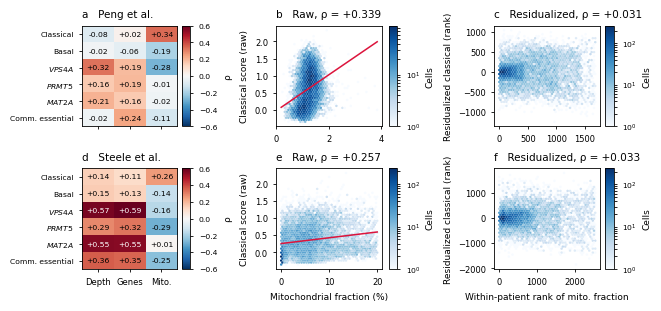

In [87]:
# ==========================================================================
# 50 · SUPPLEMENTARY FIG. S3 -- the technical covariates of the scores, and their removal
# (a, d) Spearman correlation, across all malignant cells, of each score with the three QC
#        covariates (section 13's table, both discovery cohorts, with the basal score and the
#        commonly-essential control added because both are tested in the manuscript)
# (b, e) the strongest subtype-score confound drawn: raw classical score vs mitochondrial
#        fraction, with the least-squares line
# (c, f) the same after the correction every reported coefficient uses: the classical rank
#        residualised on the three QC ranks within each patient, against the within-patient
#        rank of mitochondrial fraction. A flat panel means the confound is gone.
# Pure consumer of mal.obs / steele.obs; no random numbers.
# ==========================================================================

CONF_ROWS = [("classical_score", "Classical"), ("basal_score", "Basal"), ("VPS4A_sig", "VPS4A"),
             ("PRMT5_sig", "PRMT5"), ("MAT2A_sig", "MAT2A"), ("CE_sig", "Comm. essential")]
CONF_COLS = [("log_counts", "Depth"), ("n_genes_by_counts", "Genes"),     # sequencing depth, detected
             ("pct_counts_mt", "Mito.")]                                   # genes, mitochondrial fraction


def _within_patient_resid(obs, col, xcol="pct_counts_mt", covars=None, min_cells=MIN_CELLS):
    """Per patient, the rank of `col` OLS-residualised on the QC-covariate ranks -- exactly the
    quantity partial_spearman correlates -- and the within-patient rank of `xcol` for the x axis.
    Patients below MIN_CELLS are skipped, as in every test."""
    covars = covars or QC_COVARS
    rx, ry = [], []
    for _, g in obs.groupby("Patient", observed=True):
        if len(g) < min_cells:
            continue
        Q = np.column_stack([rankdata(g[q].values) for q in covars])
        ry.append(resid(rankdata(g[col].values), Q))
        rx.append(rankdata(g[xcol].values))
    return np.concatenate(rx), np.concatenate(ry)


CONF = {}
RESULTS["technical_confounds"] = {}
for _lab, _o in [("Peng", mal.obs), ("Steele", steele.obs)]:
    rows = [r for r in CONF_ROWS if r[0] in _o]
    M = pd.DataFrame([[spearmanr(_o[r], _o[c])[0] for c, _ in CONF_COLS] for r, _ in rows],
                     index=[n for _, n in rows], columns=[n for _, n in CONF_COLS])
    _x, _y = _within_patient_resid(_o, "classical_score")
    CONF[_lab] = dict(M=M, raw_x=_o["pct_counts_mt"].values.astype(float),
                      raw_y=_o["classical_score"].values.astype(float), res_x=_x, res_y=_y,
                      rho_raw=spearmanr(_o["pct_counts_mt"], _o["classical_score"])[0],
                      rho_res=spearmanr(_x, _y)[0])
    RESULTS["technical_confounds"][_lab] = dict(matrix=M.round(3).to_dict(), rho_raw=float(CONF[_lab]["rho_raw"]),
                                       rho_residualised=float(CONF[_lab]["rho_res"]))
    print("{} -- Spearman of each score with the QC covariates (all malignant cells)".format(_lab))
    print(M.round(3).to_string())
    print("  classical vs mito fraction: raw rho {:+.3f} -> after residualization {:+.3f}\n".format(
        CONF[_lab]["rho_raw"], CONF[_lab]["rho_res"]))

if FIGURES:
    with plt.rc_context(FIG_RC):
        fig = ms_figure(FIG_SIZE["S3"])
        axes = fig.subplots(2, 3, gridspec_kw={"width_ratios": [0.9, 1, 1]})
        for row, _lab in enumerate(["Peng", "Steele"]):
            d = CONF[_lab]
            # (a, d) heatmap with the coefficient printed in each cell (text inside its own panel)
            ax = axes[row, 0]
            im = ax.imshow(d["M"].values, cmap="RdBu_r", vmin=-0.6, vmax=0.6, aspect="auto")
            for i in range(d["M"].shape[0]):
                for j in range(d["M"].shape[1]):
                    v = d["M"].values[i, j]
                    ax.text(j, i, "{:+.2f}".format(v), ha="center", va="center", fontsize=5.5,
                            color="white" if abs(v) > 0.4 else "black")
            ax.set_xticks(range(d["M"].shape[1]))
            ax.set_xticklabels(d["M"].columns if row == 1 else [])            # bottom row only, unrotated
            ax.set_yticks(range(d["M"].shape[0])); ax.set_yticklabels([gi(n) for n in d["M"].index], fontsize=5.5)
            cb = fig.colorbar(im, ax=ax, aspect=12); cb.set_label("ρ")
            cb.ax.tick_params(labelsize=5.5)
            _panel(ax, "ad"[row], "{} et al.".format(_lab))
            # (b, e) raw: classical score vs mitochondrial fraction, hexbin + least-squares line;
            # the coefficient goes in the panel title, not over the cells
            ax = axes[row, 1]
            hb = ax.hexbin(d["raw_x"], d["raw_y"], gridsize=40, bins="log", mincnt=1, cmap="Blues", lw=0)
            b_ = np.polyfit(d["raw_x"], d["raw_y"], 1)
            xs = np.linspace(np.nanmin(d["raw_x"]), np.nanmax(d["raw_x"]), 50)
            ax.plot(xs, np.polyval(b_, xs), color="crimson", lw=1.1)
            ax.set_xlabel("mitochondrial fraction (%)" if row == 1 else ""); ax.set_ylabel("classical score (raw)")
            cb = fig.colorbar(hb, ax=ax, aspect=12); cb.set_label("cells")
            cb.ax.tick_params(labelsize=5.5)
            _panel(ax, "be"[row], "raw, ρ = {:+.3f}".format(d["rho_raw"]))
            # (c, f) after: residualised classical rank vs within-patient rank of mito fraction
            ax = axes[row, 2]
            hb = ax.hexbin(d["res_x"], d["res_y"], gridsize=40, bins="log", mincnt=1, cmap="Blues", lw=0)
            ax.set_xlabel("within-patient rank of mito. fraction" if row == 1 else "")
            ax.set_ylabel("residualized classical (rank)")
            cb = fig.colorbar(hb, ax=ax, aspect=12); cb.set_label("cells")
            cb.ax.tick_params(labelsize=5.5)
            _panel(ax, "cf"[row], "residualized, ρ = {:+.3f}".format(d["rho_res"]))
        fsentence(fig)                              # §42b: first letter of each label capitalised
        LAYOUT["Supplementary Fig. S3"] = fig_layout_check(fig, "Supplementary Fig. S3")
        plt.savefig(out_path("FigS3_technical_confounds.png"), dpi=FIG_DPI, bbox_inches="tight")   # Supplementary Fig. S3
        _show("FigS3_technical_confounds")

## 50b · Supplementary Figs. S4–S6 in the manuscript style

The diagnostic figures of §29b, §28b and §30b redrawn at printed size with the conventions of Figs. 1–7. Supplementary Fig. S6 now summarises each group at the patient level.

Supplementary Fig. S4 layout: 29 boxes, 0 intersecting pair(s); largest empty area 1.70 x 0.60 in (5.1% of the figure) -> CHECK
Supplementary Fig. S4 panel boxes: 3 boxes | overlapping pairs: none | groups not parallel / not equal: none -> OK


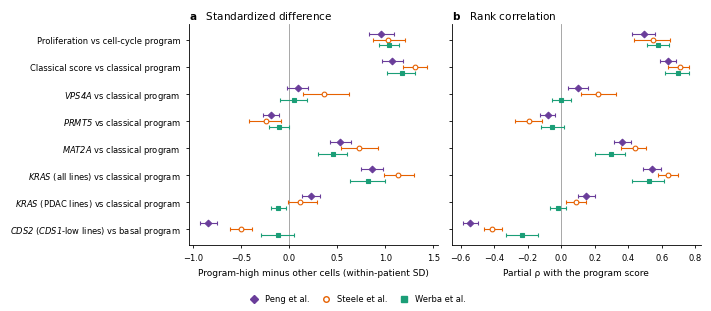

wrote FigS4_positive_controls_scales.png / .pdf to C:\Users\The_R/Downloads\pdac_results\manuscript_figures
Supplementary Fig. S5 layout: 12 boxes, 0 intersecting pair(s); largest empty area 0.50 x 1.41 in (7.2% of the figure) -> CHECK
Supplementary Fig. S5 panel boxes: 2 boxes | overlapping pairs: none | groups not parallel / not equal: none -> OK


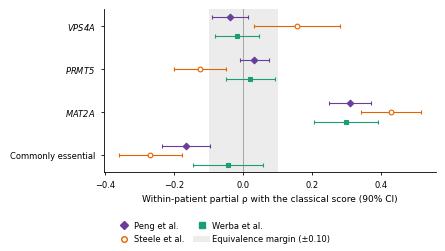

wrote FigS5_equivalence.png / .pdf to C:\Users\The_R/Downloads\pdac_results\manuscript_figures
Supplementary Fig. S6 layout: 27 boxes, 0 intersecting pair(s); largest empty area 0.20 x 2.12 in (2.6% of the figure) -> OK
Supplementary Fig. S6 panel boxes: 3 boxes | overlapping pairs: none | groups not parallel / not equal: none -> OK


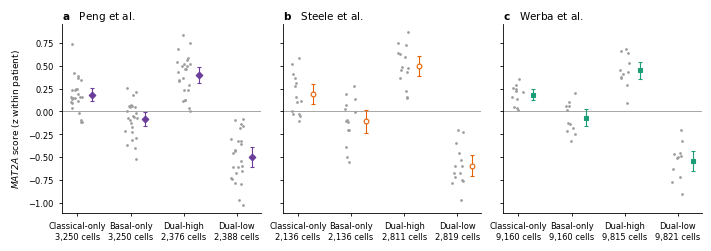

wrote FigS6_dual_score_groups.png / .pdf to C:\Users\The_R/Downloads\pdac_results\manuscript_figures


In [88]:
# ==========================================================================
# 50b · SUPPLEMENTARY FIGS. S4-S6 AT PRINTED SIZE, IN THE MANUSCRIPT STYLE
# Redraws the diagnostic figures of §29b (S4), §28b (S5) and §30b (S6) with the conventions of Figs. 1-7:
# cohort markers, italic gene symbols, panel letters, the lettering rule, 300 dpi PNG + vector PDF.
# Values are read from the tables those sections built (PC_SCALES, CLASSICAL_TAB) or, for S6,
# recomputed with §30b's arithmetic. S6 now shows PATIENT-level summaries (each patient's group mean;
# the mean across patients with a 95% patient-bootstrap CI), as every test in the paper does, where
# §30b's inline bars were cell-pooled means. No reported statistic changes.
# ==========================================================================


def _it(g):
    """A gene symbol in italics for figure text (the whole symbol, digits included: FIG_RC3)."""
    return r"$\mathit{" + g + "}$"


_S4_SCORE = {"proliferation": "Proliferation", "classical score": "Classical score",
             "VPS4A": _it("VPS4A"), "PRMT5": _it("PRMT5"), "MAT2A": _it("MAT2A"),
             "KRAS (all lines)": _it("KRAS") + " (all lines)", "KRAS (PDAC lines)": _it("KRAS") + " (PDAC lines)",
             "CDS2 (CDS1-low lines)": _it("CDS2") + " (" + _it("CDS1") + "-low lines)"}
_S4_PROG = {"cellcycle": "cell-cycle program", "classical": "classical program", "basal": "basal program"}

with plt.rc_context(FIG_RC3):
    # ---- Supplementary Fig. S4: positive controls and targets on two scales -----------------------
    _k4 = list(PC_SCALES[PC_SCALES["cohort"] == "Peng"][["score", "program"]].itertuples(index=False, name=None))
    _lab4 = ["{} vs {}".format(_S4_SCORE.get(s_, s_), _S4_PROG.get(p_.split("_", 1)[-1], p_)) for s_, p_ in _k4]
    _y4 = np.arange(len(_k4))[::-1]                                  # first row at the top
    fig = ms_figure((FIG_W, 3.0))
    axes = fig.subplots(1, 2, sharey=True)
    for ax, (val, lo, hi, xl, let, ttl) in zip(axes, [
            ("std_diff", "std_lo", "std_hi", "Program-high minus other cells (within-patient SD)", "a",
             "Standardized difference"),
            ("rank_rho", "rank_lo", "rank_hi", "Partial ρ with the program score", "b", "Rank correlation")]):
        for j, (lab, *_rest) in enumerate(COH3):
            g = PC_SCALES[PC_SCALES["cohort"] == lab].set_index(["score", "program"]).reindex(_k4)
            fmark(ax, g[val].values, _y4 + (1 - j) * 0.22, lab,
                  xerr=[g[val].values - g[lo].values, g[hi].values - g[val].values])
        ax.axvline(0, color="0.6", lw=0.6, zorder=0)
        ax.set_xlabel(xl)
        fdespine(ax)
        fpanel(ax, let, ttl)
    axes[0].set_yticks(_y4)
    axes[0].set_yticklabels(_lab4)
    fig.legend(*fcohort_handles(), loc="outside lower center", ncol=3, frameon=False)
    fsave(fig, "FigS4_positive_controls_scales", "Supplementary Fig. S4")
    plt.close(fig)

    # ---- Supplementary Fig. S5: equivalence on the classical axis -----------------------------------
    _sig5 = [("VPS4A", _it("VPS4A")), ("PRMT5", _it("PRMT5")), ("MAT2A", _it("MAT2A")),
             ("common_essential", "Commonly essential")]
    _y5 = np.arange(len(_sig5))[::-1]
    fig = ms_figure((FIG_W * 0.62, 2.4))
    ax = fig.subplots()
    ax.axvspan(-EQ_MARGIN, EQ_MARGIN, color="0.4", alpha=0.12, lw=0, zorder=0)
    ax.axvline(0, color="0.6", lw=0.6, zorder=0)
    for j, (lab, *_rest) in enumerate(COH3):
        g = CLASSICAL_TAB[CLASSICAL_TAB["cohort"] == lab].set_index("signature").reindex([s for s, _ in _sig5])
        fmark(ax, g["mean_rho"].values, _y5 + (1 - j) * 0.22, lab,
              xerr=[g["mean_rho"].values - g["ci90_lo"].values, g["ci90_hi"].values - g["mean_rho"].values])
    ax.set_yticks(_y5)
    ax.set_yticklabels([l for _, l in _sig5])
    ax.set_xlabel("Within-patient partial ρ with the classical score (90% CI)")
    fdespine(ax)
    _h5, _l5 = fcohort_handles(null_label="Equivalence margin (±{:.2f})".format(EQ_MARGIN), null_alpha=0.12)
    fig.legend(_h5, _l5, loc="outside lower center", ncol=2, frameon=False)
    fsave(fig, "FigS5_equivalence", "Supplementary Fig. S5")
    plt.close(fig)

    # ---- Supplementary Fig. S6: MAT2A score by dual-score group, patient level ----------------------
    _grp_lab = {"classical-only": "Classical-only", "basal-only": "Basal-only",
                "dual-high": "Dual-high", "dual-low": "Dual-low"}
    _rng6 = np.random.default_rng([SEED, 6])                         # jitter only; its own stream
    fig = ms_figure((FIG_W, 2.4))
    axes = fig.subplots(1, 3, sharey=True)
    for ax, (lab, _ad), let in zip(axes, FIG_COHORTS, "abc"):
        o = _ad.obs
        z = o.groupby("Patient", observed=True)["MAT2A_sig"].transform(lambda v: (v - v.mean()) / v.std())
        ok = (o.groupby("Patient", observed=True)["MAT2A_sig"].transform("size") >= MIN_CELLS).values
        pm = (pd.DataFrame({"z": z.values, "g": o["subtype_group"].astype(str).values,
                            "p": o["Patient"].astype(str).values})[ok]
              .groupby(["p", "g"])["z"].mean().unstack())
        ncell = o.loc[ok, "subtype_group"].astype(str).value_counts()
        for x, g_ in enumerate(GRP):
            v = pm[g_].dropna().values if g_ in pm.columns else np.array([])
            if len(v) < 3:
                continue
            ax.scatter(x + _rng6.uniform(-0.12, 0.12, len(v)), v, s=4, color=OTHER_GREY, lw=0, zorder=2)
            lo, hi = boot_ci(v)
            fmark(ax, x + 0.28, float(v.mean()), lab, yerr=[[v.mean() - lo], [hi - v.mean()]])
        ax.axhline(0, color="0.6", lw=0.6, zorder=0)
        ax.set_xticks(range(len(GRP)))
        ax.set_xticklabels(["{}\n{:,} cells".format(_grp_lab.get(g_, g_), int(ncell.get(g_, 0))) for g_ in GRP])
        fdespine(ax)
        fpanel(ax, let, COH3_N[lab])
    axes[0].set_ylabel(_it("MAT2A") + " score (z within patient)")
    fsave(fig, "FigS6_dual_score_groups", "Supplementary Fig. S6")
    plt.close(fig)


## 51 · Results register

Every number that sections 22–50 collected in `RESULTS` is written to `results.json` (per-patient coefficients summarised as n, mean and 95% CI), the key values of the run are printed in the order of the Results, and the files in the output folder that back the manuscript's tables and figures are listed. The register is the place to look up any value without re-running the notebook.

In [89]:
# ==========================================================================
# 51 · RESULTS REGISTER -- every number of this run in one file, and the key values printed
# ==========================================================================

def _jsonable(x):
    if isinstance(x, dict):
        return {str(k): _jsonable(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [_jsonable(v) for v in x]
    if isinstance(x, (np.floating, float)):
        return None if not np.isfinite(x) else float(x)
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (np.bool_,)):
        return bool(x)
    return x


# entries that hold per-patient coefficients are summarised (n, mean, 95% CI) before writing
PER_PATIENT = {"hc_rhos", "loss_strat", "program_adjusted", "epi_removed", "axis"}
_out = {}
for k, v in RESULTS.items():
    if k in PER_PATIENT:
        _out[k] = {kk: (vv if kk.startswith("depmap|") else
                        dict(zip(["n", "mean", "ci_lo", "ci_hi"], [len(vv), mean_rho(vv), *boot_ci(vv)])))
                   for kk, vv in v.items()}
    else:
        _out[k] = v
with open(out_path("results.json"), "w") as fh:
    json.dump(_jsonable(_out), fh, indent=1)
print("wrote", out_path("results.json"))


def _f(r):
    ok = r is not None and np.isfinite(r.get("mean", np.nan))
    return "{:+.3f} [{:+.3f}, {:+.3f}]  n={}".format(r["mean"], r["lo"], r["hi"], int(r["n"])) if ok else "n/a"


def _fr(cohort, test):
    g = FOREST[(FOREST["cohort"] == cohort) & (FOREST["test"] == test)]
    return None if g.empty else g.iloc[0].to_dict()


print("\nKEY VALUES OF THIS RUN, in the order of the Results (every value is also in results.json)\n")
if not RAW_SC_OK:
    print("!! §22–24 were SKIPPED (peng_processed.h5ad / steele_qc_lognorm.h5ad missing): the doublet,\n"
          "   copy-number, high-confidence-cell and 9p21/18q-loss values below stay empty.\n")
print("Doublets (Results, Identification of malignant cells):", RESULTS.get("count_source"))
for lab, ss in RESULTS.get("doublet_samples", {}).items():
    s_ = pd.DataFrame(ss)
    print("  {}: expected {:.1%}, observed {:.1%}, bimodal {}/{} samples".format(
        lab, np.average(s_["expected_rate"], weights=s_["cells"]),
        np.average(s_["observed_rate"], weights=s_["cells"]), int((s_["rule"] == "bimodal minimum").sum()), len(s_)))
print("High-confidence malignant cells:", RESULTS.get("hc_cells"))
print("Peng control pancreata among analysed patients:",
      (RESULTS["peng_controls_in_analysis"] or "none") if "peng_controls_in_analysis" in RESULTS else "n/a (§23 skipped)")
print("CNV-positive fraction (per-patient runs):", {k: round(v["overall"], 3) for k, v in RESULTS.get("cnv_pos_frac", {}).items()})
print("MAT2A, CNV+ minus CNV- malignant:", RESULTS.get("mat2a_cnv_pos_minus_neg"))
print("\nDepMap held-out validation (original derivation):")
for r in RESULTS.get("depmap_validation", []):
    if r["derivation"].startswith("original"):
        print("  {:<6} rho {:+.3f}  R2 {:+.3f}  AUC {:.2f}  dR2 {:+.3f}  D2 {}".format(
            r["target"], r["rho_score_chronos"], r["r2_oos"], r["auc_quartiles"], r["delta_r2"],
            "{:+.3f}".format(r["rho_oof_demeter2"]) if r.get("rho_oof_demeter2") is not None and np.isfinite(r.get("rho_oof_demeter2", np.nan)) else "n/a"))
print("\nTarget dependency by passenger deletion:", RESULTS.get("del_vs_intact_chronos"))
print("\nMAT2A robustness (Peng | Steele):")
for t_ in dict.fromkeys(FOREST["test"]):
    print("  {:<42} {:<30} {}".format(t_, _f(_fr("Peng", t_)), _f(_fr("Steele", t_))))
def _verdict(r):
    """Three outcomes, never conflated: an association, equivalence to zero, or neither."""
    q = r.get("wilcoxon_q")
    if q is not None and np.isfinite(q) and q < 0.05:
        return "ASSOCIATION detected (Wilcoxon q < 0.05)"
    if r["equivalent_within_margin"]:
        return "EQUIVALENT to zero within the margin"
    if r["ci95_lo"] > 0 or r["ci95_hi"] < 0:
        return "INCONCLUSIVE - 95% CI excludes zero but the Wilcoxon test is not significant"
    return "INCONCLUSIVE - neither an association nor equivalence shown"


print("\nEquivalence (TOST, +/-{}):".format(EQ_MARGIN))
for r in RESULTS["classical_axis"]:
    if r["signature"] in ("VPS4A", "PRMT5"):
        print("  {} {:<6} mean {:+.4f}, 90% CI [{:+.4f}, {:+.4f}], TOST p {:.4f} -> {}".format(
            r["cohort"], r["signature"], r["mean_rho"], r["ci90_lo"], r["ci90_hi"], r["tost_p"], _verdict(r)))
print("\nDependency positive controls (rho vs classical, detected, DepMap premise holds):")
for k, v in RESULTS.get("pos_ctrl", {}).items():
    print("  {:<32} {:+.3f}  detected: {:<5} premise: {}".format(
        k, v["vs_classical"], str(v["detected_in_expected_direction"]), v.get("premise_holds_in_depmap")))
print("Harder nulls (MAT2A):", {k: round(v["sd"], 2) for k, v in RESULTS.get("hard_nulls", {}).items()})
print("Per-gene split (epithelial vs other):", {k: (round(v["epi_mean"], 3), round(v["other_mean"], 3), round(v["p"], 4))
                                                 for k, v in RESULTS.get("per_gene", {}).items()})
if "cnmf_benchmark" in RESULTS:
    b_ = pd.DataFrame(RESULTS["cnmf_benchmark"])
    print("cNMF benchmark: median matched spectra rho {:.2f}, median usage rho {:.2f}".format(
        b_["spectra_rho"].median(), b_["usage_rho"].median()))
if "vps4a_basal" in RESULTS:                         # §31: the one new association, and its verdict
    vb_ = RESULTS["vps4a_basal"]
    print("\nVPS4A signature vs basal score (§31):")
    for r in vb_["battery"]:
        if r["test"] == "Full model":
            print("  {:<8} {:+.3f} [{:+.3f}, {:+.3f}]  n={}".format(r["cohort"], r["mean"], r["lo"], r["hi"], int(r["n"])))
    for r in vb_["nulls"]:
        if r["axis"] == "basal":
            print("  {:<8} {:<30} {:+.1f} SD, empirical p {:.4f}".format(r["cohort"], r["null"] + " null", r["sd"], r["emp_p"]))
    print("  verdict: " + vb_["verdict"])
    print("  DepMap premise (basal-like lines more VPS4A-dependent, lineage held): " +
          ("supports" if vb_["depmap_premise_supports"] else "does not support"))
print("\nEvery table, figure and cache of this run is in", OUT_DIR)
# the files behind the manuscript's tables and figures, with their sizes
_files = sorted(f for f in os.listdir(OUT_DIR) if os.path.isfile(os.path.join(OUT_DIR, f)))
_keep = [f for f in _files if f.startswith(("Table", "Fig")) or f in ("results.json", "package_versions.txt")]
print("{} files in the folder; the {} that back the manuscript's tables and figures:".format(len(_files), len(_keep)))
for f in _keep:
    print("  {:<52}{:>10.1f} kB".format(f, os.path.getsize(os.path.join(OUT_DIR, f)) / 1e3))
_md_dir = out_path("manuscript_figures")
if os.path.isdir(_md_dir):
    print("manuscript_figures/: " + ", ".join(sorted(os.listdir(_md_dir))))

wrote C:\Users\The_R/Downloads\pdac_results\results.json

KEY VALUES OF THIS RUN, in the order of the Results (every value is also in results.json)

Doublets (Results, Identification of malignant cells): {'Peng': 'NO exact count source -- Scrublet not re-run for this cohort', 'Steele': 'stored layers/counts', 'Werba': "exact inversion via 'total_counts' (verified integral)"}
  Steele: expected 2.9%, observed 0.4%, bimodal 17/17 samples
  Werba: expected 9.5%, observed 2.3%, bimodal 11/11 samples
High-confidence malignant cells: {'Peng': 7653, 'Steele': 6640, 'Werba': 11925}
Peng control pancreata among analysed patients: none
CNV-positive fraction (per-patient runs): {'Peng': 0.774, 'Steele': 0.673, 'Werba': 0.332}
MAT2A, CNV+ minus CNV- malignant: {'Peng': {'mean': 0.01633394691166482, 'n': 21, 'n_pos': 19, 'p': 0.0008516311645507812}, 'Steele': {'mean': 0.05581862238770107, 'n': 16, 'n_pos': 15, 'p': 0.000213623046875}, 'Werba': {'mean': 0.03968363364864126, 'n': 11, 'n_pos': 10, 'p'

# Appendix A · Druggability of the targets and of the malignant states (not reported in the manuscript)

A descriptive analysis that is not part of the manuscript, kept for reference. The **Target Development Level (TDL)** of Pharos/TCRD grades a protein by how much chemical matter exists against it:

| TDL | meaning |
|---|---|
| **Tclin** | approved drugs exist |
| **Tchem** | chemical probes or potent small molecules exist |
| **Tbio** | biology characterised, no chemical matter |
| **Tdark** | understudied |

Two descriptive questions, not hypothesis tests: how tractable are the three targets and their passenger and tumour-suppressor genes (A1), and does tractability differ across the malignant programs, measured as the fraction of each program's top 30 genes that are Tclin or Tchem (A2–A3)? The levels are queried **live** from the Pharos GraphQL API. A clean live pull refreshes a cache; if the API cannot be reached, the cache is read, and a recorded pull is the last resort. A failed pull is never written to the cache.

In [90]:
# ==========================================================================
# A1 · DRUGGABILITY -- THE THREE TARGETS AND THEIR LOCI (Pharos, live)
# Target Development Level for each target, its passenger gene, and the tumour suppressor
# deleted alongside it. A clean live pull refreshes the cache; if the API is down the cache
# is read and never overwritten with a failed pull.
# ==========================================================================

import requests, os, time

PHAROS  = "https://pharos-api.ncats.io/graphql"
QUERY   = "query($q: ITarget!){ target(q:$q){ sym tdl fam novelty } }"
TDL_CSV = out_path("target_tdl.csv")                     # cache of a clean live pull

PHAROS_ERRORS = {}                                       # first GraphQL error per gene

def get_tdl(gene, retries=3):
    """One Pharos lookup. Returns the record; a NOT_FOUND record only when Pharos answers cleanly
    that it has no such target; or None when the query failed (network or HTTP error, or a GraphQL
    error -- an error is never recorded as NOT_FOUND). None is never written to a cache."""
    for k in range(retries):
        try:
            r = requests.post(PHAROS, json={"query": QUERY, "variables": {"q": {"sym": gene}}},
                              timeout=20)
            r.raise_for_status()
            js = r.json()
            t = (js.get("data") or {}).get("target")
            if t:
                return {"gene": gene, "tdl": t.get("tdl"), "family": t.get("fam"),
                        "novelty": t.get("novelty")}
            if js.get("errors"):                         # server-side error, not an absent target
                PHAROS_ERRORS.setdefault(gene, str(js["errors"][0].get("message", js["errors"][0]))[:160])
                raise RuntimeError("Pharos GraphQL error")
            return {"gene": gene, "tdl": "NOT_FOUND", "family": None, "novelty": None}
        except Exception:
            time.sleep(0.5 * (k + 1))
    return None                                          # None = query failed (do NOT write)

TDL_OK = {"Tclin", "Tchem", "Tbio", "Tdark"}
# A recorded live pull (the values Pharos returned when the analysis was run), the last-resort fallback
RECORDED_PULL = {"VPS4A": ("Tbio", None, 0.015081), "PRMT5": ("Tchem", "Epigenetic", 0.003955),
                   "MAT2A": ("Tchem", "Enzyme", 0.006677), "VPS4B": ("Tchem", None, 0.007887),
                   "MTAP": ("Tchem", "Enzyme", 0.004855), "CDKN2A": ("Tbio", "Enzyme", 0.000141),
                   "SMAD4": ("Tbio", "TF", 0.000471)}

CONTEXT = TARGETS + ["VPS4B", "MTAP", "CDKN2A", "SMAD4"]
live    = {g: get_tdl(g) for g in CONTEXT}
cached  = {}
if os.path.exists(TDL_CSV):
    for _, r_ in pd.read_csv(TDL_CSV).iterrows():
        if r_.get("tdl") in TDL_OK:                      # a NOT_FOUND written by an earlier run is ignored
            cached[r_["gene"]] = {"gene": r_["gene"], "tdl": r_["tdl"], "family": r_.get("family"),
                                  "novelty": r_.get("novelty")}
rows = []
for g in CONTEXT:                                        # per gene: live -> cache -> recorded pull
    if live[g] is not None and live[g]["tdl"] in TDL_OK:
        rows.append(dict(live[g], source="live"))
    elif g in cached:
        rows.append(dict(cached[g], source="cache"))
    elif g in RECORDED_PULL:
        t_, f_, n_ = RECORDED_PULL[g]
        rows.append({"gene": g, "tdl": t_, "family": f_, "novelty": n_, "source": "recorded pull"})
    else:
        rows.append({"gene": g, "tdl": "NOT_FOUND", "family": None, "novelty": None, "source": "none"})
tdl_targets = pd.DataFrame(rows)
_n_live = int((tdl_targets["source"] == "live").sum())
if _n_live == len(CONTEXT):                              # clean live pull -> refresh cache
    tdl_targets.drop(columns="source").to_csv(TDL_CSV, index=False)
    print("TARGET DEVELOPMENT LEVELS  (queried live from Pharos; cache refreshed)\n")
else:                                                    # never overwrite the cache with a partial pull
    print("TARGET DEVELOPMENT LEVELS  ({}/{} live; the rest from the cache or the recorded pull --"
          " see 'source'; cache not overwritten)\n".format(_n_live, len(CONTEXT)))
    for g in CONTEXT:
        if live[g] is None or live[g]["tdl"] not in TDL_OK:
            why = PHAROS_ERRORS.get(g, "no response" if live[g] is None else "Pharos returned no target")
            print("  {} live lookup failed: {}".format(g, why))
    print()

print(tdl_targets.to_string(index=False))
print("\n-> descriptive only: PRMT5 and MAT2A (both Tchem) have inhibitors in clinical trials; VPS4A")
print("   (Tbio) has no potent small-molecule ligand on record. MAT2A is the target whose signature is")
print("   associated with the classical score; this does not show the association predicts response.")

TARGET DEVELOPMENT LEVELS  (queried live from Pharos; cache refreshed)

  gene   tdl     family  novelty source
 VPS4A  Tbio       None 0.015081   live
 PRMT5 Tchem Epigenetic 0.003955   live
 MAT2A Tchem     Enzyme 0.006677   live
 VPS4B Tchem       None 0.007887   live
  MTAP Tchem     Enzyme 0.004855   live
CDKN2A  Tbio     Enzyme 0.000141   live
 SMAD4  Tbio         TF 0.000471   live

-> descriptive only: PRMT5 and MAT2A (both Tchem) have inhibitors in clinical trials; VPS4A
   (Tbio) has no potent small-molecule ligand on record. MAT2A is the target whose signature is
   associated with the classical score; this does not show the association predicts response.


In [91]:
# ==========================================================================
# A2 · DRUGGABILITY BY MALIGNANT STATE (Pharos, live)   ·   not reported in the manuscript
# For each NMF program, the fraction of its top 30 genes that are Tclin or Tchem. Descriptive,
# not a hypothesis test. Same live-pull-with-cache-fallback contract as the cell above.
# ==========================================================================

TOP_N    = 30
PROG_CSV = out_path("tractability_by_program.csv")                   # cache of a clean live pull

prog_top = {}
for i, name in enumerate(PROG_NAMES):
    prog_top[name] = [prog_genes[j] for j in np.argsort(programs[i])[::-1][:TOP_N]
                      if prog_genes[j] in raw]

def query_tractability():
    """Query Pharos for each program's top genes. Returns the table, or None if any
    gene query fails -- so a blocked run falls back to the cache instead of writing zeros."""
    order = ["Tclin", "Tchem", "Tbio", "Tdark"]
    all_genes = sorted(set(g for v in prog_top.values() for g in v))
    print("querying Pharos for {} program genes (a few minutes)...\n".format(len(all_genes)))
    cache = {}
    for i, g in enumerate(all_genes):
        rec = get_tdl(g)
        if rec is None:
            return None                                  # bail -> use the cache
        cache[g] = rec["tdl"]
        time.sleep(0.12)
        if (i + 1) % 50 == 0:
            print("  {}/{}".format(i + 1, len(all_genes)))
    rows = []
    for name, genes in prog_top.items():
        tdls = [cache.get(g, "NOT_FOUND") for g in genes]
        n = max(len(genes), 1)
        d = {"program": name, "n_genes": len(genes)}
        for k in order:
            d[k] = sum(1 for t in tdls if t == k)
        d["pct_tractable"] = round(100 * sum(1 for t in tdls if t in ("Tclin", "Tchem")) / n, 1)
        rows.append(d)
    return pd.DataFrame(rows)[["program", "n_genes", *order, "pct_tractable"]]

tract = query_tractability()

if tract is not None:                                    # clean live pull -> refresh cache
    tract.to_csv(PROG_CSV, index=False)
    print("\nTRACTABILITY BY MALIGNANT STATE  (queried live; cache refreshed)\n")
elif os.path.exists(PROG_CSV):                           # API down -> read cache, never overwrite
    tract = pd.read_csv(PROG_CSV).fillna("")
    print("\nTRACTABILITY BY MALIGNANT STATE  (Pharos unreachable; using cached values)\n")
else:
    raise RuntimeError("Pharos unreachable and no cache at {} -- run once on open internet.".format(PROG_CSV))

print(tract.sort_values("pct_tractable", ascending=False).to_string(index=False))

querying Pharos for 217 program genes (a few minutes)...

  50/217
  100/217
  150/217
  200/217

TRACTABILITY BY MALIGNANT STATE  (queried live; cache refreshed)

     program  n_genes  Tclin  Tchem  Tbio  Tdark  pct_tractable
      3_tuft       30      5      6    16      3           36.7
 4_cellcycle       30      1      8    21      0           30.0
    5_acinar       30      4      5    18      1           30.0
6_intestinal       30      1      5    19      1           20.0
    9_stress       30      0      6    22      0           20.0
    1_ductal       30      0      5    19      2           16.7
 8_classical       30      1      4    22      1           16.7
       2_CAF       30      1      3    25      1           13.3
     7_basal       30      1      3    23      1           13.3
 10_MAGE_CTA       30      0      3    23      1           10.0


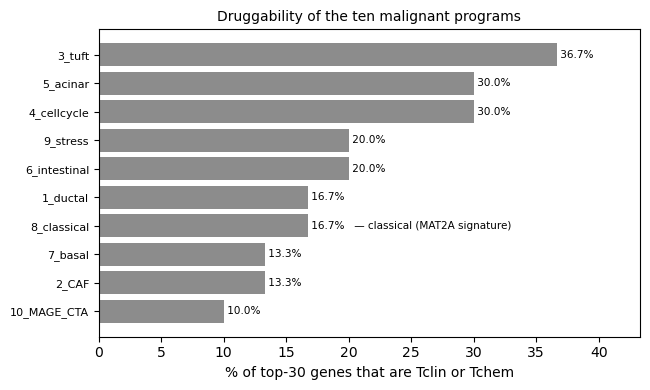

In [92]:
# ===========================================================================
# A3 · FIGURE - DRUGGABILITY BY MALIGNANT STATE   ·   not reported in the manuscript
# ===========================================================================
# Pure consumer of `tract` from the cell above: the fraction of each program's
# top 30 genes that are Tclin or Tchem, ordered most to least druggable. The
# classical program (where the MAT2A signature concentrates) is tagged inline
# on its own value label (not colour-highlighted) - it ranks mid-pack, and a
# highlight would imply an extremity the data do not show.
if FIGURES:
    _t = tract.sort_values("pct_tractable", ascending=True)
    _progs = list(_t["program"])
    _pct = list(_t["pct_tractable"].astype(float))
    _fig, _ax = plt.subplots(figsize=(6.6, 4.0))
    _ax.barh(range(len(_progs)), _pct, color="0.55")
    _ax.set_yticks(range(len(_progs)))
    _ax.set_yticklabels(_progs, fontsize=8)
    # The classical program's callout is INLINED onto its own value label.
    # Previously it was a separate arrow annotation whose text was parked to the
    # right of the bar tip, directly on top of the "16.7%" number; an inline tag
    # extends into the empty space past the bar and can never cover the value.
    _ci = _progs.index(CLASSICAL_PROG) if CLASSICAL_PROG in _progs else -1
    for _i, _v in enumerate(_pct):
        _lab = " {:.1f}%".format(_v)
        if _i == _ci:
            _lab += "   \u2014 classical (MAT2A signature)"
        _ax.text(_v, _i, _lab, va="center", fontsize=7.5)
    _ax.set_xlabel("% of top-30 genes that are Tclin or Tchem")
    _ax.set_title("Druggability of the ten malignant programs", fontsize=10)
    _ax.margins(x=0.18)
    plt.tight_layout()
    _show("druggability_by_program")